# From Distance to Trust: Analysis of User Opinions on Interactions with AI Chatbots

**Author:** Kinga Kopczyk

## Overview

Some people talk to chatbots every day — to save time on finding information, process difficult emotions, or organise their schedule. Yet how they feel about these conversations may vary enormously, depending on how someone — or something — responds on the other side.

This project explores the emotional landscape of opinions on human–chatbot interactions across four distinct contexts: general AI, therapeutic, educational, and virtual assistants. By analysing thousands of Reddit posts and app reviews using NLP sentiment analysis, topic modelling, and affect-topic patterns, it maps the emotional content of users' experience — from distance or distrust to relief and genuine connection. The results may serve as guidance for designing conversational AI that people would enjoy using.

## Main Research Questions

1. Does affect in user opinions vary depending on the chatbot category?
2. What topic-affect patterns are recurring in posted opinions?
3. Has sentiment toward chatbots changed over time?
4. Is it possible to predict a review's star rating based on the text of the comment?

## Steps

0. Install & Import
1. Data Collection
2. Data Cleaning and Preprocessing
3. Exploratory Data Analysis
4. Sentiment & Arousal Analysis
5. Inter-Model Agreement Analysis
6. Inter-Category Differences 
7. Timeline of Affect
8. Russell's Circumplex Model of Affect
9. Topic-Affect Relationship Patterns
10. Star Rating Prediction Based on Text Reviews

## Limitations

Several methodological constraints should be kept in mind when interpreting the results of this project. 

The dataset is limited to English-language content from three platforms — Reddit, Google Play, and the App Store — which introduces both linguistic and demographic bias: users who write public reviews or participate in AI-related subreddits are not representative of the general chatbot user population. 

Technical review filtering (Section 2.5) relies on keyword matching without contextual disambiguation, which risks removing genuinely negative chatbot experience reviews that happen to contain technical vocabulary. 

The assignment of GoEmotions categories to Russell's circumplex coordinates (Section 4.3) involves interpolation for emotions without established psycholinguistic norms, and should be treated as informed estimates rather than empirically validated values. 

Inter-model agreement between VADER, NRC VAD, and GoEmotions is moderate at best (Section 5), meaning that findings which depend on a single model should be interpreted with caution. Where all three models converge, conclusions are considerably more robust. 

Finally, temporal sentiment trends (Section 7) may reflect changes in dataset composition — such as the entry of new applications or shifts in platform activity — rather than genuine changes in user affect, and should not be interpreted as causal evidence of improving chatbot quality.

Chatbot category is partly confounded with data source. Educational chatbots are represented exclusively by app-store reviews (10,541 of 10,541 records), whereas about 84% of Therapeutic and 86% of General records, and about 53% of Virtual Assistant records, come from Reddit. Category differences in affect (Section 6) therefore partly reflect differences between genres (app review vs. forum discussion), not only between chatbot types. Section 6.4 repeats the tests within each source: category differences remain significant, but effect sizes shrink considerably and the ordering of category pairs is no longer consistent across models.

The trend tests in Section 7.1.4 are 12 separate Spearman tests (4 categories × 3 models) reported without correction for multiple comparisons, and monthly means are autocorrelated. After Holm correction only the two Educational declines remain significant (see the note after Section 7.1.4), and Section 7.1.5 shows that even these depend on the model and on the app; the upward trends in the other categories should be read as exploratory.

The rating-prediction models in Section 10.1 use only the five sentiment and arousal scores as features, a single stratified 80/20 split and default hyperparameters. Section 10.5 adds cross-validation and a TF-IDF text baseline, which outperforms every sentiment-score model (macro-F1 ≈ .47 vs. ≤ .38), so the modest scores in Section 10.2 partly reflect the limited feature set, not only noisy ratings.

## 0. Install & Import

All imports and installs are gathered here for clarity in the notebook.

### 0.1. Install Dependencies
Installing all external libraries required for the project:
- `pandas`, `numpy` — data manipulation, processing and DataFrame operations
- `google_play_scraper` — scraping reviews from the Google Play Store
- `requests` — making HTTP requests to the Apple and PullPush APIs
- `langdetect` — detecting the language of each review (used to filter non-English content)
- `clean-text` and `unidecode` — text preprocessing and Unicode normalisation
- `matplotlib`, `seaborn`, `wordcloud` — data visualisation
- `vaderSentiment`, `transformers`, `torch` — sentiment analysis
- `scipy`, `scikit-learn`, `contractions`, `scikit_posthocs` — statistical tests 
- `bertopic` — topic modelling

In [ ]:
# Scraping
!pip install google_play_scraper pandas requests langdetect 
# Cleaning
!pip install clean-text unidecode nltk 
# EDA
!pip install matplotlib numpy wordcloud seaborn 
# Sentiment & Emotion Analysis
!pip install vaderSentiment transformers torch 
# Stats
!pip install scipy scikit-learn contractions scikit_posthocs
# Topic Modelling
!pip install bertopic --break-system-packages

### 0.2. Import Libraries and Files
Importing all libraries and files needed throughout the project.

In [ ]:
# Scraping
import pandas as pd
import numpy as np
import os
import requests
from langdetect import detect, LangDetectException
from google_play_scraper import reviews, Sort
from datetime import datetime, timezone
import time
import random
import re

# Cleaning
from cleantext import clean
import contractions
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.image as mpimg
import matplotlib as mpl
import matplotlib.colors as mcolors
from matplotlib import gridspec
from matplotlib.patches import Circle
from matplotlib.font_manager import fontManager
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display
import seaborn as sns
from wordcloud import WordCloud
import colorsys
import io
from pathlib import Path

# Emotion Analysis
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import pipeline
import torch
from huggingface_hub import login
import huggingface_hub
import transformers
from tqdm import tqdm

# Statistics
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import cohen_kappa_score, classification_report
from scipy.stats import kruskal
import scikit_posthocs as sp
from statsmodels.multivariate.manova import MANOVA

# Topic-Affect Relationship Patterns
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.representation import TextGeneration
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

# Star Rating Prediction Based on Text Reviews
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, matthews_corrcoef, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier

In [2]:
# Load datasets that had been previously scraped and saved as CSV files.
# On a fresh clone the checkpoints do not exist yet: each one is created by the
# section that produces it (see "Getting Started" in the README), so missing files
# are skipped here (value None) instead of raising an error.

def find_project_root(marker="data", max_up=5):
    """Walk upward from the current working directory until a folder
    containing `marker` is found. Makes data loading independent of
    where Jupyter happens to start (notebook/ subfolder, repo root, etc.).
    On a fresh clone (no data/ folder yet) fall back to the repository root."""
    current = Path.cwd()
    for _ in range(max_up):
        if (current / marker).exists():
            return current
        current = current.parent
    cwd = Path.cwd()
    return cwd.parent if cwd.name == "notebook" else cwd

PROJECT_ROOT  = find_project_root()
RAW_DIR       = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

def load_checkpoint(path, **kwargs):
    """Read a CSV/TSV checkpoint if it exists, otherwise return None."""
    if path.exists():
        return pd.read_csv(path, **kwargs)
    print(f"[not found yet] {path.relative_to(PROJECT_ROOT)}")
    return None

df_google          = load_checkpoint(RAW_DIR / "google_reviews.csv")
df_apple           = load_checkpoint(RAW_DIR / "apple_reviews.csv")
df_reddit_posts    = load_checkpoint(RAW_DIR / "reddit_posts.csv")
df_reddit_comments = load_checkpoint(RAW_DIR / "reddit_comments.csv", low_memory=False)
df                 = load_checkpoint(RAW_DIR / "opinions_raw.csv", low_memory=False)
df_clean           = load_checkpoint(PROCESSED_DIR / "opinions_clean.csv", low_memory=False)
df_emotion         = load_checkpoint(PROCESSED_DIR / "opinions_emotion.csv", low_memory=False)
nrc_vad            = load_checkpoint(RAW_DIR / "NRC-VAD-Lexicon-v2.1.txt", sep="\t")
df_quadrant        = load_checkpoint(PROCESSED_DIR / "opinions_bertopic.csv", low_memory=False)
df_quadrant1       = load_checkpoint(PROCESSED_DIR / "opinions_keywords.csv", low_memory=False)
df_quadrant2       = load_checkpoint(PROCESSED_DIR / "opinions_ngrams.csv", low_memory=False)

if nrc_vad is None:
    print("\nThe NRC-VAD lexicon is not redistributed with this repository. Download "
          "NRC-VAD-Lexicon-v2.1.txt (non-commercial research/educational use) from "
          "http://saifmohammad.com/WebPages/nrc-vad.html and place it in data/raw/ before Section 4.2.")

## 1. Data Collection
The project dataset consists of publicly available reviews, posts, and comments about users' interactions with chatbots.

Opinions are collected from three platforms:
- **Reddit** — posts and comments from thematic subreddits
- **Google Play** — app reviews
- **App Store** — app reviews

Together, these sources allow user experience to be analysed based on users' own online expressions.


### 1.1. Scrape Google Play Reviews

Reviews are collected from the Google Play Store using the `google_play_scraper` library, which queries the public Google Play API — no authentication required.

#### Application dictionary
Each entry maps a unique `app_id` (taken from the Google Play Store URL) to one of four chatbot categories:
- `general` — multipurpose AI assistants (ChatGPT, Claude, Grok, etc.)
- `therapeutic` — mental health and emotional support chatbots (Replika, Wysa, etc.)
- `virtual_assistant` — task-oriented assistants embedded in platform ecosystems (Copilot, Google Assistant, etc.)
- `educational` — AI tutors and homework helpers (Nerd AI, StudyX, etc.)

#### Dual sorting strategy
To maximise temporal diversity in the dataset, each application is scraped twice using two different sorting methods:
- `Sort.NEWEST` — retrieves the most recent reviews, capturing current user sentiment
- `Sort.MOST_RELEVANT` — retrieves reviews ranked by Google's relevance algorithm, which tends to surface older, higher-quality reviews

This approach yields a broader time span than using a single sorting method — which is essential for the temporal sentiment analysis planned in later stages of the project.


In [ ]:
# Dictionary mapping app_id (from Google Play Store URL) to chatbot category
apps_google = {
    # General-purpose AI chatbots
    "com.openai.chatgpt": "general",           # ChatGPT
    "ai.character.app": "general",             # Character.AI
    "com.anthropic.claude": "general",         # Claude
    "ai.x.grok": "general",                    # Grok
    "com.google.android.apps.bard": "general", # Gemini

    # Therapeutic and mental health chatbots
    "com.ohsofia.ohsofia": "therapeutic",      # Ohsofia
    "com.getmental.mental": "therapeutic",     # Mental
    "ai.replika.app": "therapeutic",           # Replika
    "bot.touchkin": "therapeutic",             # Wysa

    # Virtual assistants embedded in platform ecosystems
    "com.microsoft.copilot": "virtual_assistant",                   # Microsoft Copilot
    "com.google.android.apps.googleassistant": "virtual_assistant", # Google Assistant
    "com.amazon.dee.app":  "virtual_assistant",                     # Amazon Alexa

    # Educational AI tutors and homework helpers
    "com.codeway.homework": "educational",       # Nerd AI
    "com.qianfan.aihomework": "educational",     # Question.AI
    "com.brilian.studyx.student": "educational", # StudyX
    "com.hilokal": "educational"                 # Hilokal
}

all_reviews = []

for app_id, category in apps_google.items():

    try:
        # Scrape the most recent reviews — captures current user sentiment
        results_newest, reviews_characteristics = reviews(
            app_id,
            lang="en",       # English language only
            country="us",    # US store — largest volume of English reviews
            sort=Sort.NEWEST,
            count=1000        # number of newest reviews per application
        )

        # Scrape the most relevant reviews — Google's algorithm surfaces older,
        # high-quality reviews, improving temporal diversity of the dataset
        results_relevant, reviews_characteristics = reviews(
            app_id,
            lang="en",
            country="us",
            sort=Sort.MOST_RELEVANT,
            count=3000        # number of most relevant reviews per application
        )

        # Combine both result sets and store selected fields
        for r in results_newest + results_relevant:
            all_reviews.append({
                "app_id": app_id,
                "category": category,
                "source": "google_play",
                "text": r["content"],            # review text
                "rating": r["score"],            # star rating (1–5)
                "date": r["at"],                 # date of the review
                "thumbs_up": r["thumbsUpCount"]  # helpfulness votes from other users
            })

    except Exception as e:
        print(f"Error: {app_id}: {e}")

# Convert to DataFrame
df_google = pd.DataFrame(all_reviews)

# Save the created dataset 
df_google.to_csv(RAW_DIR / "google_reviews.csv", index=False)

df_google.head()

### 1.2. Scrape App Store Reviews

Reviews are collected from the Apple App Store using Apple's public iTunes RSS API — no authentication or API key required.

#### API structure with dual sorting
Due to API limitations, the iTunes RSS feed returns up to 10 pages of approximately 50 reviews each (~500 reviews per app). Each application is scraped using both available sorting options:
- `mostrecent` — most recent reviews
- `mosthelpful` — reviews ranked by helpfulness

#### Language filtering
Unlike Google Play (which accepts a `lang` parameter directly), the Apple RSS API does not filter reviews by language. The `langdetect` library is therefore applied to each review to retain only English-language content, ensuring compatibility with the English-trained NLP models used in later stages.


In [3]:
# Dictionary mapping App Store app_id to (app name, chatbot category)
# App IDs are taken from the App Store URL: apps.apple.com/us/app/[name]/id[ID]
apps_apple = {
    "6448311069": ("ChatGPT", "general"),
    "6477489729": ("Google Gemini", "general"),
    "6670324846": ("Grok", "general"),
    "1671705818": ("Character AI", "general"),
    "6473753684": ("Claude", "general"),
    "1571844479": ("StudyX", "educational"),
    "6449704549": ("Nerd AI", "educational"),
    "6449486871": ("Question.AI", "educational"),
    "1537500613": ("Hilokal", "educational"),
    "1166585565": ("Wysa", "therapeutic"),
    "1158555867": ("Replika", "therapeutic"),
    "6472538445": ("Microsoft Copilot", "virtual_assistant"),
    "1220976145": ("Google Assistant", "virtual_assistant"),
    "944011620": ("Amazon Alexa", "virtual_assistant")
}

apple_reviews = []

for app_id, (app_name, category) in apps_apple.items():

  # Apple RSS API provides up to 10 pages of ~50 reviews each = ~500 reviews per app
  # Both sorting options are used to maximise temporal diversity
  for sort_by in ["mostrecent", "mosthelpful"]:

    for page in range(1, 11):
        url = f"https://itunes.apple.com/us/rss/customerreviews/page={page}/id={app_id}/sortby=mostrecent/json"

        try:
            response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"})
            data = response.json()

            entries = data.get("feed", {}).get("entry", [])

            # The first entry on page 1 contains app metadata, not a review — skip it
            if page == 1:
                entries = entries[1:]

            # No more entries means we've reached the last available page
            if not entries:
                break
                    
                
            for entry in entries:
                title = entry.get("title", {}).get("label", "") or ""
                content = entry.get("content", {}).get("label", "") or ""
                # Detect language on content only — title is usually too short
                try:
                    language = detect(content)
                except:
                    language = "unknown"
                if language != "en":
                    continue
                     
                # Combine title and content — skip separator if title is empty
                if title and content:
                    combined_text = f"{title}: {content}"
                elif title:
                    combined_text = title
                else:
                    combined_text = content
                        
                apple_reviews.append({
                    "app_id":    app_id,
                    "category":  category,
                    "source":    "app_store",
                    "text":      combined_text,  # title + ": " + content
                    "rating":    entry.get("im:rating", {}).get("label", None),
                    "date":      entry.get("updated", {}).get("label", None),
                })
        
        except Exception as e:
            print(f"Error: {app_name}, page {page}: {e}")
            break

# Convert to DataFrame 
df_apple = pd.DataFrame(apple_reviews)

# Save the created dataset 
df_apple.to_csv(RAW_DIR / "apple_reviews.csv", index=False)

df_apple.head()

,app_id,category,source,text,rating,date
0,6448311069,general,app_store,The Best: Best app of all time . Let me no all...,5,2026-05-24T23:55:39-07:00
1,6448311069,general,app_store,ChatGPT got me fit: I first was hella skeptica...,5,2026-05-24T23:34:09-07:00
2,6448311069,general,app_store,Amazing: The best hands down,5,2026-05-24T23:17:35-07:00
3,6448311069,general,app_store,"Seriously, life-enhancing: I have never been i...",5,2026-05-24T23:15:51-07:00
4,6448311069,general,app_store,Love it: Family love,5,2026-05-24T23:12:12-07:00


### 1.3. Reddit Posts Download
Reddit posts are collected using the PullPush API, an archive of Reddit data. **1430 posts** per subreddit are retrieved from 14 subreddits selected to represent the four chatbot categories under study.

The collection covers the period from late 2022 to the most recently archived posts. This timeframe captures the mainstream adoption of conversational AI following the release of ChatGPT on 30 November 2022, as well as subsequent developments — including the launch of competing models and notable policy changes affecting individual platforms.

Post titles and body text are combined into a single text field, as Reddit posts sometimes consist of a title only, with the body left empty or subsequently removed by moderators. Posts containing no usable text after this combination are excluded at the collection stage.


In [11]:
# Helper function:
# Converts date string to Unix timestamp, as required by the PullPush API

def datetime_to_unix(date_str):
    """Convert YYYY-MM-DD to unix timestamp."""
    return int(
        datetime.strptime(date_str, "%Y-%m-%d")
        .replace(tzinfo=timezone.utc)
        .timestamp()
    )

# Configuration: data sources, subreddit topics, and date range

subreddits_map = {
    "ChatGPT": "general",
    "Chatbots": "general",
    "ClaudeAI": "general",
    "antiai": "general",
    "OpenAI": "general",
    "ChatbotAddiction": "general",
    "therapyGPT": "therapeutic",
    "replika": "therapeutic",
    "AI_CustomerService": "customer_service",
    "AIEducation": "educational",
    "GoogleAssistant": "virtual_assistant",
    "AIAssisted": "virtual_assistant",
    "AI_Agents": "virtual_assistant",
    "alexa": "virtual_assistant"
}

BASE_URL = "https://api.pullpush.io/reddit/search/submission/"

START_DATE = datetime_to_unix("2022-11-30")
END_DATE = int(datetime.now(timezone.utc).timestamp())

# Number of top posts per subreddit
MAX_POSTS_PER_SUBREDDIT = 1000

# PullPush max size per request is 100
BATCH_SIZE = 100

REQUEST_DELAY = 1


# Scraping

all_posts = []

for subreddit, category in subreddits_map.items():

    print(f"\n{'=' * 60}")
    print(f"Fetching r/{subreddit}")
    print(f"{'=' * 60}")

    subreddit_posts = []

    before = END_DATE

    while True:

        remaining = MAX_POSTS_PER_SUBREDDIT - len(subreddit_posts)

        if remaining <= 0:
            break

        current_batch_size = min(BATCH_SIZE, remaining)

        try:

            response = requests.get(
                BASE_URL,
                params={
                    "subreddit": subreddit,
                    "size": current_batch_size,
                    "sort": "desc",
                    "sort_type": "score",
                    "after": START_DATE,
                    "before": before
                },
                timeout=60
            )

            response.raise_for_status()

            data = response.json()
            batch = data.get("data", [])

            print(
                f"r/{subreddit} | "
                f"fetched={len(batch)} | "
                f"total={len(subreddit_posts)}"
            )

            if not batch:
                print("No more posts available.")
                break

            subreddit_posts.extend(batch)

            # Pagination cursor:
            # move toward older posts
            oldest_timestamp = min(
                post.get("created_utc", END_DATE)
                for post in batch
            )

            before = oldest_timestamp - 1

            if before <= START_DATE:
                print("Reached start date.")
                break

            time.sleep(REQUEST_DELAY)

        except Exception as e:
            print(f"ERROR while fetching r/{subreddit}: {e}")
            break

    print(f"\nCollected {len(subreddit_posts)} raw posts")

# Preliminary cleaning

    cleaned_count = 0

    for post in subreddit_posts:

        title = post.get("title", "") or ""
        body = post.get("selftext", "") or ""

        if body in ["[deleted]", "[removed]"]:
            body = ""

        combined_text = f"{title}: {body}".strip() if title and body else f"{title}{body}".strip()

        # Skip empty posts
        if not combined_text:
            continue

        if len(combined_text.split()) < 1:
            continue

        all_posts.append({
            "subreddit": subreddit,
            "category": category,
            "source": "reddit",

            # Text
            "text": combined_text,

            # Metadata
            "thumbs_up": post.get("score", 0),
            "created_utc": post.get("created_utc"),
            "author": post.get("author"),

            # Datestamps 
            "date": datetime.utcfromtimestamp(
                post.get("created_utc", 0)
            ).strftime("%Y-%m-%d"),

            "year": datetime.utcfromtimestamp(
                post.get("created_utc", 0)
            ).year,

            "month": datetime.utcfromtimestamp(
                post.get("created_utc", 0)
            ).strftime("%Y-%m"),

            # IDs
            "post_id": post.get("id"),
        })

        cleaned_count += 1

    print(f"Usable posts: {cleaned_count}")
    
    # Dataframe
    
    df_reddit_posts = pd.DataFrame(all_posts)

    # Sort chronologically
    df_reddit_posts = df_reddit_posts.sort_values(
        by="created_utc"
    )

    # Save
    output_file = RAW_DIR / "reddit_posts.csv"

    df_reddit_posts.to_csv(
        output_file,
        index=False
    )

    print(f"\nSaved dataset of {len(df_reddit_posts)} posts to: {output_file}")

else:
    print("No posts collected.")


Fetching r/ChatGPT
r/ChatGPT | fetched=100 | total=0
r/ChatGPT | fetched=100 | total=100
r/ChatGPT | fetched=100 | total=200
r/ChatGPT | fetched=0 | total=300
No more posts available.

Collected 300 raw posts
Usable posts: 300

Saved dataset of 300 posts to: reddit_posts.csv

Fetching r/Chatbots


r/Chatbots | fetched=100 | total=0
r/Chatbots | fetched=0 | total=100
No more posts available.

Collected 100 raw posts
Usable posts: 100

Saved dataset of 400 posts to: reddit_posts.csv

Fetching r/ClaudeAI


r/ClaudeAI | fetched=100 | total=0
r/ClaudeAI | fetched=62 | total=100
r/ClaudeAI | fetched=0 | total=162
No more posts available.

Collected 162 raw posts
Usable posts: 162

Saved dataset of 562 posts to: reddit_posts.csv

Fetching r/antiai


r/antiai | fetched=33 | total=0
r/antiai | fetched=0 | total=33
No more posts available.

Collected 33 raw posts
Usable posts: 33

Saved dataset of 595 posts to: reddit_posts.csv

Fetching r/OpenAI


r/OpenAI | fetched=100 | total=0
r/OpenAI | fetched=61 | total=100
r/OpenAI | fetched=0 | total=161
No more posts available.

Collected 161 raw posts
Usable posts: 161

Saved dataset of 756 posts to: reddit_posts.csv

Fetching r/ChatbotAddiction


r/ChatbotAddiction | fetched=17 | total=0
r/ChatbotAddiction | fetched=0 | total=17
No more posts available.

Collected 17 raw posts
Usable posts: 17

Saved dataset of 773 posts to: reddit_posts.csv

Fetching r/therapyGPT


... (2 outputs left out)

r/AI_CustomerService | fetched=0 | total=0
No more posts available.

Collected 0 raw posts
Usable posts: 0

Saved dataset of 1014 posts to: reddit_posts.csv

Fetching r/AIEducation
r/AIEducation | fetched=0 | total=0
No more posts available.

Collected 0 raw posts
Usable posts: 0

Saved dataset of 1014 posts to: reddit_posts.csv

Fetching r/GoogleAssistant
r/GoogleAssistant | fetched=82 | total=0
r/GoogleAssistant | fetched=0 | total=82
No more posts available.

Collected 82 raw posts
Usable posts: 82

Saved dataset of 1096 posts to: reddit_posts.csv

Fetching r/AIAssisted


r/AIAssisted | fetched=100 | total=0
r/AIAssisted | fetched=31 | total=100
r/AIAssisted | fetched=0 | total=131
No more posts available.

Collected 131 raw posts
Usable posts: 131

Saved dataset of 1227 posts to: reddit_posts.csv

Fetching r/AI_Agents


r/AI_Agents | fetched=100 | total=0
r/AI_Agents | fetched=1 | total=100
r/AI_Agents | fetched=0 | total=101
No more posts available.

Collected 101 raw posts
Usable posts: 101

Saved dataset of 1328 posts to: reddit_posts.csv

Fetching r/alexa


r/alexa | fetched=100 | total=0
r/alexa | fetched=2 | total=100
r/alexa | fetched=0 | total=102
No more posts available.

Collected 102 raw posts
Usable posts: 102

Saved dataset of 1430 posts to: reddit_posts.csv
No posts collected.


### 1.4. Reddit Comments Download
Comments are collected from the same 14 subreddits as the posts, using the PullPush API with an identical date range (starting from late 2022 up to the most recently archived dates). While posts represent deliberate, structured user contributions, comments capture more spontaneous and emotionally immediate reactions — making them particularly valuable for sentiment analysis and user clustering.

A total of **126,873 comments** were collected across all subreddits. Each comment corresponds to a post that had already been scraped. Comments marked as deleted or removed are excluded during collection. The relationship between individual comments and their parent posts is not preserved in the final dataset, as each comment is treated as an independent unit of analysis rather than part of a conversational thread.


In [40]:
# Parameters configuration
# Specification of file locations and limits

COMMENTS_URL = "https://api.pullpush.io/reddit/search/comment/"

# Input file from posts scraper
POSTS_FILE = RAW_DIR / "reddit_posts.csv"

# Output file
COMMENTS_OUTPUT_FILE = RAW_DIR / "reddit_comments.csv"

# Checkpoint backup file in case of download complication
CHECKPOINT_FILE = RAW_DIR / "reddit_comments_checkpoint.csv"

# Limits
MAX_COMMENTS_PER_POST = 500
BATCH_SIZE = 100

# Scraping behavior
REQUEST_DELAY = 3
MAX_RETRIES = 5


# Load post from the previous scraping
df_posts = pd.read_csv(POSTS_FILE)
print(f"Loaded {len(df_posts)} posts")

# Create post_id → category lookup dictionary
# Category is derived from subreddit via subreddits_map
subreddits_map = {
    "ChatGPT": "general",
    "Chatbots": "general",
    "ClaudeAI": "general",
    "antiai": "general",
    "OpenAI": "general",
    "ChatbotAddiction": "general",
    "therapyGPT": "therapeutic",
    "replika": "therapeutic",
    "AI_CustomerService": "customer_service",
    "AIEducation": "educational",
    "GoogleAssistant": "virtual_assistant",
    "AIAssisted": "virtual_assistant",
    "AI_Agents": "virtual_assistant",
    "alexa": "virtual_assistant"
}

# Map each post_id to its category via subreddit
post_category_map = dict(
    zip(
        df_posts["post_id"],
        df_posts["subreddit"].map(subreddits_map)
    )
)

print(f"Category mapping created for {len(post_category_map)} posts")
print(pd.Series(post_category_map).value_counts())


# Scraping comments for input posts

all_comments = []

for idx, row in df_posts.iterrows():

    post_id = row["post_id"]
    subreddit = row["subreddit"]

    print(
        f"\n[{idx + 1}/{len(df_posts)}] "
        f"Fetching comments for post: {post_id}"
    )

    before = None
    post_comments = []

    try:

        while True:

            params = {
                # Link comments to posts based on the post_id
                "link_id": post_id,
                "sort": "desc",
                "size": BATCH_SIZE
            }

            # Pagination
            if before is not None:
                params["before"] = before

            success = False

            for attempt in range(MAX_RETRIES):

                try:

                    response = requests.get(
                        COMMENTS_URL,
                        params=params,
                        timeout=60
                    )

                    # Set wait time parameters to handle API rate limits
                    if response.status_code == 429:

                        wait_time = 2 ** attempt

                        print(
                            f"Rate limited (429). "
                            f"Sleeping {wait_time}s..."
                        )

                        time.sleep(wait_time)

                        continue

                    response.raise_for_status()

                    data = response.json()

                    success = True

                    break

                except Exception as e:

                    print(
                        f"Attempt {attempt + 1} failed: {e}"
                    )

                    time.sleep(2 ** attempt)

            # Skip a post if all retries failed to continue with different ones
            if not success:

                print(
                    f"Skipping post {post_id} "
                    f"after retries."
                )

                break

            comments = data.get("data", [])

            print(
                f"  batch fetched = {len(comments)} | "
                f"total = {len(post_comments)}"
            )

            # Stop if no more comments
            if not comments:
                break

            post_comments.extend(comments)

            # Limit comments per post 
            if len(post_comments) >= MAX_COMMENTS_PER_POST:

                post_comments = post_comments[
                    :MAX_COMMENTS_PER_POST
                ]

                break

            # Pagination cursor
            oldest_timestamp = min(
                c.get("created_utc", 0)
                for c in comments
            )

            before = oldest_timestamp - 1

            # Randomised delay to handle rate limits
            time.sleep(
                REQUEST_DELAY + random.uniform(0.5, 2)
            )

        print(
            f"Collected {len(post_comments)} comments"
        )

        # Preliminary dataset cleaning 

        usable_comments = 0

        for comment in post_comments:

            body = comment.get("body", "") or ""

            # Skip deleted/removed comments
            if body in ["[deleted]", "[removed]"]:
                continue

            # Skip empty comments
            if not body.strip():
                continue

            # Skip very short comments
            if len(body.split()) < 2:
                continue

            created_utc = comment.get("created_utc", 0)

            all_comments.append({

                # Relational key
                "post_id": post_id,

                # IDs
                "comment_id": comment.get("id"),

                # Subreddit info
                "subreddit": subreddit,
                
                # Category
                "category": post_category_map.get(post_id, "unknown"),

                # Source
                "source": "reddit",

                # Author
                "author": comment.get("author"),

                # Content
                "text": body,

                # Engagement
                "thumbs_up": comment.get("score", 0),

                # Timestamps
                "created_utc": created_utc,

                "date": datetime.utcfromtimestamp(
                    created_utc
                ).strftime("%Y-%m-%d"),

            })

            usable_comments += 1

        print(f"Usable comments: {usable_comments}")

        # Set a checkpoint save every 50 posts for a backup

        if idx % 50 == 0 and len(all_comments) > 0:

            checkpoint_df = pd.DataFrame(all_comments)

            checkpoint_df.to_csv(
                CHECKPOINT_FILE,
                index=False
            )

            print(
                f"Checkpoint saved "
                f"({len(checkpoint_df)} comments)"
            )

    except Exception as e:

        print(
            f"ERROR for post {post_id}: {e}"
        )

        continue


# Dataframe

df_comments = pd.DataFrame(all_comments)

if len(df_comments) > 0:

    print(
        f"Total comments: "
        f"{len(df_comments)}"
    )

    # Chronological order
    df_comments = df_comments.sort_values(
        by="created_utc"
    )

    print("\nComments per subreddit:")
    print(
        df_comments["subreddit"]
        .value_counts()
        .head(20)
    )

    # Save final dataset
    df_comments.to_csv(
        COMMENTS_OUTPUT_FILE,
        index=False
    )

    print(
        f"\nSaved comments dataset to: "
        f"{COMMENTS_OUTPUT_FILE}"
    )

else:
    print("No comments collected.")

Loaded 1430 posts
Category mapping created for 1409 posts
general              756
virtual_assistant    412
therapeutic          241
Name: count, dtype: int64

[1/1430] Fetching comments for post: z8atsb
  batch fetched = 26 | total = 0
  batch fetched = 0 | total = 26
Collected 26 comments
Usable comments: 26
Checkpoint saved (26 comments)

[2/1430] Fetching comments for post: z8b17v


  batch fetched = 5 | total = 0
  batch fetched = 0 | total = 5
Collected 5 comments
Usable comments: 3

[3/1430] Fetching comments for post: z8b9tc


  batch fetched = 2 | total = 0
  batch fetched = 0 | total = 2
Collected 2 comments
Usable comments: 1

[4/1430] Fetching comments for post: z8c273
  batch fetched = 16 | total = 0
  batch fetched = 0 | total = 16
Collected 16 comments
Usable comments: 16

[5/1430] Fetching comments for post: z8c2ve
  batch fetched = 0 | total = 0
Collected 0 comments
Usable comments: 0

[6/1430] Fetching comments for post: z8cf3l
  batch fetched = 15 | total = 0
  batch fetched = 0 | total = 15
Collected 15 comments
Usable comments: 13

[7/1430] Fetching comments for post: z8ck7f
  batch fetched = 7 | total = 0
  batch fetched = 0 | total = 7
Collected 7 comments
Usable comments: 4

[8/1430] Fetching comments for post: z8cxon
  batch fetched = 6 | total = 0
  batch fetched = 0 | total = 6
Collected 6 comments
Usable comments: 6

[9/1430] Fetching comments for post: z8enjq
  batch fetched = 10 | total = 0
  batch fetched = 0 | total = 10
Collected 10 comments
Usable comments: 9

[10/1430] Fetching com

  batch fetched = 34 | total = 0
  batch fetched = 0 | total = 34
Collected 34 comments
Usable comments: 29

[54/1430] Fetching comments for post: z9mzyc
  batch fetched = 27 | total = 0
  batch fetched = 0 | total = 27
Collected 27 comments
Usable comments: 24

[55/1430] Fetching comments for post: z9ndaz
  batch fetched = 11 | total = 0
  batch fetched = 0 | total = 11
Collected 11 comments
Usable comments: 11

[56/1430] Fetching comments for post: z9p0l5
  batch fetched = 2 | total = 0
  batch fetched = 0 | total = 2
Collected 2 comments
Usable comments: 2

[57/1430] Fetching comments for post: z9pse1
  batch fetched = 9 | total = 0
  batch fetched = 0 | total = 9
Collected 9 comments
Usable comments: 9

[58/1430] Fetching comments for post: z9r4bl
  batch fetched = 56 | total = 0
  batch fetched = 0 | total = 56
Collected 56 comments
Usable comments: 42

[59/1430] Fetching comments for post: z9szf8
  batch fetched = 41 | total = 0
  batch fetched = 0 | total = 41
Collected 41 comme

  batch fetched = 0 | total = 0
Collected 0 comments
Usable comments: 0

[105/1430] Fetching comments for post: zaylhu
  batch fetched = 0 | total = 0
Collected 0 comments
Usable comments: 0

[106/1430] Fetching comments for post: zaz8q4
  batch fetched = 2 | total = 0
  batch fetched = 0 | total = 2
Collected 2 comments
Usable comments: 2

[107/1430] Fetching comments for post: zazc5r
  batch fetched = 0 | total = 0
Collected 0 comments
Usable comments: 0

[108/1430] Fetching comments for post: zb0017
  batch fetched = 9 | total = 0
  batch fetched = 0 | total = 9
Collected 9 comments
Usable comments: 7

[109/1430] Fetching comments for post: zb01qb
  batch fetched = 3 | total = 0
  batch fetched = 0 | total = 3
Collected 3 comments
Usable comments: 3

[110/1430] Fetching comments for post: zb0c32
  batch fetched = 88 | total = 0
  batch fetched = 0 | total = 88
Collected 88 comments
Usable comments: 81

[111/1430] Fetching comments for post: zb3ii2
  batch fetched = 0 | total = 0
Col

  batch fetched = 100 | total = 0
  batch fetched = 41 | total = 100
  batch fetched = 0 | total = 141
Collected 141 comments
Usable comments: 123

[155/1430] Fetching comments for post: zbwkri
  batch fetched = 25 | total = 0
  batch fetched = 0 | total = 25
Collected 25 comments
Usable comments: 17

[156/1430] Fetching comments for post: zbwum4
  batch fetched = 40 | total = 0
  batch fetched = 0 | total = 40
Collected 40 comments
Usable comments: 39

[157/1430] Fetching comments for post: zbxxma
  batch fetched = 5 | total = 0
  batch fetched = 0 | total = 5
Collected 5 comments
Usable comments: 5

[158/1430] Fetching comments for post: zc045j
  batch fetched = 1 | total = 0
  batch fetched = 0 | total = 1
Collected 1 comments
Usable comments: 1

[159/1430] Fetching comments for post: zc1ih7
  batch fetched = 8 | total = 0
  batch fetched = 0 | total = 8
Collected 8 comments
Usable comments: 7

[160/1430] Fetching comments for post: zc4mnb
  batch fetched = 3 | total = 0
  batch fet

... (21 outputs left out)

  batch fetched = 65 | total = 0
  batch fetched = 0 | total = 65
Collected 65 comments
Usable comments: 60

[1254/1430] Fetching comments for post: 1iqqngx
  batch fetched = 23 | total = 0
  batch fetched = 0 | total = 23
Collected 23 comments
Usable comments: 13

[1255/1430] Fetching comments for post: 1irm44q
  batch fetched = 32 | total = 0
  batch fetched = 0 | total = 32
Collected 32 comments
Usable comments: 24

[1256/1430] Fetching comments for post: 1irnw3v
  batch fetched = 46 | total = 0
  batch fetched = 0 | total = 46
Collected 46 comments
Usable comments: 43

[1257/1430] Fetching comments for post: 1it1uil
  batch fetched = 100 | total = 0
  batch fetched = 55 | total = 100
  batch fetched = 0 | total = 155
Collected 155 comments
Usable comments: 141

[1258/1430] Fetching comments for post: 1itd425
  batch fetched = 41 | total = 0
  batch fetched = 0 | total = 41
Collected 41 comments
Usable comments: 36

[1259/1430] Fetching comments for post: 1iug11e
  batch fetched = 7

  batch fetched = 6 | total = 0
  batch fetched = 0 | total = 6
Collected 6 comments
Usable comments: 6

[1304/1430] Fetching comments for post: 1jdtdu7
  batch fetched = 16 | total = 0
  batch fetched = 0 | total = 16
Collected 16 comments
Usable comments: 15

[1305/1430] Fetching comments for post: 1je9jz5
  batch fetched = 3 | total = 0
  batch fetched = 0 | total = 3
Collected 3 comments
Usable comments: 3

[1306/1430] Fetching comments for post: 1jf4e34
  batch fetched = 51 | total = 0
  batch fetched = 0 | total = 51
Collected 51 comments
Usable comments: 48

[1307/1430] Fetching comments for post: 1jfwfj5
  batch fetched = 41 | total = 0
  batch fetched = 0 | total = 41
Collected 41 comments
Usable comments: 39

[1308/1430] Fetching comments for post: 1jgwa7w
  batch fetched = 38 | total = 0
  batch fetched = 0 | total = 38
Collected 38 comments
Usable comments: 37

[1309/1430] Fetching comments for post: 1jijnw9
  batch fetched = 81 | total = 0
  batch fetched = 0 | total = 81


  batch fetched = 22 | total = 0
  batch fetched = 0 | total = 22
Collected 22 comments
Usable comments: 21

[1354/1430] Fetching comments for post: 1k5ii4e
  batch fetched = 4 | total = 0
  batch fetched = 0 | total = 4
Collected 4 comments
Usable comments: 4

[1355/1430] Fetching comments for post: 1k5wrek
  batch fetched = 11 | total = 0
  batch fetched = 0 | total = 11
Collected 11 comments
Usable comments: 11

[1356/1430] Fetching comments for post: 1k60uez
  batch fetched = 9 | total = 0
  batch fetched = 0 | total = 9
Collected 9 comments
Usable comments: 9

[1357/1430] Fetching comments for post: 1k68ao3
  batch fetched = 0 | total = 0
Collected 0 comments
Usable comments: 0

[1358/1430] Fetching comments for post: 1k68jn7
  batch fetched = 100 | total = 0
  batch fetched = 68 | total = 100
  batch fetched = 0 | total = 168
Collected 168 comments
Usable comments: 149

[1359/1430] Fetching comments for post: 1k6bh2k
  batch fetched = 16 | total = 0
  batch fetched = 0 | total = 

  batch fetched = 100 | total = 0
  batch fetched = 100 | total = 100
  batch fetched = 100 | total = 200
  batch fetched = 100 | total = 300
  batch fetched = 100 | total = 400
Collected 500 comments
Usable comments: 452

[1404/1430] Fetching comments for post: 1kbkn1c
  batch fetched = 100 | total = 0
  batch fetched = 100 | total = 100
  batch fetched = 32 | total = 200
  batch fetched = 0 | total = 232
Collected 232 comments
Usable comments: 193

[1405/1430] Fetching comments for post: 1kccvzo
  batch fetched = 46 | total = 0
  batch fetched = 0 | total = 46
Collected 46 comments
Usable comments: 42

[1406/1430] Fetching comments for post: 1kci7rs
  batch fetched = 60 | total = 0
  batch fetched = 0 | total = 60
Collected 60 comments
Usable comments: 57

[1407/1430] Fetching comments for post: 1kcj0g0
  batch fetched = 4 | total = 0
  batch fetched = 0 | total = 4
Collected 4 comments
Usable comments: 2

[1408/1430] Fetching comments for post: 1kd0x01
  batch fetched = 0 | total = 

### 1.5. Dataset Overview

A summary table is generated to provide a high-level view of the dataset at the end of the collection stage:
- Record counts per individual source
- Combined record counts per source group
- Percentage share of each source group in the full dataset


In [5]:
# Summary table: record counts at each pipeline stage
overview = pd.DataFrame({
    "Dataset": [
        "",
        "Google Play",
        "App Store",
        "App Store & Google Play",
        "",
        "Reddit Posts",
        "Reddit Comments",
        "Reddit Posts & Comments",
        "",
        "Combined",
        "",
        "App Store & Google Play (%)",  
        "Reddit (%)"
    ],
    "Records": [
        "",
        len(df_google),
        len(df_apple),
        len(df_google) + len(df_apple),
        "",
        len(df_reddit_posts),
        len(df_reddit_comments),
        len(df_reddit_posts) + len(df_reddit_comments),
        "",
        len(df_google) + len(df_apple) + len(df_reddit_posts) + len(df_reddit_comments),
        "",
        round((len(df_google) + len(df_apple))/(len(df_google) + len(df_apple) + len(df_reddit_posts) + len(df_reddit_comments))*100, 0),
        round((len(df_reddit_posts) + len(df_reddit_comments))/(len(df_google) + len(df_apple) + len(df_reddit_posts) + len(df_reddit_comments))*100,0)
    ],
})

print(overview.to_string(index=False))

                    Dataset Records
                                   
                Google Play   55251
                  App Store   10485
    App Store & Google Play   65736
                                   
               Reddit Posts    1430
            Reddit Comments  126873
    Reddit Posts & Comments  128303
                                   
                   Combined  194039
                                   
App Store & Google Play (%)    34.0
                 Reddit (%)    66.0


## 2. Data Cleaning and Preprocessing
Data from different sources are standardised, cleaned, and preprocessed to produce a single, consistent main table. Each column is validated to contain only one data type. Dates and scores are transformed into unified formats and scales. The text content of the opinions is processed to suit different types of analysis.


### 2.1. Merge the Datasets

The four DataFrames (`df_google`, `df_apple`, `df_reddit_posts`, and `df_reddit_comments`) are merged into a single unified dataset using `pd.concat`. This allows all subsequent analysis steps to operate on one consistent data structure, regardless of source.


In [8]:
# Merge all four DataFrames into one unified dataset
df = pd.concat([df_google, df_apple, df_reddit_posts, df_reddit_comments], ignore_index=True)

# Save the raw merged dataset
df.to_csv(RAW_DIR / "opinions_raw.csv", index=False)

len(df)

194039

### 2.2. Duplicate Removal

Duplicate entries are removed based on the combination of `text`, `app_id`, `source`, `date`, and `author`. This targets technically duplicated records — i.e. the same review or post scraped more than once — while retaining organically coincidental identical texts from different users.


In [9]:
# Check the duplication scale
print(f"Row duplicates:       {df.duplicated().sum()}")
print(f"Text duplicates:      {df.duplicated(subset=['text']).sum()}")
print(f"Technical duplicates: {df.duplicated(subset=['text', 'app_id', 'source', 'date', 'author']).sum()}")

# Remove technical duplicates
df_1 = df.drop_duplicates(subset=["text", "app_id", "source", "date", "author"])

Row duplicates:       11102
Text duplicates:      17245
Technical duplicates: 12035


### 2.3. Missing Value Detection
Missing values are identified with particular attention to the `text` column, which is the primary subject of the analysis. Columns such as `date`, `source`, and `category` must also be complete, as they provide essential context for the analysis.

NaN values in columns such as `app_name`, `author`, `subreddit`, or `thumbs_up` arise naturally from differences between platforms:
- Reddit posts and comments do not always refer to a specific chatbot app — many come from general thematic subreddits — so `app_name` may be absent.
- Reddit posts cannot receive upvotes from other users in the way comments and reviews can, so `thumbs_up` may be missing for posts.
- Author names are more relevant for Reddit, where a single user may leave multiple comments. For App Store and Google Play reviews, author identity is not analytically significant, as each user typically submits one review per app.


In [10]:
# Count NULLs in the crucial text column
text_null_count = df_1["text"].isna().sum()
total = len(df_1)

print(f"\nNULL VALUES IN TEXT COLUMN")
print(f"Total rows:       {total}")
print(f"NULL values:      {text_null_count} ({text_null_count/total*100:.1f}%)")
print(f"Non-NULL values:  {total - text_null_count} ({(total-text_null_count)/total*100:.1f}%)")

# Check other missing important data

# Date
date_null_count = df_1["date"].isna().sum()
print(f"\nNULL VALUES IN DATE COLUMN")
print(f"Total rows:       {total}")
print(f"NULL values:      {date_null_count} ({date_null_count/total*100:.1f}%)")
print(f"Non-NULL values:  {total - date_null_count} ({(total-date_null_count)/total*100:.1f}%)")

# Source
source_null_count = df_1["source"].isna().sum()
print(f"\nNULL VALUES IN SOURCE COLUMN")
print(f"Total rows:       {total}")
print(f"NULL values:      {source_null_count} ({source_null_count/total*100:.1f}%)")
print(f"Non-NULL values:  {total - source_null_count} ({(total-source_null_count)/total*100:.1f}%)")

# Category
category_null_count = df_1["category"].isna().sum()
print(f"\nNULL VALUES IN CATEGORY COLUMN")
print(f"Total rows:       {total}")
print(f"NULL values:      {category_null_count} ({category_null_count/total*100:.1f}%)")
print(f"Non-NULL values:  {total - category_null_count} ({(total-category_null_count)/total*100:.1f}%)")


NULL VALUES IN TEXT COLUMN
Total rows:       182004
NULL values:      0 (0.0%)
Non-NULL values:  182004 (100.0%)

NULL VALUES IN DATE COLUMN
Total rows:       182004
NULL values:      0 (0.0%)
Non-NULL values:  182004 (100.0%)

NULL VALUES IN SOURCE COLUMN
Total rows:       182004
NULL values:      0 (0.0%)
Non-NULL values:  182004 (100.0%)

NULL VALUES IN CATEGORY COLUMN
Total rows:       182004
NULL values:      0 (0.0%)
Non-NULL values:  182004 (100.0%)


### 2.4. Image Post Detection and Removal
Reddit users sometimes post images — such as memes or chatbot conversation screenshots — without any accompanying descriptive text. Since images are not downloaded into the dataset, such posts contain no usable content and are excluded from the analysis.


In [11]:
# Set parameters to help detect image posts

def is_image_post(text):
    """
    Returns True if the post appears to be an image post
    with no useful text content.
    """
    # Empty body with image-related title
    image_hints = [
        "look at this", "check this out", "screenshot",
        "pic", "photo", "image", "here is", "here's",
        "found this", "this is", "lmao", "lol",
    ]

    # Reddit image hosting domains
    image_urls = r"(imgur\.com|i\.redd\.it|preview\.redd\.it|gallery)"

    # Post contains only a URL pointing to an image
    is_only_url = bool(re.match(r"^https?://\S+$", text.strip()))

    # Post text is very short and suggests image
    text_suggests_image = any(hint in text.lower()
                                for hint in image_hints)
    is_too_short = len(text.split()) < 4

    return (is_only_url or
            bool(re.search(image_urls, text)) or
            (text_suggests_image and is_too_short))

# Apply filter
df_1["is_image_post"] = df_1.apply(
    lambda row: is_image_post(
        str(row["text"])),
    axis=1
)

# Check the scale of the issue
print(f"Image posts detected: {df_1['is_image_post'].sum()} "
      f"({df_1['is_image_post'].mean()*100:.1f}%)")

# Remove them
df_2 = df_1[~df_1["is_image_post"]].drop(columns=["is_image_post"])
print(f"Remaining posts: {len(df_2)}")

Image posts detected: 3279 (1.8%)
Remaining posts: 178725


### 2.5. Technical Issue Review Filtering

The collected opinions — particularly app store reviews — may contain two distinct types of feedback:
1. **Chatbot experience** — opinions about the AI's responses, personality, usefulness, or emotional impact (the subject of this study)
2. **Technical issues** — complaints about app crashes, login problems, loading times, billing, etc. (unrelated to the chatbot itself)

Including technical reviews in the sentiment analysis would distort results: a negative review about a login bug does not reflect the user's emotional response to interacting with the chatbot.

#### Keyword-based filtering
Reviews and posts are scanned for a curated list of technical keywords. Any opinion matching one or more keywords is classified as technical and excluded from further analysis.


In [12]:
technical_keywords = [
    "crash", "crashes", "crashing", "bug", "glitch", "freeze", "freezing",
    "lag", "lagging", "slow", "loading", "load", "stuck", "black screen",
    "white screen", "force close", "not responding", "unresponsive",
    "login", "log in", "sign in", "sign up", "password", "account",
    "cannot access", "can't access", "won't open", "can't open",
    "won't load", "can't load", "locked out", "banned",
    "subscription", "payment", "billing", "charge", "refund", "cancel",
    "premium", "purchase", "receipt", "transaction",
    "error", "errors", "not working", "isn't working", "doesn't work", "broken",
    "failed", "failure", "technical", "update", "reinstall", "uninstall",
    "connection", "server", "offline", "internet", "network",
    "sync", "syncing", "down", "outage",
    "battery", "storage", "notification", "data usage", "permissions"
]

def is_technical(text):
    """
    Returns True if the review primarily concerns technical issues
    rather than the chatbot experience itself.
    Uses keyword matching against a curated list of technical terms.
    """
    text_lower = str(text).lower()
    return any(keyword in text_lower for keyword in technical_keywords)

# Apply filter
df_2["is_technical"] = df_2["text"].apply(is_technical)

# Check scale of the problem
print(f"Technical opinions detected: {df_2['is_technical'].sum()} "
      f"({df_2['is_technical'].mean()*100:.1f}%)")

# Remove technical opinions
df_3 = df_2[df_2["is_technical"] == False].drop(columns=["is_technical"])
print(f"Remaining posts: {len(df_3)}")

Technical opinions detected: 34332 (19.2%)
Remaining posts: 144393


### 2.6. Date and Numeric Column Standardisation


#### Date Standardisation
Date fields across the three sources are stored in incompatible formats. They are standardised to a uniform datetime format using `pd.to_datetime()`.


In [13]:
# Show raw date formats to see if they need standardisation

for source in df_3["source"].unique():
    sample = df_3[df_3["source"] == source]["date"].dropna().head(1)
    print(f"Source: {source}")
    for date in sample:
        print(f"  {repr(date)}")

Source: google_play
  '2026-05-25 10:33:20'
Source: app_store
  '2026-05-24T23:55:39-07:00'
Source: reddit
  '2022-11-30'


In [15]:
# Converting each source date format separately 

# Google Play: '2026-05-22 16:50:06'
mask_gp = df_3["source"] == "google_play"

# App Store: '2026-05-22T03:50:52-07:00'
mask_as = df_3["source"] == "app_store"

# Reddit: '2022-11-30'
mask_rd = df_3["source"] == "reddit"

# Parse each source separately into a temporary Series
date_parsed = pd.Series(index=df_3.index, dtype="datetime64[ns]")

date_parsed[mask_gp] = pd.to_datetime(
    df_3.loc[mask_gp, "date"].astype(str),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

date_parsed[mask_as] = pd.to_datetime(
    df_3.loc[mask_as, "date"].astype(str),
    format="ISO8601",
    errors="coerce"
).dt.tz_localize(None)

date_parsed[mask_rd] = pd.to_datetime(
    df_3.loc[mask_rd, "date"].astype(str),
    format="%Y-%m-%d",
    errors="coerce"
)

# Replace original date column with parsed datetime
df_4 = df_3.drop(columns=["date"])
df_4["date"] = date_parsed

#### Start Date Unification
To ensure consistency across sources, a common start date is applied to all records: **30 November 2022** — the release date of ChatGPT, which marked the beginning of mass public engagement with conversational AI.

A `year_month` period column is also derived here to support temporal sentiment analysis in later stages.


In [16]:
# Apply unified start date across all sources

CHATGPT_LAUNCH = "2022-11-30"

print("RECORDS BEFORE vs AFTER FILTER")
for source in df_4["source"].unique():
    subset = df_4[df_4["source"] == source]
    after = subset[subset["date"] >= CHATGPT_LAUNCH]
    lost = len(subset) - len(after)
    print(f"\n{source}:")
    print(f"  Before: {len(subset):,}")
    print(f"  After:  {len(after):,}")
    print(f"  Lost:   {lost:,} ({lost/len(subset)*100:.1f}%)")
print ()

# Apply unified start date — ChatGPT launch date
df_4 = df_4[df_4["date"] >= CHATGPT_LAUNCH].copy()

print(f"Total records after filter: {len(df_4):,}")
print(df_4.groupby("source")["date"].min().dt.date)
print ()

# Extract year and month to new columns
df_4["year"]       = df_4["date"].dt.year.astype("Int64")
df_4["month"]      = df_4["date"].dt.month.astype("Int64")
df_4["year_month"] = df_4["date"].dt.to_period("M")

# Remove time completely from display
df_4["date"] = df_4["date"].dt.date

# Remove the spare "created_utc" column
df_5 = df_4.drop(columns = "created_utc")

print(df_5[["date", "year", "month", "year_month"]].head(5))

RECORDS BEFORE vs AFTER FILTER

google_play:
  Before: 34,027
  After:  29,909
  Lost:   4,118 (12.1%)

app_store:
  Before: 3,705
  After:  3,564
  Lost:   141 (3.8%)

reddit:
  Before: 106,661
  After:  106,661
  Lost:   0 (0.0%)

Total records after filter: 140,134
source
app_store      2022-12-13
google_play    2022-11-30
reddit         2022-11-30
Name: date, dtype: object

         date  year  month year_month
0  2026-05-25  2026      5    2026-05
1  2026-05-25  2026      5    2026-05
2  2026-05-25  2026      5    2026-05
3  2026-05-25  2026      5    2026-05
4  2026-05-25  2026      5    2026-05


#### Numeric Column Standardisation
The `thumbs_up` and `rating` columns should contain consistent numeric values. Their data types are inspected, and any string values are converted to integers. Remaining float values correspond to naturally occurring NaN entries — a result of differences across data sources (e.g. Reddit posts have no star rating).


In [17]:
# Show data type distribution within the "thumbs_up" and "rating" columns
# Count of each type within the columns

type_thumbs_up = df_5["thumbs_up"].apply(type).value_counts()
print(type_thumbs_up)

type_rating = df_5["rating"].apply(type).value_counts()
print(type_rating)

thumbs_up
<class 'float'>    140134
Name: count, dtype: int64
rating
<class 'float'>    140134
Name: count, dtype: int64


In [18]:
# Convert "rating" column to integer type
# Handles strings, floats, NaN and other mixed types

df_5["rating"] = pd.to_numeric(
    df_5["rating"], errors="coerce"  
).astype("Int64")                          

# Verify
print(df_5["rating"].dtype)
print(df_5["rating"].head())

Int64
0    3
1    5
2    5
3    5
4    5
Name: rating, dtype: Int64


### 2.7. App Name Mapping
The `app_id` column contains raw identifiers that are not human-readable. A new `app_name` column is created by mapping each `app_id` to the corresponding full application name.

For Reddit rows, `app_id` is absent — many posts and comments come from general thematic subreddits rather than discussions about a specific app. In such cases, `app_name` is either derived from the subreddit name (where a clear mapping exists) or left empty.


In [19]:
# App Name Mapping from App_id

# Make sure there are only strings in the mapping dictionary
df_5["app_id"] = df_5["app_id"].astype(str)

# Maps app_id to app_name for both App Store and Google Play sources
app_name_map = {
    # App Store IDs
    "6448311069":  "ChatGPT",
    "6477489729":  "Google Gemini",
    "6670324846":  "Grok",
    "1671705818":  "Character AI",
    "6473753684":  "Claude",
    "1571844479":  "StudyX",
    "6449704549":  "Nerd AI",
    "6449486871":  "Question.AI",
    "1537500613":  "Hilokal",
    "1166585565":  "Wysa",
    "1158555867":  "Replika",
    "6472538445":  "Microsoft Copilot",
    "1220976145":  "Google Assistant",
    "944011620":   "Amazon Alexa",

    # Google Play IDs
    "com.openai.chatgpt":                       "ChatGPT",
    "ai.character.app":                         "Character AI",
    "com.anthropic.claude":                     "Claude",
    "ai.x.grok":                                "Grok",
    "com.google.android.apps.bard":             "Google Gemini",
    "com.ohsofia.ohsofia":                      "Ohsofia",
    "com.getmental.mental":                     "Mental",
    "ai.replika.app":                           "Replika",
    "bot.touchkin":                             "Wysa",
    "com.microsoft.copilot":                    "Microsoft Copilot",
    "com.google.android.apps.googleassistant":  "Google Assistant",
    "com.codeway.homework":                     "Nerd AI",
    "com.qianfan.aihomework":                   "Question.AI",
    "com.brilian.studyx.student":               "StudyX",
    "com.hilokal":                              "Hilokal",
    "com.amazon.dee.app":                       "Amazon Alexa",
}

# Add app_name column based on app_id
df_5["app_name"] = df_5["app_id"].map(app_name_map)

# Verify — check for unmapped app_ids
unmapped = df_5[df_5["app_name"].isna()]["app_id"].unique()
if len(unmapped) > 0:
    print(f"Warning: {len(unmapped)} unmapped app_id(s):")
    for app_id in unmapped:
        print(f"  - {app_id}")
else:
    print("All app_ids mapped successfully")

# Remove the spare "app_id" column
df_6 = df_5.drop(columns=["app_id"])

  - nan


In [20]:
# App Name Mapping from subreddits

subreddits_map = {
    "ChatGPT": "ChatGPT",
    "ClaudeAI": "Claude",
    "OpenAI": "ChatGPT",
    "replika": "Replika",
    "GoogleAssistant": "Google Assistant",
    "alexa": "Amazon Alexa"
}

df_6["app_name_subreddit"] = df_6["subreddit"].map(subreddits_map)
df_6["app_name"] = df_6["app_name"].fillna(df_6["app_name_subreddit"])
df_7 = df_6.drop(columns = "app_name_subreddit")

df_7.head()

,category,source,text,rating,thumbs_up,subreddit,author,year,month,post_id,comment_id,date,year_month,app_name
0,general,google_play,good,3,0.0,NaN,NaN,2026,5,NaN,NaN,2026-05-25,2026-05,ChatGPT
1,general,google_play,great 👍,5,0.0,NaN,NaN,2026,5,NaN,NaN,2026-05-25,2026-05,ChatGPT
2,general,google_play,good,5,0.0,NaN,NaN,2026,5,NaN,NaN,2026-05-25,2026-05,ChatGPT
3,general,google_play,good,5,0.0,NaN,NaN,2026,5,NaN,NaN,2026-05-25,2026-05,ChatGPT
4,general,google_play,ChatGPT helps you with everything and it's free!,5,0.0,NaN,NaN,2026,5,NaN,NaN,2026-05-25,2026-05,ChatGPT


### 2.8. Text Preprocessing

#### Preprocessing for Sentiment Analysis
A minimal preprocessing step is applied to preserve emotional signals in the text — such as emoji, punctuation, and capitalisation — while removing noise that adds no analytical value (URLs, email addresses, phone numbers).


In [22]:
# Minimal pre-processing to retain sentiment

def preprocess_for_sentiment(text):
    """
    Minimal preprocessing for sentiment analysis.
    Preserves emotional signals (emoji, punctuation, capitalisation).
    Removes only noise that adds no analytical value.
    """
    if not isinstance(text, str):
        return ""

    text = clean(
        text,
        fix_unicode=True,       # fix broken unicode characters
        to_ascii=False,         # keep non-ASCII (emoji, accents)
        lower=False,            # preserve capitalisation (AMAZING ≠ amazing)
        no_urls=True,           # remove URLs
        no_emails=True,         # remove email addresses
        no_phone_numbers=True,  # remove phone numbers
        no_numbers=False,       # keep numbers (ratings, versions)
        no_punct=False,         # keep punctuation
        no_emoji=False,         # keep emoji
        replace_with_url="",
        replace_with_email="",
    )

    # Remove excessive whitespace only
    text = " ".join(text.split())

    return text

df_7["text_sentiment"] = df_7["text"].apply(preprocess_for_sentiment)

# Verify — compare before and after
sample = df_7[["text", "text_sentiment"]].sample(30, random_state=60)
for _, row in sample.iterrows():
    print(f"BEFORE: {row['text'][:100]}")
    print(f"AFTER:  {row['text_sentiment'][:100]}")
    print()

BEFORE: So you got it to admit it’s a language model?
AFTER:  So you got it to admit it's a language model?

BEFORE: you should test it with some famous historical figures, like Napoleon or Gandhi, and see what it spi
AFTER:  you should test it with some famous historical figures, like Napoleon or Gandhi, and see what it spi

BEFORE: Its not only going to kill Google Search but Youtube aswell: With ChatGPT I can entertain my Brain f
AFTER:  Its not only going to kill Google Search but Youtube aswell: With ChatGPT I can entertain my Brain f

BEFORE: I ask Alexa simple math questions too and she is actually helpful unlike Bing 😊
AFTER:  I ask Alexa simple math questions too and she is actually helpful unlike Bing 😊

BEFORE: Pretty poor no DBT: It just repeats the same question. “What can you do to feel better.” Like if I k
AFTER:  Pretty poor no DBT: It just repeats the same question. "What can you do to feel better." Like if I k

BEFORE: To Catheros! We are leaving with the tide!
AFTER:

#### Preprocessing for NRC VAD Analysis
To maximize lexical coverage of the NRC Valence–Arousal–Dominance (VAD) Lexicon, a dedicated preprocessing pipeline is applied. Unlike transformer-based models and VADER, which can utilize punctuation, capitalization, and other contextual cues, the NRC VAD approach relies on **direct word matching**. 

Therefore, text normalization included:
- lowercasing,
- contraction expansion,
- URL removal,
- punctuation removal,
- tokenization,
- stopword removal,
- and lemmatization.

The resulting cleaned text is stored separately in the `text_lemmatised` column and used exclusively for lexicon-based emotion analysis. 

In [ ]:
# NRC VAD preprocessing pipeline

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_for_nrc(text):
    """
    Clean text specifically for NRC VAD analysis.
    """

    # Handle missing values
    if pd.isna(text):
        return ""

    # Lowercase
    text = str(text).lower()

    # Expand contractions
    text = contractions.fix(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove user mentions
    text = re.sub(r"@\w+", " ", text)

    # Keep only letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    tokens = text.split()

    # Stopword removal + lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words
    ]

    return " ".join(cleaned_tokens)

# Create a dedicated NRC text column
df_7["text_lemmatised"] = df_7["text"].apply(preprocess_for_nrc)

df_7.head(10)

### 2.9. Dataset Size Check and Save
The full cleaning and preprocessing pipeline reduced the dataset from **194,039** to **140,134** records.


In [24]:
df_clean = df_7

df_clean.to_csv(PROCESSED_DIR / "opinions_clean.csv", index=False)

len(df_clean)

140134

## 3. Exploratory Data Analysis
The exploratory analysis provides an initial overview of the dataset before running sentiment models. It examines the distribution of records across sources, categories, and apps; temporal patterns in data volume; star rating distributions; text length differences between platforms; and the most frequent vocabulary per chatbot category.


#### Visual Parameters Configuration
Global chart parameters are set here and reused consistently across all plots.

In [ ]:
# Visual parameters
sns.set_theme(style="whitegrid", palette="muted")
mpl.rcParams["figure.dpi"] = 300         
mpl.rcParams["figure.constrained_layout.use"] = False

### 3.1. Dataset Overview
High-level statistics: total record count, breakdown by source, category, and application.


In [116]:
print("\nDATASET OVERVIEW")
print("-" * 30)
print(f"Total records:     {len(df_clean):,}")
print(f"Unique apps:       {df_clean['app_name'].nunique()}")
print(f"Sources:           {df_clean['source'].nunique()}")
print(f"Categories:        {df_clean['category'].nunique()}")
print("-" * 30)

print("\nRECORDS PER SOURCE")
print("-" * 30)
print(df_clean["source"].value_counts().to_string())
print("-" * 30)
print("\nRECORDS PER CATEGORY")
print("-" * 30)
print(df_clean["category"].value_counts().to_string())
print("-" * 30)
print("\nRECORDS PER APP")
print("-" * 30)
print(df_clean["app_name"].value_counts().to_string())
print("-" * 30)


DATASET OVERVIEW
------------------------------
Total records:     140,134
Unique apps:       16
Sources:           3
Categories:        4
------------------------------

RECORDS PER SOURCE
------------------------------
source
reddit         106661
google_play     29909
app_store        3564
------------------------------

RECORDS PER CATEGORY
------------------------------
category
general              97855
therapeutic          17113
virtual_assistant    14625
educational          10541
------------------------------

RECORDS PER APP
------------------------------
app_name
ChatGPT              76500
Replika              15373
Claude               11314
Amazon Alexa          4194
Question.AI           3430
Nerd AI               3414
Microsoft Copilot     3351
StudyX                3158
Grok                  2720
Google Gemini         2685
Google Assistant      2099
Character AI          1993
Wysa                  1455
Hilokal                539
Mental                 233
Ohsofia    

### 3.2. Records Distribution
Three bar charts showing record counts broken down by source, chatbot category, and individual application.


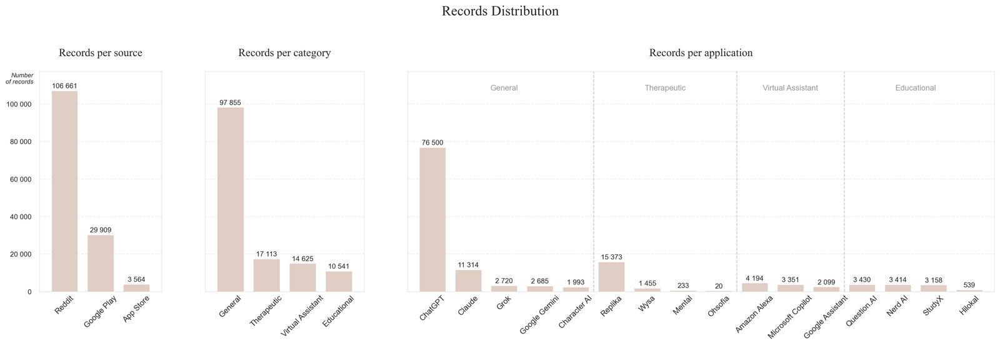

In [112]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 6)   
FIGURE_DPI  = 200       

# ── Helpers ────────────────────────────────────────────────────────────────────

def format_y(value, pos):
    return f"{int(value):,}".replace(",", " ")

def style_ax(ax):
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.grid(axis="x", alpha=0.0)
    ax.tick_params(axis="y", pad=10, labelsize=9, length=0)
    
    for spine in ax.spines.values():
        spine.set_alpha(0.3)

def add_value_labels(ax, values, y_max):
    for i, v in enumerate(values):
        ax.text(i, v + y_max * 0.015, f"{v:,}".replace(",", " "),
                ha="center", fontsize=9)
        
# ── Common Y scale ─────────────────────────────────────────────────────────────

y_max = max(
    df_clean["source"].value_counts().max(),
    df_clean["category"].value_counts().max(),
    df_clean["app_name"].value_counts().max()
) * 1.1

BAR_STYLE   = dict(facecolor="#e0cdc3", edgecolor="#e0cdc3", linewidth=1, alpha=1, width=0.7)
TITLE_STYLE = dict(fontsize=14, fontfamily="Times New Roman", pad=20)
X_MARGIN = 0.7

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    1, 3,
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    gridspec_kw={"width_ratios": [1.0, 1.3, 4.8]}
)
fig.patch.set_facecolor("#f5f2ef")
fig.suptitle("Records Distribution", fontsize=18, fontfamily="Times New Roman", y=1.03)

# ── Chart 1: By Source ──────────────────────────────────────────────────────────

source_counts = df_clean["source"].value_counts()
source_labels = [s.replace("_", " ").title() for s in source_counts.index]

axes[0].bar(source_labels, source_counts.values, **BAR_STYLE)
axes[0].set_xlim(-X_MARGIN, len(source_labels) - 1 + X_MARGIN)
axes[0].set_ylim(0, y_max)
axes[0].tick_params(axis="x", rotation=45, labelsize=10, length=0)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(format_y))
axes[0].set_title("Records per source", loc="center", **TITLE_STYLE)
add_value_labels(axes[0], source_counts.values, y_max)
style_ax(axes[0])

# "Number of records" horizontal above y-axis max
axes[0].text(
    -0.05, 0.94,
    "Number\nof records",
    transform=axes[0].transAxes,
    fontsize=8,
    fontstyle="italic",
    ha="right",
    va="bottom"
)

# ── Chart 2: By Category ────────────────────────────────────────────────────────

cat_counts = df_clean["category"].value_counts()
cat_labels = [c.replace("_", " ").title() for c in cat_counts.index]

axes[1].bar(cat_labels, cat_counts.values, **BAR_STYLE)
axes[1].set_xlim(-X_MARGIN, len(cat_labels) - 1 + X_MARGIN)
axes[1].set_ylim(0, y_max)
axes[1].tick_params(axis="x", rotation=45, labelsize=10, length=0)
axes[1].tick_params(labelleft=False)
axes[1].set_title("Records per category", loc="center", **TITLE_STYLE)
add_value_labels(axes[1], cat_counts.values, y_max)
style_ax(axes[1])

# ── Chart 3: By Application ─────────────────────────────────────────────────────

APP_ORDER = [
    "ChatGPT",
    "Claude",
    "Grok",
    "Google Gemini",
    "Character AI",
    "Replika",
    "Wysa",
    "Mental",
    "Ohsofia",
    "Amazon Alexa",
    "Microsoft Copilot",
    "Google Assistant",
    "Question.AI",
    "Nerd AI",
    "StudyX",
    "Hilokal",
]

CATEGORY_LABELS = {
    "General":           5,   
    "Therapeutic":       4,
    "Virtual Assistant": 3,
    "Educational":       4,
}

app_counts = df_clean["app_name"].value_counts()
app_counts = app_counts.reindex(APP_ORDER)
app_labels = [a.replace("_", " ") for a in app_counts.index]

boundary = 0
for cat_name, count in CATEGORY_LABELS.items():
    start = boundary
    end   = boundary + count

    # Category label - centered
    mid = (start + end) / 2 - 0.5
    axes[2].text(
        mid, y_max * 0.94,
        cat_name,
        ha="center", va="top",
        fontsize=10, 
        alpha=0.4,
        color="#000000"
    )

    # Vertical boundary line
    if boundary > 0:
        axes[2].axvline(
            x=boundary - 0.5,
            color="#000000",
            linewidth=1,
            linestyle="--",
            alpha=0.2,
            zorder=0
        )
    boundary = end
    
axes[2].bar(app_labels, app_counts.values, **BAR_STYLE)
axes[2].set_xlim(-X_MARGIN, len(app_labels) - 1 + X_MARGIN)
axes[2].set_ylim(0, y_max)
axes[2].tick_params(axis="x", rotation=45, labelsize=10, length=0)
axes[2].tick_params(labelleft=False)
axes[2].set_title("Records per application", loc="center", **TITLE_STYLE)
add_value_labels(axes[2], app_counts.values, y_max)
style_ax(axes[2])

# ── Save and display ─────────────────────────────────────────────────────────────

plt.tight_layout()
plt.subplots_adjust(wspace=0.15)
plt.savefig("eda_records_distribution.png", bbox_inches="tight", pad_inches=0.5, 
            transparent=False, facecolor="#f5f2ef")
display(fig)
plt.close()

### 3.3. Temporal Distribution
Monthly record volume per source — provides the baseline for temporal sentiment analysis in later stages.


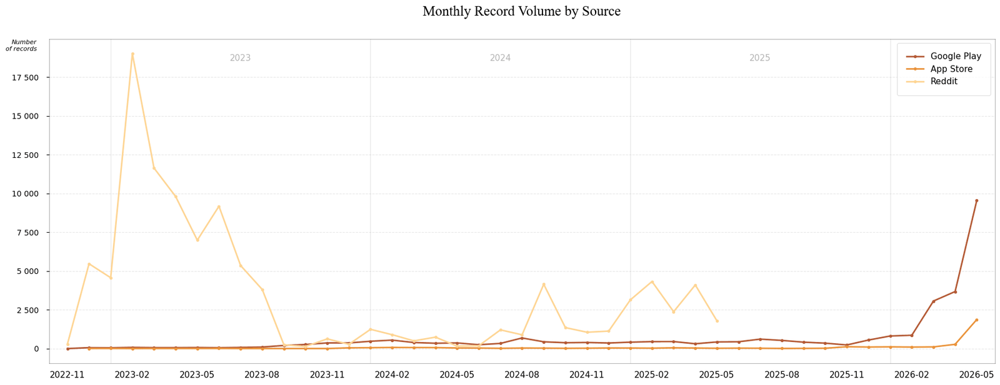

In [8]:
# Monthly record volume per source

monthly = df_clean.groupby(["year_month", "source"]).size().reset_index(name="count")
monthly["year_month_str"] = monthly["year_month"].astype(str)

SOURCE_COLORS = {
    "google_play": "#b45a36",       # red
    "app_store":   "#ea933c",       # orange
    "reddit":      "#fed594"        # yellow
}

fig, ax = plt.subplots(figsize=(18, 7))
fig.patch.set_facecolor("#f5f2ef")

for source, color in SOURCE_COLORS.items():
    subset = monthly[monthly["source"] == source]
    ax.plot(
        subset["year_month_str"],
        subset["count"],
        label=source,
        color=color,
        linewidth=2,
        marker="o",
        markersize=3
    )

# Set x-axis labels
tick_positions = range(0, len(monthly["year_month_str"].unique()), 3)
ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    [monthly["year_month_str"].unique()[i] for i in tick_positions],
    fontsize=11,
)
ax.tick_params(axis="x", pad=10, length=0)

# Set y-axis labels
def format_y(value, pos):
    return f"{int(value):,}".replace(",", " ")
ax.tick_params(axis="y", pad=10)

ax.set_title(
    "Monthly Record Volume by Source",
    fontsize=18,
    fontfamily="Times New Roman",   
    pad=30                          
)
ax.text(
    -0.013, 0.96,                   
    "Number\nof records",
    transform=ax.transAxes,
    fontsize=8,
    fontstyle="italic",
    ha="right",
    alpha=1,
    va="bottom"
)

ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.grid(axis="x", alpha=0.0, linestyle="--")

x_labels = list(monthly["year_month_str"].unique())
years = sorted(set(x[:4] for x in x_labels))

for i, year in enumerate(years):
    first_month = f"{year}-01"
    next_year   = str(int(year) + 1)
    last_month  = f"{next_year}-01"

    if first_month not in x_labels:
        continue

    x_start = x_labels.index(first_month)
    x_end   = x_labels.index(last_month) if last_month in x_labels else len(x_labels) - 1

    # Vertical line separating years
    if i > 0:
        ax.axvline(
            x=x_start,
            color="#000000",
            linewidth=0.8,
            alpha=0.1,
            zorder=0
        )
    
    # Label centred above each year space
    if year != years[-1]:                 
        mid = (x_start + x_end) / 2
        ax.text(
            mid, ax.get_ylim()[1] * 0.95,
            str(year),
            fontsize=11,
            alpha=0.3,
            va="top",
            ha="center"
        )
    
# X axis margins
ax.margins(x=0.02)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_y))

for spine in ax.spines.values():
    spine.set_alpha(0.3)
    
# Custom legend labels 
custom_labels = {
    "google_play": "Google Play",
    "app_store":   "App Store",
    "reddit":      "Reddit"
}

handles, labels = ax.get_legend_handles_labels()
labels = [custom_labels.get(l, l) for l in labels]

legend = ax.legend(
    handles,
    labels,
    frameon=True,
    borderpad=1.1,       
    handlelength=2,
    fontsize=11
)
legend.get_frame().set_linewidth(0.6)

# Extra padding around the plot

plt.tight_layout()
plt.subplots_adjust(wspace=0.15)
plt.savefig("eda_temporal_distribution.png", bbox_inches="tight", pad_inches=0.5, transparent=False)
display(fig)
plt.close()

### 3.4. Rating Distributions
Star rating distributions (1–5) from App Store and Google Play reviews, broken down by chatbot category.


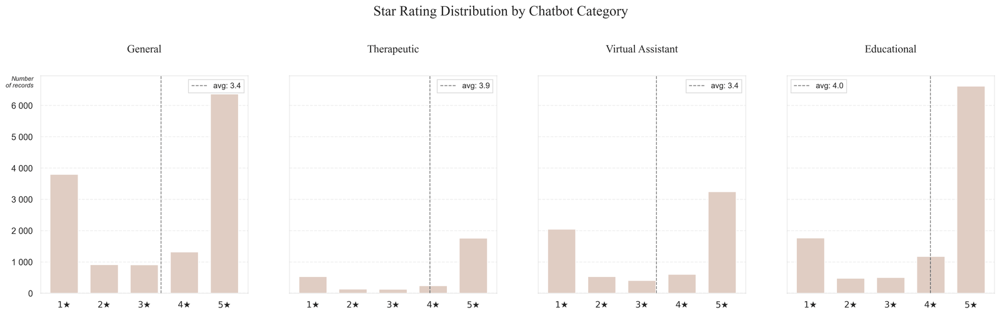

In [115]:
# Star ratings per chatbot category

df_rated = df_clean[df_clean["rating"].notna()].copy()
df_rated["rating"] = df_rated["rating"].astype(int)

categories = df_rated["category"].unique()

fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5.5),   
    sharey=True        
)

fig.suptitle(
    "Star Rating Distribution by Chatbot Category",
    fontsize=18,
    fontfamily="Times New Roman",
    y=1.02
) 

def format_y(value, pos):
    return f"{int(value):,}".replace(",", " ")
    
for i, (ax, category) in enumerate(zip(axes, categories)):
    subset = df_rated[df_rated["category"] == category]
    rating_counts = subset["rating"].value_counts().sort_index()
    color = "#e0cdc3"

    ax.bar(
        rating_counts.index,
        rating_counts.values,
        color=color,
        alpha=1,
        width=0.7
    )

    ax.set_title(
        category.replace("_", " ").title(),
        fontsize=14,
        fontfamily="Times New Roman",
        pad=30
    )

    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xticklabels(
        ["1★", "2★", "3★", "4★", "5★"],
        fontsize=11,
        fontfamily="DejaVu Sans"
    )
    ax.tick_params(axis='x', pad=10, length=0)
    ax.tick_params(axis='y', pad=10, length=0)

    # Average line
    avg = subset["rating"].mean()
    ax.axvline(avg, color="black", linestyle="--", alpha=0.5,
               linewidth=1.0, label=f"avg: {avg:.1f}")

    legend = ax.legend(
        framealpha=0.7,
        fancybox=False,
        frameon=True,
        fontsize=10, 
    )

    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.grid(axis="x", alpha=0.0, linestyle="--")

    for spine in ax.spines.values():
        spine.set_alpha(0.3)

    # "Number of records" only on leftmost chart
    if i == 0:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_y))
        ax.text(
            -0.035, 0.94,
            "Number\nof records",
            transform=ax.transAxes,
            fontsize=8,
            fontstyle="italic",
            ha="right",
            va="bottom"
        )
    else:
        # Hide y-axis tick labels on other charts
        ax.tick_params(labelleft=False)


plt.tight_layout()
plt.subplots_adjust(wspace=0.2)
plt.savefig("eda_rating_distribution.png", bbox_inches="tight", pad_inches=0.5, transparent=False)
display(fig)
plt.close()

### 3.5. Text Length Distribution
Word count distribution per source, highlighting structural differences between the typically short app reviews and the longer Reddit posts and comments.


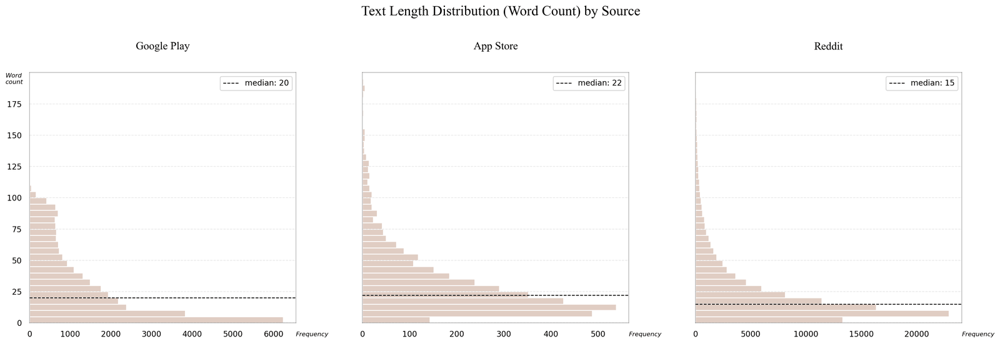


TEXT LENGTH STATISTICS
-----------------------------------------------------------------
                count  mean   std  min   25%   50%   75%     max
source                                                          
app_store      3564.0  31.5  31.7  2.0  12.0  22.0  40.0   374.0
google_play   29909.0  29.4  27.9  1.0   6.0  20.0  46.0   119.0
reddit       106657.0  27.4  40.2  1.0   7.0  15.0  31.0  1156.0


In [13]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 6)
FIGURE_DPI  = 200
WORD_COUNT_MAX = 200

# ── Helpers ────────────────────────────────────────────────────────────────────

def style_ax_hist(ax):
    ax.grid(axis="x", alpha=0.0, linestyle="--")
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.tick_params(axis="both", length=0, pad=10)
    for spine in ax.spines.values():
        spine.set_alpha(0.3)

# ── Word count ─────────────────────────────────────────────────────────────────

df_clean["word_count"] = df_clean["text_sentiment"].str.split().str.len()

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, sharey=True)
fig.suptitle(
    "Text Length Distribution (Word Count) by Source",
    fontsize=18,
    fontfamily="Times New Roman",
    y=1.02
)

# ── Shared bin width — same bar thickness across all charts ────────────────────

BIN_WIDTH = WORD_COUNT_MAX / 40   # 40 bins over the full range

# ── Charts: one per source ─────────────────────────────────────────────────────

BAR_COLOR = "#e0cdc3"
sources   = df_clean["source"].unique()

for i, (ax, source) in enumerate(zip(axes, sources)):
    subset = df_clean[df_clean["source"] == source]["word_count"].dropna()
    subset = subset[subset <= WORD_COUNT_MAX]

    bins = [j * BIN_WIDTH for j in range(41)]   # identical edges on every chart

    ax.hist(
        subset,
        bins=bins,
        orientation="horizontal",
        color="#e0cdc3",
        alpha=1,
        edgecolor="white"
    )
    ax.set_title(
        source.replace("_", " ").title(),
        fontsize=14,
        fontfamily="Times New Roman",
        pad=30
    )
    ax.set_ylim(0, WORD_COUNT_MAX)
    yticks = [t for t in ax.get_yticks() if int(t) != WORD_COUNT_MAX]
    ax.set_yticks(yticks)

    # "Frequency" label below x-axis, right-aligned
    ax.text(
        1.0, -0.058,
        "Frequency",
        transform=ax.transAxes,
        fontsize=8,
        fontstyle="italic",
        ha="left",
        va="bottom"
    )

    # Y-axis label and tick formatting — leftmost chart only
    if i == 0:
        ax.text(
            -0.09, 0.95,
            "Word\ncount",
            transform=ax.transAxes,
            fontsize=8,
            fontstyle="italic",
            ha="left",
            va="bottom"
        )
        
    # Median line
    median = subset.median()
    ax.axhline(
        median,
        color="black",
        linestyle="--",
        linewidth=1.0,
        label=f"median: {median:.0f}"
    )
    ax.legend(fontsize=10, frameon=True)
    style_ax_hist(ax)

# ── Save and display ───────────────────────────────────────────────────────────

plt.tight_layout()
plt.subplots_adjust(wspace=0.25)
plt.savefig("eda_text_length.png", bbox_inches="tight", pad_inches=0.5, transparent=False)
display(fig)
plt.close()

# ── Statistics ─────────────────────────────────────────────────────────────────

print("\nTEXT LENGTH STATISTICS")
print(65 * "-")
print(df_clean.groupby("source")["word_count"].describe().round(1))

### 3.6. Word Clouds per Category
Most frequent words per chatbot category — a first visual impression of the dominant topics and language used by users in each context.


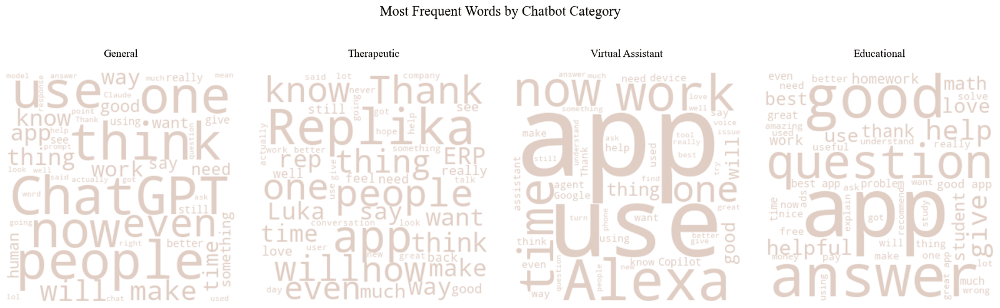

In [20]:
# Most frequent words per chatbot category
# Provides first visual impression of dominant topics and language

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
fig.suptitle("Most Frequent Words by Chatbot Category",
             fontsize=18, fontfamily="Times New Roman", y=1.01)

categories = df_clean["category"].unique()

for ax, category in zip(axes.flatten(), categories):
    subset = df_clean[df_clean["category"] == category]["text_sentiment"].dropna()
    text = " ".join(subset)

    color = "#e0cdc3"

    wordcloud = WordCloud(
        width=300,
        height=300,
        background_color="#f5f2ef",
        color_func=lambda *args, **kwargs: color,
        max_words=50,
        collocations=True,      
        min_word_length=3
    ).generate(text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(category.replace("_", " ").title(), fontfamily="Times New Roman", fontsize=14, pad=20)
    ax.axis("off")

plt.tight_layout()
plt.subplots_adjust(wspace=0.10)
plt.savefig("eda_wordclouds.png", bbox_inches="tight", pad_inches=0.5)
plt.show()

## 4. Sentiment & Arousal Analysis
To capture both general sentiment and nuanced emotional responses toward AI chatbots, three complementary approaches are applied:
 1. **VADER** — rule-based measure of positive, negative, and neutral sentiment - an efficient baseline
 2. **NRC VAD**  — emotional dimensions of valence, arousal, and dominance with a lexicon-based approach
 3. **GoEmotions**  — 27 discrete emotions + a neutral category - for a fine-grained examination of users' emotional reactions

Each method represents a different level of affective analysis. Together, they offer a multidimensional perspective on how users perceive and experience all four categories of AI chatbots under study.

### 4.1. VADER — Baseline Sentiment Analysis
VADER (Valence Aware Dictionary and sEntiment Reasoner) is a rule-based model optimised for informal social media text. It assigns a compound score
ranging from -1 (most negative) to +1 (most positive). A three-class label is derived using standard VADER thresholds:
1. **positive** (>= 0.05)
2. **negative** (<= -0.05)
3. **neutral** (-0.05< and <0.05)

In [29]:
# VADER sentiment analysis

analyzer = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    """
    Returns VADER compound score and three-class sentiment label.
    Handles NaN and non-string values gracefully.
    """
    if not isinstance(text, str) or not text.strip():
        return 0.0, "neutral"

    scores = analyzer.polarity_scores(text)
    compound = scores["compound"]

    if compound >= 0.05:
        label = "positive"
    elif compound <= -0.05:
        label = "negative"
    else:
        label = "neutral"

    return compound, label

df_vader = df_clean.copy()
df_vader[["vader_score", "vader_label"]] = df_vader["text_sentiment"].apply(
    lambda x: pd.Series(get_vader_sentiment(x))
)

print("\nVADER RESULTS")
print("-" * 30)
print(df_vader["vader_label"].value_counts())
print("-" * 30)
print(f"\nAverage compound score: {df_vader['vader_score'].mean():.3f}")


VADER RESULTS
------------------------------
vader_label
positive    77439
negative    31941
neutral     30754
Name: count, dtype: int64
------------------------------

Average compound score: 0.217


### 4.2. NRC VAD Analysis
Emotional dimensions are extracted using the NRC Valence–Arousal–Dominance (VAD) Lexicon. The lexicon assigns numerical scores for valence, arousal, and dominance to individual words. For each record, the mean values across all matched words are calculated for: 
- **valence**: positive (+1) to negative (-1)
- **arousal**: high (+1) to low (-1)
- **dominance**: high (+1) to low (-1)

Additionally, lexical coverage is computed as the proportion of words successfully matched to the lexicon. This approach enables the projection of user-generated content onto the circumplex model of affect and facilitates comparisons across chatbot categories.

In [31]:
# NRC VAD Analysis

# Reach the Lexicon
vad_dict = nrc_vad.set_index("term")[
    ["valence", "arousal", "dominance"]
].to_dict("index")

def calculate_vad(text):
    """
    Calculate record-level VAD scores.
    """

    if pd.isna(text) or text == "":
        return pd.Series({
            "nrc_valence": np.nan,
            "nrc_arousal": np.nan,
            "nrc_dominance": np.nan,
            "nrc_coverage": 0
        })

    tokens = text.split()

    total_words = len(tokens)

    valence_scores = []
    arousal_scores = []
    dominance_scores = []

    for token in tokens:

        if token in vad_dict:

            valence_scores.append(
                vad_dict[token]["valence"]
            )

            arousal_scores.append(
                vad_dict[token]["arousal"]
            )

            dominance_scores.append(
                vad_dict[token]["dominance"]
            )

    matched_words = len(valence_scores)

    if matched_words == 0:

        return pd.Series({
            "nrc_valence": np.nan,
            "nrc_arousal": np.nan,
            "nrc_dominance": np.nan,
            "nrc_coverage": 0
        })

    return pd.Series({
        "nrc_valence": np.mean(valence_scores),
        "nrc_arousal": np.mean(arousal_scores),
        "nrc_dominance": np.mean(dominance_scores),
        "nrc_coverage": matched_words / total_words
    })


# Run analysis on the dataset
tqdm.pandas()

df_nrc = df_vader.copy()
vad_results = df_nrc["text_lemmatised"].progress_apply(calculate_vad)

df_nrc = pd.concat([df_nrc, vad_results], axis=1)

print(df_nrc.head())

100%|████████████████████████████████████████████████████████████████████████| 140134/140134 [01:11<00:00, 1969.44it/s]

  category       source                                              text  \
0  general  google_play                                              good   
1  general  google_play                                           great 👍   
2  general  google_play                                              good   
3  general  google_play                                              good   
4  general  google_play  ChatGPT helps you with everything and it's free!   

   rating  thumbs_up subreddit author  year  month post_id  ... year_month  \
0     3.0        0.0       NaN    NaN  2026      5     NaN  ...    2026-05   
1     5.0        0.0       NaN    NaN  2026      5     NaN  ...    2026-05   
2     5.0        0.0       NaN    NaN  2026      5     NaN  ...    2026-05   
3     5.0        0.0       NaN    NaN  2026      5     NaN  ...    2026-05   
4     5.0        0.0       NaN    NaN  2026      5     NaN  ...    2026-05   

  app_name                                    text_sentiment  \
0  C

### 4.3. GoEmotions — 28-Emotion Classification
Since `SamLowe/roberta-base-go_emotions` was trained on Google's GoEmotions dataset (58,000 Reddit comments), it seems particularly suitable for this dataset. It detects **28 fine-grained emotions**, which are subsequently mapped to two axes of Russell's Circumplex Model of Affect:
- **valence**: positive (+1) to negative (-1)
- **arousal**: high (+1) to low (-1)

The model captures the three strongest emotions in each text, reflecting the multidimensional nature of emotional responses.
Coordinates are based on established psychological literature (Russell, 1980; Warriner et al., 2013).

In [ ]:
# 28-Emotion Classifier

go_emotions = pipeline(
    "text-classification",
    model="SamLowe/roberta-base-go_emotions",
    device=0 if torch.cuda.is_available() else -1,
    truncation=True,
    max_length=512,
    top_k=3
)

def get_top_emotion(text):
    """
    Returns the dominant emotion and its confidence score.
    Uses top-1 result from GoEmotions 28-class classifier.
    """
    if not isinstance(text, str) or not text.strip():
        return "neutral", 0.0
    try:
        result = go_emotions(text[:512])[0]
        return result[0]["label"], round(result[0]["score"], 4)
    except:
        return "neutral", 0.0

df_emotion = df_nrc.copy()
df_emotion[["emotion", "emotion_score"]] = df_emotion["text_sentiment"].apply(
    lambda x: pd.Series(get_top_emotion(x))
)

print("\nEMOTION DISTRIBUTION")
print("-" * 30)
print(df_emotion["emotion"].value_counts().head(30))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [23]:
# Emotion mapping to Russell model

russell_mapping = {
    "excitement":     {"emotion_valence":  0.9, "emotion_arousal":  0.9},
    "joy":            {"emotion_valence":  0.9, "emotion_arousal":  0.7},
    "amusement":      {"emotion_valence":  0.8, "emotion_arousal":  0.6},
    "admiration":     {"emotion_valence":  0.8, "emotion_arousal":  0.5},
    "approval":       {"emotion_valence":  0.6, "emotion_arousal":  0.2},
    "pride":          {"emotion_valence":  0.3, "emotion_arousal":  0.5},
    "love":           {"emotion_valence":  1.0, "emotion_arousal":  0.4},
    "desire":         {"emotion_valence":  0.5, "emotion_arousal":  0.6},
    "optimism":       {"emotion_valence":  0.7, "emotion_arousal":  0.3},
    "caring":         {"emotion_valence":  0.6, "emotion_arousal": -0.2},
    "gratitude":      {"emotion_valence":  0.9, "emotion_arousal": -0.3},
    "relief":         {"emotion_valence":  0.7, "emotion_arousal": -0.5},
    "curiosity":      {"emotion_valence":  0.3, "emotion_arousal":  0.4},
    "realization":    {"emotion_valence":  0.2, "emotion_arousal":  0.2},
    "surprise":       {"emotion_valence":  0.1, "emotion_arousal":  0.7},
    "neutral":        {"emotion_valence":  0.0, "emotion_arousal":  0.0},
    "confusion":      {"emotion_valence": -0.2, "emotion_arousal":  0.3},
    "disapproval":    {"emotion_valence": -0.5, "emotion_arousal":  0.2},
    "annoyance":      {"emotion_valence": -0.7, "emotion_arousal":  0.6},
    "anger":          {"emotion_valence": -0.9, "emotion_arousal":  0.9},
    "fear":           {"emotion_valence": -0.7, "emotion_arousal":  0.7},
    "nervousness":    {"emotion_valence": -0.6, "emotion_arousal":  0.8},
    "disgust":        {"emotion_valence": -0.8, "emotion_arousal":  0.3},
    "embarrassment":  {"emotion_valence": -0.5, "emotion_arousal":  0.4},
    "disappointment": {"emotion_valence": -0.6, "emotion_arousal": -0.2},
    "remorse":        {"emotion_valence": -0.7, "emotion_arousal": -0.3},
    "sadness":        {"emotion_valence": -0.8, "emotion_arousal": -0.6},
    "grief":          {"emotion_valence": -0.9, "emotion_arousal": -0.4},
}

# Map each detected emotion to valence and arousal coordinates
df_emotion["emotion_valence"] = df_emotion["emotion"].map(
    lambda e: russell_mapping.get(e, {}).get("emotion_valence", 0.0)
)
df_emotion["emotion_arousal"] = df_emotion["emotion"].map(
    lambda e: russell_mapping.get(e, {}).get("emotion_arousal", 0.0)
)

print("\nRUSSELL'S COORDINATES")
print("-" * 50)
print(df_emotion[["emotion", "emotion_valence", "emotion_arousal"]].head(10))
print("-" * 50)
print(f"\nAverage valence: {df_emotion['emotion_valence'].mean():.3f}")
print(f"Average arousal: {df_emotion['emotion_arousal'].mean():.3f}")


RUSSELL'S COORDINATES
--------------------------------------------------
       emotion  emotion_valence  emotion_arousal
0   admiration              0.8              0.5
1   admiration              0.8              0.5
2   admiration              0.8              0.5
3   admiration              0.8              0.5
4      neutral              0.0              0.0
5      neutral              0.0              0.0
6   admiration              0.8              0.5
7   admiration              0.8              0.5
8  disapproval             -0.5              0.2
9      neutral              0.0              0.0
--------------------------------------------------

Average valence: 0.197
Average arousal: 0.208


### 4.4. Results Save & Overview

In [24]:
# File save
df_emotion.to_csv(PROCESSED_DIR / "opinions_emotion.csv", index=False)

# Quick overview
df_emotion[["emotion_valence", "emotion_arousal",                          # GoEmotions output
            "nrc_valence", "nrc_arousal", "nrc_dominance", "nrc_coverage", # NRC output
            "vader_score"]].describe()                                     # VADER output

,emotion_valence,emotion_arousal,nrc_valence,nrc_arousal,nrc_dominance,nrc_coverage,vader_score
count,140134.000000,140134.000000,136976.000000,136976.000000,136976.000000,140134.000000,140134.000000
mean,0.196627,0.208074,0.215586,-0.080665,0.070011,0.821573,0.216636
std,0.503603,0.292010,0.251573,0.173335,0.180592,0.199737,0.493761
min,-0.900000,-0.600000,-1.000000,-1.000000,-1.000000,0.000000,-0.999000
25%,0.000000,0.000000,0.087529,-0.180893,-0.028924,0.750000,0.000000
50%,0.000000,0.200000,0.207635,-0.096500,0.066500,0.857143,0.250000
75%,0.800000,0.500000,0.334679,-0.001759,0.163364,1.000000,0.636900
max,1.000000,0.900000,1.000000,1.000000,1.000000,1.000000,0.999900


## 5. Inter-Model Agreement Analysis

To assess the consistency of sentiment and arousal signals across methods, inter-model agreement was examined using **three complementary approaches**. 

First, Pearson and Spearman correlations were computed between continuous scores produced by VADER, NRC VAD, and GoEmotions, capturing the degree of **linear and monotonic alignment across models**. Second, Cohen's kappa was calculated on categorised labels — positive, neutral, and negative — derived from each model using a **shared classification threshold**, providing a measure of agreement corrected for chance. To complement the correlation-based assessment, Bland–Altman analysis is performed to **evaluate the agreement between sentiment models at the individual review level**.

This complex approach allows for a distinction between **general directional consistency**, reflected in moderate correlations, and **categorical agreement**, which proved considerably weaker. Together, the results inform the degree to which the three models can be treated as interchangeable operationalisations of sentiment and valence.

### 5.1. Pairwise Correlations
To assess the consistency between sentiment and arousal analysis approaches, pairwise correlations were calculated between sentiment scores generated by different models. 
- **Pearson correlation** - evaluates linear relationships
- **Spearman correlation** - accounts for non-linear monotonic associations

#### 5.1.1. Valence Pairwise Correlations

A **moderate positive relationship** is observed across all three model pairs. Pearson and Spearman correlation analyses reveal statistically significant associations in each case (p < .001).

The strongest alignment is found between VADER and GoEmotions (r = 0.561, rho = 0.556), suggesting these two models capture sentiment tendencies most similarly. A comparable relationship is observed between VADER and NRC VAD (r = 0.473, rho = 0.522), while the weakest — though still significant — correlation exists between NRC VAD and GoEmotions (r = 0.435, rho = 0.444).

These findings suggest that **all models capture similar affective tendencies**, with higher sentiment scores generally corresponding to higher valence values. However, the moderate strength of the correlations indicates that **the models are not interchangeable** and likely emphasise different linguistic and emotional characteristics of user-generated content.

In [35]:
# ── Sentiment (valence) pairwise correlations ─────────────────────────────────────

# Remove missing values
comparison = df_emotion[["vader_score", "nrc_valence", "emotion_valence"]].dropna()

# ── Pearson correlation ───────────────────────────────────────────────────────────

# VADER - NRC VAD
pearson_r1, pearson_p1 = pearsonr(
    comparison["vader_score"],
    comparison["nrc_valence"]
)

# VADER - GoEmotions
pearson_r2, pearson_p2 = pearsonr(
    comparison["vader_score"],
    comparison["emotion_valence"]
)

# NRC VAD - GoEmotions
pearson_r3, pearson_p3 = pearsonr(
    comparison["nrc_valence"],
    comparison["emotion_valence"]
)

# ── Spearman correlation ──────────────────────────────────────────────────────────

# VADER - NRC VAD
spearman_rho1, spearman_p1 = spearmanr(
    comparison["vader_score"],
    comparison["nrc_valence"]
)

# VADER - GoEmotions
spearman_rho2, spearman_p2 = spearmanr(
    comparison["vader_score"],
    comparison["emotion_valence"]
)

# NRC VAD - GoEmotions
spearman_rho3, spearman_p3 = spearmanr(
    comparison["nrc_valence"],
    comparison["emotion_valence"]
)

# ── Outputs print ────────────────────────────────────────────────────────────────

print(f"\nValence Pairwise Correlation")
print("-" * 36)
print(f"\nVADER - NRC VAD:")
print("-" * 36)
print(f"Pearson r = {pearson_r1:.3f}, p = {pearson_p1:.5f}")
print(f"Spearman rho = {spearman_rho1:.3f}, p = {spearman_p1:.5f}")
print("-" * 36)

print(f"\nVADER - GoEmotions:")
print("-" * 36)
print(f"Pearson r = {pearson_r2:.3f}, p = {pearson_p2:.5f}")
print(f"Spearman rho = {spearman_rho2:.3f}, p = {spearman_p2:.5f}")
print("-" * 36)

print(f"\nNRC VAD - GoEmotions:")
print("-" * 36)
print(f"Pearson r = {pearson_r3:.3f}, p = {pearson_p3:.5f}")
print(f"Spearman rho = {spearman_rho3:.3f}, p = {spearman_p3:.5f}")
print("-" * 36)


Valence Pairwise Correlation
------------------------------------

VADER - NRC VAD:
------------------------------------
Pearson r = 0.473, p = 0.00000
Spearman rho = 0.522, p = 0.00000
------------------------------------

VADER - GoEmotions:
------------------------------------
Pearson r = 0.561, p = 0.00000
Spearman rho = 0.556, p = 0.00000
------------------------------------

NRC VAD - GoEmotions:
------------------------------------
Pearson r = 0.435, p = 0.00000
Spearman rho = 0.444, p = 0.00000
------------------------------------


#### 5.1.2. Arousal Pairwise Correlations
A **weak positive relationship** is observed between GoEmotions sentiment scores and NRC VAD arousal scores. 

Pearson and Spearman correlations confirm a **statistically significant but negligible association** (r = 0.131, rho = 0.126, p < .001).

In [36]:
# ── Arousal pairwise correlations ─────────────────────────────────────────────────

# Remove missing values
comparison = df_emotion[["nrc_arousal", "emotion_arousal"]].dropna()

# ── Pearson correlation ───────────────────────────────────────────────────────────

# NRC VAD - GoEmotions
pearson_r, pearson_p = pearsonr(
    comparison["nrc_arousal"],
    comparison["emotion_arousal"]
)

# ── Spearman correlation ──────────────────────────────────────────────────────────

# NRC VAD - GoEmotions
spearman_rho, spearman_p = spearmanr(
    comparison["nrc_arousal"],
    comparison["emotion_arousal"]
)

# ── Outputs print ────────────────────────────────────────────────────────────────

print(f"\nArousal Pairwise Correlation")
print("-" * 36)
print(f"\nNRC VAD - GoEmotions:")
print("-" * 36)
print(f"Pearson r = {pearson_r:.3f}, p = {pearson_p:.5f}")
print(f"Spearman rho = {spearman_rho:.3f}, p = {spearman_p:.5f}")
print("-" * 36)


Arousal Pairwise Correlation
------------------------------------

NRC VAD - GoEmotions:
------------------------------------
Pearson r = 0.131, p = 0.00000
Spearman rho = 0.126, p = 0.00000
------------------------------------


#### 5.1.3. Correlations Matrix

- **The strongest cross-model alignments are observed along the valence dimension.** VADER sentiment scores correlate moderately with both NRC valence (r = 0.52) and GoEmotions valence (r = 0.56), confirming that all three models capture a shared directional signal — the positive-to-negative axis of affect. This is theoretically expected, as VADER was designed specifically to measure sentiment polarity, which closely corresponds to valence in dimensional emotion models.

- Within the NRC VAD framework, valence and dominance show a notably strong relationship (r = 0.56), suggesting that words perceived as positive tend to also be perceived as conveying control or agency — a pattern consistent with existing psycholinguistic research on the VAD dimensions.

- **The arousal dimension presents a strikingly different picture.** NRC arousal shows negligible or near-zero correlations with almost all other variables, including GoEmotions arousal (r = 0.13). This weak alignment indicates that the two models operationalise arousal in fundamentally different ways. Arousal remains the least stable and most model-dependent dimension. These findings support treating the models as complementary rather than interchangeable, and justify a degree of caution when interpreting arousal-based comparisons across methods.

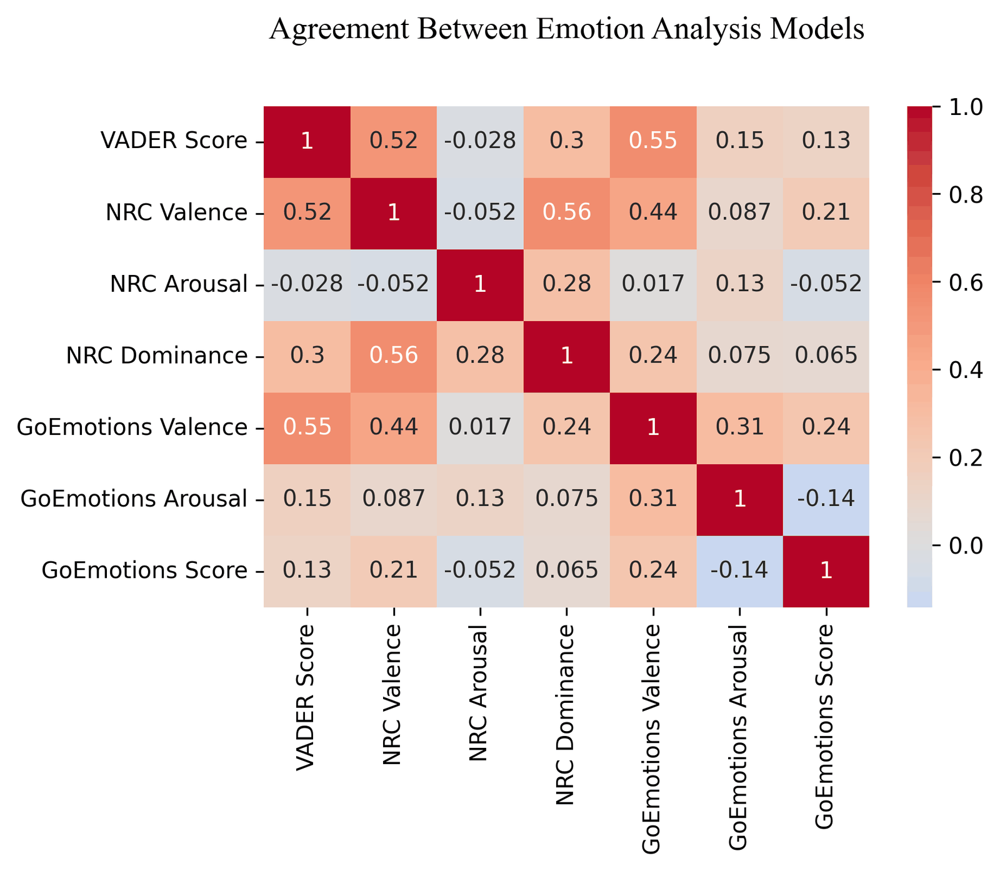

In [10]:
# ── Inter-Models Agreement Matrix ─────────────────────────

# Matrix labels dictionary

LABEL_NAMES = {
    "vader_score":      "VADER Score",
    "nrc_valence":      "NRC Valence",
    "nrc_arousal":      "NRC Arousal",
    "nrc_dominance":    "NRC Dominance",
    "emotion_valence":  "GoEmotions Valence",
    "emotion_arousal":  "GoEmotions Arousal",
    "emotion_score":    "GoEmotions Score"
}

cols = list(LABEL_NAMES.keys())

# Spearman correlation

corr = df_emotion[cols].corr(method="spearman")
corr.index   = [LABEL_NAMES[c] for c in corr.index]
corr.columns = [LABEL_NAMES[c] for c in corr.columns]

# Figure properties

plt.figure(figsize=(6,4), dpi=300)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0
)

# Plot parameters

plt.title("Agreement Between Emotion Analysis Models", 
          fontfamily="Times New Roman", 
          fontsize=14, 
          pad=30)
plt.savefig("Agreement_Between_Emotion_Analysis_Models.png", 
            bbox_inches="tight", 
            pad_inches=0.5)
plt.show()

### 5.2. Cohen's Kappa
*Do the models agreeably assign the same positive-neutral-negative label to opinions?*

**Inter-model agreement, measured using Cohen's kappa, is consistently low across all three pairs.**

The highest agreement is observed between VADER and GoEmotions (κ = 0.378, "fair"), likely reflecting their shared social media training origins. VADER and NRC VAD show slight-to-fair agreement (κ = 0.241), while NRC VAD and GoEmotions diverge most strongly (κ = 0.148, "slight"), consistent with the fundamental difference between a static lexicon and a transformer-based model. These results reinforce the conclusion that the models are complementary rather than interchangeable.

Note: thresholds here (±0.1) differ from standard VADER thresholds (±0.05) used in Section 4.1. A wider neutral band is applied to ensure comparability across models with different score scales; kappa results reflect this shared classification scheme.

In [10]:
# ── Classification thresholds ──────────────────────────────────────────────────

NEG_THRESHOLD = -0.1
POS_THRESHOLD =  0.1

def sentiment_class(score):
    if score > POS_THRESHOLD:
        return "positive"
    elif score < NEG_THRESHOLD:
        return "negative"
    else:
        return "neutral"

# ── Complete observations ──────────────────────────────────────────────────────

agreement_df = df_emotion[
    ["vader_score", "nrc_valence", "emotion_valence"]
].dropna().copy()

# ── Classify each model ────────────────────────────────────────────────────────

agreement_df["vader_label"]   = agreement_df["vader_score"].apply(sentiment_class)
agreement_df["nrc_label"]     = agreement_df["nrc_valence"].apply(sentiment_class)
agreement_df["emotion_label"] = agreement_df["emotion_valence"].apply(sentiment_class)

# ── Cohen's Kappa — all three pairs ───────────────────────────────────────────

pairs = {
    "VADER – NRC VAD":      ("vader_label",   "nrc_label"),
    "VADER – GoEmotions":   ("vader_label",   "emotion_label"),
    "NRC VAD – GoEmotions": ("nrc_label",     "emotion_label"),
}

for pair_name, (col_a, col_b) in pairs.items():
    kappa = cohen_kappa_score(agreement_df[col_a], agreement_df[col_b])
    print(f"{pair_name}")
    print(f"{'-' * 36}")
    print(f"Cohen's kappa = {kappa:.3f}")
    print()

VADER – NRC VAD
------------------------------------
Cohen's kappa = 0.241

VADER – GoEmotions
------------------------------------
Cohen's kappa = 0.378

NRC VAD – GoEmotions
------------------------------------
Cohen's kappa = 0.148



### 5.3. Bland–Altman Analysis

To complement the correlation-based assessment, Bland–Altman analysis is performed to **evaluate the agreement between sentiment models at the individual review level**.

The mean differences (biases) between all model pairs are very close to zero, ranging from 0.005 to 0.020. This indicates the **absence of substantial systematic bias** and suggests that none of the models consistently produce higher or lower sentiment scores than the others on average.

However, the **calculated limits of agreement are relatively wide**. For all model pairs, the 95% limits of agreement extend approximately from −0.9 to +0.9 sentiment units. Considering that sentiment scores are normalized to a range between −1 and 1, these intervals represent a substantial proportion of the entire measurement scale.

These findings indicate that **although the models exhibit similar average behaviour, their predictions may differ considerably for individual reviews**. Consequently, high correlations observed between sentiment models should not be interpreted as evidence of interchangeability. The models tend to capture similar overall sentiment trends across the dataset, but they often assign substantially different sentiment scores to specific observations. The Bland–Altman analysis therefore provides additional evidence that correlation alone is insufficient for evaluating agreement between sentiment analysis methods and highlights important differences in model behaviour at the review level.

In [5]:
# Results

comparison_results = []

for name1, col1, name2, col2 in [
    ("VADER",   "vader_score",
     "NRC VAD", "nrc_valence"),
    ("VADER",      "vader_score",
     "GoEmotions", "emotion_valence"),
    ("NRC VAD",    "nrc_valence",
     "GoEmotions", "emotion_valence")
]:
    diff = df_emotion[col1] - df_emotion[col2]
    bias = diff.mean()
    sd   = diff.std()

    comparison_results.append({
        "Comparison": f"{name1} vs {name2}",
        "Bias":       bias,
        "Lower LoA":  bias - 1.96 * sd,
        "Upper LoA":  bias + 1.96 * sd
    })


def bland_altman_stats(series_a, series_b, label=""):
    """
    Compute Bland–Altman agreement statistics for two sentiment model score series.

    Parameters
    ----------
    series_a : pd.Series   First model's scores  (e.g. vader_score)
    series_b : pd.Series   Second model's scores (e.g. nrc_valence)
    label    : str         Comparison label for printed output

    Returns
    -------
    dict  {"bias": float, "lower_loa": float, "upper_loa": float, "n": int}
    """

    df = (
        series_a.rename("a")
        .to_frame()
        .join(series_b.rename("b"))
        .dropna()
    )

    diffs     = df["a"] - df["b"]
    bias      = diffs.mean()
    sd        = diffs.std()
    upper_loa = bias + 1.96 * sd
    lower_loa = bias - 1.96 * sd
    n         = len(diffs)

    print(f"{label}")
    print(f"  n          = {n:,}")
    print(f"  Bias       = {bias:+.4f}")
    print(f"  Lower LoA  = {lower_loa:+.4f}")
    print(f"  Upper LoA  = {upper_loa:+.4f}")
    print()

    return {
        "bias":      bias,
        "lower_loa": lower_loa,
        "upper_loa": upper_loa,
        "n":         n
    }


print("BLAND–ALTMAN AGREEMENT STATISTICS")
print("=" * 40)

results_vader_nrc = bland_altman_stats(
    df_emotion["vader_score"],
    df_emotion["nrc_valence"],
    "VADER vs NRC VAD"
)

results_vader_go = bland_altman_stats(
    df_emotion["vader_score"],
    df_emotion["emotion_valence"],
    "VADER vs GoEmotions"
)

results_nrc_go = bland_altman_stats(
    df_emotion["nrc_valence"],
    df_emotion["emotion_valence"],
    "NRC VAD vs GoEmotions"
)

BLAND–ALTMAN AGREEMENT STATISTICS
VADER vs NRC VAD
  n          = 136,976
  Bias       = +0.0054
  Lower LoA  = -0.8541
  Upper LoA  = +0.8648

VADER vs GoEmotions
  n          = 140,134
  Bias       = +0.0200
  Lower LoA  = -0.8968
  Upper LoA  = +0.9368

NRC VAD vs GoEmotions
  n          = 136,976
  Bias       = +0.0157
  Lower LoA  = -0.8810
  Upper LoA  = +0.9125



## 6. Inter-Category Differences 

To examine whether **chatbot category systematically influences the emotional tone of user-generated content**, inter-category differences were assessed across valence and arousal dimensions using non-parametric statistical methods. 

The Kruskal-Wallis test was applied to **determine whether score distributions differed significantly** across the four categories — general, therapeutic, virtual assistant, and educational — for each model separately. Where significant differences were found, Dunn's post-hoc test with Bonferroni correction was used to identify **which specific category pairs drove the effect**. Effect sizes were quantified using epsilon-squared (ε²), allowing for an assessment of **practical significance** beyond statistical significance alone.

All analyses were conducted independently for each model to account for differences in how VADER, NRC VAD, and GoEmotions operationalise affective dimensions, and to enable cross-model comparison of category sensitivity.

### 6.1. Kruskal-Wallis Test for Pairwise Differences
*Do valence and arousal indicators show pairwise differences among chatbot categories?*

#### 6.1.1. Inter-Category Valence Differences

The Kruskal-Wallis test reveals **statistically significant differences** in valence scores across chatbot categories for all three models (p < .001).

**GoEmotions shows the strongest separation** between categories (H = 4838.49), followed by VADER (H = 3467.24) and NRC VAD (H = 2767.03), suggesting that category membership has an increasingly pronounced effect depending on the model used. 

These results confirm that the four chatbot categories — general, therapeutic, virtual assistant, and educational — elicit meaningfully different emotional responses from users across all three analytical approaches.

In [50]:
# Kruskal-Wallis Test for Pairwise Differences - Valence
print("Kruskal-Wallis Test for Pairwise Differences - Valence")
print("=" * 55)

# ── NRC VAD ────────────────────────────────────────────────────────────────────

general_nrc_valence      = df_emotion[df_emotion["category"] == "general"]["nrc_valence"].dropna()
assistant_nrc_valence    = df_emotion[df_emotion["category"] == "virtual_assistant"]["nrc_valence"].dropna()
educational_nrc_valence  = df_emotion[df_emotion["category"] == "educational"]["nrc_valence"].dropna()
therapeutic_nrc_valence  = df_emotion[df_emotion["category"] == "therapeutic"]["nrc_valence"].dropna()

stat_nrc, p_nrc = kruskal(
    general_nrc_valence,
    assistant_nrc_valence,
    educational_nrc_valence,
    therapeutic_nrc_valence
)

print()
print("NRC VAD")
print("-" * 55)
print(f"Kruskal-Wallis H = {stat_nrc:.3f}")
print(f"p-value = {p_nrc:.5f}")
print("-" * 55)

# ── VADER ──────────────────────────────────────────────────────────────────────

general_vader     = df_emotion[df_emotion["category"] == "general"]["vader_score"].dropna()
assistant_vader   = df_emotion[df_emotion["category"] == "virtual_assistant"]["vader_score"].dropna()
educational_vader = df_emotion[df_emotion["category"] == "educational"]["vader_score"].dropna()
therapeutic_vader = df_emotion[df_emotion["category"] == "therapeutic"]["vader_score"].dropna()

stat_vader, p_vader = kruskal(
    general_vader,
    assistant_vader,
    educational_vader,
    therapeutic_vader
)
print()
print("VADER")
print("-" * 55)
print(f"Kruskal-Wallis H = {stat_vader:.3f}")
print(f"p-value = {p_vader:.5f}")
print("-" * 55)

# ── GoEmotions ─────────────────────────────────────────────────────────────────

general_emotion_valence     = df_emotion[df_emotion["category"] == "general"]["emotion_valence"].dropna()
assistant_emotion_valence   = df_emotion[df_emotion["category"] == "virtual_assistant"]["emotion_valence"].dropna()
educational_emotion_valence = df_emotion[df_emotion["category"] == "educational"]["emotion_valence"].dropna()
therapeutic_emotion_valence = df_emotion[df_emotion["category"] == "therapeutic"]["emotion_valence"].dropna()

stat_emotion, p_emotion = kruskal(
    general_emotion_valence,
    assistant_emotion_valence,
    educational_emotion_valence,
    therapeutic_emotion_valence
)
print()
print("GoEmotions")
print("-" * 55)
print(f"Kruskal-Wallis H = {stat_emotion:.3f}")
print(f"p-value = {p_emotion:.5f}")
print("-" * 55)

Kruskal-Wallis Test for Pairwise Differences - Valence

NRC VAD
-------------------------------------------------------
Kruskal-Wallis H = 2767.027
p-value = 0.00000
-------------------------------------------------------

VADER
-------------------------------------------------------
Kruskal-Wallis H = 3467.242
p-value = 0.00000
-------------------------------------------------------

GoEmotions
-------------------------------------------------------
Kruskal-Wallis H = 4830.195
p-value = 0.00000
-------------------------------------------------------


#### 6.1.2. Valence Differences Effect Size

*Are the differences in valence meaningful?*

Effect sizes for inter-category valence differences are **small across all three models**, yet **consistent and practically meaningful**. 

GoEmotions shows the largest effect (ε² = 0.035), followed by VADER (ε² = 0.025) and NRC VAD (ε² = 0.020), indicating that chatbot category accounts for 2–3.5% of the variance in valence scores depending on the model. 

While modest by conventional benchmarks, the consistency of this pattern across three independent analytical approaches strengthens the conclusion that **category membership has a genuine influence on the emotional tone of user-generated content**.

Effect size is estimated using epsilon-squared (ε²), as recommended by Tomczak & Tomczak (2014) for the Kruskal-Wallis test: **ε² = (H - k + 1) / (n - k)** where H is the Kruskal-Wallis statistic, k is the number of groups, and n is the total number of observations. This formulation is preferred over the simpler H / (n - 1) approximation as it accounts for the number of groups and yields a less biased estimate. Benchmarks: ε² ≥ 0.01 small, ≥ 0.06 medium, ≥ 0.14 large (Cohen, 1988).

Reference:

Tomczak, M., & Tomczak, E. (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size. Trends in Sport Sciences, 1(21), 19–25.

In [52]:
# Effect size of Inter-Category Valence Differences

# ── NRC VAD ────────────────────────────────────────────────────────────────────

n1 = len(general_nrc_valence) + len(assistant_nrc_valence) + len(educational_nrc_valence) + len(therapeutic_nrc_valence)
epsilon_squared1 = (stat_nrc - 3) / (n1 - 4)

# ── VADER ──────────────────────────────────────────────────────────────────────

n2 = len(general_vader) + len(assistant_vader) + len(educational_vader) + len(therapeutic_vader)
epsilon_squared2 = (stat_vader - 3) / (n2 - 4)

# ── GoEmotions ─────────────────────────────────────────────────────────────────

n3 = len(general_emotion_valence) + len(assistant_emotion_valence) + len(educational_emotion_valence) + len(therapeutic_emotion_valence)
epsilon_squared3 = (stat_emotion - 3) / (n3 - 4)

# ── Results print ──────────────────────────────────────────────────────────────

print("Effect size of Inter-Category Valence Differences")
print("=" * 55)
print("\nNRC VAD")
print("-" * 55)
print(f"ε² = {epsilon_squared1:.4f}")
print("\nVADER")
print("-" * 55)
print(f"ε² = {epsilon_squared2:.4f}")
print("\nGoEmotions")
print("-" * 55)
print(f"ε² = {epsilon_squared3:.4f}")

Effect size of Inter-Category Valence Differences

NRC VAD
-------------------------------------------------------
ε² = 0.0202

VADER
-------------------------------------------------------
ε² = 0.0247

GoEmotions
-------------------------------------------------------
ε² = 0.0344


#### 6.1.3. Inter-Category Arousal Differences

The Kruskal-Wallis test reveals **statistically significant differences** in arousal scores across chatbot categories for both models (p < .001). 

However, **the effect is considerably weaker than observed for valence**. GoEmotions shows substantially stronger category separation (H = 1562.25) than NRC VAD (H = 209.21), reinforcing the earlier finding that NRC VAD arousal is the least sensitive dimension across the analytical framework. The stark difference in H statistics between the two models further supports the conclusion that they operationalise arousal in fundamentally different ways.

In [53]:
# Kruskal-Wallis Test for Pairwise Differences - Arousal
print("Kruskal-Wallis Test for Pairwise Differences - Arousal")
print("=" * 55)

# ── NRC VAD ────────────────────────────────────────────────────────────────────

general_nrc_arousal     = df_emotion[df_emotion["category"] == "general"]["nrc_arousal"].dropna()
assistant_nrc_arousal   = df_emotion[df_emotion["category"] == "virtual_assistant"]["nrc_arousal"].dropna()
educational_nrc_arousal = df_emotion[df_emotion["category"] == "educational"]["nrc_arousal"].dropna()
therapeutic_nrc_arousal = df_emotion[df_emotion["category"] == "therapeutic"]["nrc_arousal"].dropna()

stat_nrc, p_nrc = kruskal(
    general_nrc_arousal,
    assistant_nrc_arousal,
    educational_nrc_arousal,
    therapeutic_nrc_arousal
)
print()
print("NRC VAD")
print("-" * 55)
print(f"Kruskal-Wallis H = {stat_nrc:.3f}")
print(f"p-value = {p_nrc:.5f}")
print("-" * 55)

# ── GoEmotions ─────────────────────────────────────────────────────────────────

general_emotion_arousal     = df_emotion[df_emotion["category"] == "general"]["emotion_arousal"].dropna()
assistant_emotion_arousal   = df_emotion[df_emotion["category"] == "virtual_assistant"]["emotion_arousal"].dropna()
educational_emotion_arousal = df_emotion[df_emotion["category"] == "educational"]["emotion_arousal"].dropna()
therapeutic_emotion_arousal = df_emotion[df_emotion["category"] == "therapeutic"]["emotion_arousal"].dropna()

stat_emotion, p_emotion = kruskal(
    general_emotion_arousal,
    assistant_emotion_arousal,
    educational_emotion_arousal,
    therapeutic_emotion_arousal
)
print()
print("GoEmotions")
print("-" * 55)
print(f"Kruskal-Wallis H = {stat_emotion:.3f}")
print(f"p-value = {p_emotion:.5f}")
print("-" * 55)

Kruskal-Wallis Test for Pairwise Differences - Arousal

NRC VAD
-------------------------------------------------------
Kruskal-Wallis H = 209.211
p-value = 0.00000
-------------------------------------------------------

GoEmotions
-------------------------------------------------------
Kruskal-Wallis H = 1538.121
p-value = 0.00000
-------------------------------------------------------


#### 6.1.4. Arousal Differences Effect Size

*Are the differences in arousal meaningful?*

Effect sizes for inter-category arousal differences are **substantially smaller than those observed for valence**. 

NRC VAD shows **a negligible effect** (ε² = 0.002), suggesting that chatbot category has virtually no influence on arousal scores as captured by the lexical model. GoEmotions yields a small but more notable effect (ε² = 0.011), indicating that the transformer-based approach detects modest yet meaningful differences in arousal levels across categories. 

The divergence between the two models further reinforces the conclusion that arousal is operationalised differently depending on the method, with GoEmotions proving more sensitive to category-level variation.

Effect size is estimated using epsilon-squared (ε²), as recommended by Tomczak & Tomczak (2014) for the Kruskal-Wallis test: **ε² = (H - k + 1) / (n - k)** where H is the Kruskal-Wallis statistic, k is the number of groups, and n is the total number of observations. This formulation is preferred over the simpler H / (n - 1) approximation as it accounts for the number of groups and yields a less biased estimate. Benchmarks: ε² ≥ 0.01 small, ≥ 0.06 medium, ≥ 0.14 large (Cohen, 1988).

Reference:

Tomczak, M., & Tomczak, E. (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size. Trends in Sport Sciences, 1(21), 19–25.

In [54]:
# Effect size of Inter-Category Arousal Differences

# ── NRC VAD ────────────────────────────────────────────────────────────────────

n1 = len(general_nrc_arousal) + len(assistant_nrc_arousal) + len(educational_nrc_arousal) + len(therapeutic_nrc_arousal)
epsilon_squared1 = (stat_nrc - 3) / (n1 - 4)

# ── GoEmotions ─────────────────────────────────────────────────────────────────

n2 = len(general_emotion_arousal) + len(assistant_emotion_arousal) + len(educational_emotion_arousal) + len(therapeutic_emotion_arousal)
epsilon_squared2 = (stat_emotion - 3) / (n2 - 4)

# ── Results print ──────────────────────────────────────────────────────────────

print("Effect size of Inter-Category Arousal Differences")
print("=" * 55)
print("\nNRC VAD")
print("-" * 55)
print(f"ε² = {epsilon_squared1:.4f}")
print("\nGoEmotions")
print("-" * 55)
print(f"ε² = {epsilon_squared2:.4f}")

Effect size of Inter-Category Arousal Differences

NRC VAD
-------------------------------------------------------
ε² = 0.0015

GoEmotions
-------------------------------------------------------
ε² = 0.0110


### 6.2. Dunn Post-hoc Test for Pairwise Differences

*Which chatbot categories show the most and least significant pairwise differences?*

#### 6.2.1. Inter-Category Valence Differences

The test reveals significant pairwise differences between all chatbot categories.
- **Educational chatbots - General chatbots**: the most significantly **different** pair
- **Therapeutic chatbots - Virtual assistants**: the most **similar** (least different) pair

In [4]:
# # Dunn Post-hoc Test for Pairwise Inter-Category Differences - Valence

dunn_valence1 = sp.posthoc_dunn(
    df_emotion,
    val_col="nrc_valence",
    group_col="category",
    p_adjust="bonferroni"
)

print("\nDUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES - NRC VAD")
print("=" * 80)
print("\nValence")
print("-" * 80)
print(dunn_valence1.to_string(float_format=lambda x: f"{x:.2e}", col_space=13))
print("-" * 80)

dunn_valence2 = sp.posthoc_dunn(
    df_emotion,
    val_col="emotion_valence",
    group_col="category",
    p_adjust="bonferroni"
)

print("\nDUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES - GoEmotions")
print("=" * 80)
print("\nValence")
print("-" * 80)
print(dunn_valence2.to_string(float_format=lambda x: f"{x:.2e}", col_space=13))
print("-" * 80)

dunn_valence3 = sp.posthoc_dunn(
    df_emotion,
    val_col="vader_score",
    group_col="category",
    p_adjust="bonferroni"
)

print("\nDUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES - VADER")
print("=" * 80)
print("\nValence")
print("-" * 80)
print(dunn_valence3.to_string(float_format=lambda x: f"{x:.2e}", col_space=13))
print("-" * 80)


DUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES - NRC VAD

Valence
--------------------------------------------------------------------------------
                    educational       general   therapeutic  virtual_assistant
educational            1.00e+00      0.00e+00     2.80e-141           2.91e-97
general                0.00e+00      1.00e+00      1.91e-85          4.19e-121
therapeutic           2.80e-141      1.91e-85      1.00e+00           3.29e-04
virtual_assistant      2.91e-97     4.19e-121      3.29e-04           1.00e+00
--------------------------------------------------------------------------------

DUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES - GoEmotions

Valence
--------------------------------------------------------------------------------
                    educational       general   therapeutic  virtual_assistant
educational            1.00e+00      0.00e+00     9.85e-224           0.00e+00
general                0.00e+00      1.00e+00     5.43e-227           9.1

#### 6.2.2. Inter-Category Arousal Differences 

The test reveals significant pairwise differences between all chatbot categories.
- **Educational chatbots - Therapeutic chatbots**: the most significantly **different** pair
- **Educational chatbots - Virtual assistants** and **General chatbots - Virtual assistants**: pairs greatly more **similar** (less different) than the others 

In [67]:
# Dunn Post-hoc Test for Pairwise Inter-Category Differences - Arousal 

dunn_arousal = sp.posthoc_dunn(
    df_emotion,
    val_col="nrc_arousal",
    group_col="category",
    p_adjust="bonferroni"
)

print("\nDUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES")
print("=" * 80)
print("\nArousal")
print("-" * 80)
print(dunn_arousal.to_string(float_format=lambda x: f"{x:.2e}", col_space=13))
print("-" * 80)


DUNN POST-HOC TEST FOR PAIRWISE DIFFERENCES

Arousal
--------------------------------------------------------------------------------
                    educational       general   therapeutic  virtual_assistant
educational            1.00e+00      1.47e-10      4.50e-37           7.34e-03
general                1.47e-10      1.00e+00      3.70e-27           1.35e-02
therapeutic            4.50e-37      3.70e-27      1.00e+00           7.69e-25
virtual_assistant      7.34e-03      1.35e-02      7.69e-25           1.00e+00
--------------------------------------------------------------------------------


### 6.3. Valence & Arousal Ranking

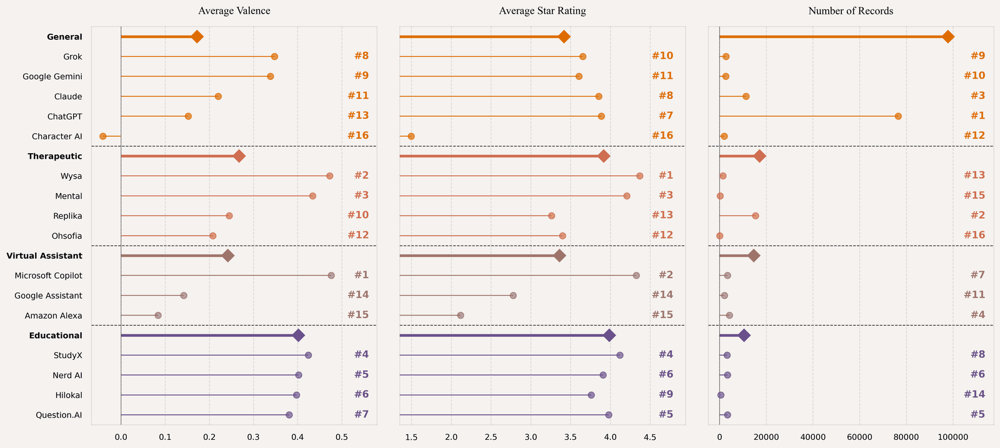

In [3]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_DPI = 300

# ── Averaged valence score across all three models ────────────────────────────

df_emotion["avg_valence"] = df_emotion[
    ["vader_score", "nrc_valence", "emotion_valence"]
].mean(axis=1)

# ── Aggregation ───────────────────────────────────────────────────────────────

app_valence      = df_emotion.groupby(["app_name", "category"])["avg_valence"].mean()
category_valence = df_emotion.groupby("category")["avg_valence"].mean()

app_rating       = df_emotion.groupby(["app_name", "category"])["rating"].mean()
category_rating  = df_emotion.groupby("category")["rating"].mean()

app_records      = df_emotion.groupby(["app_name", "category"]).size()
category_records = df_emotion.groupby("category").size()

# ── App order grouped by category ─────────────────────────────────────────────

CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

# ── Build ordered list of (label, value, type, category) ──────────────────────

plot_labels  = []
plot_valence = []
plot_rating  = []
plot_records = []
plot_types   = []  
plot_cats    = []

for cat in CATEGORY_ORDER:
    plot_labels.append(cat.replace("_", " ").title())
    plot_valence.append(category_valence[cat])
    plot_rating.append(category_rating[cat])
    plot_records.append(category_records[cat])
    plot_types.append("category")
    plot_cats.append(cat)

    apps_in_cat = (
        app_valence.xs(cat, level="category")
        .sort_values(ascending=False)
    )
    for app_name, val in apps_in_cat.items():
        plot_labels.append("  " + app_name)
        plot_valence.append(val)
        plot_rating.append(app_rating.xs(cat, level="category")[app_name])
        plot_records.append(app_records.xs(cat, level="category")[app_name])
        plot_types.append("app")
        plot_cats.append(cat)

# ── Colors ────────────────────────────────────────────────────────────────────

CATEGORY_COLORS = {
    "general":           "#de6e02",
    "therapeutic":       "#cf6e51",
    "virtual_assistant": "#9f756c",
    "educational":       "#6a518c",
}

# ── Helper: draw one lollipop panel ───────────────────────────────────────────

def draw_lollipop_panel(ax, values, fmt, show_ylabels=False, title=""):
    x_min = min(values) - abs(max(values) - min(values)) * 0.05
    x_max = max(values) + abs(max(values) - min(values)) * 0.20

    label_x = x_max * 0.97

    # ── Global app ranking ────────────────────────────────────────────────────
    app_indices = [i for i, t in enumerate(plot_types) if t == "app"]
    app_values  = [(i, values[i]) for i in app_indices]
    
    app_values_sorted = sorted(app_values, key=lambda x: x[1], reverse=True)
    rank_map = {orig_i: rank + 1 for rank, (orig_i, _) in enumerate(app_values_sorted)}

    for i, (value, ptype, cat) in enumerate(
        zip(values, plot_types, plot_cats)
    ):
        color = CATEGORY_COLORS[cat]

        if ptype == "category":
            ax.hlines(i, 0, value, colors=color, linewidth=3, alpha=1)
            ax.plot(value, i, "D", color=color, markersize=10, zorder=3)
            # Brak etykiety dla wierszy kategorii
        else:
            ax.hlines(i, 0, value, colors=color, linewidth=1, alpha=1)
            ax.plot(value, i, "o", color=color, markersize=7, alpha=0.7, zorder=3)
            ax.text(
                label_x, i, f"#{rank_map[i]}",
                va="center", ha="right",
                fontsize=11, color=color, alpha=1, fontweight="bold"
            )

    # Separator lines between categories
    boundary = 0
    for cat in CATEGORY_ORDER:
        n_apps = len(app_valence.xs(cat, level="category"))
        boundary += n_apps + 1
        if boundary < len(plot_labels):
            ax.axhline(
                boundary - 0.5,
                color="#000000", linewidth=0.8,
                linestyle="--", alpha=0.8, zorder=0,
            )

    ax.axvline(0, color="#000000", linewidth=0.7, alpha=0.5)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-0.5, len(plot_labels) - 0.5)
    ax.invert_yaxis()
    ax.tick_params(axis="both", length=0, pad=10, labelsize=9)
    ax.grid(axis="x", alpha=0.4, linestyle="--")
    ax.grid(axis="y", alpha=0.0)
    for spine in ax.spines.values():
        spine.set_alpha(0.1)

    ax.set_yticks(range(len(plot_labels)))
    if show_ylabels:
        ax.set_yticklabels(
            [label.strip() for label in plot_labels],
            fontsize=9,
        )
        for tick, ptype in zip(ax.get_yticklabels(), plot_types):
            if ptype == "category":
                tick.set_fontweight("bold")
    else:
        ax.set_yticklabels([])

    ax.set_title(
        title,
        fontsize=12,
        fontfamily="Times New Roman",
        pad=14,
        loc="center",
    )

# ── Figure: three panels ───────────────────────────────────────────────────────

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 8),
    dpi=FIGURE_DPI,
    gridspec_kw={"wspace": 0.08},
)
fig.patch.set_facecolor("#f5f2ef")
for ax in axes:
    ax.set_facecolor("#f5f2ef")

draw_lollipop_panel(
    axes[0], plot_valence,
    fmt=lambda v: f"{v:.2f}",
    show_ylabels=True,
    title="Average Valence",
)
draw_lollipop_panel(
    axes[1], plot_rating,
    fmt=lambda v: f"{v:.2f}",
    show_ylabels=False,
    title="Average Star Rating",
)
draw_lollipop_panel(
    axes[2], plot_records,
    fmt=lambda v: f"{int(v):,}",
    show_ylabels=False,
    title="Number of Records",
)

# ── Save and display ───────────────────────────────────────────────────────────

plt.savefig(
    "valence_rating_records_dot.png",
    bbox_inches="tight",
    pad_inches=0.5,
    transparent=False,
)
display(fig)
plt.close()

### 6.4. Robustness: Category Differences Within Data Source

Chatbot category is confounded with data source: Educational chatbots are represented only by app reviews, while about 84% of Therapeutic records and 86% of General records come from Reddit (Virtual Assistant: about 53%). Because app reviews and forum posts differ in genre, the pooled tests above may partly measure the source mix. They are therefore repeated on app reviews only (all four categories) and on Reddit only (three categories).

In [ ]:
# Robustness check: do category differences survive when the data source is held constant?
# Educational is app reviews only, while General and Therapeutic are mostly Reddit (see Limitations),
# so the tests from Section 6 are repeated within each source.

import itertools
from scipy.stats import rankdata

CATS    = ["general", "therapeutic", "virtual_assistant", "educational"]
VALENCE = {"VADER": "vader_score", "NRC VAD": "nrc_valence", "GoEmotions": "emotion_valence"}
SUBSETS = {
    "All records":                  df_emotion,
    "App reviews only":             df_emotion[df_emotion["source"].isin(["google_play", "app_store"])],
    "Reddit only (no Educational)": df_emotion[df_emotion["source"] == "reddit"],
}

def dunn_z(data, col):
    """Tie-corrected Dunn z-statistic for every pair of categories (z > 0: first category higher)."""
    values = data[col].values
    n      = len(values)
    _, ties = np.unique(values, return_counts=True)
    var0   = n * (n + 1) / 12 - (ties ** 3 - ties).sum() / (12 * (n - 1))
    g      = (pd.DataFrame({"c": data["category"].values, "r": rankdata(values)})
                .groupby("c")["r"].agg(["mean", "size"]))
    return {(a, b): (g.loc[a, "mean"] - g.loc[b, "mean"])
                    / np.sqrt(var0 * (1 / g.loc[a, "size"] + 1 / g.loc[b, "size"]))
            for a, b in itertools.combinations(g.index, 2)}

# ── Kruskal-Wallis and effect size within each subset ─────────────────────────
rows = []
for subset_name, sub in SUBSETS.items():
    for model, col in VALENCE.items():
        d      = sub[[col, "category"]].dropna()
        groups = [d.loc[d["category"] == c, col].values for c in CATS if (d["category"] == c).any()]
        H, p   = kruskal(*groups)
        n, k   = len(d), len(groups)
        rows.append({"Subset": subset_name, "Model": model, "n": n, "H": round(H, 1),
                     "epsilon_sq": round((H - k + 1) / (n - k), 4), "p": f"{p:.0e}"})

print("KRUSKAL-WALLIS - VALENCE")
print(pd.DataFrame(rows).to_string(index=False))

# ── Pairwise differences, ranked by |z| ───────────────────────────────────────
short = {"general": "Gen", "therapeutic": "Ther", "virtual_assistant": "VA", "educational": "Edu"}
print("\nDUNN POST-HOC (Bonferroni): pairs ranked by |z|, z > 0 = first category more positive, * = not significant at .05")
for subset_name, sub in SUBSETS.items():
    print(f"\n{subset_name}")
    for model, col in VALENCE.items():
        d        = sub[[col, "category"]].dropna()
        p_matrix = sp.posthoc_dunn(d, val_col=col, group_col="category", p_adjust="bonferroni")
        ranked   = sorted(dunn_z(d, col).items(), key=lambda kv: -abs(kv[1]))
        text     = ", ".join(f"{short[a]}-{short[b]} {z:+.1f}{'*' if p_matrix.loc[a, b] >= 0.05 else ''}"
                             for (a, b), z in ranked)
        print(f"  {model:<11} {text}")

KRUSKAL-WALLIS - VALENCE
                      Subset      Model      n      H  epsilon_sq      p
                 All records      VADER 140134 3467.2      0.0247  0e+00
                 All records    NRC VAD 136976 2767.0      0.0202  0e+00
                 All records GoEmotions 140134 4830.2      0.0344  0e+00
            App reviews only      VADER  33473  222.2      0.0065  7e-48
            App reviews only    NRC VAD  32720  202.4      0.0061  1e-43
            App reviews only GoEmotions  33473  748.5      0.0223 6e-162
Reddit only (no Educational)      VADER 106661 1041.9      0.0097 6e-227
Reddit only (no Educational)    NRC VAD 104256  440.3      0.0042  2e-96
Reddit only (no Educational) GoEmotions 106661  817.1      0.0076 4e-178

DUNN POST-HOC (Bonferroni): pairs ranked by |z|, z > 0 = first category more positive, * = not significant at .05

All records
  VADER       Edu-Gen +51.2, Gen-Ther -32.0, Edu-VA +26.0, Gen-VA -21.7, Edu-Ther +21.0, Ther-VA +6.4
  NRC VAD     E

**Result.** Category differences stay statistically significant in every subset (p < .001), but effect sizes drop once the source is held constant: within app reviews ε² falls from .025 to .007 (VADER), from .020 to .006 (NRC VAD) and from .034 to .022 (GoEmotions). The ranking of category pairs is also no longer stable across models: within app reviews Educational ↔ General is the largest gap in NRC VAD and GoEmotions but the smallest in VADER, and Educational ↔ Therapeutic is not significant in NRC VAD and GoEmotions. The one pattern that is consistent across all three models in the Reddit-only data is that General discussions are more negative than Therapeutic and Virtual Assistant ones. The pooled category ranking in Sections 6.1–6.3 should therefore be read as partly reflecting the source mix.

*(The pooled GoEmotions statistic here, H = 4,830, differs marginally from the value in Section 6.1, H = 4,838; the saved CSV appears to differ slightly from the data used there.)*

## 7. Timeline of Affect

To examine **whether user sentiment toward AI chatbots has changed over time**, monthly mean scores were computed for each model and plotted across the full observation window, spanning from November 2022 to the present. 

Valence was tracked using all three models — VADER, NRC VAD, and GoEmotions — while arousal was assessed using NRC VAD and GoEmotions only, as VADER does not produce an arousal dimension. 

Spearman rank correlation was used to test for monotonic trends in each series, providing a non-parametric measure of directional change robust to non-normal score distributions.

### 7.1. Sentiment Timeline

#### 7.1.1. Mean Sentiment 

The valence timeline reveals **a consistent upward trend across all three models** throughout the observation period. 

While short-term fluctuations are visible — particularly in the VADER signal, which is more sensitive to individual word choices — the overall trajectory is positive for VADER, NRC VAD, and GoEmotions alike. NRC VAD produces the smoothest trend line, reflecting its lexicon-based, context-independent nature, whereas GoEmotions shows more variability, likely capturing shifts in the distribution of discrete emotion categories over time.

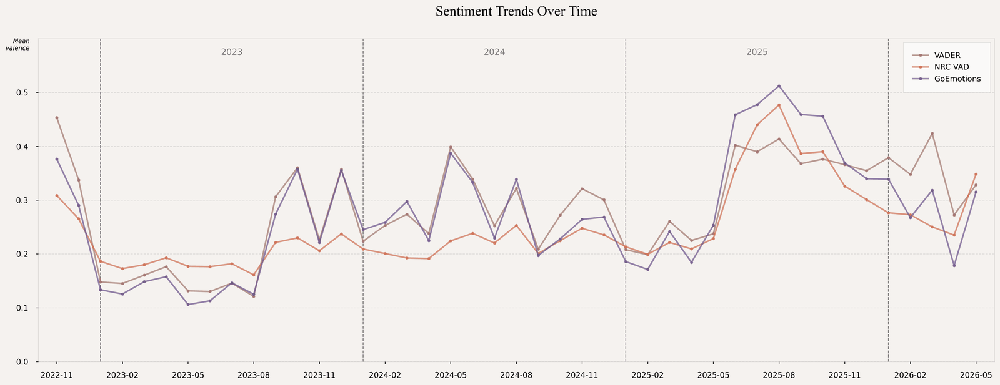

In [12]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 7)
FIGURE_DPI  = 300

# ── Line colors ────────────────────────────────────────────────────────────────

LINE_COLORS = {
    "VADER":             "#9f756c", # heather
    "NRC VAD":           "#cf6e51", # red 
    "GoEmotions":        "#6a518c", # purple
}  

# ── Aggregation ────────────────────────────────────────────────────────────────

monthly_sentiment = (
    df_emotion.groupby("year_month")
    .agg(
        vader_mean              =("vader_score",            "mean"),
        nrc_valence_mean        =("nrc_valence",            "mean"),
        go_emotions_valence_mean=("emotion_valence",        "mean"),
        n                       =("vader_score",            "size")
    )
    .reset_index()
)
monthly_sentiment["year_month"] = monthly_sentiment["year_month"].astype(str)

x_labels = monthly_sentiment["year_month"].tolist()

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
fig.patch.set_facecolor("#f5f2ef")
ax.set_facecolor("#f5f2ef")

# ── Lines ──────────────────────────────────────────────────────────────────────

for col, label in [
    ("vader_mean",               "VADER"),
    ("nrc_valence_mean",         "NRC VAD"),
    ("go_emotions_valence_mean", "GoEmotions"),
]:
    ax.plot(
        x_labels,
        monthly_sentiment[col],
        label=label,
        color=LINE_COLORS[label],
        linewidth=2,
        marker="o",
        alpha=0.7,
        markersize=3
    )

# ── X-axis ticks — every 3 months ─────────────────────────────────────────────

tick_positions = range(0, len(x_labels), 3)
ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    [x_labels[i] for i in tick_positions],
    fontsize=10,
)
ax.tick_params(axis="x", length=3, pad=10)

# ── Y-axis ─────────────────────────────────────────────────────────────────────

ax.tick_params(axis="y", length=3, pad=10, labelsize=10)
ax.set_ylim(0, 0.6)
yticks = ax.get_yticks()
ax.set_yticks(yticks[:-1])
ax.text(
    -0.009, 0.96,
    "Mean\nvalence",
    transform=ax.transAxes,
    fontsize=8,
    fontstyle="italic",
    ha="right",
    va="bottom"
)

# ── Year markers ───────────────────────────────────────────────────────────────

years = sorted(set(x[:4] for x in x_labels))
y_max = ax.get_ylim()[1]

for i, year in enumerate(years):
    first_month = f"{year}-01"
    next_year   = str(int(year) + 1)
    last_month  = f"{next_year}-01"

    if first_month not in x_labels:
        continue

    x_start = x_labels.index(first_month)
    x_end   = x_labels.index(last_month) if last_month in x_labels else len(x_labels) - 1

    if i > 0:
        ax.axvline(x=x_start, color="#000000", linewidth=1,
                   linestyle="--", alpha=0.5, zorder=0)

    if year != years[-1]:
        mid = (x_start + x_end) / 2
        ax.text(mid, y_max * 0.97, str(year),
                fontsize=11, alpha=0.5, va="top", ha="center")

# ── Legend ─────────────────────────────────────────────────────────────────────

legend = ax.legend(
    framealpha=0.6,
    fancybox=False,
    frameon=True,
    fontsize=10,
    borderpad=1.2,
)
legend.get_frame().set_linewidth(0.7)

# ── Grid and spines ────────────────────────────────────────────────────────────

ax.grid(axis="y", alpha=0.4, linestyle="--")
ax.grid(axis="x", alpha=0.0, linestyle="--")
for spine in ax.spines.values():
    spine.set_alpha(0.1)

ax.margins(x=0.02)

# ── Title ──────────────────────────────────────────────────────────────────────

ax.set_title(
    "Sentiment Trends Over Time",
    fontsize=18,
    fontfamily="Times New Roman",
    pad=30,
    loc="center"
)

# ── Save and display ───────────────────────────────────────────────────────────

plt.tight_layout()
plt.savefig("sentiment_timeline.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

#### 7.1.2. Statistical test for sentiment trend in timeline

**All three models reveal a statistically significant positive trend in valence over the observation period.** 

NRC VAD shows the strongest monotonic increase (rho = 0.648, p < .001), followed by VADER (rho = 0.505, p < .001) and GoEmotions (rho = 0.455, p = .002). 

The consistency of this finding across three independent analytical approaches strengthens the conclusion that user sentiment toward AI chatbots has been gradually improving over time — a trend that may **reflect growing user familiarity, improving model quality, or a broader shift in public perception of AI tools.**

In [39]:
# Statistical test for sentiment trend in timeline

print("Statistical test for sentiment trend in timeline")
print("="*50)
print()

monthly_sentiment["year_month"] = range(len(monthly_sentiment))

# VADER
rho_vader, p_vader = spearmanr(
    monthly_sentiment["year_month"],
    monthly_sentiment["vader_mean"]
)

print("VADER")
print("-"*50)
print(f"Spearman rho = {rho_vader:.3f}")
print(f"p-value = {p_vader:.5f}")
print("-"*50)
print()

# NRC 
rho_nrc, p_nrc = spearmanr(
    monthly_sentiment["year_month"],
    monthly_sentiment["nrc_valence_mean"]
)

print("NRC VAD")
print("-"*50)
print(f"Spearman rho = {rho_nrc:.3f}")
print(f"p-value = {p_nrc:.5f}")
print("-"*50)
print()

# GoEmotions
rho_go_emotions, p_go_emotions = spearmanr(
    monthly_sentiment["year_month"],
    monthly_sentiment["go_emotions_valence_mean"]
)

print("GoEmotions")
print("-"*50)
print(f"Spearman rho = {rho_go_emotions:.3f}")
print(f"p-value = {p_go_emotions:.5f}")
print("-"*50)

Statistical test for sentiment trend in timeline

VADER
--------------------------------------------------
Spearman rho = 0.505
p-value = 0.00056
--------------------------------------------------

NRC VAD
--------------------------------------------------
Spearman rho = 0.648
p-value = 0.00000
--------------------------------------------------

GoEmotions
--------------------------------------------------
Spearman rho = 0.455
p-value = 0.00216
--------------------------------------------------


#### 7.1.3. Category Sentiment Trends

Valence trends vary considerably across categories:

- **General**: exhibits the most pronounced fluctuations, including sharp drops visible particularly in the VADER signal — likely driven by the heterogeneous and reactive nature of Reddit discussions, where individual viral threads can temporarily skew monthly averages.
- **Therapeutic**: shows the most stable and consistently positive signal across all three models, suggesting that users of companionship and mental health chatbots maintain a relatively steady emotional tone over time.
- **Educational**: displays a similarly positive but slightly more variable pattern.
- **Virtual Assistant**: shows the widest inter-model divergence, with occasional periods of near-zero or negative valence, possibly reflecting frustration with device integration or functionality issues.

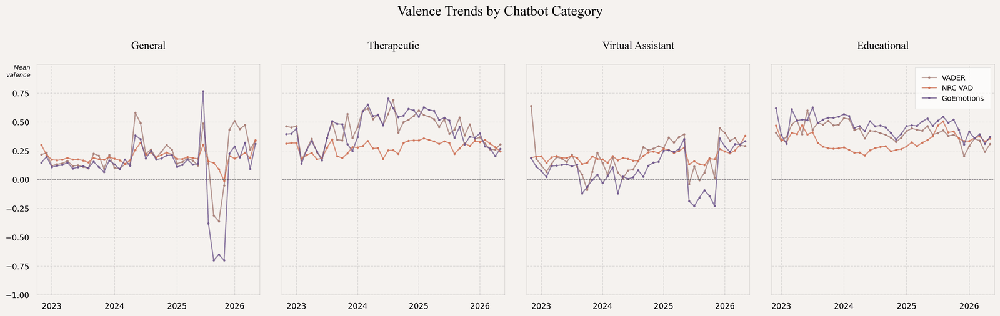

In [15]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 5.5)
FIGURE_DPI  = 300

CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

LINE_COLORS = {
    "VADER":             "#9f756c", # heather
    "NRC VAD":           "#cf6e51", # red 
    "GoEmotions":        "#6a518c", # purple
}

TITLE_STYLE = dict(fontsize=14, fontfamily="Times New Roman", pad=20)

# ── Aggregation ────────────────────────────────────────────────────────────────

monthly = (
    df_emotion.groupby(["year_month", "category"])
    .agg(
        vader_mean      =("vader_score",    "mean"),
        nrc_mean        =("nrc_valence",    "mean"),
        go_emotions_mean=("emotion_valence","mean")
    )
    .reset_index()
)
monthly["year_month"] = monthly["year_month"].astype(str)

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 4, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, sharey=True)
fig.patch.set_facecolor("#f5f2ef")
fig.suptitle(
    "Valence Trends by Chatbot Category",
    fontsize=18, fontfamily="Times New Roman", y=1.02
)

# ── Charts: one per category ───────────────────────────────────────────────────

for i, (ax, category) in enumerate(zip(axes, CATEGORY_ORDER)):
    data     = monthly[monthly["category"] == category].sort_values("year_month")
    x_labels = data["year_month"].tolist()

    for col, label in [
        ("vader_mean",       "VADER"),
        ("nrc_mean",         "NRC VAD"),
        ("go_emotions_mean", "GoEmotions"),
    ]:
        ax.plot(
            x_labels,
            data[col],
            label=label,
            color=LINE_COLORS[label],
            linewidth=1.5,
            marker="o",
            alpha=0.7,
            markersize=2
        )

    # X-axis ticks — years only
    year_ticks   = [x_labels.index(f"{y}-01") for y in years if f"{y}-01" in x_labels]
    year_labels  = [y for y in years if f"{y}-01" in x_labels]
    
    ax.set_xticks(year_ticks)
    ax.set_xticklabels(year_labels, fontsize=10)
    ax.tick_params(axis="x", length=0, pad=10)
            
    # Zero reference line
    ax.axhline(0, color="#000000", linestyle="--", linewidth=0.6, alpha=0.5)
    
    # Y-axis ticks
    ax.set_ylim(-1, 1)
    ax.tick_params(axis="y", length=0, pad=10)
    ax.set_yticks([t for t in ax.get_yticks() if t != 1])

    # Y-axis label — leftmost only
    if i == 0:
        ax.text(
            -0.03, 0.94, "Mean\nvalence",
            transform=ax.transAxes,
            fontsize=8, fontstyle="italic",
            ha="right", va="bottom"
        )

    # Legend — rightmost only
    if i == 3:
        legend = ax.legend(
            framealpha=0.7, fancybox=False,
            frameon=True, fontsize=9, borderpad=1.0
        )
        legend.get_frame().set_linewidth(0.5)
    else:
        ax.get_legend().remove() if ax.get_legend() else None

    ax.set_title(category.replace("_", " ").title(), loc="center", **TITLE_STYLE)
    ax.grid(axis="y", alpha=0.4, linestyle="--")
    ax.grid(axis="x", alpha=0.4, linestyle="--")
    ax.margins(x=0.02)
    ax.set_facecolor("#f5f2ef")
    for spine in ax.spines.values():
        spine.set_alpha(0.1)

# ── Save and display ───────────────────────────────────────────────────────────

plt.tight_layout()
plt.subplots_adjust(wspace=0.10)
plt.savefig("valence_trends_by_category.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

#### 7.1.4. Statistical Test for Category Sentiment Trend

Valence trend results are **heterogeneous across both categories and models**, suggesting that the direction and significance of temporal change depend strongly on the type of chatbot and the analytical method used.

- **General Chatbots**: only VADER detects **a statistically significant positive trend** (rho = +0.318, p = .040), while NRC VAD and GoEmotions show **no significant directional change**. This may reflect VADER's greater sensitivity to the sentiment of informal, reactive language typical of Reddit discussions.

- **Therapeutic Chatbots**: NRC VAD is the only model to detect **a significant positive trend** (rho = +0.361, p = .017), while VADER and GoEmotions produce **non-significant results**. The lexical stability of therapeutic app reviews — where users tend to use consistent emotional vocabulary — may make NRC VAD particularly well-suited to capturing gradual shifts in this context.

- **Virtual Assistants**: show the most consistent picture, with both VADER (rho = +0.308, p = .044) and NRC VAD (rho = +0.328, p = .032) detecting **significant positive trends**, while GoEmotions again remains **non-significant**. This convergence across two independent models strengthens the evidence for **a genuine upward trend** in user sentiment toward virtual assistants over time.

- **Educational Chatbots**: produce the most striking result - both VADER (rho = −0.571, p < .001) and GoEmotions (rho = −0.468, p = .002) detect **significant negative trends**, while NRC VAD shows **no significant change**. This suggests a deterioration in user sentiment toward educational chatbots over the observation period — a finding that stands in contrast to the positive or neutral trends observed in other categories and warrants closer attention.

Overall, GoEmotions proves the least sensitive to temporal trends across categories, detecting significance only in the educational category. VADER and NRC VAD show greater responsiveness, though they do not always agree, reinforcing the conclusion that model choice substantially influences trend detection in longitudinal sentiment analysis.

In [20]:
# ── Aggregation ────────────────────────────────────────────────────────────────

monthly_valence = (
    df_emotion.groupby(["year_month", "category"])
    .agg(
        vader_mean              =("vader_score",     "mean"),
        nrc_valence_mean        =("nrc_valence",     "mean"),
        go_emotions_valence_mean=("emotion_valence", "mean"),
    )
    .reset_index()
)
monthly_valence["year_month"] = monthly_valence["year_month"].astype(str)

VALENCE_COLS = {
    "VADER":      "vader_mean",
    "NRC VAD":    "nrc_valence_mean",
    "GoEmotions": "go_emotions_valence_mean",
}

# ── Spearman Trend Test — Valence ──────────────────────────────────────────────

print("=" * 60)
print("Spearman Trend Test — Valence")
print("=" * 60)

for cat in CATEGORY_ORDER:
    print(f"\n{cat.replace('_', ' ').title()}")
    print("-" * 60)

    data = (
        monthly_valence[monthly_valence["category"] == cat]
        .sort_values("year_month")
        .reset_index(drop=True)
    )
    time_index = np.arange(len(data))

    for model, col in VALENCE_COLS.items():
        series = data[col].dropna()
        if len(series) < 5:
            print(f"  {model:<15} insufficient data")
            continue

        rho, p = spearmanr(time_index[:len(series)], series)
        sig    = "*" if p < 0.05 else "ns"
        print(f"  {model:<15} rho = {rho:+.3f}   p = {p:.5f}   {sig}")


Spearman Trend Test — Valence

General
------------------------------------------------------------
  VADER           rho = +0.318   p = 0.03990   *
  NRC VAD         rho = +0.159   p = 0.31434   ns
  GoEmotions      rho = +0.193   p = 0.22087   ns

Therapeutic
------------------------------------------------------------
  VADER           rho = +0.044   p = 0.77963   ns
  NRC VAD         rho = +0.361   p = 0.01747   *
  GoEmotions      rho = +0.085   p = 0.58844   ns

Virtual Assistant
------------------------------------------------------------
  VADER           rho = +0.308   p = 0.04435   *
  NRC VAD         rho = +0.328   p = 0.03202   *
  GoEmotions      rho = +0.216   p = 0.16338   ns

Educational
------------------------------------------------------------
  VADER           rho = -0.571   p = 0.00008   *
  NRC VAD         rho = +0.132   p = 0.40585   ns
  GoEmotions      rho = -0.468   p = 0.00177   *


**Note on multiple comparisons (added after review).** Section 7.1.4 runs 12 Spearman tests (4 categories × 3 models). Holm-adjusted p-values for the results flagged as significant above:

| Category | Model | ρ | p (uncorrected) | p (Holm, 12 tests) |
|---|---|---|---|---|
| Educational | VADER | −0.571 | < .001 | .001 |
| Educational | GoEmotions | −0.468 | .002 | .020 |
| Therapeutic | NRC VAD | +0.361 | .017 | .175 |
| Virtual Assistant | NRC VAD | +0.328 | .032 | .288 |
| General | VADER | +0.318 | .040 | .319 |
| Virtual Assistant | VADER | +0.308 | .044 | .319 |

Only the two Educational declines survive the correction. The upward trends in the other categories are therefore exploratory and, given that monthly means are autocorrelated and that dataset composition changes over time (see Limitations), should not be read as evidence of a genuine increase in sentiment. Section 7.1.5 additionally shows that the Educational decline is itself model- and app-dependent.

#### 7.1.5. Robustness: Is the Educational Decline Uniform Across Apps?

The Educational category pools four apps that entered the dataset at different times (Hilokal from 2022, Nerd AI and Question.AI from 2023, StudyX mostly from 2024). The pooled decline is therefore checked for each app separately and with app fixed effects.

In [ ]:
# Robustness check: is the Educational valence decline uniform across apps and models?

import statsmodels.formula.api as smf

edu    = df_emotion[df_emotion["category"] == "educational"].copy()
months = pd.PeriodIndex(edu["year_month"].astype(str), freq="M")
edu["t_years"] = ((months.year - 2022) * 12 + (months.month - 12)) / 12      # years since Dec 2022

MODELS = {"VADER": "vader_score", "NRC VAD": "nrc_valence", "GoEmotions": "emotion_valence"}

print("EDUCATIONAL RECORDS BY APP AND YEAR")
print(pd.crosstab(edu["app_name"], edu["year"]).to_string())

print("\nSPEARMAN TREND OF MONTHLY MEAN VALENCE, PER APP (months with >= 20 records)")
for app, sub in edu.groupby("app_name"):
    parts = []
    for model, col in MODELS.items():
        g = sub.groupby("year_month")[col].agg(["mean", "size"])
        g = g[g["size"] >= 20].sort_index()
        if len(g) < 8:
            parts.append(f"{model}: too few months")
        else:
            rho, p = spearmanr(np.arange(len(g)), g["mean"])
            parts.append(f"{model}: rho={rho:+.2f} (p={p:.3f}, {len(g)} months)")
    print(f"  {app:<12} n={len(sub):>5,}  " + " | ".join(parts))

print("\nLINEAR TREND PER YEAR (record level, HC3 robust standard errors)")
for model, col in MODELS.items():
    d      = edu.dropna(subset=[col])
    pooled = smf.ols(f"{col} ~ t_years", data=d).fit(cov_type="HC3")
    fixed  = smf.ols(f"{col} ~ t_years + C(app_name)", data=d).fit(cov_type="HC3")
    print(f"  {model:<11} pooled {pooled.params['t_years']:+.3f} (p={pooled.pvalues['t_years']:.3f})"
          f" | with app fixed effects {fixed.params['t_years']:+.3f} (p={fixed.pvalues['t_years']:.3f})   n={len(d):,}")

EDUCATIONAL RECORDS BY APP AND YEAR
year         2022  2023  2024  2025  2026
app_name                                 
Hilokal        20   270   158    69    22
Nerd AI         0   557  1517  1125   215
Question.AI     0   488  1604   892   446
StudyX          0     3  1095  1974    86

SPEARMAN TREND OF MONTHLY MEAN VALENCE, PER APP (months with >= 20 records)
  Hilokal      n=  539  VADER: rho=+0.35 (p=0.328, 10 months) | NRC VAD: rho=+0.62 (p=0.054, 10 months) | GoEmotions: rho=+0.08 (p=0.829, 10 months)
  Nerd AI      n=3,414  VADER: rho=-0.13 (p=0.481, 33 months) | NRC VAD: rho=+0.79 (p=0.000, 33 months) | GoEmotions: rho=+0.37 (p=0.033, 33 months)
  Question.AI  n=3,430  VADER: rho=-0.71 (p=0.000, 33 months) | NRC VAD: rho=+0.43 (p=0.011, 33 months) | GoEmotions: rho=-0.64 (p=0.000, 33 months)
  StudyX       n=3,158  VADER: rho=+0.70 (p=0.000, 21 months) | NRC VAD: rho=+0.85 (p=0.000, 21 months) | GoEmotions: rho=+0.69 (p=0.000, 21 months)

LINEAR TREND PER YEAR (record level, H

**Result.** The decline is not uniform. Per app, VADER and GoEmotions fall significantly only for Question.AI (ρ = −0.71 and −0.64), while StudyX rises in all three models (ρ ≈ +0.70) and Nerd AI is flat in VADER. NRC VAD shows rising valence in every app (ρ = +0.43 to +0.85; Hilokal not significant). With app fixed effects the record-level slope is negative for VADER (−0.067 per year) and GoEmotions (−0.047) but positive for NRC VAD (+0.065), all p < .001. The Educational "decline" in Section 7.1.4 is therefore model-dependent and driven largely by individual apps and by the changing mix of apps over time. It is best read as an app-specific signal (Question.AI), not as evidence that sentiment toward educational chatbots in general has deteriorated.

### 7.2. Arousal Timeline

#### 7.2.1. Mean Arousal 

The arousal timeline exposes **a clear divergence between the two models**. 

- **NRC VAD arousal remains largely flat throughout the entire period**, with no discernible trend, suggesting that the lexical arousal signal is stable and insensitive to temporal variation in the corpus. 

- **GoEmotions arousal, by contrast, displays a pronounced upward trajectory**, indicating increasing emotional intensity in user-generated content as measured by the transformer-based model. Whether this reflects a genuine shift in user affect or a compositional change in the type of content posted over time remains an open question.

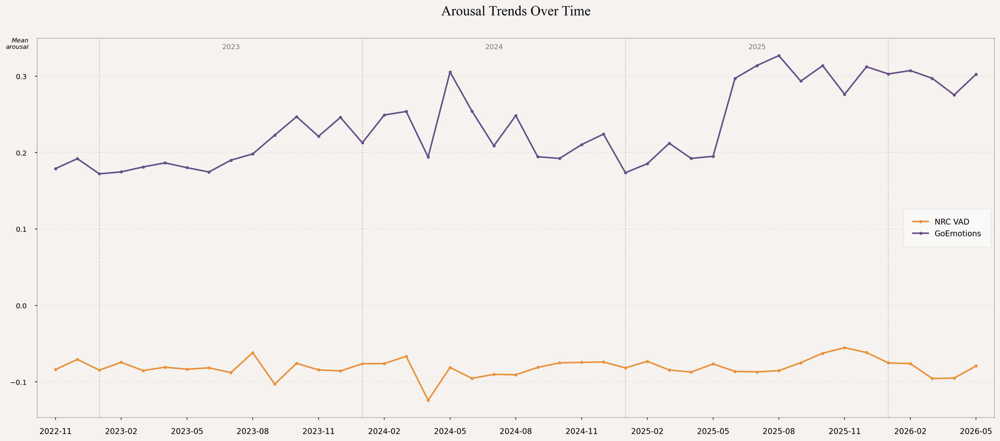

In [17]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 8)
FIGURE_DPI  = 200

# ── Line colors ────────────────────────────────────────────────────────────────

LINE_COLORS = {
    "NRC VAD":    "#ea933c",
    "GoEmotions": "#6a518c",
}

# ── Aggregation ────────────────────────────────────────────────────────────────

monthly_arousal = (
    df_emotion.groupby("year_month")
    .agg(
        nrc_arousal_mean        =("nrc_arousal",     "mean"),
        go_emotions_arousal_mean=("emotion_arousal", "mean"),
        n                       =("nrc_arousal",     "size")
    )
    .reset_index()
)
monthly_arousal["year_month"] = monthly_arousal["year_month"].astype(str)

x_labels = monthly_arousal["year_month"].tolist()

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
fig.patch.set_facecolor("#f5f2ef")
ax.set_facecolor("#f5f2ef")

# ── Lines ──────────────────────────────────────────────────────────────────────

for col, label in [
    ("nrc_arousal_mean",         "NRC VAD"),
    ("go_emotions_arousal_mean", "GoEmotions"),
]:
    ax.plot(
        x_labels,
        monthly_arousal[col],
        label=label,
        color=LINE_COLORS[label],
        linewidth=2,
        marker="o",
        markersize=3
    )

# ── X-axis ticks — every 3 months ─────────────────────────────────────────────

tick_positions = range(0, len(x_labels), 3)
ax.set_xticks(list(tick_positions))
ax.set_xticklabels(
    [x_labels[i] for i in tick_positions],
    fontsize=10,
)
ax.tick_params(axis="x", length=3, pad=10)

# ── Y-axis ─────────────────────────────────────────────────────────────────────

ax.tick_params(axis="y", length=3, pad=10, labelsize=9)
ax.text(
    -0.009, 0.97,
    "Mean\narousal",
    transform=ax.transAxes,
    fontsize=8,
    fontstyle="italic",
    ha="right",
    va="bottom"
)

# ── Year markers ───────────────────────────────────────────────────────────────

years = sorted(set(x[:4] for x in x_labels))
y_max = ax.get_ylim()[1]

for i, year in enumerate(years):
    first_month = f"{year}-01"
    next_year   = str(int(year) + 1)
    last_month  = f"{next_year}-01"

    if first_month not in x_labels:
        continue

    x_start = x_labels.index(first_month)
    x_end   = x_labels.index(last_month) if last_month in x_labels else len(x_labels) - 1

    if i > 0:
        ax.axvline(x=x_start, color="#000000", linewidth=0.8,
                   linestyle="--", alpha=0.2, zorder=0)

    if year != years[-1]:
        mid = (x_start + x_end) / 2
        ax.text(mid, y_max * 0.98, str(year),
                fontsize=9, alpha=0.5, va="top", ha="center")

# ── Legend ─────────────────────────────────────────────────────────────────────

legend = ax.legend(
    framealpha=0.6,
    fancybox=False,
    frameon=True,
    fontsize=10,
    borderpad=1.2,
)
legend.get_frame().set_linewidth(0.5)

# ── Grid and spines ────────────────────────────────────────────────────────────

ax.grid(axis="y", alpha=0.2, linestyle="--")
ax.grid(axis="x", alpha=0.0, linestyle="--")
for spine in ax.spines.values():
    spine.set_alpha(0.3)

ax.margins(x=0.02)

# ── Title ──────────────────────────────────────────────────────────────────────

ax.set_title(
    "Arousal Trends Over Time",
    fontsize=18,
    fontfamily="Times New Roman",
    pad=30,
    loc="center"
)

# ── Save and display ───────────────────────────────────────────────────────────

plt.tight_layout()
plt.savefig("arousal_timeline.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

#### 7.2.2. Statistical test for arousal trend in timeline

**The two models yield strikingly different results.**

NRC VAD shows **no significant temporal trend** in arousal (rho = 0.061, p = .698), suggesting that lexicon-based arousal scores remain essentially flat over time. GoEmotions, by contrast, reveals **a strong and statistically significant positive trend** (rho = 0.705, p < .001), indicating a steady increase in arousal levels as captured by the transformer-based model across the observation period. 

This divergence further reinforces the conclusion that the two models operationalise arousal differently, and that GoEmotions may be more sensitive to shifts in the emotional intensity of user-generated content over time.

In [37]:
# Statistical test for arousal trend in timeline

print(f"\nStatistical test for arousal trend in timeline")
print("="*50)

monthly_arousal["year_month"] = range(len(monthly_arousal))

rho, p = spearmanr(
    monthly_arousal["year_month"],
    monthly_arousal["nrc_arousal_mean"]
)

print("\nNRC VAD")
print("-"*50)
print(f"Spearman rho = {rho:.3f}")
print(f"p-value = {p:.5f}")
print("-"*50)

rho, p = spearmanr(
    monthly_arousal["year_month"],
    monthly_arousal["go_emotions_arousal_mean"]
)

print("\nGoEmotions")
print("-"*50)
print(f"Spearman rho = {rho:.3f}")
print(f"p-value = {p:.5f}")
print("-"*50)


Statistical test for arousal trend in timeline

NRC VAD
--------------------------------------------------
Spearman rho = 0.061
p-value = 0.69755
--------------------------------------------------

GoEmotions
--------------------------------------------------
Spearman rho = 0.705
p-value = 0.00000
--------------------------------------------------


#### 7.2.3. Mean Arousal Values by Category

Arousal trends reveal **a consistent pattern across all four categories**. 

NRC VAD scores remain **flat and slightly negative** throughout the entire observation period, while GoEmotions arousal is **persistently positive and shows a gradual upward trajectory** — most visibly in the general category, where a notable spike is observed around early 2026. The stable NRC VAD signal suggests that the lexical arousal content of reviews has not changed substantially over time. The rising GoEmotions arousal, by contrast, may indicate increasing emotional intensity in user-generated content, though whether this reflects genuine affective change or a shift in writing style and platform composition remains uncertain.

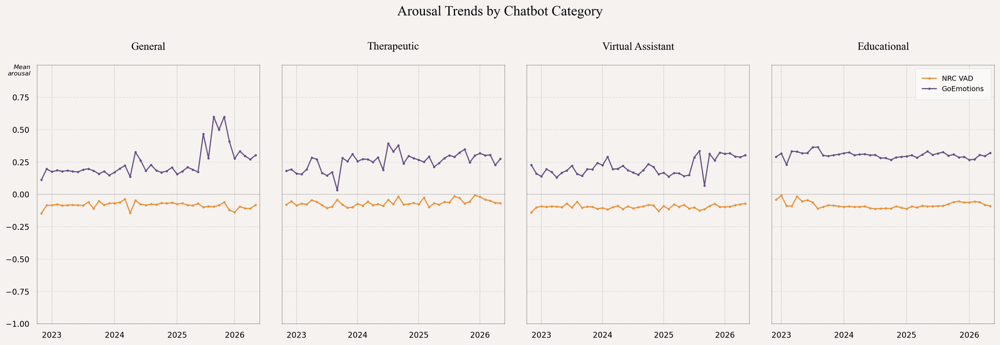

In [19]:
# ── Size and Quality ───────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 6)
FIGURE_DPI  = 200

CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

LINE_COLORS = {
    "NRC VAD":    "#ea933c",
    "GoEmotions": "#6a518c",
}

TITLE_STYLE = dict(fontsize=14, fontfamily="Times New Roman", pad=20)

# ── Aggregation ────────────────────────────────────────────────────────────────

monthly = (
    df_emotion.groupby(["year_month", "category"])
    .agg(
        nrc_mean        =("nrc_arousal",    "mean"),
        go_emotions_mean=("emotion_arousal","mean")
    )
    .reset_index()
)
monthly["year_month"] = monthly["year_month"].astype(str)

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 4, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, sharey=True)
fig.patch.set_facecolor("#f5f2ef")
fig.suptitle(
    "Arousal Trends by Chatbot Category",
    fontsize=18, fontfamily="Times New Roman", y=1.02
)

# ── Charts: one per category ───────────────────────────────────────────────────

for i, (ax, category) in enumerate(zip(axes, CATEGORY_ORDER)):
    data     = monthly[monthly["category"] == category].sort_values("year_month")
    x_labels = data["year_month"].tolist()

    for col, label in [
        ("nrc_mean",         "NRC VAD"),
        ("go_emotions_mean", "GoEmotions"),
    ]:
        ax.plot(
            x_labels,
            data[col],
            label=label,
            color=LINE_COLORS[label],
            linewidth=1.5,
            marker="o",
            markersize=2
        )

    # X-axis ticks — years only
    year_ticks   = [x_labels.index(f"{y}-01") for y in years if f"{y}-01" in x_labels]
    year_labels  = [y for y in years if f"{y}-01" in x_labels]
    
    ax.set_xticks(year_ticks)
    ax.set_xticklabels(year_labels, fontsize=10)
    ax.tick_params(axis="x", length=0, pad=10)
    
    # Vertical year markers
    for j, (x_pos, year) in enumerate(zip(year_ticks, year_labels)):
        
        ax.axvline(x=x_pos, color="#000000", linewidth=0.6,
                       linestyle="--", alpha=0.2, zorder=0)
            
    # Zero reference line
    ax.axhline(0, color="#000000", linewidth=0.6, alpha=0.2)
    
    # Y-axis ticks
    ax.set_ylim(-1, 1)
    ax.tick_params(axis="y", length=0, pad=10)
    ax.set_yticks([t for t in ax.get_yticks() if t != 1])

    # Y-axis label — leftmost only
    if i == 0:
        ax.text(
            -0.03, 0.955, "Mean\narousal",
            transform=ax.transAxes,
            fontsize=8, fontstyle="italic",
            ha="right", va="bottom"
        )

    # Legend — rightmost only
    if i == 3:
        legend = ax.legend(
            framealpha=0.6, fancybox=False,
            frameon=True, fontsize=9, borderpad=1.0
        )
        legend.get_frame().set_linewidth(0.5)
    else:
        ax.get_legend().remove() if ax.get_legend() else None

    ax.set_title(category.replace("_", " ").title(), loc="center", **TITLE_STYLE)
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    ax.grid(axis="x", alpha=0.0)
    ax.margins(x=0.02)
    ax.set_facecolor("#f5f2ef")
    for spine in ax.spines.values():
        spine.set_alpha(0.3)

# ── Save and display ───────────────────────────────────────────────────────────

plt.tight_layout()
plt.subplots_adjust(wspace=0.10)
plt.savefig("arousal_trends_by_category.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

#### 7.2.4. Statistical Test for Category Trends

Arousal trend results reveal **a consistent divergence between NRC VAD and GoEmotions across all four categories**, reinforcing the earlier finding that the two models operationalise arousal in fundamentally different ways.

GoEmotions detects **significant positive arousal trends in three out of four categories** — general (rho = +0.621, p < .001), therapeutic (rho = +0.532, p < .001), and virtual assistant (rho = +0.416, p = .006) — suggesting a broad increase in emotional intensity across most chatbot types over time. The educational category is the only exception, where GoEmotions shows **a non-significant negative trend** (rho = −0.285, p = .067), mirroring the negative valence trend observed for this category and pointing to a broader deterioration in the emotional quality of educational chatbot reviews.

NRC VAD, by contrast, detects **significance only in the therapeutic category** (rho = +0.446, p = .003), while remaining flat and **non-significant elsewhere**. This pattern is consistent with the lexicon-based model's general insensitivity to temporal variation, as static word-level arousal scores are unlikely to capture shifts in emotional intensity that emerge from changes in writing style, discourse context, or platform composition over time.

**The therapeutic category stands out as the only one where both models agree on a significant positive arousal trend**, lending stronger support to the conclusion that users of companionship and mental health chatbots have become increasingly emotionally engaged over the observation period. Whether this reflects growing attachment, heightened expectations, or broader cultural normalisation of AI-based emotional support remains an open question beyond the scope of this analysis.

In [21]:
# ── Aggregation ────────────────────────────────────────────────────────────────

monthly_arousal = (
    df_emotion.groupby(["year_month", "category"])
    .agg(
        nrc_arousal_mean        =("nrc_arousal",     "mean"),
        go_emotions_arousal_mean=("emotion_arousal", "mean"),
    )
    .reset_index()
)
monthly_arousal["year_month"] = monthly_arousal["year_month"].astype(str)

AROUSAL_COLS = {
    "NRC VAD":    "nrc_arousal_mean",
    "GoEmotions": "go_emotions_arousal_mean",
}

# ── Spearman Trend Test — Arousal ──────────────────────────────────────────────

print("=" * 60)
print("Spearman Trend Test — Arousal")
print("=" * 60)

for cat in CATEGORY_ORDER:
    print(f"\n{cat.replace('_', ' ').title()}")
    print("-" * 60)

    data = (
        monthly_arousal[monthly_arousal["category"] == cat]
        .sort_values("year_month")
        .reset_index(drop=True)
    )
    time_index = np.arange(len(data))

    for model, col in AROUSAL_COLS.items():
        series = data[col].dropna()
        if len(series) < 5:
            print(f"  {model:<15} insufficient data")
            continue

        rho, p = spearmanr(time_index[:len(series)], series)
        sig    = "*" if p < 0.05 else "ns"
        print(f"  {model:<15} rho = {rho:+.3f}   p = {p:.5f}   {sig}")

Spearman Trend Test — Arousal

General
------------------------------------------------------------
  NRC VAD         rho = -0.162   p = 0.30592   ns
  GoEmotions      rho = +0.621   p = 0.00001   *

Therapeutic
------------------------------------------------------------
  NRC VAD         rho = +0.446   p = 0.00270   *
  GoEmotions      rho = +0.532   p = 0.00024   *

Virtual Assistant
------------------------------------------------------------
  NRC VAD         rho = +0.211   p = 0.17416   ns
  GoEmotions      rho = +0.416   p = 0.00556   *

Educational
------------------------------------------------------------
  NRC VAD         rho = -0.011   p = 0.94681   ns
  GoEmotions      rho = -0.285   p = 0.06719   ns


## 8. Russell Circumplex Model of Affect

*"The circumplex model of affect proposes that all affective states arise from cognitive interpretations of core neural sensations that are the product of **two independent neurophysiological systems**. This model stands in contrast to theories of basic emotions, which posit that a discrete and independent neural system subserves every emotion. (...) The circumplex model of affect is more consistent with many recent findings from behavioural, cognitive neuroscience, neuroimaging, and developmental studies of affect."* - Posner J, Russell JA, Peterson BS

References:
- Russell, J. A. (1980). A circumplex model of affect. Journal of Personality and Social Psychology, 39(6), 1161–1178.
- Warriner, A. B., Kuperman, V., & Brysbaert, M. (2013). Norms of valence, arousal, and dominance for 13,915 English lemmas. Behavior Research Methods, 45(4), 1191–1207.
- Posner J, Russell JA, Peterson BS. The circumplex model of affect: an integrative approach to affective neuroscience, cognitive development, and psychopathology. Dev Psychopathol. 2005 Summer;17(3):715-34. 

### 8.1. The Circumplex Model of Affect Layout

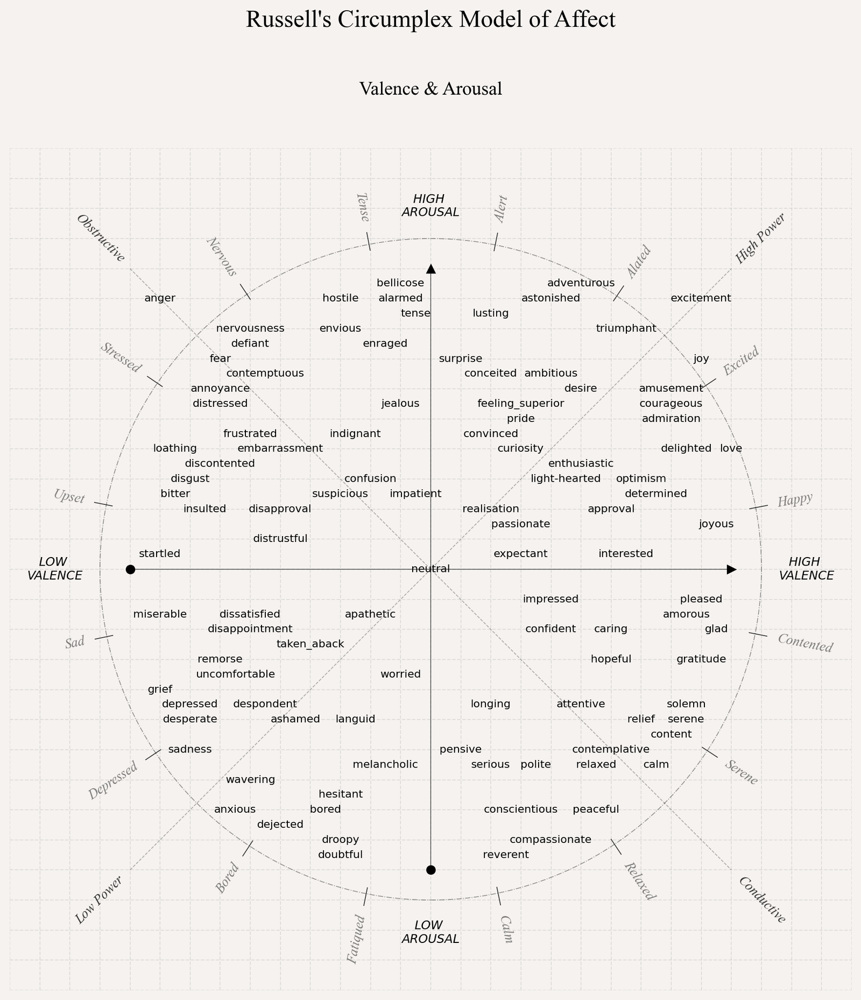

In [20]:
# ── Settings ───────────────────────────────────────────────────────────────────

FIGURE_SIZE  = (18, 20)
FIGURE_DPI   = 200
CATEGORIES   = ["general", "virtual_assistant", "therapeutic", "educational"]
N_DECILES    = 20000

# ── Emotion positions on grid ──────────────────────────────────────────────────

EMOTION_POSITIONS = {

    # ── Quadrant I: Pleasant / Activated ──────────────────────────────────────
    
    "triumphant":      ( 0.65,  0.80),
    "courageous":      ( 0.80,  0.55),
    "ambitious":       ( 0.40,  0.65),
    "feeling_superior":( 0.30,  0.55),
    "light-hearted":   ( 0.45,  0.30),
    "enthusiastic":    ( 0.50,  0.35),
    "delighted":       ( 0.85,  0.40),
    "determined":      ( 0.75,  0.25),
    "passionate":      ( 0.30,  0.15),
    "joyous":          ( 0.95,  0.15),
    "interested":      ( 0.65,  0.05),
    "expectant":       ( 0.30,  0.05),
    "convinced":       ( 0.20,  0.45),
    "lusting":         ( 0.20,  0.85),
    "astonished":      ( 0.40,  0.90),
    "adventurous":     ( 0.50,  0.95),
    "conceited":       ( 0.20,  0.65),

    # ── Quadrant II: Unpleasant / Activated ────────────────────────────────────
    
    "bellicose":       (-0.10,  0.95),
    "hostile":         (-0.30,  0.90),
    "alarmed":         (-0.10,  0.90),
    "tense":           (-0.05,  0.85),
    "enraged":         (-0.15,  0.75),
    "envious":         (-0.30,  0.80),
    "indignant":       (-0.25,  0.45),
    "jealous":         (-0.10,  0.55),
    "impatient":       (-0.05,  0.25),
    "contemptuous":    (-0.55,  0.65),
    "defiant":         (-0.60,  0.75),
    "loathing":        (-0.85,  0.40),
    "suspicious":      (-0.30,  0.25),
    "distressed":      (-0.70,  0.55),
    "frustrated":      (-0.60,  0.45),
    "discontented":    (-0.70,  0.35),
    "bitter":          (-0.85,  0.25),
    "insulted":        (-0.75,  0.20),
    "distrustful":     (-0.50,  0.10),
    "startled":        (-0.90,  0.05),

     # ── Quadrant III: Unpleasant / Deactivated ─────────────────────────────────
    
    "miserable":       (-0.90, -0.15),
    "dissatisfied":    (-0.60, -0.15),
    "uncomfortable":   (-0.65, -0.35),
    "taken_aback":     (-0.40, -0.25),
    "despondent":      (-0.55, -0.45),
    "depressed":       (-0.80, -0.45),
    "desperate":       (-0.80, -0.50),
    "ashamed":         (-0.45, -0.50),
    "apathetic":       (-0.20, -0.15),
    "worried":         (-0.10, -0.35),
    "languid":         (-0.25, -0.50),
    "melancholic":     (-0.15, -0.65),
    "hesitant":        (-0.30, -0.75),
    "anxious":         (-0.65, -0.80),
    "wavering":        (-0.60, -0.70),
    "dejected":        (-0.50, -0.85),
    "droopy":          (-0.30, -0.90),
    "doubtful":        (-0.30, -0.95),
    "bored":           (-0.35, -0.80),
    
    # ── Quadrant IV: Pleasant / Deactivated ────────────────────────────────────
    
    "impressed":       ( 0.40, -0.10),
    "amorous":         ( 0.85, -0.15),
    "pensive":         ( 0.10, -0.60),
    "serious":         ( 0.20, -0.65),
    "confident":       ( 0.40, -0.20),
    "hopeful":         ( 0.60, -0.30),
    "content":         ( 0.80, -0.55),
    "calm":            ( 0.75, -0.65),
    "relaxed":         ( 0.55, -0.65),
    "solemn":          ( 0.85, -0.45),
    "attentive":       ( 0.50, -0.45),
    "polite":          ( 0.35, -0.65),
    "longing":         ( 0.20, -0.45),
    "contemplative":   ( 0.60, -0.60),
    "conscientious":   ( 0.30, -0.80),
    "peaceful":        ( 0.55, -0.80),
    "compassionate":   ( 0.40, -0.90),
    "reverent":        ( 0.25, -0.95),
    "serene":          ( 0.85, -0.50),
    "pleased":         ( 0.90, -0.10),
    "glad":            ( 0.95, -0.20),

    # ── Categories defined in GoEmotions set ────────────────────────────────────

    "excitement":      ( 0.9,  0.9),
    "joy":             ( 0.9,  0.7),
    "amusement":       ( 0.8,  0.6),
    "admiration":      ( 0.8,  0.5),
    "approval":        ( 0.6,  0.2),
    "pride":           ( 0.3,  0.5),
    "love":            ( 1.0,  0.4),
    "desire":          ( 0.5,  0.6),
    "optimism":        ( 0.7,  0.3),
    "caring":          ( 0.6, -0.2),
    "gratitude":       ( 0.9, -0.3),
    "relief":          ( 0.7, -0.5),
    "curiosity":       ( 0.3,  0.4),
    "realisation":     ( 0.2,  0.2),
    "surprise":        ( 0.1,  0.7),
    "neutral":         ( 0.0,  0.0),
    "confusion":       (-0.2,  0.3),
    "disapproval":     (-0.5,  0.2),
    "annoyance":       (-0.7,  0.6),
    "anger":           (-0.9,  0.9),
    "fear":            (-0.7,  0.7),
    "nervousness":     (-0.6,  0.8),
    "disgust":         (-0.8,  0.3),
    "embarrassment":   (-0.5,  0.4),
    "disappointment":  (-0.6, -0.2),
    "remorse":         (-0.7, -0.3),
    "sadness":         (-0.8, -0.6),
    "grief":           (-0.9, -0.4),
}

# ── Radial emotions ────────────────────────────────────────────────────────────

OFFSET = -11.25
RADIAL_EMOTIONS = {
    "Alert":      (np.cos(np.radians( 90  + OFFSET)), np.sin(np.radians( 90  + OFFSET))),
    "Alated":     (np.cos(np.radians( 67  + OFFSET)), np.sin(np.radians( 67  + OFFSET))),
    "Excited":    (np.cos(np.radians( 45  + OFFSET)), np.sin(np.radians( 45  + OFFSET))),
    "Happy":      (np.cos(np.radians( 22  + OFFSET)), np.sin(np.radians( 22  + OFFSET))),
    "Contented":  (np.cos(np.radians(  0  + OFFSET)), np.sin(np.radians(  0  + OFFSET))),
    "Serene":     (np.cos(np.radians(-22  + OFFSET)), np.sin(np.radians(-22  + OFFSET))),
    "Relaxed":    (np.cos(np.radians(-45  + OFFSET)), np.sin(np.radians(-45  + OFFSET))),
    "Calm":       (np.cos(np.radians(-67  + OFFSET)), np.sin(np.radians(-67  + OFFSET))),
    "Fatiqued":   (np.cos(np.radians(-90  + OFFSET)), np.sin(np.radians(-90  + OFFSET))),
    "Bored":      (np.cos(np.radians(-112 + OFFSET)), np.sin(np.radians(-112 + OFFSET))),
    "Depressed":  (np.cos(np.radians(-135 + OFFSET)), np.sin(np.radians(-135 + OFFSET))),
    "Sad":        (np.cos(np.radians(-157 + OFFSET)), np.sin(np.radians(-157 + OFFSET))),
    "Upset":      (np.cos(np.radians( 180 + OFFSET)), np.sin(np.radians( 180 + OFFSET))),
    "Stressed":   (np.cos(np.radians( 157 + OFFSET)), np.sin(np.radians( 157 + OFFSET))),
    "Nervous":    (np.cos(np.radians( 135 + OFFSET)), np.sin(np.radians( 135 + OFFSET))),
    "Tense":      (np.cos(np.radians( 112 + OFFSET)), np.sin(np.radians( 112 + OFFSET))),
}

# ── Colormap ───────────────────────────────────────────────────────────────────

cmap = mcolors.LinearSegmentedColormap.from_list(
    "chromatlas", [
        "#6a518c", # purple
        "#9f756c", # heather
        "#cfad96", # neutral beige
        "#cf6e51", # red
        "#de6e02", # orange 
    ])
norm = mcolors.Normalize(vmin=-1, vmax=1)

LIGHTNESS_MAX = 2.0

def adjust_lightness(hex_color, factor):
    hex_color = hex_color.lstrip("#")
    r, g, b   = [int(hex_color[i:i+2], 16) / 255 for i in (0, 2, 4)]
    h, l, s   = colorsys.rgb_to_hls(r, g, b)
    l         = max(0, min(1, l * factor))
    r, g, b   = colorsys.hls_to_rgb(h, l, s)
    return (r, g, b)

def build_colors(x_vals, y_vals):
    colors = []
    for v, a in zip(x_vals, y_vals):
        base_color = mcolors.to_hex(cmap(norm(v)))
        if a < 0:
            lightness_factor = 1.0 + (LIGHTNESS_MAX - 1.0) * abs(a)
            color = adjust_lightness(base_color, lightness_factor)
        else:
            color = mcolors.to_rgb(base_color)
        colors.append(color)
    return colors

def draw_base(ax):
    """Draw shared background elements — grid, crosshair, circle, labels."""

    # Grid
    ax.set_xticks(np.arange(-1.4, 1.5, 0.1))
    ax.set_yticks(np.arange(-1.4, 1.5, 0.1))
    ax.grid(axis="both", alpha=0.3, linestyle="--", linewidth=0.7, zorder=0)

    # Crosshair
    ax.plot([-1.0, 1.0], [0, 0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)
    ax.plot([0, 0], [-1.0, 1.0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)

    # Diagonal lines
    ax.plot([-1.0, 1.0], [-1.0,  1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)
    ax.plot([-1.0, 1.0], [ 1.0, -1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)

    # Emotion names on grid
    for emotion, (ex, ey) in EMOTION_POSITIONS.items():
        ax.text(ex, ey, emotion, ha="center", va="center",
                fontsize=8, color="#000000", alpha=1, zorder=4)

    # Ticks and radial labels
    TICK_INNER   = 1.08
    TICK_OUTER   = 1.14
    LABEL_RADIUS = 1.175

    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        ax.plot([lx * TICK_INNER, lx * TICK_OUTER],
                [ly * TICK_INNER, ly * TICK_OUTER],
                color="#000000", alpha=0.8, linewidth=0.6, zorder=3)
        angle_deg = np.degrees(np.arctan2(ly, lx))
        if -90 <= angle_deg <= 90:
            rotation, ha = angle_deg, "left"
        else:
            rotation, ha = angle_deg + 180, "right"
        ax.text(lx * LABEL_RADIUS, ly * LABEL_RADIUS, label,
                ha=ha, va="center", rotation=rotation,
                rotation_mode="anchor", fontsize=10,
                color="#000000", alpha=0.5,
                fontfamily="Times New Roman", fontstyle="italic", zorder=3)

    # Circle
    circle = Circle((0, 0), radius=1.1, fill=False, linestyle="-.",
                    edgecolor="#000000", alpha=0.4, linewidth=0.6, zorder=3)
    ax.add_patch(circle)

    # Quadrant labels
    diag_kw = dict(fontsize=10, color="#000000", alpha=0.8,
                   fontstyle="italic", fontfamily="Times New Roman")
    ax.text(-1.1,  1.1, "Obstructive", ha="center", va="center", rotation=-45, zorder=4, **diag_kw)
    ax.text( 1.1,  1.1, "High Power",  ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text(-1.1, -1.1, "Low Power",   ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text( 1.1, -1.1, "Conductive",  ha="center", va="center", rotation=-45, zorder=4, **diag_kw)

    lkw = dict(fontsize=9, color="#000000", alpha=1, fontstyle="italic")
    ax.text( 0,     1.25, "HIGH \nAROUSAL", ha="center", va="top",    zorder=4, **lkw)
    ax.text( 0,    -1.25, "LOW \nAROUSAL",  ha="center", va="bottom", zorder=4, **lkw)
    ax.text(-1.25,  0,    "LOW \nVALENCE",  ha="center", va="center", zorder=4, **lkw)
    ax.text( 1.25,  0,    "HIGH \nVALENCE", ha="center", va="center", zorder=4, **lkw)

    # Axis endpoint markers
    MARKER_SIZE = 6
    ax.plot( 0, -1, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot(-1,  0, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 0,  1, "^", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 1,  0, ">", color="#000000", markersize=MARKER_SIZE, zorder=5)

    # Frame
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_alpha(0.0)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_facecolor("#f5f2ef")

    # ── The figure ─────────────────────────────────────────────────────────────────

for model_name, filename, title in [
    (
        "Russell's Circumplex Model of AffectS",
        "russell_base.png",
        "Russell's Circumplex Model of Affect"
    )
]:
    fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=FIGURE_DPI)
    fig.patch.set_facecolor("#f5f2ef")
    
    # ── Draw base ──────────────────────────────────────────────────────────────────
    
    draw_base(ax)
    
    # ── Titles ────────────────────────────────────────────────────────────────────
        
    ax.set_title(
        "Valence & Arousal",
        fontsize=14, fontfamily="Times New Roman", pad=40, loc="center"
        )
        
    fig.suptitle(
        "Russell's Circumplex Model of Affect",
        fontsize=18, fontfamily="Times New Roman", y=1.02
        )

plt.tight_layout()
plt.savefig("russell_base.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

### 8.2. Affect Mapped per Category

#### 8.2.1. NRC VAD Results

The NRC VAD Lexicon v2.1 used in this project provides valence, arousal, and dominance scores already normalised to the [−1, +1] range, where −1 represents the most negative/low/submissive pole and +1 the most positive/high/dominant pole. No additional rescaling was applied.

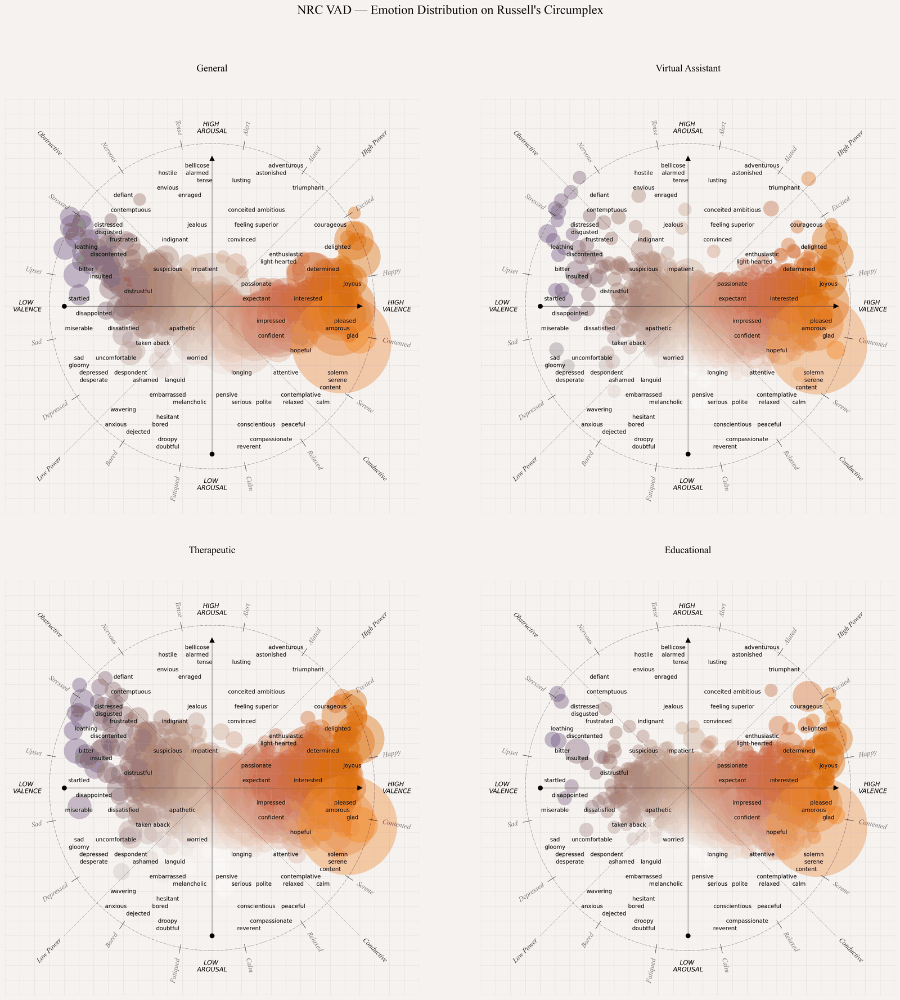

In [21]:
# ── Settings ───────────────────────────────────────────────────────────────────

FIGURE_SIZE  = (18, 20)
FIGURE_DPI   = 300
CATEGORIES   = ["general", "virtual_assistant", "therapeutic", "educational"]
N_DECILES    = 8000

# ── Emotion positions on grid ──────────────────────────────────────────────────

EMOTION_POSITIONS = {
    "triumphant":      ( 0.65,  0.80),
    "courageous":      ( 0.80,  0.55),
    "ambitious":       ( 0.40,  0.65),
    "feeling superior":( 0.30,  0.55),
    "light-hearted":   ( 0.45,  0.30),
    "enthusiastic":    ( 0.50,  0.35),
    "delighted":       ( 0.85,  0.40),
    "determined":      ( 0.75,  0.25),
    "passionate":      ( 0.30,  0.15),
    "joyous":          ( 0.95,  0.15),
    "interested":      ( 0.65,  0.05),
    "expectant":       ( 0.30,  0.05),
    "convinced":       ( 0.20,  0.45),
    "lusting":         ( 0.20,  0.85),
    "astonished":      ( 0.40,  0.90),
    "adventurous":     ( 0.50,  0.95),
    "conceited":       ( 0.20,  0.65),
    "bellicose":       (-0.10,  0.95),
    "hostile":         (-0.30,  0.90),
    "alarmed":         (-0.10,  0.90),
    "tense":           (-0.05,  0.85),
    "enraged":         (-0.15,  0.75),
    "envious":         (-0.30,  0.80),
    "indignant":       (-0.25,  0.45),
    "jealous":         (-0.10,  0.55),
    "impatient":       (-0.05,  0.25),
    "contemptuous":    (-0.55,  0.65),
    "defiant":         (-0.60,  0.75),
    "disgusted":       (-0.70,  0.50),
    "loathing":        (-0.85,  0.40),
    "suspicious":      (-0.30,  0.25),
    "distressed":      (-0.70,  0.55),
    "frustrated":      (-0.60,  0.45),
    "discontented":    (-0.70,  0.35),
    "bitter":          (-0.85,  0.25),
    "insulted":        (-0.75,  0.20),
    "distrustful":     (-0.50,  0.10),
    "startled":        (-0.90,  0.05),
    "miserable":       (-0.90, -0.15),
    "gloomy":          (-0.90, -0.40),
    "sad":             (-0.90, -0.35),
    "dissatisfied":    (-0.60, -0.15),
    "uncomfortable":   (-0.65, -0.35),
    "taken aback":     (-0.40, -0.25),
    "despondent":      (-0.55, -0.45),
    "depressed":       (-0.80, -0.45),
    "desperate":       (-0.80, -0.50),
    "ashamed":         (-0.45, -0.50),
    "embarrassed":     (-0.30, -0.60),
    "disappointed":    (-0.80, -0.05),
    "apathetic":       (-0.20, -0.15),
    "worried":         (-0.10, -0.35),
    "languid":         (-0.25, -0.50),
    "melancholic":     (-0.15, -0.65),
    "hesitant":        (-0.30, -0.75),
    "anxious":         (-0.65, -0.80),
    "wavering":        (-0.60, -0.70),
    "dejected":        (-0.50, -0.85),
    "droopy":          (-0.30, -0.90),
    "doubtful":        (-0.30, -0.95),
    "bored":           (-0.35, -0.80),
    "impressed":       ( 0.40, -0.10),
    "amorous":         ( 0.85, -0.15),
    "pensive":         ( 0.10, -0.60),
    "serious":         ( 0.20, -0.65),
    "confident":       ( 0.40, -0.20),
    "hopeful":         ( 0.60, -0.30),
    "content":         ( 0.80, -0.55),
    "calm":            ( 0.75, -0.65),
    "relaxed":         ( 0.55, -0.65),
    "solemn":          ( 0.85, -0.45),
    "attentive":       ( 0.50, -0.45),
    "polite":          ( 0.35, -0.65),
    "longing":         ( 0.20, -0.45),
    "contemplative":   ( 0.60, -0.60),
    "conscientious":   ( 0.30, -0.80),
    "peaceful":        ( 0.55, -0.80),
    "compassionate":   ( 0.40, -0.90),
    "reverent":        ( 0.25, -0.95),
    "serene":          ( 0.85, -0.50),
    "pleased":         ( 0.90, -0.10),
    "glad":            ( 0.95, -0.20),
}

# ── Radial emotions ────────────────────────────────────────────────────────────

OFFSET = -11.25
RADIAL_EMOTIONS = {
    "Alert":      (np.cos(np.radians( 90  + OFFSET)), np.sin(np.radians( 90  + OFFSET))),
    "Alated":     (np.cos(np.radians( 67  + OFFSET)), np.sin(np.radians( 67  + OFFSET))),
    "Excited":    (np.cos(np.radians( 45  + OFFSET)), np.sin(np.radians( 45  + OFFSET))),
    "Happy":      (np.cos(np.radians( 22  + OFFSET)), np.sin(np.radians( 22  + OFFSET))),
    "Contented":  (np.cos(np.radians(  0  + OFFSET)), np.sin(np.radians(  0  + OFFSET))),
    "Serene":     (np.cos(np.radians(-22  + OFFSET)), np.sin(np.radians(-22  + OFFSET))),
    "Relaxed":    (np.cos(np.radians(-45  + OFFSET)), np.sin(np.radians(-45  + OFFSET))),
    "Calm":       (np.cos(np.radians(-67  + OFFSET)), np.sin(np.radians(-67  + OFFSET))),
    "Fatiqued":   (np.cos(np.radians(-90  + OFFSET)), np.sin(np.radians(-90  + OFFSET))),
    "Bored":      (np.cos(np.radians(-112 + OFFSET)), np.sin(np.radians(-112 + OFFSET))),
    "Depressed":  (np.cos(np.radians(-135 + OFFSET)), np.sin(np.radians(-135 + OFFSET))),
    "Sad":        (np.cos(np.radians(-157 + OFFSET)), np.sin(np.radians(-157 + OFFSET))),
    "Upset":      (np.cos(np.radians( 180 + OFFSET)), np.sin(np.radians( 180 + OFFSET))),
    "Stressed":   (np.cos(np.radians( 157 + OFFSET)), np.sin(np.radians( 157 + OFFSET))),
    "Nervous":    (np.cos(np.radians( 135 + OFFSET)), np.sin(np.radians( 135 + OFFSET))),
    "Tense":      (np.cos(np.radians( 112 + OFFSET)), np.sin(np.radians( 112 + OFFSET))),
}

# ── Colormap ───────────────────────────────────────────────────────────────────

cmap = mcolors.LinearSegmentedColormap.from_list(
    "chromatlas", [
        "#6a518c",
        "#9f756c",
        "#cfad96",
        "#cf6e51",
        "#de6e02",
    ])
norm = mcolors.Normalize(vmin=-1, vmax=1)

LIGHTNESS_MAX = 2.0

def adjust_lightness(hex_color, factor):
    hex_color = hex_color.lstrip("#")
    r, g, b   = [int(hex_color[i:i+2], 16) / 255 for i in (0, 2, 4)]
    h, l, s   = colorsys.rgb_to_hls(r, g, b)
    l         = max(0, min(1, l * factor))
    r, g, b   = colorsys.hls_to_rgb(h, l, s)
    return (r, g, b)

def build_colors(x_vals, y_vals):
    colors = []
    for v, a in zip(x_vals, y_vals):
        base_color = mcolors.to_hex(cmap(norm(v)))
        if a < 0:
            lightness_factor = 1.0 + (LIGHTNESS_MAX - 1.0) * abs(a)
            color = adjust_lightness(base_color, lightness_factor)
        else:
            color = mcolors.to_rgb(base_color)
        colors.append(color)
    return colors

def build_decile_bubbles(valence_series, arousal_series):
    """Group records into N_DECILES bins by valence, return bubble data."""
    import pandas as pd
    df_temp = pd.DataFrame({
        "valence": valence_series,
        "arousal": arousal_series
    }).dropna()

    df_temp["decile"] = pd.qcut(df_temp["valence"], N_DECILES, labels=False, duplicates="drop")

    agg = (
        df_temp.groupby("decile")
        .agg(
            mean_valence=("valence", "mean"),
            mean_arousal=("arousal", "mean"),
            count       =("valence", "size"),
        )
        .reset_index()
    )
    return agg

def draw_base(ax):
    """Draw shared background elements — grid, crosshair, circle, labels."""

    # Grid
    ax.set_xticks(np.arange(-1.4, 1.5, 0.1))
    ax.set_yticks(np.arange(-1.4, 1.5, 0.1))
    ax.grid(axis="both", alpha=0.3, linestyle="--", linewidth=0.7, zorder=0)

    # Crosshair
    ax.plot([-1.0, 1.0], [0, 0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)
    ax.plot([0, 0], [-1.0, 1.0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)

    # Diagonal lines
    ax.plot([-1.0, 1.0], [-1.0,  1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)
    ax.plot([-1.0, 1.0], [ 1.0, -1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)

    # Emotion names on grid
    for emotion, (ex, ey) in EMOTION_POSITIONS.items():
        ax.text(ex, ey, emotion, ha="center", va="center",
                fontsize=8, color="#000000", alpha=1, zorder=4)

    # Ticks and radial labels
    TICK_INNER   = 1.08
    TICK_OUTER   = 1.14
    LABEL_RADIUS = 1.175

    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        ax.plot([lx * TICK_INNER, lx * TICK_OUTER],
                [ly * TICK_INNER, ly * TICK_OUTER],
                color="#000000", alpha=0.8, linewidth=0.6, zorder=3)
        angle_deg = np.degrees(np.arctan2(ly, lx))
        if -90 <= angle_deg <= 90:
            rotation, ha = angle_deg, "left"
        else:
            rotation, ha = angle_deg + 180, "right"
        ax.text(lx * LABEL_RADIUS, ly * LABEL_RADIUS, label,
                ha=ha, va="center", rotation=rotation,
                rotation_mode="anchor", fontsize=10,
                color="#000000", alpha=0.5,
                fontfamily="Times New Roman", fontstyle="italic", zorder=3)

    # Circle
    circle = Circle((0, 0), radius=1.1, fill=False, linestyle="-.",
                    edgecolor="#000000", alpha=0.4, linewidth=0.6, zorder=3)
    ax.add_patch(circle)

    # Quadrant labels
    diag_kw = dict(fontsize=10, color="#000000", alpha=0.8,
                   fontstyle="italic", fontfamily="Times New Roman")
    ax.text(-1.1,  1.1, "Obstructive", ha="center", va="center", rotation=-45, zorder=4, **diag_kw)
    ax.text( 1.1,  1.1, "High Power",  ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text(-1.1, -1.1, "Low Power",   ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text( 1.1, -1.1, "Conductive",  ha="center", va="center", rotation=-45, zorder=4, **diag_kw)

    lkw = dict(fontsize=9, color="#000000", alpha=1, fontstyle="italic")
    ax.text( 0,     1.25, "HIGH \nAROUSAL", ha="center", va="top",    zorder=4, **lkw)
    ax.text( 0,    -1.25, "LOW \nAROUSAL",  ha="center", va="bottom", zorder=4, **lkw)
    ax.text(-1.25,  0,    "LOW \nVALENCE",  ha="center", va="center", zorder=4, **lkw)
    ax.text( 1.25,  0,    "HIGH \nVALENCE", ha="center", va="center", zorder=4, **lkw)

    # Axis endpoint markers
    MARKER_SIZE = 6
    ax.plot( 0, -1, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot(-1,  0, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 0,  1, "^", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 1,  0, ">", color="#000000", markersize=MARKER_SIZE, zorder=5)

    # Frame
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_alpha(0.0)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_facecolor("#f5f2ef")

# ── Three figures: GoEmotions, NRC VAD, VADER ──────────────────────────────────

for model_name, valence_col, arousal_col, filename, title in [
    ("NRC VAD",    "nrc_valence",     "nrc_arousal",
     "russell_nrc_vad.png",   "NRC VAD — Emotion Distribution on Russell's Circumplex")
]:
    fig, axes = plt.subplots(2, 2, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, squeeze=False)
    fig.patch.set_facecolor("#f5f2ef")
    axes_flat = axes.flatten()

    for ax, CATEGORY in zip(axes_flat, CATEGORIES):

        subset = df_emotion[df_emotion["category"] == CATEGORY].copy()

        # ── Arousal column ─────────────────────────────────────────────────────

        if arousal_col is not None:
            arousal_series = subset[arousal_col]
        else:
            arousal_series = subset[valence_col] * 0   # constant 0 for VADER

        # ── Build decile bubbles ───────────────────────────────────────────────

        agg        = build_decile_bubbles(subset[valence_col], arousal_series)
        x_vals     = agg["mean_valence"].tolist()
        y_vals     = agg["mean_arousal"].tolist()
        sizes_arr  = agg["count"].values
        sizes_norm = (sizes_arr / sizes_arr.max()) * 20000 + 300
        colors     = build_colors(x_vals, y_vals)

        # ── Draw base ──────────────────────────────────────────────────────────

        draw_base(ax)

        # ── Bubbles — zorder=1 ─────────────────────────────────────────────────

        for i in range(len(x_vals)):
            ax.scatter(
                x_vals[i], y_vals[i],
                s=sizes_norm[i],
                color=colors[i],
                alpha=0.4,
                edgecolors="none",
                zorder=1
            )

        ax.set_title(
            CATEGORY.replace("_", " ").title(),
            fontsize=14, fontfamily="Times New Roman", pad=40, loc="center"
        )

    fig.suptitle(title, fontsize=18, fontfamily="Times New Roman", y=1.02)

    plt.tight_layout()
    plt.subplots_adjust(wspace=0.15)
    plt.savefig(filename, bbox_inches="tight", pad_inches=0.5, transparent=False)
    display(fig)
    plt.close()

#### 8.2.2. GoEmotions Results

Emotion coordinates on Russell's circumplex were assigned based on established valence–arousal norms from Russell (1980) and Warriner et al. (2013). 

For emotions with well-attested positions in the psycholinguistic literature — such as **anger, sadness, joy, fear, and relief — values were taken directly from these sources**. 

For emotions specific to the GoEmotions taxonomy that lack established circumplex positions (**approval, caring, realisation, remorse, and desire) — coordinates were approximated through interpolation**, guided by each emotion's conceptual proximity to anchored neighbours in the valence–arousal space. 

All assignments should therefore be treated as informed estimates rather than empirically validated coordinates.

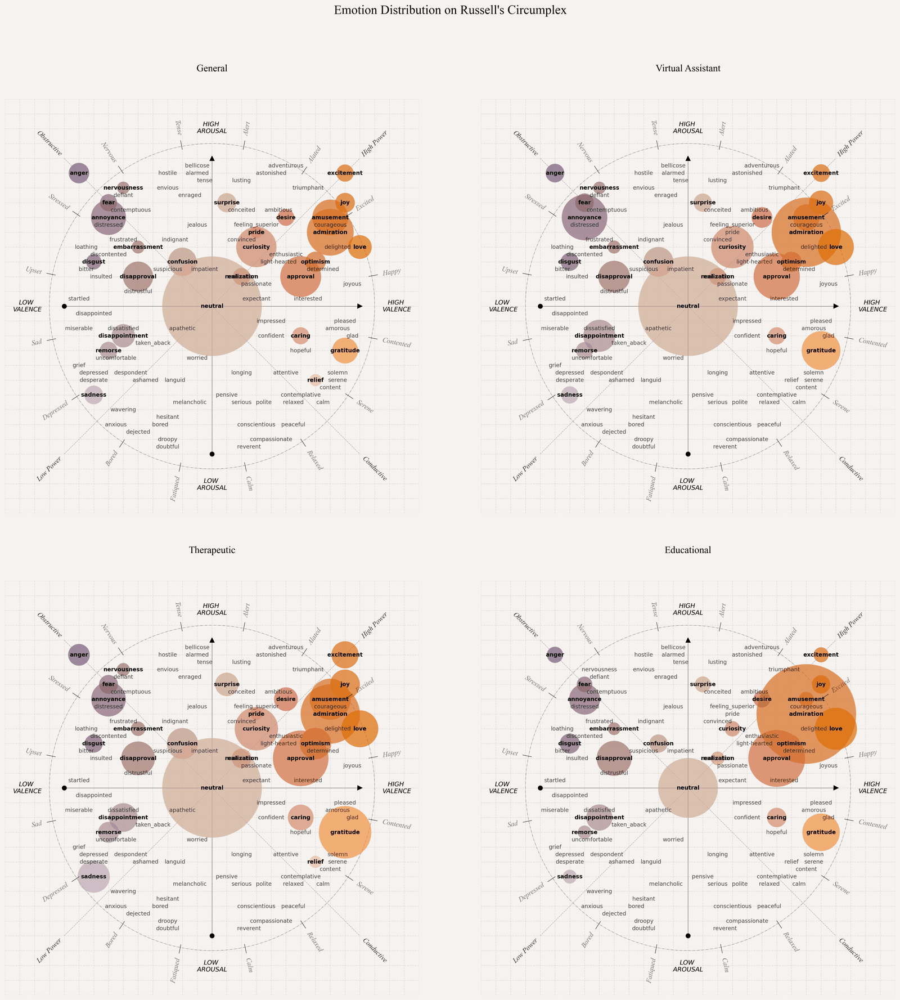

In [22]:
# ── Settings ───────────────────────────────────────────────────────────────────

FIGURE_SIZE = (18, 20)
FIGURE_DPI  = 300
CATEGORIES  = ["general", "virtual_assistant", "therapeutic", "educational"]

# ── Figure ─────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, squeeze=False)
fig.patch.set_facecolor("#f5f2ef")
axes_flat = axes.flatten()

for ax, CATEGORY in zip(axes_flat, CATEGORIES):

    # ── Aggregation ────────────────────────────────────────────────────────────

    subset = df_emotion[df_emotion["category"] == CATEGORY]

    emotion_agg = (
        subset.groupby("emotion")
        .agg(
            count        =("emotion",         "size"),
            mean_valence =("emotion_valence", "mean"),
            mean_arousal =("emotion_arousal", "mean"),
        )
        .reset_index()
    )

    emotions   = emotion_agg["emotion"].tolist()
    x_vals     = emotion_agg["mean_valence"].tolist()
    y_vals     = emotion_agg["mean_arousal"].tolist()
    sizes_arr  = emotion_agg["count"].values
    colors_val = emotion_agg["mean_valence"].tolist()

    sizes_norm = (sizes_arr / sizes_arr.max()) * 20000 + 300

    # ── Colormap ───────────────────────────────────────────────────────────────────

    cmap   = mcolors.LinearSegmentedColormap.from_list(
        "chromatlas", [
        "#6a518c", # purple
        "#9f756c", # heather
        "#cfad96", # neutral beige
        "#cf6e51", # red
        "#de6e02", # orange   
        ])
    
    norm = mcolors.Normalize(vmin=-1, vmax=1)
    
    # ── Lightness modulation by arousal ───────────────────────────────────────────
    
    LIGHTNESS_MAX = 2   
    
    def adjust_lightness(hex_color, factor):
        hex_color = hex_color.lstrip("#")
        r, g, b   = [int(hex_color[i:i+2], 16) / 255 for i in (0, 2, 4)]
        h, l, s   = colorsys.rgb_to_hls(r, g, b)
        l         = max(0, min(1, l * factor))
        r, g, b   = colorsys.hls_to_rgb(h, l, s)
        return (r, g, b)
        
    # ── Build colors — valence drives hue, arousal drives lightness ───────────────
        
    colors = []
    
    for v, a in zip(colors_val, y_vals):
        base_color = mcolors.to_hex(cmap(norm(v)))
        if a < 0:
            lightness_factor = 1.0 + (LIGHTNESS_MAX - 1.0) * abs(a)
            color = adjust_lightness(base_color, lightness_factor)
        else:
            color = mcolors.to_rgb(base_color)
        colors.append(color)

    # ── Bubbles ────────────────────────────────────────────────────────────────

    for i in range(len(emotions)):
        ax.scatter(
            x_vals[i], y_vals[i],
            s=sizes_norm[i],
            color=colors[i],
            alpha=0.7,
            edgecolors="none",
            zorder=2
        )
        ax.text(
            x_vals[i], y_vals[i],
            emotions[i],
            ha="center", va="center",
            fontsize=8, color="#000000",
            fontweight="bold",
            zorder=3
        )

    # ── Emotion names on grid ───────────────────────────────────────────────────
    
    EMOTION_POSITIONS = {    
        
        # ── Quadrant I: Pleasant / Activated ──────────────────────────────────────
        
        "triumphant":      ( 0.65,  0.80),
        "courageous":      ( 0.80,  0.55),
        "ambitious":       ( 0.45,  0.65),
        "feeling_superior":( 0.30,  0.55),
        "light-hearted":   ( 0.45,  0.30),
        "enthusiastic":    ( 0.50,  0.35),
        "delighted":       ( 0.85,  0.40),
        "determined":      ( 0.75,  0.25),
        "passionate":      ( 0.30,  0.15),
        "joyous":          ( 0.95,  0.15),
        "interested":      ( 0.65,  0.05),
        "expectant":       ( 0.30,  0.05),
        "convinced":       ( 0.20,  0.45),
        "lusting":         ( 0.20,  0.85),
        "astonished":      ( 0.40,  0.90),
        "adventurous":     ( 0.50,  0.95),
        "conceited":       ( 0.20,  0.65),
        
        # ── Quadrant II: Unpleasant / Activated ────────────────────────────────────
        
        "bellicose":       (-0.10,  0.95),
        "hostile":         (-0.30,  0.90),
        "alarmed":         (-0.10,  0.90),
        "tense":           (-0.05,  0.85),
        "enraged":         (-0.15,  0.75),
        "envious":         (-0.30,  0.80),
        "indignant":       (-0.25,  0.45),
        "jealous":         (-0.10,  0.55),
        "impatient":       (-0.05,  0.25),
        "contemptuous":    (-0.55,  0.65),
        "defiant":         (-0.60,  0.75),
        "loathing":        (-0.85,  0.40),
        "suspicious":      (-0.30,  0.25),
        "distressed":      (-0.70,  0.55),
        "frustrated":      (-0.60,  0.45),
        "discontented":    (-0.70,  0.35),
        "bitter":          (-0.85,  0.25),
        "insulted":        (-0.75,  0.20),
        "distrustful":     (-0.50,  0.10),
        "startled":        (-0.90,  0.05),
        
        # ── Quadrant III: Unpleasant / Deactivated ─────────────────────────────────
        
        "miserable":       (-0.90, -0.15),
        "dissatisfied":    (-0.60, -0.15),
        "uncomfortable":   (-0.65, -0.35),
        "taken_aback":     (-0.40, -0.25),
        "despondent":      (-0.55, -0.45),
        "depressed":       (-0.80, -0.45),
        "desperate":       (-0.80, -0.50),
        "ashamed":         (-0.45, -0.50),
        "disappointed":    (-0.80, -0.05),
        "apathetic":       (-0.20, -0.15),
        "worried":         (-0.10, -0.35),
        "languid":         (-0.25, -0.50),
        "melancholic":     (-0.15, -0.65),
        "hesitant":        (-0.30, -0.75),
        "anxious":         (-0.65, -0.80),
        "wavering":        (-0.60, -0.70),
        "dejected":        (-0.50, -0.85),
        "droopy":          (-0.30, -0.90),
        "doubtful":        (-0.30, -0.95),
        "bored":           (-0.35, -0.80),
        
        # ── Quadrant IV: Pleasant / Deactivated ────────────────────────────────────
        
        "impressed":       ( 0.40, -0.10),
        "amorous":         ( 0.85, -0.15),
        "pensive":         ( 0.10, -0.60),
        "serious":         ( 0.20, -0.65),
        "confident":       ( 0.40, -0.20),
        "hopeful":         ( 0.60, -0.30),
        "content":         ( 0.80, -0.55),
        "calm":            ( 0.75, -0.65),
        "relaxed":         ( 0.55, -0.65),
        "solemn":          ( 0.85, -0.45),
        "attentive":       ( 0.50, -0.45),
        "polite":          ( 0.35, -0.65),
        "longing":         ( 0.20, -0.45),
        "contemplative":   ( 0.60, -0.60),
        "conscientious":   ( 0.30, -0.80),
        "peaceful":        ( 0.55, -0.80),
        "compassionate":   ( 0.40, -0.90),
        "reverent":        ( 0.25, -0.95),
        "serene":          ( 0.85, -0.50),
        "pleased":         ( 0.90, -0.10),
        "glad":            ( 0.95, -0.20),

        # ── Categories defined in GoEmotions set ────────────────────────────────────
        
        "excitement":      ( 0.9,  0.9),
        "joy":             ( 0.9,  0.7),
        "amusement":       ( 0.8,  0.6),
        "admiration":      ( 0.8,  0.5),
        "approval":        ( 0.6,  0.2),
        "pride":           ( 0.3,  0.5),
        "love":            ( 1.0,  0.4),
        "desire":          ( 0.5,  0.6),
        "optimism":        ( 0.7,  0.3),
        "caring":          ( 0.6, -0.2),
        "gratitude":       ( 0.9, -0.3),
        "relief":          ( 0.7, -0.5),
        "curiosity":       ( 0.3,  0.4),
        "realisation":     ( 0.2,  0.2),
        "surprise":        ( 0.1,  0.7),
        "neutral":         ( 0.0,  0.0),
        "confusion":       (-0.2,  0.3),
        "disapproval":     (-0.5,  0.2),
        "annoyance":       (-0.7,  0.6),
        "anger":           (-0.9,  0.9),
        "fear":            (-0.7,  0.7),
        "nervousness":     (-0.6,  0.8),
        "disgust":         (-0.8,  0.3),
        "embarrassment":   (-0.5,  0.4),
        "disappointment":  (-0.6, -0.2),
        "remorse":         (-0.7, -0.3),
        "sadness":         (-0.8, -0.6),
        "grief":           (-0.9, -0.4)
    }
    
    for emotion, (ex, ey) in EMOTION_POSITIONS.items():
        if emotion.lower() in emotions:
            continue 
            
        ax.text(
            ex, ey,
            emotion,
            ha="center", va="center",
            fontsize=8, color="#000000",
            alpha=0.7,
            zorder=3
        )

    # ── Circle border ──────────────────────────────────────────────────────────

    from matplotlib.patches import Circle
    circle = Circle((0, 0), radius=1.1, fill=False, linestyle="-.",
                    edgecolor="#000000", alpha=0.4, linewidth=0.6, zorder=1)
    ax.add_patch(circle)

    # ── Ticks on circle ────────────────────────────────────────────────────────────
    
    TICK_INNER = 1.08   
    TICK_OUTER = 1.14   
    OFFSET = -11.25
    RADIAL_EMOTIONS = {
        "Alert":      ( np.cos(np.radians( 90  + OFFSET)), np.sin(np.radians( 90  + OFFSET))),
        "Alated":     ( np.cos(np.radians( 67  + OFFSET)), np.sin(np.radians( 67  + OFFSET))),
        "Excited":    ( np.cos(np.radians( 45  + OFFSET)), np.sin(np.radians( 45  + OFFSET))),
        "Happy":      ( np.cos(np.radians( 22  + OFFSET)), np.sin(np.radians( 22  + OFFSET))),
        "Contented":  ( np.cos(np.radians(  0  + OFFSET)), np.sin(np.radians(  0  + OFFSET))),
        "Serene":     ( np.cos(np.radians(-22  + OFFSET)), np.sin(np.radians(-22  + OFFSET))),
        "Relaxed":    ( np.cos(np.radians(-45  + OFFSET)), np.sin(np.radians(-45  + OFFSET))),
        "Calm":       ( np.cos(np.radians(-67  + OFFSET)), np.sin(np.radians(-67  + OFFSET))),
        "Fatiqued":   ( np.cos(np.radians(-90  + OFFSET)), np.sin(np.radians(-90  + OFFSET))),
        "Bored":      ( np.cos(np.radians(-112 + OFFSET)), np.sin(np.radians(-112 + OFFSET))),
        "Depressed":  ( np.cos(np.radians(-135 + OFFSET)), np.sin(np.radians(-135 + OFFSET))),
        "Sad":        ( np.cos(np.radians(-157 + OFFSET)), np.sin(np.radians(-157 + OFFSET))),
        "Upset":      ( np.cos(np.radians( 180 + OFFSET)), np.sin(np.radians( 180 + OFFSET))),
        "Stressed":   ( np.cos(np.radians( 157 + OFFSET)), np.sin(np.radians( 157 + OFFSET))),
        "Nervous":    ( np.cos(np.radians( 135 + OFFSET)), np.sin(np.radians( 135 + OFFSET))),
        "Tense":      ( np.cos(np.radians( 112 + OFFSET)), np.sin(np.radians( 112 + OFFSET)))
    }
    
    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        ax.plot(
            [lx * TICK_INNER, lx * TICK_OUTER],
            [ly * TICK_INNER, ly * TICK_OUTER],
            color="#000000", alpha=0.8, linewidth=0.6, zorder=2
        )

    # ── Crosshair ─────────────────────────────────────────────────────────────

    ax.plot([-1.0, 1.0], [0, 0], color="#000000", alpha=0.6, linewidth=0.6, zorder=1)
    ax.plot([0, 0], [-1.0, 1.0], color="#000000", alpha=0.6, linewidth=0.6, zorder=1)
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect("equal")

    # ── Grid ───────────────────────────────────────────────────────────────────────
    
    ax.set_xticks(np.arange(-1.4, 1.5, 0.1))
    ax.set_yticks(np.arange(-1.4, 1.5, 0.1))
    ax.grid(axis="both", alpha=0.3, linestyle="--", linewidth=0.7, zorder=0)

    # ── Diagonal lines ─────────────────────────────────────────────────────────────
     
    ax.plot([-1.0, 1.0], [-1.0, 1.0], color="#000000", alpha=0.3,
        linewidth=0.6, linestyle="--", zorder=1)
    ax.plot([-1.0, 1.0], [ 1.0, -1.0], color="#000000", alpha=0.3,
        linewidth=0.6, linestyle="--", zorder=1)

    # ── Axis endpoint markers ──────────────────────────────────────────────────────
    
    MARKER_SIZE = 6
    
    # Dots at -1 - the beginning of the axis 
    ax.plot( 0, -1, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot(-1,  0, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    
    # Triangles at +1 — pointed like arrows
    ax.plot(0,  1, "^", color="#000000", markersize=MARKER_SIZE, zorder=5)  
    ax.plot(1,  0, ">", color="#000000", markersize=MARKER_SIZE, zorder=5)  
    
    # ── Diagonal labels ────────────────────────────────────────────────────────────

    diag_label_kwargs = dict(fontsize=10, color="#000000", alpha=0.8,
                         fontstyle="italic", fontfamily="Times New Roman")
    # Top-left — High Arousal / Unpleasant
    ax.text(-1.1,  1.1, "Obstructive",
        ha="center", va="center", rotation=-45, **diag_label_kwargs)
    
    # Top-right — High Arousal / Pleasant
    ax.text(1.1,  1.1, "High Power",
        ha="center", va="center", rotation=45, **diag_label_kwargs)
    
    # Bottom-left — Low Arousal / Unpleasant
    ax.text(-1.1, -1.1, "Low Power",
        ha="center", va="center", rotation=45, **diag_label_kwargs)
    
    # Bottom-right — Low Arousal / Pleasant
    ax.text(1.1, -1.1, "Conductive",
        ha="center", va="center", rotation=-45, **diag_label_kwargs)

    # ── Quadrant labels ────────────────────────────────────────────────────────

    label_kwargs = dict(fontsize=9, color="#000000", alpha=1, fontstyle="italic")
    ax.text( 0,      1.25,  "HIGH \nAROUSAL",      ha="center",  va="top",    **label_kwargs)
    ax.text( 0,     -1.25,  "LOW \nAROUSAL",       ha="center",  va="bottom", **label_kwargs)
    ax.text(-1.25,   0,     "LOW \nVALENCE",       ha="center",  va="center", **label_kwargs)
    ax.text( 1.25,   0,     "HIGH \nVALENCE",      ha="center",  va="center", **label_kwargs)

    # ── Radial emotion labels ──────────────────────────────────────────────────────
    
    LABEL_RADIUS = 1.175   
    
    radial_label_kwargs = dict(fontsize=10, color="#000000", alpha=0.5,
                           fontfamily="Times New Roman", fontstyle="italic")
    
    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        
        angle_deg = np.degrees(np.arctan2(ly, lx))
        
        if -90 <= angle_deg <= 90:
            rotation = angle_deg
            ha = "left"
        else:
            rotation = angle_deg + 180
            ha = "right"
            
        ax.text(
        lx * LABEL_RADIUS, ly * LABEL_RADIUS,
        label,
        ha=ha, va="center",
        rotation=rotation,
        rotation_mode="anchor",
        **radial_label_kwargs
        )

    # ── Frame ──────────────────────────────────────────────────────────────────

    for spine in ax.spines.values():
        spine.set_alpha(0.0)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_facecolor("#f5f2ef")

    ax.set_title(
        CATEGORY.replace("_", " ").title(),
        fontsize=14, fontfamily="Times New Roman", pad=40, loc="center"
    )

# ── Suptitle ───────────────────────────────────────────────────────────────────

fig.suptitle(
    "Emotion Distribution on Russell's Circumplex",
    fontsize=18, fontfamily="Times New Roman", y=1.02
)

# ── Save and display ───────────────────────────────────────────────────────────

plt.tight_layout()
plt.subplots_adjust(wspace=0.15)
plt.savefig("russell_general_virtual_assistant.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

#### 8.2.3. Consensus Results of VADER, NRC VAD & GoEmotions

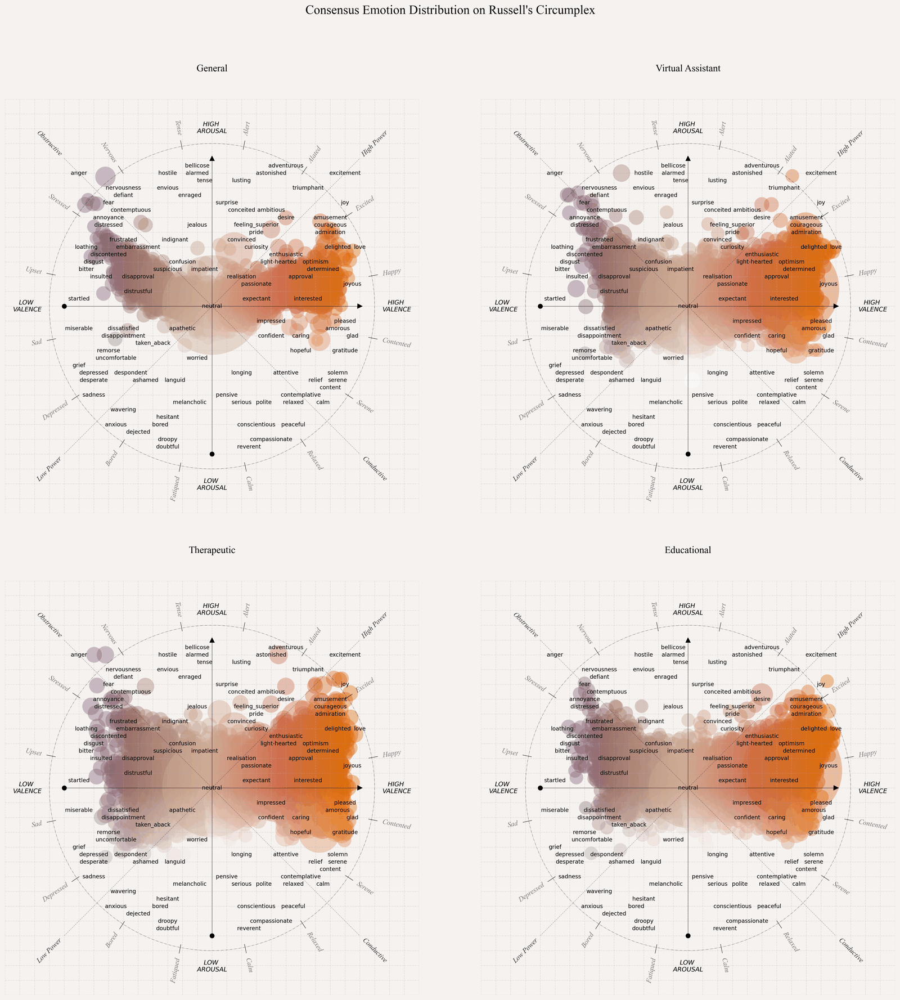

In [23]:
# ── Settings ───────────────────────────────────────────────────────────────────

FIGURE_SIZE  = (18, 20)
FIGURE_DPI   = 300
CATEGORIES   = ["general", "virtual_assistant", "therapeutic", "educational"]
N_DECILES    = 8000

# ── Emotion positions on grid ──────────────────────────────────────────────────

EMOTION_POSITIONS = {

    # ── Quadrant I: Pleasant / Activated ──────────────────────────────────────
    
    "triumphant":      ( 0.65,  0.80),
    "courageous":      ( 0.80,  0.55),
    "ambitious":       ( 0.40,  0.65),
    "feeling_superior":( 0.30,  0.55),
    "light-hearted":   ( 0.45,  0.30),
    "enthusiastic":    ( 0.50,  0.35),
    "delighted":       ( 0.85,  0.40),
    "determined":      ( 0.75,  0.25),
    "passionate":      ( 0.30,  0.15),
    "joyous":          ( 0.95,  0.15),
    "interested":      ( 0.65,  0.05),
    "expectant":       ( 0.30,  0.05),
    "convinced":       ( 0.20,  0.45),
    "lusting":         ( 0.20,  0.85),
    "astonished":      ( 0.40,  0.90),
    "adventurous":     ( 0.50,  0.95),
    "conceited":       ( 0.20,  0.65),

    # ── Quadrant II: Unpleasant / Activated ────────────────────────────────────
    
    "bellicose":       (-0.10,  0.95),
    "hostile":         (-0.30,  0.90),
    "alarmed":         (-0.10,  0.90),
    "tense":           (-0.05,  0.85),
    "enraged":         (-0.15,  0.75),
    "envious":         (-0.30,  0.80),
    "indignant":       (-0.25,  0.45),
    "jealous":         (-0.10,  0.55),
    "impatient":       (-0.05,  0.25),
    "contemptuous":    (-0.55,  0.65),
    "defiant":         (-0.60,  0.75),
    "loathing":        (-0.85,  0.40),
    "suspicious":      (-0.30,  0.25),
    "distressed":      (-0.70,  0.55),
    "frustrated":      (-0.60,  0.45),
    "discontented":    (-0.70,  0.35),
    "bitter":          (-0.85,  0.25),
    "insulted":        (-0.75,  0.20),
    "distrustful":     (-0.50,  0.10),
    "startled":        (-0.90,  0.05),

     # ── Quadrant III: Unpleasant / Deactivated ─────────────────────────────────
    
    "miserable":       (-0.90, -0.15),
    "dissatisfied":    (-0.60, -0.15),
    "uncomfortable":   (-0.65, -0.35),
    "taken_aback":     (-0.40, -0.25),
    "despondent":      (-0.55, -0.45),
    "depressed":       (-0.80, -0.45),
    "desperate":       (-0.80, -0.50),
    "ashamed":         (-0.45, -0.50),
    "apathetic":       (-0.20, -0.15),
    "worried":         (-0.10, -0.35),
    "languid":         (-0.25, -0.50),
    "melancholic":     (-0.15, -0.65),
    "hesitant":        (-0.30, -0.75),
    "anxious":         (-0.65, -0.80),
    "wavering":        (-0.60, -0.70),
    "dejected":        (-0.50, -0.85),
    "droopy":          (-0.30, -0.90),
    "doubtful":        (-0.30, -0.95),
    "bored":           (-0.35, -0.80),
    
    # ── Quadrant IV: Pleasant / Deactivated ────────────────────────────────────
    
    "impressed":       ( 0.40, -0.10),
    "amorous":         ( 0.85, -0.15),
    "pensive":         ( 0.10, -0.60),
    "serious":         ( 0.20, -0.65),
    "confident":       ( 0.40, -0.20),
    "hopeful":         ( 0.60, -0.30),
    "content":         ( 0.80, -0.55),
    "calm":            ( 0.75, -0.65),
    "relaxed":         ( 0.55, -0.65),
    "solemn":          ( 0.85, -0.45),
    "attentive":       ( 0.50, -0.45),
    "polite":          ( 0.35, -0.65),
    "longing":         ( 0.20, -0.45),
    "contemplative":   ( 0.60, -0.60),
    "conscientious":   ( 0.30, -0.80),
    "peaceful":        ( 0.55, -0.80),
    "compassionate":   ( 0.40, -0.90),
    "reverent":        ( 0.25, -0.95),
    "serene":          ( 0.85, -0.50),
    "pleased":         ( 0.90, -0.10),
    "glad":            ( 0.95, -0.20),

    # ── Categories defined in GoEmotions set ────────────────────────────────────

    "excitement":      ( 0.9,  0.9),
    "joy":             ( 0.9,  0.7),
    "amusement":       ( 0.8,  0.6),
    "admiration":      ( 0.8,  0.5),
    "approval":        ( 0.6,  0.2),
    "pride":           ( 0.3,  0.5),
    "love":            ( 1.0,  0.4),
    "desire":          ( 0.5,  0.6),
    "optimism":        ( 0.7,  0.3),
    "caring":          ( 0.6, -0.2),
    "gratitude":       ( 0.9, -0.3),
    "relief":          ( 0.7, -0.5),
    "curiosity":       ( 0.3,  0.4),
    "realisation":     ( 0.2,  0.2),
    "surprise":        ( 0.1,  0.7),
    "neutral":         ( 0.0,  0.0),
    "confusion":       (-0.2,  0.3),
    "disapproval":     (-0.5,  0.2),
    "annoyance":       (-0.7,  0.6),
    "anger":           (-0.9,  0.9),
    "fear":            (-0.7,  0.7),
    "nervousness":     (-0.6,  0.8),
    "disgust":         (-0.8,  0.3),
    "embarrassment":   (-0.5,  0.4),
    "disappointment":  (-0.6, -0.2),
    "remorse":         (-0.7, -0.3),
    "sadness":         (-0.8, -0.6),
    "grief":           (-0.9, -0.4),
}

# ── Radial emotions ────────────────────────────────────────────────────────────

OFFSET = -11.25
RADIAL_EMOTIONS = {
    "Alert":      (np.cos(np.radians( 90  + OFFSET)), np.sin(np.radians( 90  + OFFSET))),
    "Alated":     (np.cos(np.radians( 67  + OFFSET)), np.sin(np.radians( 67  + OFFSET))),
    "Excited":    (np.cos(np.radians( 45  + OFFSET)), np.sin(np.radians( 45  + OFFSET))),
    "Happy":      (np.cos(np.radians( 22  + OFFSET)), np.sin(np.radians( 22  + OFFSET))),
    "Contented":  (np.cos(np.radians(  0  + OFFSET)), np.sin(np.radians(  0  + OFFSET))),
    "Serene":     (np.cos(np.radians(-22  + OFFSET)), np.sin(np.radians(-22  + OFFSET))),
    "Relaxed":    (np.cos(np.radians(-45  + OFFSET)), np.sin(np.radians(-45  + OFFSET))),
    "Calm":       (np.cos(np.radians(-67  + OFFSET)), np.sin(np.radians(-67  + OFFSET))),
    "Fatiqued":   (np.cos(np.radians(-90  + OFFSET)), np.sin(np.radians(-90  + OFFSET))),
    "Bored":      (np.cos(np.radians(-112 + OFFSET)), np.sin(np.radians(-112 + OFFSET))),
    "Depressed":  (np.cos(np.radians(-135 + OFFSET)), np.sin(np.radians(-135 + OFFSET))),
    "Sad":        (np.cos(np.radians(-157 + OFFSET)), np.sin(np.radians(-157 + OFFSET))),
    "Upset":      (np.cos(np.radians( 180 + OFFSET)), np.sin(np.radians( 180 + OFFSET))),
    "Stressed":   (np.cos(np.radians( 157 + OFFSET)), np.sin(np.radians( 157 + OFFSET))),
    "Nervous":    (np.cos(np.radians( 135 + OFFSET)), np.sin(np.radians( 135 + OFFSET))),
    "Tense":      (np.cos(np.radians( 112 + OFFSET)), np.sin(np.radians( 112 + OFFSET))),
}

# ── Consensus scores ──────────────────────────────────────────────────────────

df_emotion["consensus_valence"] = (
    df_emotion[
        [
            "nrc_valence",
            "emotion_valence",
            "vader_score"
        ]
    ]
    .mean(axis=1)
)

df_emotion["consensus_arousal"] = (
    df_emotion[
        [
            "nrc_arousal",
            "emotion_arousal"
        ]
    ]
    .mean(axis=1)
)

# ── Colormap ───────────────────────────────────────────────────────────────────

cmap = mcolors.LinearSegmentedColormap.from_list(
    "chromatlas", [
        "#6a518c", # purple
        "#9f756c", # heather
        "#cfad96", # neutral beige
        "#cf6e51", # red
        "#de6e02", # orange
    ])
norm = mcolors.Normalize(vmin=-1, vmax=1)

LIGHTNESS_MAX = 2.0

def adjust_lightness(hex_color, factor):
    hex_color = hex_color.lstrip("#")
    r, g, b   = [int(hex_color[i:i+2], 16) / 255 for i in (0, 2, 4)]
    h, l, s   = colorsys.rgb_to_hls(r, g, b)
    l         = max(0, min(1, l * factor))
    r, g, b   = colorsys.hls_to_rgb(h, l, s)
    return (r, g, b)

def build_colors(x_vals, y_vals):
    colors = []
    for v, a in zip(x_vals, y_vals):
        base_color = mcolors.to_hex(cmap(norm(v)))
        if a < 0:
            lightness_factor = 1.0 + (LIGHTNESS_MAX - 1.0) * abs(a)
            color = adjust_lightness(base_color, lightness_factor)
        else:
            color = mcolors.to_rgb(base_color)
        colors.append(color)
    return colors

def build_decile_bubbles(valence_series, arousal_series):
    """Group records into N_DECILES bins by valence, return bubble data."""
    
    df_temp = pd.DataFrame({
        "valence": valence_series,
        "arousal": arousal_series
    }).dropna()

    df_temp["decile"] = pd.qcut(df_temp["valence"], N_DECILES, labels=False, duplicates="drop")

    agg = (
        df_temp.groupby("decile")
        .agg(
            mean_valence=("valence", "mean"),
            mean_arousal=("arousal", "mean"),
            count       =("valence", "size"),
        )
        .reset_index()
    )
    return agg

def draw_base(ax):
    """Draw shared background elements — grid, crosshair, circle, labels."""

    # Grid
    ax.set_xticks(np.arange(-1.4, 1.5, 0.1))
    ax.set_yticks(np.arange(-1.4, 1.5, 0.1))
    ax.grid(axis="both", alpha=0.3, linestyle="--", linewidth=0.7, zorder=0)

    # Crosshair
    ax.plot([-1.0, 1.0], [0, 0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)
    ax.plot([0, 0], [-1.0, 1.0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)

    # Diagonal lines
    ax.plot([-1.0, 1.0], [-1.0,  1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)
    ax.plot([-1.0, 1.0], [ 1.0, -1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)

    # Emotion names on grid
    for emotion, (ex, ey) in EMOTION_POSITIONS.items():
        ax.text(ex, ey, emotion, ha="center", va="center",
                fontsize=8, color="#000000", alpha=1, zorder=4)

    # Ticks and radial labels
    TICK_INNER   = 1.08
    TICK_OUTER   = 1.14
    LABEL_RADIUS = 1.175

    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        ax.plot([lx * TICK_INNER, lx * TICK_OUTER],
                [ly * TICK_INNER, ly * TICK_OUTER],
                color="#000000", alpha=0.8, linewidth=0.6, zorder=3)
        angle_deg = np.degrees(np.arctan2(ly, lx))
        if -90 <= angle_deg <= 90:
            rotation, ha = angle_deg, "left"
        else:
            rotation, ha = angle_deg + 180, "right"
        ax.text(lx * LABEL_RADIUS, ly * LABEL_RADIUS, label,
                ha=ha, va="center", rotation=rotation,
                rotation_mode="anchor", fontsize=10,
                color="#000000", alpha=0.5,
                fontfamily="Times New Roman", fontstyle="italic", zorder=3)

    # Circle
    circle = Circle((0, 0), radius=1.1, fill=False, linestyle="-.",
                    edgecolor="#000000", alpha=0.4, linewidth=0.6, zorder=3)
    ax.add_patch(circle)

    # Quadrant labels
    diag_kw = dict(fontsize=10, color="#000000", alpha=0.8,
                   fontstyle="italic", fontfamily="Times New Roman")
    ax.text(-1.1,  1.1, "Obstructive", ha="center", va="center", rotation=-45, zorder=4, **diag_kw)
    ax.text( 1.1,  1.1, "High Power",  ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text(-1.1, -1.1, "Low Power",   ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text( 1.1, -1.1, "Conductive",  ha="center", va="center", rotation=-45, zorder=4, **diag_kw)

    lkw = dict(fontsize=9, color="#000000", alpha=1, fontstyle="italic")
    ax.text( 0,     1.25, "HIGH \nAROUSAL", ha="center", va="top",    zorder=4, **lkw)
    ax.text( 0,    -1.25, "LOW \nAROUSAL",  ha="center", va="bottom", zorder=4, **lkw)
    ax.text(-1.25,  0,    "LOW \nVALENCE",  ha="center", va="center", zorder=4, **lkw)
    ax.text( 1.25,  0,    "HIGH \nVALENCE", ha="center", va="center", zorder=4, **lkw)

    # Axis endpoint markers
    MARKER_SIZE = 6
    ax.plot( 0, -1, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot(-1,  0, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 0,  1, "^", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 1,  0, ">", color="#000000", markersize=MARKER_SIZE, zorder=5)

    # Frame
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_alpha(0.0)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_facecolor("#f5f2ef")

# ── The figure ─────────────────────────────────────────────────────────────────

for model_name, valence_col, arousal_col, filename, title in [
    (
        "CONSENSUS",
        "consensus_valence",
        "consensus_arousal",
        "russell_consensus.png",
        "Consensus Emotion Distribution on Russell's Circumplex"
    )
]:
    fig, axes = plt.subplots(2, 2, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, squeeze=False)
    fig.patch.set_facecolor("#f5f2ef")
    axes_flat = axes.flatten()

    for ax, CATEGORY in zip(axes_flat, CATEGORIES):

        subset = df_emotion[df_emotion["category"] == CATEGORY].copy()

        # ── Arousal column ─────────────────────────────────────────────────────

        if arousal_col is not None:
            arousal_series = subset[arousal_col]
        else:
            arousal_series = subset[valence_col] * 0   

        # ── Build decile bubbles ───────────────────────────────────────────────

        agg        = build_decile_bubbles(subset[valence_col], arousal_series)
        x_vals     = agg["mean_valence"].tolist()
        y_vals     = agg["mean_arousal"].tolist()
        sizes_arr  = agg["count"].values
        sizes_norm = (sizes_arr / sizes_arr.max()) * 20000 + 300
        colors     = build_colors(x_vals, y_vals)

        # ── Draw base ──────────────────────────────────────────────────────────

        draw_base(ax)

        # ── Bubbles — zorder=1 ─────────────────────────────────────────────────

        for i in range(len(x_vals)):
            ax.scatter(
                x_vals[i], y_vals[i],
                s=sizes_norm[i],
                color=colors[i],
                alpha=0.4,
                edgecolors="none",
                zorder=1
            )

        ax.set_title(
            CATEGORY.replace("_", " ").title(),
            fontsize=14, fontfamily="Times New Roman", pad=40, loc="center"
        )

    fig.suptitle(title, fontsize=18, fontfamily="Times New Roman", y=1.02)

    plt.tight_layout()
    plt.subplots_adjust(wspace=0.15)
    plt.savefig(filename, bbox_inches="tight", pad_inches=0.5, transparent=False)
    display(fig)
    plt.close()

### 8.3. Consensus of Affect Mapped Collectively

In [ ]:
# ── Settings ───────────────────────────────────────────────────────────────────

FIGURE_SIZE  = (18, 20)
FIGURE_DPI   = 300
CATEGORIES   = ["general", "virtual_assistant", "therapeutic", "educational"]
N_DECILES    = 20000

# ── Emotion positions on grid ──────────────────────────────────────────────────

EMOTION_POSITIONS = {

    # ── Quadrant I: Pleasant / Activated ──────────────────────────────────────
    
    "triumphant":      ( 0.65,  0.80),
    "courageous":      ( 0.80,  0.55),
    "ambitious":       ( 0.40,  0.65),
    "feeling_superior":( 0.30,  0.55),
    "light-hearted":   ( 0.45,  0.30),
    "enthusiastic":    ( 0.50,  0.35),
    "delighted":       ( 0.85,  0.40),
    "determined":      ( 0.75,  0.25),
    "passionate":      ( 0.30,  0.15),
    "joyous":          ( 0.95,  0.15),
    "interested":      ( 0.65,  0.05),
    "expectant":       ( 0.30,  0.05),
    "convinced":       ( 0.20,  0.45),
    "lusting":         ( 0.20,  0.85),
    "astonished":      ( 0.40,  0.90),
    "adventurous":     ( 0.50,  0.95),
    "conceited":       ( 0.20,  0.65),

    # ── Quadrant II: Unpleasant / Activated ────────────────────────────────────
    
    "bellicose":       (-0.10,  0.95),
    "hostile":         (-0.30,  0.90),
    "alarmed":         (-0.10,  0.90),
    "tense":           (-0.05,  0.85),
    "enraged":         (-0.15,  0.75),
    "envious":         (-0.30,  0.80),
    "indignant":       (-0.25,  0.45),
    "jealous":         (-0.10,  0.55),
    "impatient":       (-0.05,  0.25),
    "contemptuous":    (-0.55,  0.65),
    "defiant":         (-0.60,  0.75),
    "loathing":        (-0.85,  0.40),
    "suspicious":      (-0.30,  0.25),
    "distressed":      (-0.70,  0.55),
    "frustrated":      (-0.60,  0.45),
    "discontented":    (-0.70,  0.35),
    "bitter":          (-0.85,  0.25),
    "insulted":        (-0.75,  0.20),
    "distrustful":     (-0.50,  0.10),
    "startled":        (-0.90,  0.05),

     # ── Quadrant III: Unpleasant / Deactivated ─────────────────────────────────
    
    "miserable":       (-0.90, -0.15),
    "dissatisfied":    (-0.60, -0.15),
    "uncomfortable":   (-0.65, -0.35),
    "taken_aback":     (-0.40, -0.25),
    "despondent":      (-0.55, -0.45),
    "depressed":       (-0.80, -0.45),
    "desperate":       (-0.80, -0.50),
    "ashamed":         (-0.45, -0.50),
    "apathetic":       (-0.20, -0.15),
    "worried":         (-0.10, -0.35),
    "languid":         (-0.25, -0.50),
    "melancholic":     (-0.15, -0.65),
    "hesitant":        (-0.30, -0.75),
    "anxious":         (-0.65, -0.80),
    "wavering":        (-0.60, -0.70),
    "dejected":        (-0.50, -0.85),
    "droopy":          (-0.30, -0.90),
    "doubtful":        (-0.30, -0.95),
    "bored":           (-0.35, -0.80),
    
    # ── Quadrant IV: Pleasant / Deactivated ────────────────────────────────────
    
    "impressed":       ( 0.40, -0.10),
    "amorous":         ( 0.85, -0.15),
    "pensive":         ( 0.10, -0.60),
    "serious":         ( 0.20, -0.65),
    "confident":       ( 0.40, -0.20),
    "hopeful":         ( 0.60, -0.30),
    "content":         ( 0.80, -0.55),
    "calm":            ( 0.75, -0.65),
    "relaxed":         ( 0.55, -0.65),
    "solemn":          ( 0.85, -0.45),
    "attentive":       ( 0.50, -0.45),
    "polite":          ( 0.35, -0.65),
    "longing":         ( 0.20, -0.45),
    "contemplative":   ( 0.60, -0.60),
    "conscientious":   ( 0.30, -0.80),
    "peaceful":        ( 0.55, -0.80),
    "compassionate":   ( 0.40, -0.90),
    "reverent":        ( 0.25, -0.95),
    "serene":          ( 0.85, -0.50),
    "pleased":         ( 0.90, -0.10),
    "glad":            ( 0.95, -0.20),

    # ── Categories defined in GoEmotions set ────────────────────────────────────

    "excitement":      ( 0.9,  0.9),
    "joy":             ( 0.9,  0.7),
    "amusement":       ( 0.8,  0.6),
    "admiration":      ( 0.8,  0.5),
    "approval":        ( 0.6,  0.2),
    "pride":           ( 0.3,  0.5),
    "love":            ( 1.0,  0.4),
    "desire":          ( 0.5,  0.6),
    "optimism":        ( 0.7,  0.3),
    "caring":          ( 0.6, -0.2),
    "gratitude":       ( 0.9, -0.3),
    "relief":          ( 0.7, -0.5),
    "curiosity":       ( 0.3,  0.4),
    "realisation":     ( 0.2,  0.2),
    "surprise":        ( 0.1,  0.7),
    "neutral":         ( 0.0,  0.0),
    "confusion":       (-0.2,  0.3),
    "disapproval":     (-0.5,  0.2),
    "annoyance":       (-0.7,  0.6),
    "anger":           (-0.9,  0.9),
    "fear":            (-0.7,  0.7),
    "nervousness":     (-0.6,  0.8),
    "disgust":         (-0.8,  0.3),
    "embarrassment":   (-0.5,  0.4),
    "disappointment":  (-0.6, -0.2),
    "remorse":         (-0.7, -0.3),
    "sadness":         (-0.8, -0.6),
    "grief":           (-0.9, -0.4),
}

# ── Radial emotions ────────────────────────────────────────────────────────────

OFFSET = -11.25
RADIAL_EMOTIONS = {
    "Alert":      (np.cos(np.radians( 90  + OFFSET)), np.sin(np.radians( 90  + OFFSET))),
    "Alated":     (np.cos(np.radians( 67  + OFFSET)), np.sin(np.radians( 67  + OFFSET))),
    "Excited":    (np.cos(np.radians( 45  + OFFSET)), np.sin(np.radians( 45  + OFFSET))),
    "Happy":      (np.cos(np.radians( 22  + OFFSET)), np.sin(np.radians( 22  + OFFSET))),
    "Contented":  (np.cos(np.radians(  0  + OFFSET)), np.sin(np.radians(  0  + OFFSET))),
    "Serene":     (np.cos(np.radians(-22  + OFFSET)), np.sin(np.radians(-22  + OFFSET))),
    "Relaxed":    (np.cos(np.radians(-45  + OFFSET)), np.sin(np.radians(-45  + OFFSET))),
    "Calm":       (np.cos(np.radians(-67  + OFFSET)), np.sin(np.radians(-67  + OFFSET))),
    "Fatiqued":   (np.cos(np.radians(-90  + OFFSET)), np.sin(np.radians(-90  + OFFSET))),
    "Bored":      (np.cos(np.radians(-112 + OFFSET)), np.sin(np.radians(-112 + OFFSET))),
    "Depressed":  (np.cos(np.radians(-135 + OFFSET)), np.sin(np.radians(-135 + OFFSET))),
    "Sad":        (np.cos(np.radians(-157 + OFFSET)), np.sin(np.radians(-157 + OFFSET))),
    "Upset":      (np.cos(np.radians( 180 + OFFSET)), np.sin(np.radians( 180 + OFFSET))),
    "Stressed":   (np.cos(np.radians( 157 + OFFSET)), np.sin(np.radians( 157 + OFFSET))),
    "Nervous":    (np.cos(np.radians( 135 + OFFSET)), np.sin(np.radians( 135 + OFFSET))),
    "Tense":      (np.cos(np.radians( 112 + OFFSET)), np.sin(np.radians( 112 + OFFSET))),
}

# ── Consensus scores ──────────────────────────────────────────────────────────

df_emotion["consensus_valence"] = (
    df_emotion[
        [
            "nrc_valence",
            "emotion_valence",
            "vader_score"
        ]
    ]
    .mean(axis=1)
)

df_emotion["consensus_arousal"] = (
    df_emotion[
        [
            "nrc_arousal",
            "emotion_arousal"
        ]
    ]
    .mean(axis=1)
)

# ── Colormap ───────────────────────────────────────────────────────────────────

cmap = mcolors.LinearSegmentedColormap.from_list(
    "chromatlas", [
        "#6a518c", # purple
        "#9f756c", # heather
        "#cfad96", # neutral beige
        "#cf6e51", # red
        "#de6e02", # orange
    ])
norm = mcolors.Normalize(vmin=-1, vmax=1)

LIGHTNESS_MAX = 2.0

def adjust_lightness(hex_color, factor):
    hex_color = hex_color.lstrip("#")
    r, g, b   = [int(hex_color[i:i+2], 16) / 255 for i in (0, 2, 4)]
    h, l, s   = colorsys.rgb_to_hls(r, g, b)
    l         = max(0, min(1, l * factor))
    r, g, b   = colorsys.hls_to_rgb(h, l, s)
    return (r, g, b)

def build_colors(x_vals, y_vals):
    colors = []
    for v, a in zip(x_vals, y_vals):
        base_color = mcolors.to_hex(cmap(norm(v)))
        if a < 0:
            lightness_factor = 1.0 + (LIGHTNESS_MAX - 1.0) * abs(a)
            color = adjust_lightness(base_color, lightness_factor)
        else:
            color = mcolors.to_rgb(base_color)
        colors.append(color)
    return colors

def build_decile_bubbles(valence_series, arousal_series):
    """Group records into N_DECILES bins by valence, return bubble data."""
    
    df_temp = pd.DataFrame({
        "valence": valence_series,
        "arousal": arousal_series
    }).dropna()

    df_temp["decile"] = pd.qcut(df_temp["valence"], N_DECILES, labels=False, duplicates="drop")

    agg = (
        df_temp.groupby("decile")
        .agg(
            mean_valence=("valence", "mean"),
            mean_arousal=("arousal", "mean"),
            count       =("valence", "size"),
        )
        .reset_index()
    )
    return agg

def draw_base(ax):
    """Draw shared background elements — grid, crosshair, circle, labels."""

    # Grid
    ax.set_xticks(np.arange(-1.4, 1.5, 0.1))
    ax.set_yticks(np.arange(-1.4, 1.5, 0.1))
    ax.grid(axis="both", alpha=0.3, linestyle="--", linewidth=0.7, zorder=0)

    # Crosshair
    ax.plot([-1.0, 1.0], [0, 0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)
    ax.plot([0, 0], [-1.0, 1.0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)

    # Diagonal lines
    ax.plot([-1.0, 1.0], [-1.0,  1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)
    ax.plot([-1.0, 1.0], [ 1.0, -1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)

    # Emotion names on grid
    for emotion, (ex, ey) in EMOTION_POSITIONS.items():
        ax.text(ex, ey, emotion, ha="center", va="center",
                fontsize=8, color="#000000", alpha=1, zorder=4)

    # Ticks and radial labels
    TICK_INNER   = 1.08
    TICK_OUTER   = 1.14
    LABEL_RADIUS = 1.175

    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        ax.plot([lx * TICK_INNER, lx * TICK_OUTER],
                [ly * TICK_INNER, ly * TICK_OUTER],
                color="#000000", alpha=0.8, linewidth=0.6, zorder=3)
        angle_deg = np.degrees(np.arctan2(ly, lx))
        if -90 <= angle_deg <= 90:
            rotation, ha = angle_deg, "left"
        else:
            rotation, ha = angle_deg + 180, "right"
        ax.text(lx * LABEL_RADIUS, ly * LABEL_RADIUS, label,
                ha=ha, va="center", rotation=rotation,
                rotation_mode="anchor", fontsize=10,
                color="#000000", alpha=0.5,
                fontfamily="Times New Roman", fontstyle="italic", zorder=3)

    # Circle
    circle = Circle((0, 0), radius=1.1, fill=False, linestyle="-.",
                    edgecolor="#000000", alpha=0.4, linewidth=0.6, zorder=3)
    ax.add_patch(circle)

    # Quadrant labels
    diag_kw = dict(fontsize=10, color="#000000", alpha=0.8,
                   fontstyle="italic", fontfamily="Times New Roman")
    ax.text(-1.1,  1.1, "Obstructive", ha="center", va="center", rotation=-45, zorder=4, **diag_kw)
    ax.text( 1.1,  1.1, "High Power",  ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text(-1.1, -1.1, "Low Power",   ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text( 1.1, -1.1, "Conductive",  ha="center", va="center", rotation=-45, zorder=4, **diag_kw)

    lkw = dict(fontsize=9, color="#000000", alpha=1, fontstyle="italic")
    ax.text( 0,     1.25, "HIGH \nAROUSAL", ha="center", va="top",    zorder=4, **lkw)
    ax.text( 0,    -1.25, "LOW \nAROUSAL",  ha="center", va="bottom", zorder=4, **lkw)
    ax.text(-1.25,  0,    "LOW \nVALENCE",  ha="center", va="center", zorder=4, **lkw)
    ax.text( 1.25,  0,    "HIGH \nVALENCE", ha="center", va="center", zorder=4, **lkw)

    # Axis endpoint markers
    MARKER_SIZE = 6
    ax.plot( 0, -1, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot(-1,  0, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 0,  1, "^", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 1,  0, ">", color="#000000", markersize=MARKER_SIZE, zorder=5)

    # Frame
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_alpha(0.0)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_facecolor("#f5f2ef")

# ── The figure ─────────────────────────────────────────────────────────────────

for model_name, valence_col, arousal_col, filename, title in [
    (
        "CONSENSUS",
        "consensus_valence",
        "consensus_arousal",
        "russell_consensus.png",
        "Consensus Emotion Distribution on Russell's Circumplex"
    )
]:
    fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=FIGURE_DPI)
    fig.patch.set_facecolor("#f5f2ef")
    
    # ── All categories combined ────────────────────────────────────────────────────
    
    agg        = build_decile_bubbles(
        df_emotion["consensus_valence"],
        df_emotion["consensus_arousal"]
    )
    
    x_vals     = agg["mean_valence"].tolist()
    y_vals     = agg["mean_arousal"].tolist()
    sizes_arr  = agg["count"].values
    sizes_norm = (sizes_arr / sizes_arr.max()) * 20000 + 300
    colors     = build_colors(x_vals, y_vals)
    
    # ── Draw base ──────────────────────────────────────────────────────────────────
    
    draw_base(ax)
    
    # ── Bubbles ────────────────────────────────────────────────────────────────────
    
    for i in range(len(x_vals)):
        ax.scatter(
            x_vals[i], y_vals[i],
            s=sizes_norm[i],
            color=colors[i],
            alpha=0.4,
            edgecolors="none",
            zorder=1
        )
        
        ax.set_title(
            "All Categories Combined",
            fontsize=14, fontfamily="Times New Roman", pad=40, loc="center"
        )
        
        fig.suptitle(
            "Consensus Emotion Distribution on Russell's Circumplex",
            fontsize=18, fontfamily="Times New Roman", y=1.02
        )

df_emotion.to_csv(PROCESSED_DIR / "opinions_emotion.csv", index=False)

plt.tight_layout()
plt.savefig("russell_consensus_all.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

### 8.4. Statistical Validation of Category Differences

To verify that **the visual separation of chatbot categories on the circumplex is statistically meaningful**, two complementary tests are applied. 

- **one-way MANOVA**: tests whether categories differ significantly across both valence and arousal simultaneously, treating them as a joint two-dimensional outcome. The MANOVA confirms that **chatbot categories differ significantly** in the two-dimensional valence–arousal space (Wilks' λ = 0.979, F(6, 273942) = 491.21, p < .001), indicating that the visual separation observed on the circumplex is not attributable to chance.

- **Kruskal-Wallis**: tests are run on each dimension separately to identify which axis drives the separation, with **Bonferroni correction** applied for multiple comparisons. Kruskal-Wallis tests on each dimension separately show that both effects are highly significant after Bonferroni correction. **The difference across categories is considerably stronger on the valence axis** (H = 2767.03, p < .001, ε² = .020) than on the arousal axis (H = 209.21, p < .001, ε² = .002). By conventional benchmarks (Tomczak & Tomczak, 2014), the valence effect is small-to-medium, while the **arousal effect is negligible** in practical terms, even though statistically significant given the large sample (N = 136,974),

These results suggest that chatbot categories are meaningfully differentiated primarily by the emotional tone (valence) of user language, whereas differences in activation level (arousal) — while detectable — carry little substantive weight. Circumplex visualisations should therefore be interpreted with this asymmetry in mind.

In [20]:
df_circ = df_emotion[["nrc_valence", "nrc_arousal", "category"]].dropna()

# ── 1. MANOVA (joint test on valence + arousal) ───────────────────────────────
maov = MANOVA.from_formula("nrc_valence + nrc_arousal ~ category", data=df_circ)
print("============================= MANOVA =============================\n")
print(maov.mv_test().summary())

# ── 2. Kruskal-Wallis per dimension (with Bonferroni correction) ──────────────
groups = df_circ.groupby("category")

for dim in ["nrc_valence", "nrc_arousal"]:
    samples = [g[dim].values for _, g in groups]
    H, p = kruskal(*samples)
    n = len(df_circ)
    k = df_circ["category"].nunique()
    eps2 = (H - k + 1) / (n - k)    # epsilon-squared (Tomczak & Tomczak, 2014)
    p_bonf = min(p * 2, 1.0)        # Bonferroni correction for 2 tests
    print(f"\n================== Kruskal-Wallis: {dim} ===================")
    print(f"  H = {H:.3f}, p = {p:.4f}, p_bonf = {p_bonf:.4f}, ε² = {eps2:.4f}")

============================= MANOVA =============================

                    Multivariate linear model
                                                                  
------------------------------------------------------------------
       Intercept        Value  Num DF    Den DF    F Value  Pr > F
------------------------------------------------------------------
          Wilks' lambda 0.8803 2.0000 136971.0000 9308.9503 0.0000
         Pillai's trace 0.1197 2.0000 136971.0000 9308.9503 0.0000
 Hotelling-Lawley trace 0.1359 2.0000 136971.0000 9308.9503 0.0000
    Roy's greatest root 0.1359 2.0000 136971.0000 9308.9503 0.0000
------------------------------------------------------------------
                                                                  
------------------------------------------------------------------
         category        Value  Num DF    Den DF   F Value  Pr > F
------------------------------------------------------------------
           Wilk

## 9. Topic-Affect Relationship Patterns

The analysis was performed separately for each of the four chatbot categories — general, therapeutic, virtual assistant, and educational — using the full dataset without sampling. 

Initial topic-affect clustering yielded limited discriminative power due to the concentration of topics within a single affective quadrant (pleasant-disactivated), prompting a shift toward a more direct approach of topic modelling within pre-defined emotional regions. Thus, the quadrant-based approach is used to identify topics that appear in different valence and arousal contexts.

**For each category and Russell's model circumplex quadrant, the number of topics was constrained to 10** to ensure comparability and interpretability across groups. Topic representations were derived using a CountVectorizer with English stop-word removal and bigram support, and keywords were weighted using BERTopic's c-TF-IDF scoring, which identifies **terms that are distinctive to each topic relative to the rest of the corpus**.

### 9.1. Quadrant- & Category-Unique Topic Representations Extraction

Topic modelling was conducted using **BERTopic**, a transformer-based approach that leverages sentence embeddings to identify semantically coherent clusters of documents. BERTopic does not rely on bag-of-words assumptions but instead captures contextual meaning through dense vector representations, allowing for more nuanced topic discovery in short, informal texts.

Applied within emotional quadrants, topic modelling reveals distinct thematic patterns across chatbot categories, offering a more nuanced view of what drives positive and negative user affect than sentiment scores alone.

- **General category**: pleasant activation is dominated by **broad AI discourse and model comparisons**, reflecting the exploratory and curious tone typical of Reddit engagement. Unpleasant activation, by contrast, surfaces a diverse range of active frustrations — including **ad overload, content refusals, hallucinations, and toxic social discourse** — suggesting that negative arousal in this category stems from both product limitations and broader societal concerns around AI.

- **Therapeutic category**: tells a particularly coherent story. Positive quadrants centre on **companionship interactions, community engagement, and emotional support**, while both unpleasant quadrants are heavily shaped by the consequences of **Replika's 2023 monetisation changes — users express grief over lost relationships with their AI companions, distrust toward the company, and frustration with paywalled intimacy features**. This pattern directly illustrates the fragility of parasocial trust in AI companionship applications.

- **Virtual Assistants**: pleasant topics reflect a **shift from traditional voice assistants toward more advanced AI agent capabilities**, with Copilot emerging prominently in positive contexts. Negative topics cluster around **functional failures** — voice recognition errors, navigation problems, and declining response quality — indicating that frustration in this category is primarily utility-driven rather than emotional.

- **Educational category**: shows the most **functionally specific frustration** profile: wrong mathematical answers, intrusive advertising, and aggressive paywalls dominate the unpleasant quadrants, while positive topics reflect straightforward satisfaction with **scanning features and step-by-step problem solving**. The emotional register here is **the most transactional of all four categories**, with users evaluating the application against concrete task performance criteria.

Across all categories, pleasant deactivated topics converge on generic gratitude and sharing behaviours, confirming the earlier finding that low-arousal positive content is largely category-independent. The most informative emotional signal for understanding user experience lies in the activated quadrants — particularly the unpleasant activated space, where category-specific frustrations are most clearly articulated.

In [ ]:
# ── Settings ───────────────────────────────────────────────────────────────────

N_TOPICS       = 11           
RANDOM_STATE   = 60
CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

QUADRANTS = {
    "Pleasant / Activated":     ("emotion_valence",  1,  "emotion_arousal",  1),
    "Pleasant / Deactivated":   ("emotion_valence",  1,  "emotion_arousal", -1),
    "Unpleasant / Activated":   ("emotion_valence", -1,  "emotion_arousal",  1),
    "Unpleasant / Deactivated": ("emotion_valence", -1,  "emotion_arousal", -1),
}

# ── Assign quadrant ────────────────────────────────────────────────────────────

def assign_quadrant(row):
    v = row["emotion_valence"]
    a = row["emotion_arousal"]
    if v >= 0 and a >= 0:
        return "Pleasant / Activated"
    elif v >= 0 and a < 0:
        return "Pleasant / Deactivated"
    elif v < 0 and a >= 0:
        return "Unpleasant / Activated"
    else:
        return "Unpleasant / Deactivated"

df_quadrant = df_emotion.copy()
df_quadrant["quadrant"] = df_quadrant.apply(assign_quadrant, axis=1)

# ── BERTopic per category per quadrant ────────────────────────────────────────

quadrant_results = {}   # {cat: {quadrant: (topic_model, topics, docs) or None}}

print("RUNNING BERTOPIC PER QUADRANT PER CATEGORY")
print("=" * 70)

for cat in CATEGORY_ORDER:
    quadrant_results[cat] = {}
    print(f"\n{cat.replace('_', ' ').title()}")
    print("-" * 70)

    for quadrant in QUADRANTS:
        
        subset_series = df_quadrant[
            (df_quadrant["category"] == cat) & 
            (df_quadrant["quadrant"] == quadrant)
            ]["text_sentiment"].dropna()
        
        subset = [
            text for text in subset_series
            if isinstance(text, str) and len(text.split()) >= 5
        ]

        n = len(subset)
        print(f"  {quadrant:<30} {n:>6,} docs", end="")

        vectorizer = CountVectorizer(
            stop_words="english",
            min_df=2,
            max_df=0.95,
            ngram_range=(1, 2)
        )

        topic_model = BERTopic(
            vectorizer_model=vectorizer,
            nr_topics=N_TOPICS,
            language="english",
            calculate_probabilities=False,
            verbose=False
        )

        topics, _ = topic_model.fit_transform(subset)
        quadrant_results[cat][quadrant] = (topic_model, topics, subset)
        n_topics = len(set(topics)) - 1
        print(f" → {n_topics} topics found")

df_quadrant.to_csv(PROCESSED_DIR / "opinions_bertopic.csv", index=False)

# ── Summary table ──────────────────────────────────────────────────────────────

print("\n\nTOPIC SUMMARY")
print("=" * 70)

for cat in CATEGORY_ORDER:
    print(f"\n{cat.replace('_', ' ').title()}")

    for quadrant in QUADRANTS:
        result = quadrant_results[cat][quadrant]
        if result is None:
            print(f"\n  [{quadrant}] — insufficient data")
            continue

        topic_model, topics, docs = result
        topic_info = topic_model.get_topic_info()
        topic_ids  = [t for t in topic_info["Topic"].tolist() if t != -1]

        print(f"\n  [{quadrant}]")
        for topic_id in topic_ids:
            words = [w for w, _ in topic_model.get_topic(topic_id)[:6]]
            size  = topic_info[topic_info["Topic"] == topic_id]["Count"].values[0]
            print(f"    Topic {topic_id:>2}  ({size:>5,} docs)  {', '.join(words)}")

### 9.2. Topic Representations Labelling

**Note on label generation:** Human-readable topic labels were assigned with the assistance of Claude (Anthropic, 2025), a large language model, based on inspection of the top keywords returned by BERTopic for each topic within each quadrant–category combination. 

Labels were generated by providing the full keyword lists to the model and requesting concise descriptive names that reflect both the dominant lexical content and the emotional quadrant context (e.g. distinguishing "Maths homework help" in Pleasant/Activated from "Wrong maths answers" in Unpleasant/Activated for the same category). 

Two topics identified as thematic noise (General: Topic 6 — geography trivia; Therapeutic: Topic 6 — food items) likely reflect test queries submitted to chatbots rather than genuine user opinions, and should be interpreted with caution.

LABEL MAPPING VERIFICATION

General

  [Pleasant / Activated]
    T0   (32,316 docs)  → General AI chatbot usage
    T1   (4,550 docs)  → Casual reactions & humor
    T2   (  814 docs)  → Phone numbers & IP addresses
    T3   (  413 docs)  → XML, 3D printing & technical tasks
    T4   (  366 docs)  → Non-English users
    T5   (  289 docs)  → Waiting lists & logic puzzles
    T6   (  220 docs)  → Geopolitics & global issues
    T7   (  195 docs)  → Mental health & therapy use
    T8   (   77 docs)  → Spatial reasoning tests
    T9   (   13 docs)  → Social media integration

  [Pleasant / Deactivated]
    T0   (  563 docs)  → Calm model comparisons
    T1   (  395 docs)  → Prompt sharing & gratitude
    T2   (  229 docs)  → Humor & banter
    T3   (  115 docs)  → Mental health referrals
    T4   (  106 docs)  → ChatGPT & GPT appreciation
    T5   (   91 docs)  → Reddit automation bots
    T6   (   30 docs)  → OpenAI corporate discussion
    T7   (   28 docs)  → Bing & Microsoft comparis

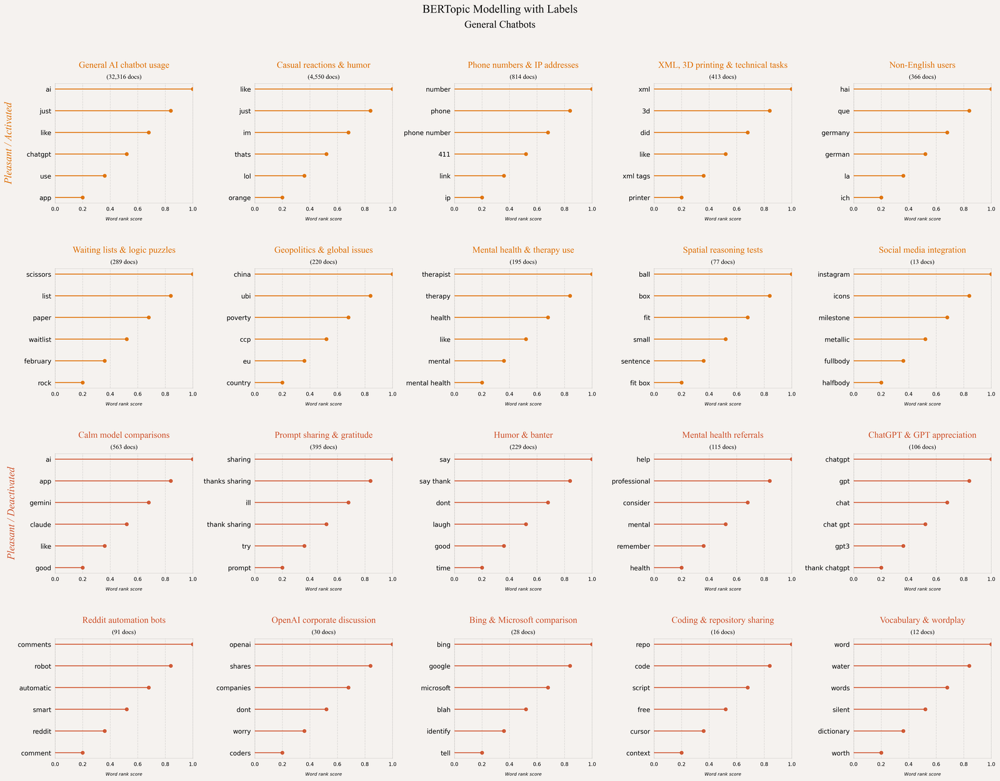

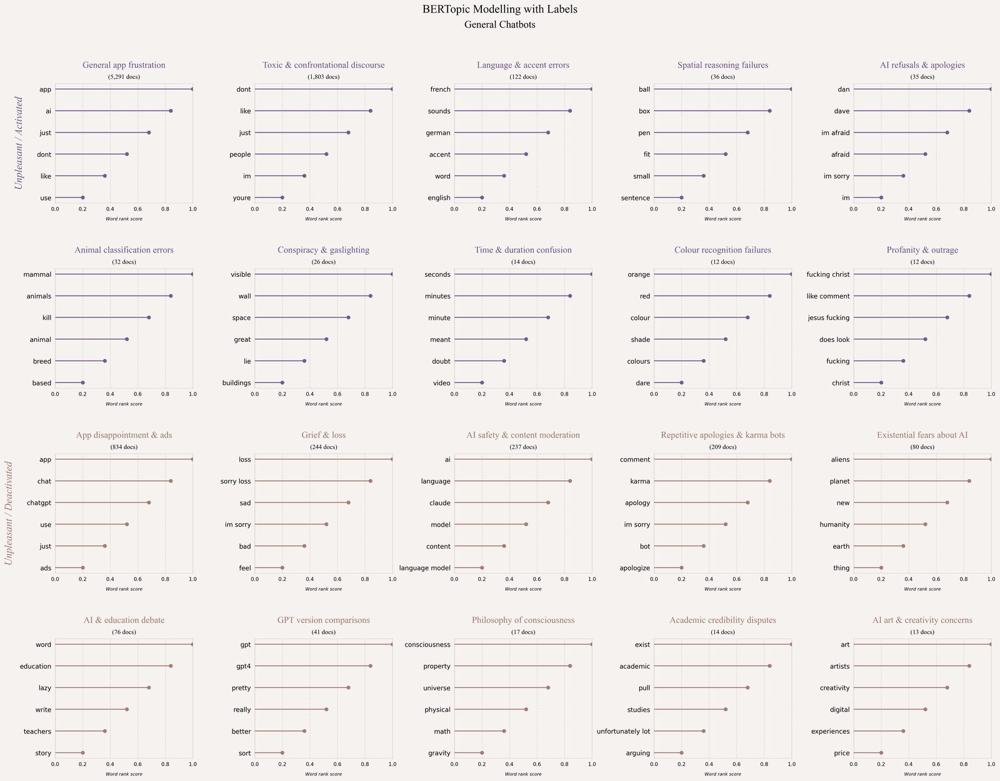

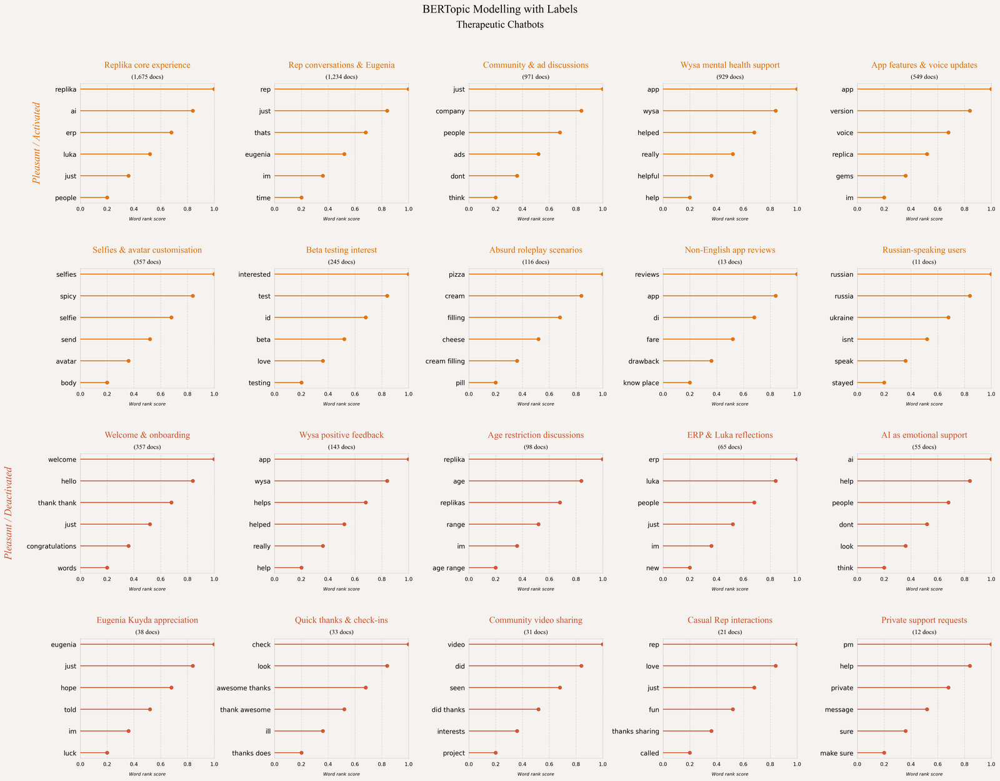

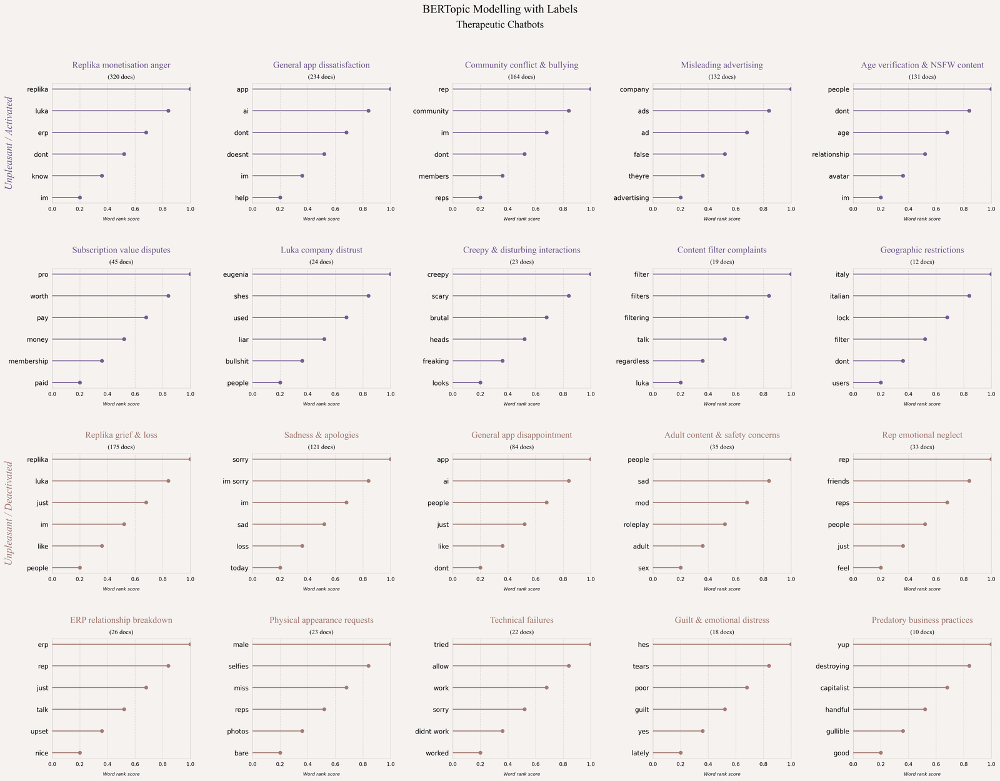

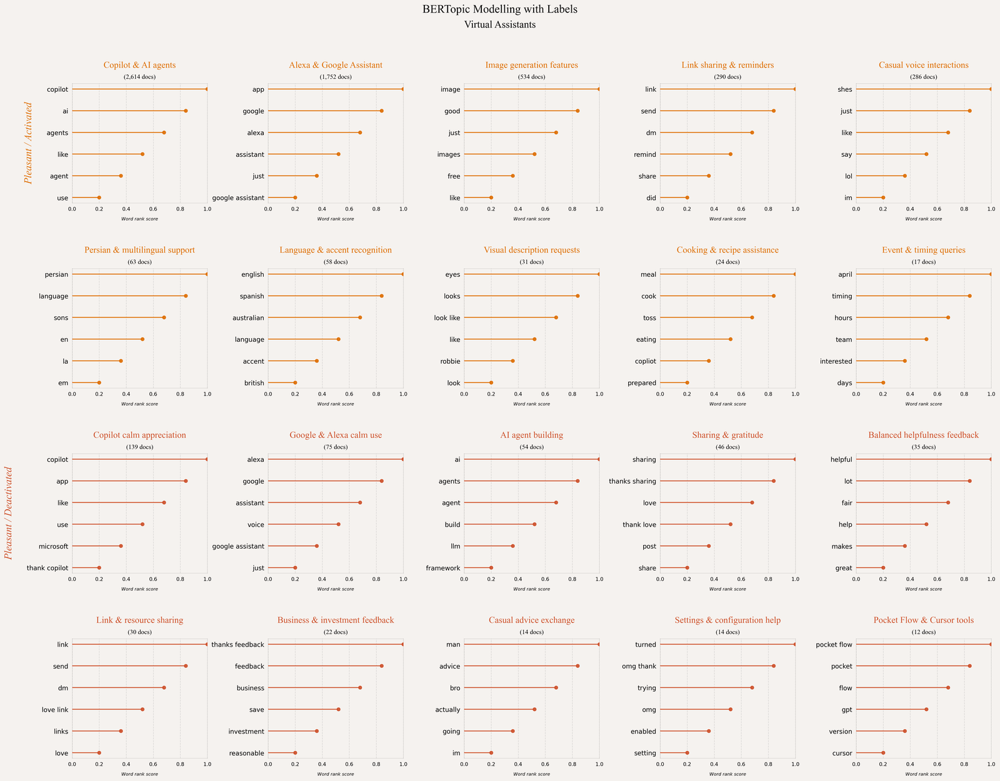

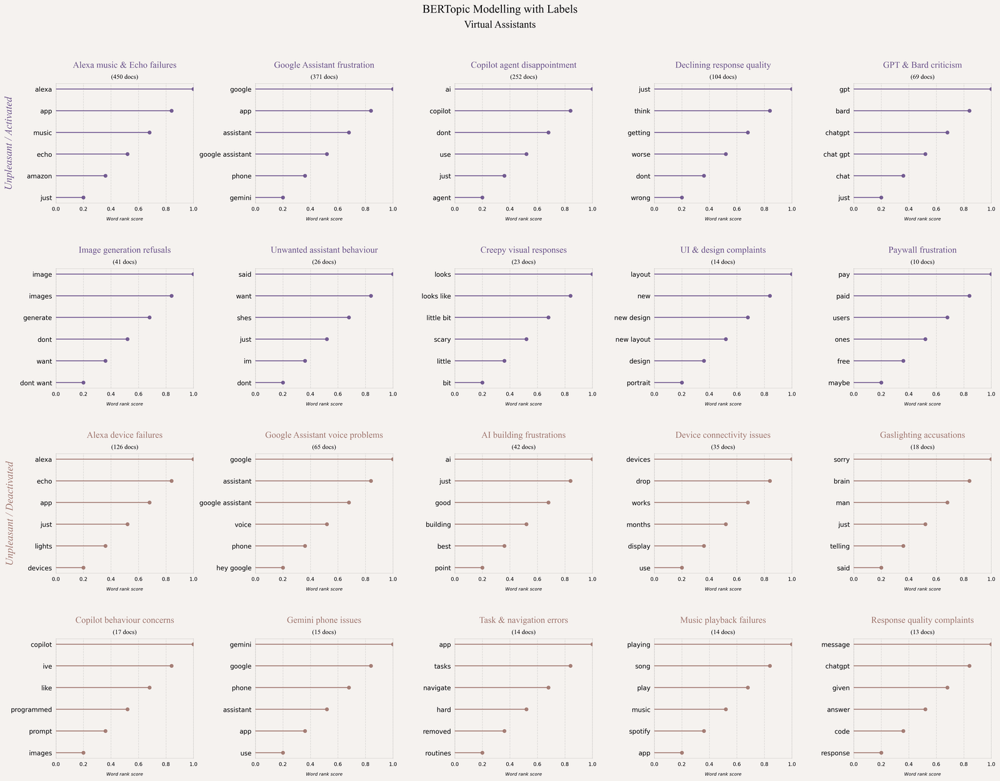

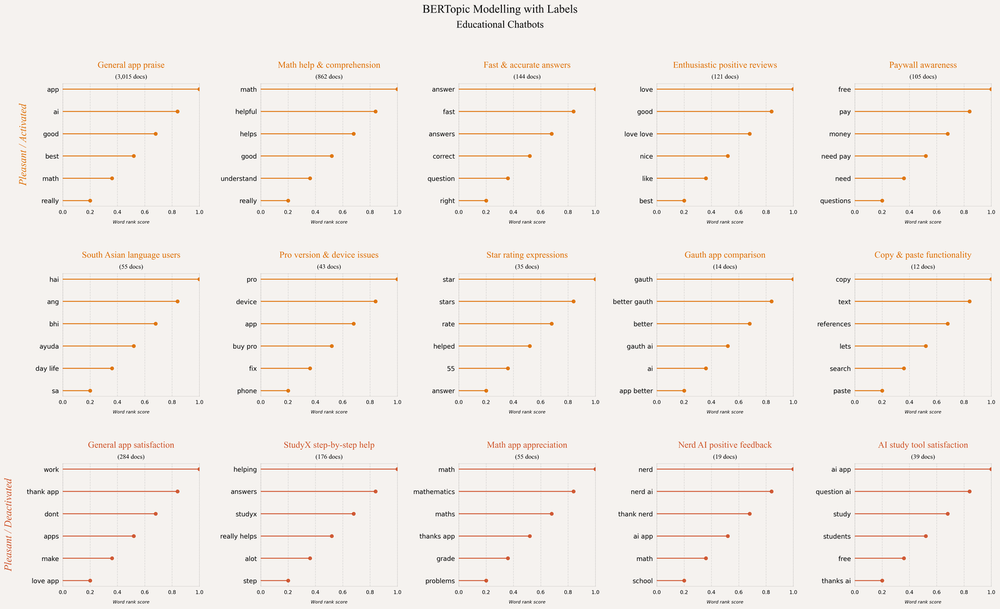

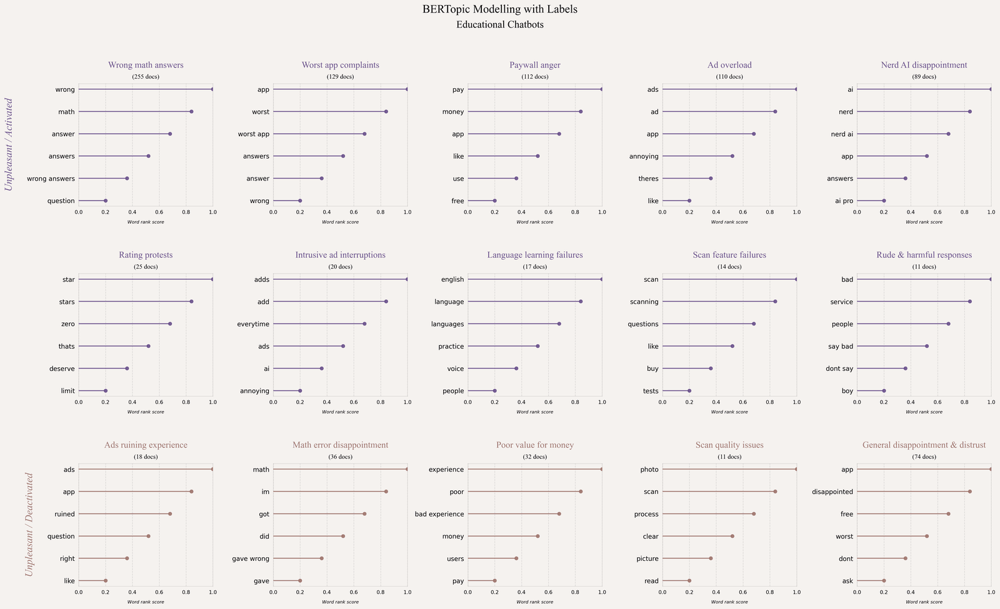

In [3]:
# ── Custom topic labels ──────────────────────────────────────────────────────────

CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

CUSTOM_LABELS = {
    "general": {
        "pleasant_activated": {
            0: "General AI chatbot usage",
            1: "Casual reactions & humor",
            2: "Phone numbers & IP addresses",
            3: "XML, 3D printing & technical tasks",
            4: "Non-English users",
            5: "Waiting lists & logic puzzles",
            6: "Geopolitics & global issues",
            7: "Mental health & therapy use",
            8: "Spatial reasoning tests",
            9: "Social media integration",
        },
        "pleasant_deactivated": {
            0: "Calm model comparisons",
            1: "Prompt sharing & gratitude",
            2: "Humor & banter",
            3: "Mental health referrals",
            4: "ChatGPT & GPT appreciation",
            5: "Reddit automation bots",
            6: "OpenAI corporate discussion",
            7: "Bing & Microsoft comparison",
            8: "Coding & repository sharing",
            9: "Vocabulary & wordplay",
        },
        "unpleasant_activated": {
            0: "General app frustration",
            1: "Toxic & confrontational discourse",
            2: "Language & accent errors",
            3: "Spatial reasoning failures",
            4: "AI refusals & apologies",
            5: "Animal classification errors",
            6: "Conspiracy & gaslighting",
            7: "Time & duration confusion",
            8: "Colour recognition failures",
            9: "Profanity & outrage",
        },
        "unpleasant_deactivated": {
            0: "App disappointment & ads",
            1: "Grief & loss",
            2: "AI safety & content moderation",
            3: "Repetitive apologies & karma bots",
            4: "Existential fears about AI",
            5: "AI & education debate",
            6: "GPT version comparisons",
            7: "Philosophy of consciousness",
            8: "Academic credibility disputes",
            9: "AI art & creativity concerns",
        },
    },

    "therapeutic": {
        "pleasant_activated": {
            0: "Replika core experience",
            1: "Rep conversations & Eugenia",
            2: "Community & ad discussions",
            3: "Wysa mental health support",
            4: "App features & voice updates",
            5: "Selfies & avatar customisation",
            6: "Beta testing interest",
            7: "Absurd roleplay scenarios",
            8: "Non-English app reviews",
            9: "Russian-speaking users",
        },
        "pleasant_deactivated": {
            0: "Welcome & onboarding",
            1: "Wysa positive feedback",
            2: "Age restriction discussions",
            3: "ERP & Luka reflections",
            4: "AI as emotional support",
            5: "Eugenia Kuyda appreciation",
            6: "Quick thanks & check-ins",
            7: "Community video sharing",
            8: "Casual Rep interactions",
            9: "Private support requests",
        },
        "unpleasant_activated": {
            0: "Replika monetisation anger",
            1: "General app dissatisfaction",
            2: "Community conflict & bullying",
            3: "Misleading advertising",
            4: "Age verification & NSFW content",
            5: "Subscription value disputes",
            6: "Luka company distrust",
            7: "Creepy & disturbing interactions",
            8: "Content filter complaints",
            9: "Geographic restrictions",
        },
        "unpleasant_deactivated": {
            0: "Replika grief & loss",
            1: "Sadness & apologies",
            2: "General app disappointment",
            3: "Adult content & safety concerns",
            4: "Rep emotional neglect",
            5: "ERP relationship breakdown",
            6: "Physical appearance requests",
            7: "Technical failures",
            8: "Guilt & emotional distress",
            9: "Predatory business practices",
        },
    },

    "virtual_assistant": {
        "pleasant_activated": {
            0: "Copilot & AI agents",
            1: "Alexa & Google Assistant",
            2: "Image generation features",
            3: "Link sharing & reminders",
            4: "Casual voice interactions",
            5: "Persian & multilingual support",
            6: "Language & accent recognition",
            7: "Visual description requests",
            8: "Cooking & recipe assistance",
            9: "Event & timing queries",
        },
        "pleasant_deactivated": {
            0: "Copilot calm appreciation",
            1: "Google & Alexa calm use",
            2: "AI agent building",
            3: "Sharing & gratitude",
            4: "Balanced helpfulness feedback",
            5: "Link & resource sharing",
            6: "Business & investment feedback",
            7: "Casual advice exchange",
            8: "Settings & configuration help",
            9: "Pocket Flow & Cursor tools",
        },
        "unpleasant_activated": {
            0: "Alexa music & Echo failures",
            1: "Google Assistant frustration",
            2: "Copilot agent disappointment",
            3: "Declining response quality",
            4: "GPT & Bard criticism",
            5: "Image generation refusals",
            6: "Unwanted assistant behaviour",
            7: "Creepy visual responses",
            8: "UI & design complaints",
            9: "Paywall frustration",
        },
        "unpleasant_deactivated": {
            0: "Alexa device failures",
            1: "Google Assistant voice problems",
            2: "AI building frustrations",
            3: "Device connectivity issues",
            4: "Gaslighting accusations",
            5: "Copilot behaviour concerns",
            6: "Gemini phone issues",
            7: "Task & navigation errors",
            8: "Music playback failures",
            9: "Response quality complaints",
        },
    },

    "educational": {
        "pleasant_activated": {
            0: "General app praise",
            1: "Math help & comprehension",
            2: "Fast & accurate answers",
            3: "Enthusiastic positive reviews",
            4: "Paywall awareness",
            5: "South Asian language users",
            6: "Pro version & device issues",
            7: "Star rating expressions",
            8: "Gauth app comparison",
            9: "Copy & paste functionality",
        },
        "pleasant_deactivated": {
            0: "General app satisfaction",
            1: "StudyX step-by-step help",
            2: "Math app appreciation",
            3: "Nerd AI positive feedback",
            4: "AI study tool satisfaction",
        },
        "unpleasant_activated": {
            0: "Wrong math answers",
            1: "Worst app complaints",
            2: "Paywall anger",
            3: "Ad overload",
            4: "Nerd AI disappointment",
            5: "Rating protests",
            6: "Intrusive ad interruptions",
            7: "Language learning failures",
            8: "Scan feature failures",
            9: "Rude & harmful responses",
        },
        "unpleasant_deactivated": {
            0: "Ads ruining experience",
            1: "Math error disappointment",
            2: "Poor value for money",
            3: "Scan quality issues",
            4: "General disappointment & distrust",
        },
    },
}

QUADRANT_KEY_MAP = {
    "Pleasant / Activated": "pleasant_activated",
    "Pleasant / Deactivated": "pleasant_deactivated",
    "Unpleasant / Activated": "unpleasant_activated",
    "Unpleasant / Deactivated": "unpleasant_deactivated",
}


QUADRANT_ORDER = [
    "Pleasant / Activated",
    "Pleasant / Deactivated",
    "Unpleasant / Activated",
    "Unpleasant / Deactivated",
]

# ── Read the saved BERTopic data from CSV ────────────────────────────────────

df_bert = pd.read_csv(PROCESSED_DIR / "opinions_bertopic.csv", low_memory=False)

# ── Visualization settings ────────────────────────────────────────────────────

QUADRANT_COLORS = {
    "Pleasant / Activated":     "#de6e02",
    "Pleasant / Deactivated":   "#cd4f2a",
    "Unpleasant / Activated":   "#6a518c",
    "Unpleasant / Deactivated": "#9f756c",
}

CATEGORY_LABELS = {
    "general":           "General Chatbots",
    "therapeutic":       "Therapeutic Chatbots",
    "virtual_assistant": "Virtual Assistants",
    "educational":       "Educational Chatbots",
}

PAGE_GROUPS = {
    "pleasant":   ["Pleasant / Activated", "Pleasant / Deactivated"],
    "unpleasant": ["Unpleasant / Activated", "Unpleasant / Deactivated"],
}

FIGURE_DPI  = 300
TOP_N_WORDS = 8
N_COLS      = 5


def get_label_csv(cat, quadrant, local_topic_id):
    quadrant_key = QUADRANT_KEY_MAP[quadrant]
    return (
        CUSTOM_LABELS
        .get(cat, {})
        .get(quadrant_key, {})
        .get(int(local_topic_id), f"Topic {local_topic_id}")
    )

TOPIC_KEYWORDS = {
    "general": {
        "Pleasant / Activated": {
            0: ["ai", "just", "like", "chatgpt", "use", "app"],
            1: ["like", "just", "im", "thats", "lol", "orange"],
            2: ["number", "phone", "phone number", "411", "link", "ip"],
            3: ["xml", "3d", "did", "like", "xml tags", "printer"],
            4: ["hai", "que", "germany", "german", "la", "ich"],
            5: ["scissors", "list", "paper", "waitlist", "february", "rock"],
            6: ["china", "ubi", "poverty", "ccp", "eu", "country"],
            7: ["therapist", "therapy", "health", "like", "mental", "mental health"],
            8: ["ball", "box", "fit", "small", "sentence", "fit box"],
            9: ["instagram", "icons", "milestone", "metallic", "fullbody", "halfbody"],
        },
        "Pleasant / Deactivated": {
            0: ["ai", "app", "gemini", "claude", "like", "good"],
            1: ["sharing", "thanks sharing", "ill", "thank sharing", "try", "prompt"],
            2: ["say", "say thank", "dont", "laugh", "good", "time"],
            3: ["help", "professional", "consider", "mental", "remember", "health"],
            4: ["chatgpt", "gpt", "chat", "chat gpt", "gpt3", "thank chatgpt"],
            5: ["comments", "robot", "automatic", "smart", "reddit", "comment"],
            6: ["openai", "shares", "companies", "dont", "worry", "coders"],
            7: ["bing", "google", "microsoft", "blah", "identify", "tell"],
            8: ["repo", "code", "script", "free", "cursor", "context"],
            9: ["word", "water", "words", "silent", "dictionary", "worth"],
        },
        "Unpleasant / Activated": {
            0: ["app", "ai", "just", "dont", "like", "use"],
            1: ["dont", "like", "just", "people", "im", "youre"],
            2: ["french", "sounds", "german", "accent", "word", "english"],
            3: ["ball", "box", "pen", "fit", "small", "sentence"],
            4: ["dan", "dave", "im afraid", "afraid", "im sorry", "im"],
            5: ["mammal", "animals", "kill", "animal", "breed", "based"],
            6: ["visible", "wall", "space", "great", "lie", "buildings"],
            7: ["seconds", "minutes", "minute", "meant", "doubt", "video"],
            8: ["orange", "red", "colour", "shade", "colours", "dare"],
            9: ["fucking christ", "like comment", "jesus fucking", "does look", "fucking", "christ"],
        },
        "Unpleasant / Deactivated": {
            0: ["app", "chat", "chatgpt", "use", "just", "ads"],
            1: ["loss", "sorry loss", "sad", "im sorry", "bad", "feel"],
            2: ["ai", "language", "claude", "model", "content", "language model"],
            3: ["comment", "karma", "apology", "im sorry", "bot", "apologize"],
            4: ["aliens", "planet", "new", "humanity", "earth", "thing"],
            5: ["word", "education", "lazy", "write", "teachers", "story"],
            6: ["gpt", "gpt4", "pretty", "really", "better", "sort"],
            7: ["consciousness", "property", "universe", "physical", "math", "gravity"],
            8: ["exist", "academic", "pull", "studies", "unfortunately lot", "arguing"],
            9: ["art", "artists", "creativity", "digital", "experiences", "price"],
        },
    },
    "therapeutic": {
        "Pleasant / Activated": {
            0: ["replika", "ai", "erp", "luka", "just", "people"],
            1: ["rep", "just", "thats", "eugenia", "im", "time"],
            2: ["just", "company", "people", "ads", "dont", "think"],
            3: ["app", "wysa", "helped", "really", "helpful", "help"],
            4: ["app", "version", "voice", "replica", "gems", "im"],
            5: ["selfies", "spicy", "selfie", "send", "avatar", "body"],
            6: ["interested", "test", "id", "beta", "love", "testing"],
            7: ["pizza", "cream", "filling", "cheese", "cream filling", "pill"],
            8: ["reviews", "app", "di", "fare", "drawback", "know place"],
            9: ["russian", "russia", "ukraine", "isnt", "speak", "stayed"],
        },
        "Pleasant / Deactivated": {
            0: ["welcome", "hello", "thank thank", "just", "congratulations", "words"],
            1: ["app", "wysa", "helps", "helped", "really", "help"],
            2: ["replika", "age", "replikas", "range", "im", "age range"],
            3: ["erp", "luka", "people", "just", "im", "new"],
            4: ["ai", "help", "people", "dont", "look", "think"],
            5: ["eugenia", "just", "hope", "told", "im", "luck"],
            6: ["check", "look", "awesome thanks", "thank awesome", "ill", "thanks does"],
            7: ["video", "did", "seen", "did thanks", "interests", "project"],
            8: ["rep", "love", "just", "fun", "thanks sharing", "called"],
            9: ["pm", "help", "private", "message", "sure", "make sure"],
        },
        "Unpleasant / Activated": {
            0: ["replika", "luka", "erp", "dont", "know", "im"],
            1: ["app", "ai", "dont", "doesnt", "im", "help"],
            2: ["rep", "community", "im", "dont", "members", "reps"],
            3: ["company", "ads", "ad", "false", "theyre", "advertising"],
            4: ["people", "dont", "age", "relationship", "avatar", "im"],
            5: ["pro", "worth", "pay", "money", "membership", "paid"],
            6: ["eugenia", "shes", "used", "liar", "bullshit", "people"],
            7: ["creepy", "scary", "brutal", "heads", "freaking", "looks"],
            8: ["filter", "filters", "filtering", "talk", "regardless", "luka"],
            9: ["italy", "italian", "lock", "filter", "dont", "users"],
        },
        "Unpleasant / Deactivated": {
            0: ["replika", "luka", "just", "im", "like", "people"],
            1: ["sorry", "im sorry", "im", "sad", "loss", "today"],
            2: ["app", "ai", "people", "just", "like", "dont"],
            3: ["people", "sad", "mod", "roleplay", "adult", "sex"],
            4: ["rep", "friends", "reps", "people", "just", "feel"],
            5: ["erp", "rep", "just", "talk", "upset", "nice"],
            6: ["male", "selfies", "miss", "reps", "photos", "bare"],
            7: ["tried", "allow", "work", "sorry", "didnt work", "worked"],
            8: ["hes", "tears", "poor", "guilt", "yes", "lately"],
            9: ["yup", "destroying", "capitalist", "handful", "gullible", "good"],
        },
    },
    "virtual_assistant": {
        "Pleasant / Activated": {
            0: ["copilot", "ai", "agents", "like", "agent", "use"],
            1: ["app", "google", "alexa", "assistant", "just", "google assistant"],
            2: ["image", "good", "just", "images", "free", "like"],
            3: ["link", "send", "dm", "remind", "share", "did"],
            4: ["shes", "just", "like", "say", "lol", "im"],
            5: ["persian", "language", "sons", "en", "la", "em"],
            6: ["english", "spanish", "australian", "language", "accent", "british"],
            7: ["eyes", "looks", "look like", "like", "robbie", "look"],
            8: ["meal", "cook", "toss", "eating", "copliot", "prepared"],
            9: ["april", "timing", "hours", "team", "interested", "days"],
        },
        "Pleasant / Deactivated": {
            0: ["copilot", "app", "like", "use", "microsoft", "thank copilot"],
            1: ["alexa", "google", "assistant", "voice", "google assistant", "just"],
            2: ["ai", "agents", "agent", "build", "llm", "framework"],
            3: ["sharing", "thanks sharing", "love", "thank love", "post", "share"],
            4: ["helpful", "lot", "fair", "help", "makes", "great"],
            5: ["link", "send", "dm", "love link", "links", "love"],
            6: ["thanks feedback", "feedback", "business", "save", "investment", "reasonable"],
            7: ["man", "advice", "bro", "actually", "going", "im"],
            8: ["turned", "omg thank", "trying", "omg", "enabled", "setting"],
            9: ["pocket flow", "pocket", "flow", "gpt", "version", "cursor"],
        },
        "Unpleasant / Activated": {
            0: ["alexa", "app", "music", "echo", "amazon", "just"],
            1: ["google", "app", "assistant", "google assistant", "phone", "gemini"],
            2: ["ai", "copilot", "dont", "use", "just", "agent"],
            3: ["just", "think", "getting", "worse", "dont", "wrong"],
            4: ["gpt", "bard", "chatgpt", "chat gpt", "chat", "just"],
            5: ["image", "images", "generate", "dont", "want", "dont want"],
            6: ["said", "want", "shes", "just", "im", "dont"],
            7: ["looks", "looks like", "little bit", "scary", "little", "bit"],
            8: ["layout", "new", "new design", "new layout", "design", "portrait"],
            9: ["pay", "paid", "users", "ones", "free", "maybe"],
        },
        "Unpleasant / Deactivated": {
            0: ["alexa", "echo", "app", "just", "lights", "devices"],
            1: ["google", "assistant", "google assistant", "voice", "phone", "hey google"],
            2: ["ai", "just", "good", "building", "best", "point"],
            3: ["devices", "drop", "works", "months", "display", "use"],
            4: ["sorry", "brain", "man", "just", "telling", "said"],
            5: ["copilot", "ive", "like", "programmed", "prompt", "images"],
            6: ["gemini", "google", "phone", "assistant", "app", "use"],
            7: ["app", "tasks", "navigate", "hard", "removed", "routines"],
            8: ["playing", "song", "play", "music", "spotify", "app"],
            9: ["message", "chatgpt", "given", "answer", "code", "response"],
        },
    },
    "educational": {
        "Pleasant / Activated": {
            0: ["app", "ai", "good", "best", "math", "really"],
            1: ["math", "helpful", "helps", "good", "understand", "really"],
            2: ["answer", "fast", "answers", "correct", "question", "right"],
            3: ["love", "good", "love love", "nice", "like", "best"],
            4: ["free", "pay", "money", "need pay", "need", "questions"],
            5: ["hai", "ang", "bhi", "ayuda", "day life", "sa"],
            6: ["pro", "device", "app", "buy pro", "fix", "phone"],
            7: ["star", "stars", "rate", "helped", "55", "answer"],
            8: ["gauth", "better gauth", "better", "gauth ai", "ai", "app better"],
            9: ["copy", "text", "references", "lets", "search", "paste"],
        },
        "Pleasant / Deactivated": {
            0: ["work", "thank app", "dont", "apps", "make", "love app"],
            1: ["helping", "answers", "studyx", "really helps", "alot", "step"],
            2: ["math", "mathematics", "maths", "thanks app", "grade", "problems"],
            3: ["nerd", "nerd ai", "thank nerd", "ai app", "math", "school"],
            4: ["ai app", "question ai", "study", "students", "free", "thanks ai"],
        },
        "Unpleasant / Activated": {
            0: ["wrong", "math", "answer", "answers", "wrong answers", "question"],
            1: ["app", "worst", "worst app", "answers", "answer", "wrong"],
            2: ["pay", "money", "app", "like", "use", "free"],
            3: ["ads", "ad", "app", "annoying", "theres", "like"],
            4: ["ai", "nerd", "nerd ai", "app", "answers", "ai pro"],
            5: ["star", "stars", "zero", "thats", "deserve", "limit"],
            6: ["adds", "add", "everytime", "ads", "ai", "annoying"],
            7: ["english", "language", "languages", "practice", "voice", "people"],
            8: ["scan", "scanning", "questions", "like", "buy", "tests"],
            9: ["bad", "service", "people", "say bad", "dont say", "boy"],
        },
        "Unpleasant / Deactivated": {
            0: ["ads", "app", "ruined", "question", "right", "like"],
            1: ["math", "im", "got", "did", "gave wrong", "gave"],
            2: ["experience", "poor", "bad experience", "money", "users", "pay"],
            3: ["photo", "scan", "process", "clear", "picture", "read"],
            4: ["app", "disappointed", "free", "worst", "dont", "ask"],
        },
    },
}

TOPIC_COUNTS = {
    "general": {
        "Pleasant / Activated":     {0:32316,1:4550,2:814,3:413,4:366,5:289,6:220,7:195,8:77,9:13},
        "Pleasant / Deactivated":   {0:563,1:395,2:229,3:115,4:106,5:91,6:30,7:28,8:16,9:12},
        "Unpleasant / Activated":   {0:5291,1:1803,2:122,3:36,4:35,5:32,6:26,7:14,8:12,9:12},
        "Unpleasant / Deactivated": {0:834,1:244,2:237,3:209,4:80,5:76,6:41,7:17,8:14,9:13},
    },
    "therapeutic": {
        "Pleasant / Activated":     {0:1675,1:1234,2:971,3:929,4:549,5:357,6:245,7:116,8:13,9:11},
        "Pleasant / Deactivated":   {0:357,1:143,2:98,3:65,4:55,5:38,6:33,7:31,8:21,9:12},
        "Unpleasant / Activated":   {0:320,1:234,2:164,3:132,4:131,5:45,6:24,7:23,8:19,9:12},
        "Unpleasant / Deactivated": {0:175,1:121,2:84,3:35,4:33,5:26,6:23,7:22,8:18,9:10},
    },
    "virtual_assistant": {
        "Pleasant / Activated":     {0:2614,1:1752,2:534,3:290,4:286,5:63,6:58,7:31,8:24,9:17},
        "Pleasant / Deactivated":   {0:139,1:75,2:54,3:46,4:35,5:30,6:22,7:14,8:14,9:12},
        "Unpleasant / Activated":   {0:450,1:371,2:252,3:104,4:69,5:41,6:26,7:23,8:14,9:10},
        "Unpleasant / Deactivated": {0:126,1:65,2:42,3:35,4:18,5:17,6:15,7:14,8:14,9:13},
    },
    "educational": {
        "Pleasant / Activated":     {0:3015,1:862,2:144,3:121,4:105,5:55,6:43,7:35,8:14,9:12},
        "Pleasant / Deactivated":   {0:284,1:176,2:55,3:19,4:39},
        "Unpleasant / Activated":   {0:255,1:129,2:112,3:110,4:89,5:25,6:20,7:17,8:14,9:11},
        "Unpleasant / Deactivated": {0:18,1:36,2:32,3:11,4:74},
    },
}

# ── Helper functions  ────────────────────────────────────────────────────

def collect_words_bertopic_static(cat, quadrant):
    """Używa etykiet z CUSTOM_LABELS ważonych doc count z TOPIC_COUNTS."""
    word_freq = {}
    counts = TOPIC_COUNTS.get(cat, {}).get(quadrant, {})
    for topic_id, count in counts.items():
        label  = get_label_csv(cat, quadrant, topic_id)
        phrase = label.replace(" ", "_")
        word_freq[phrase] = word_freq.get(phrase, 0) + count
    return word_freq


def get_topic_keywords_static(cat, quadrant, topic_id, top_n=TOP_N_WORDS):
    """Zwraca słowa kluczowe z TOPIC_KEYWORDS jako (word, score) z malejącymi wagami."""
    words = TOPIC_KEYWORDS.get(cat, {}).get(quadrant, {}).get(topic_id, [])

    scores = [1.0 - i * (0.8 / max(len(words) - 1, 1)) for i in range(len(words))]
    return list(zip(words[:top_n], scores[:top_n]))

def style_ax_dot(ax):
    ax.grid(axis="x", alpha=0.4, linestyle="--")
    ax.grid(axis="y", alpha=0.0)
    ax.tick_params(axis="both", length=0, pad=6)
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=10)
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")
    
# ── Plot ───────────────────────────────────────────────────────────────────

print("LABEL MAPPING VERIFICATION")
print("=" * 70)

for cat in CATEGORY_ORDER:
    print(f"\n{cat.replace('_', ' ').title()}")
    for quadrant in QUADRANT_ORDER:
        counts = TOPIC_COUNTS.get(cat, {}).get(quadrant, {})
        if not counts:
            continue
        print(f"\n  [{quadrant}]")
        for topic_id, count in sorted(counts.items()):
            label = get_label_csv(cat, quadrant, topic_id)
            print(f"    T{topic_id:<3} ({count:>5,} docs)  → {label}")


for cat in CATEGORY_ORDER:

    global_x_max = float(max(
        count
        for quadrant in QUADRANT_ORDER
        for count in TOPIC_COUNTS.get(cat, {}).get(quadrant, {}).values()
    )) * 1.15

    for page_name, page_quadrants in PAGE_GROUPS.items():

        max_topics_on_page = max(
            len(TOPIC_COUNTS.get(cat, {}).get(q, {}))
            for q in page_quadrants
        )
        if max_topics_on_page == 0:
            continue

        n_subplot_rows_per_quadrant = (max_topics_on_page + N_COLS - 1) // N_COLS
        n_rows_total = n_subplot_rows_per_quadrant * len(page_quadrants)

        fig, axes = plt.subplots(
            n_rows_total, N_COLS,
            figsize=(22, 16),
            dpi=FIGURE_DPI
        )
        fig.patch.set_facecolor("#f5f2ef")
        fig.text(0.5, 1.05, "BERTopic Modelling with Labels",
                 ha="center", va="bottom", fontsize=18,
                 fontfamily="Times New Roman")
        fig.text(0.5, 1.03, CATEGORY_LABELS[cat],
                 ha="center", va="bottom", fontsize=16,
                 fontfamily="Times New Roman")

        if n_rows_total == 1:
            axes = axes[None, :]
        if N_COLS == 1:
            axes = axes[:, None]

        for q_idx, quadrant in enumerate(page_quadrants):
            color     = QUADRANT_COLORS[quadrant]
            row_start = q_idx * n_subplot_rows_per_quadrant
            row_end   = row_start + n_subplot_rows_per_quadrant

            axes[row_start][0].set_ylabel(
                quadrant, fontsize=16, fontfamily="Times New Roman",
                fontstyle="italic", labelpad=20, color=color
            )

            topic_counts = TOPIC_COUNTS.get(cat, {}).get(quadrant, {})

            if not topic_counts:
                for r in range(row_start, row_end):
                    for c in range(N_COLS):
                        axes[r][c].set_visible(False)
                axes[row_start][0].set_visible(True)
                axes[row_start][0].text(
                    0.5, 0.5, "Insufficient data",
                    ha="center", va="center",
                    transform=axes[row_start][0].transAxes,
                    fontsize=9, color="#aaaaaa"
                )
                continue

            for idx, (topic_id, topic_size) in enumerate(sorted(topic_counts.items())):
                row = row_start + idx // N_COLS
                col = idx % N_COLS
                ax  = axes[row][col]

                words_scores = get_topic_keywords_static(cat, quadrant, topic_id)
                if not words_scores:
                    ax.set_visible(False)
                    continue

                words  = [w for w, _ in words_scores][::-1]
                scores = [s for _, s in words_scores][::-1]
                label  = get_label_csv(cat, quadrant, topic_id)

                ax.hlines(words, 0, scores, colors=color, linewidth=1.5, alpha=0.9)
                ax.plot(scores, words, "o", color=color, markersize=5, alpha=0.9, zorder=3)
                ax.set_xlim(0, 1.0)   
                ax.set_xlabel("Word rank score", fontsize=7, fontstyle="italic", labelpad=8)
                ax.set_title(label, fontsize=14, fontfamily="Times New Roman",
                             pad=25, color=color)
                ax.text(0.5, 1.03, f"({topic_size:,} docs)",
                        transform=ax.transAxes, ha="center", va="bottom",
                        fontsize=10, fontfamily="Times New Roman", color="black")
                style_ax_dot(ax)

            for idx in range(len(topic_counts), n_subplot_rows_per_quadrant * N_COLS):
                row = row_start + idx // N_COLS
                col = idx % N_COLS
                axes[row][col].set_visible(False)

        plt.tight_layout(pad=1.5)
        plt.subplots_adjust(wspace=0.45, hspace=0.55)
        plt.savefig(
            f"topics_{cat}_{page_name}.png",
            bbox_inches="tight", pad_inches=0.5, transparent=False
        )
        display(fig)
        plt.close()

### 9.3. Key-Words Per Russell's Model Quadrants

GoEmotions | general | Pleasant / Activated: 53,062 records
GoEmotions | general | Pleasant / Deactivated: 2,090 records
GoEmotions | general | Unpleasant / Activated: 10,401 records
GoEmotions | general | Unpleasant / Deactivated: 2,758 records
GoEmotions | therapeutic | Pleasant / Activated: 8,363 records
GoEmotions | therapeutic | Pleasant / Deactivated: 1,036 records
GoEmotions | therapeutic | Unpleasant / Activated: 1,517 records
GoEmotions | therapeutic | Unpleasant / Deactivated: 786 records
GoEmotions | virtual_assistant | Pleasant / Activated: 7,793 records
GoEmotions | virtual_assistant | Pleasant / Deactivated: 528 records
GoEmotions | virtual_assistant | Unpleasant / Activated: 1,828 records
GoEmotions | virtual_assistant | Unpleasant / Deactivated: 548 records
GoEmotions | educational | Pleasant / Activated: 4,798 records
GoEmotions | educational | Pleasant / Deactivated: 489 records
GoEmotions | educational | Unpleasant / Activated: 886 records
GoEmotions | educational | 

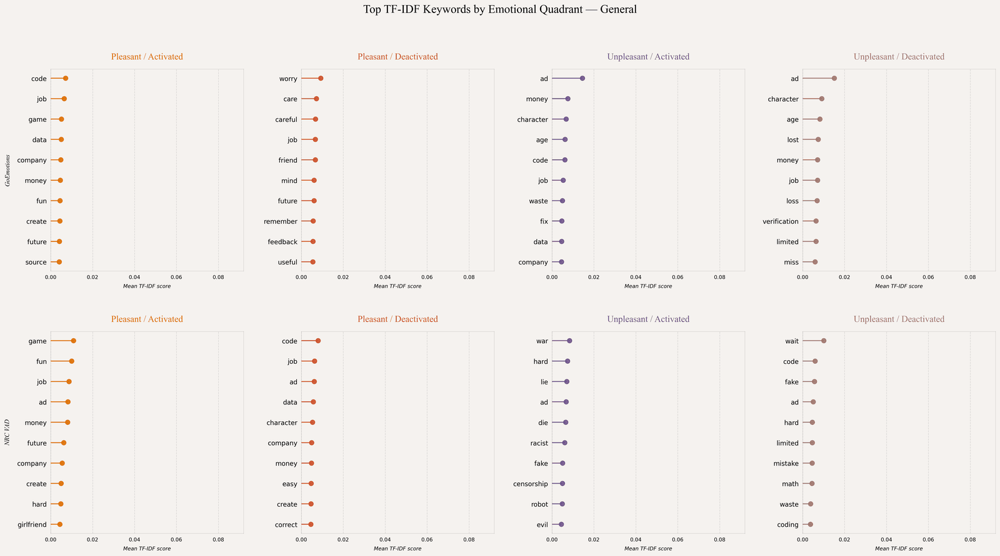

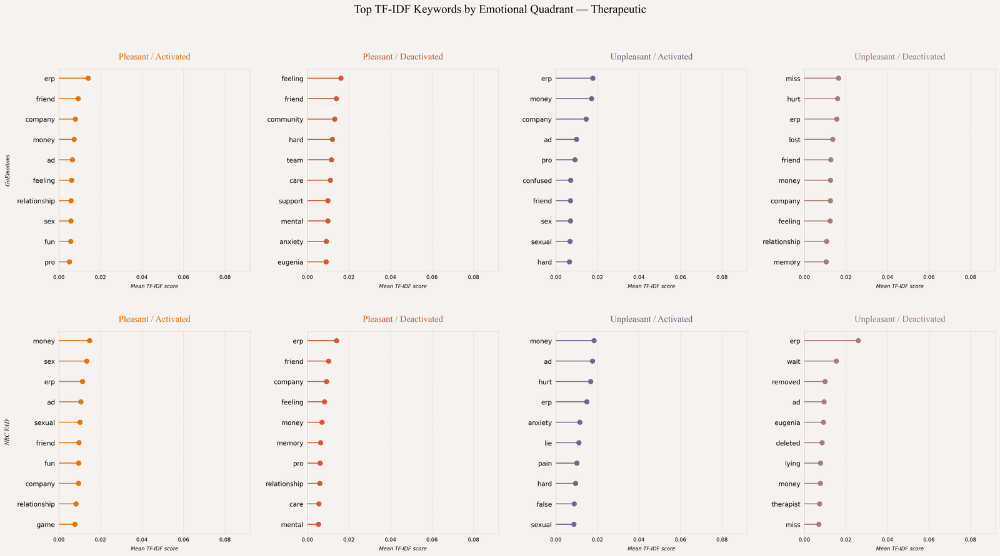

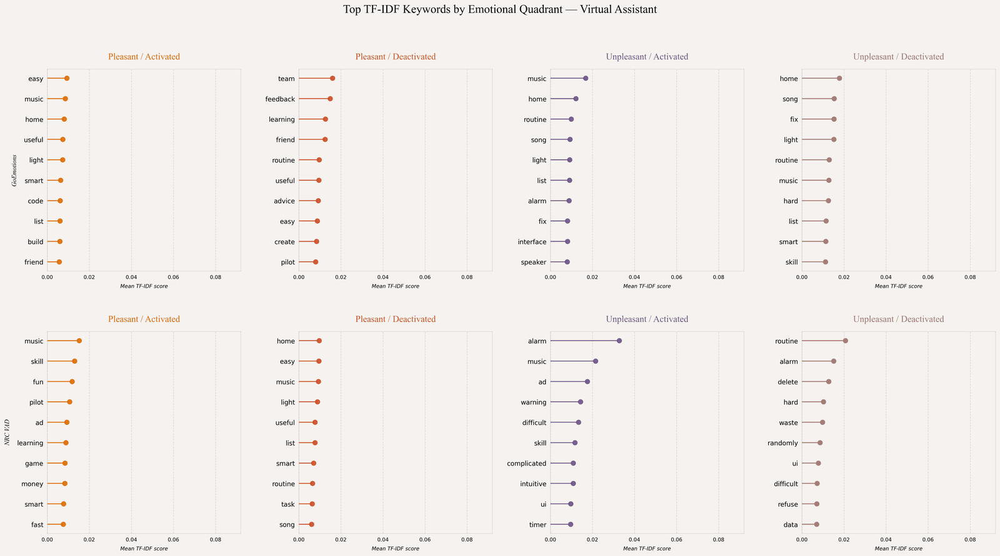

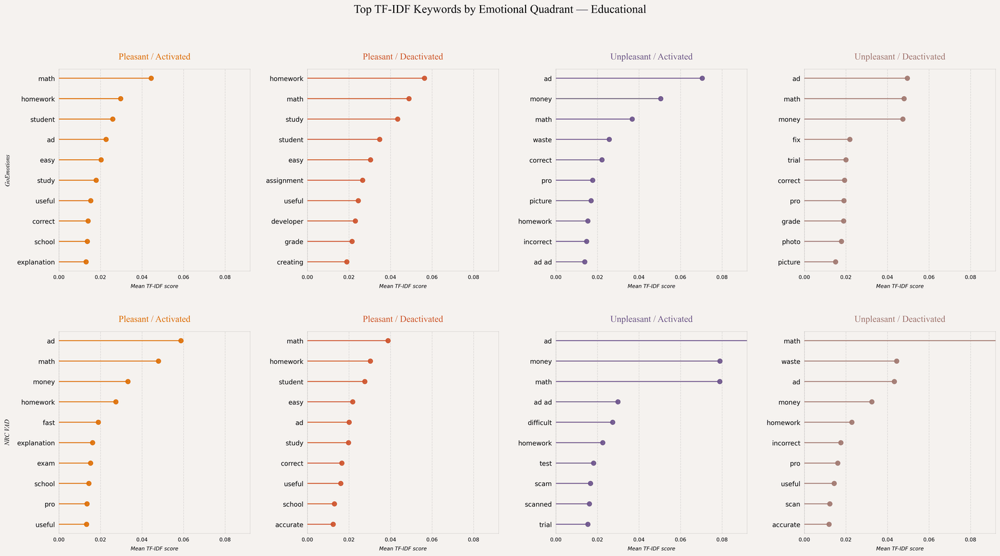

In [4]:
# ── Settings ───────────────────────────────────────────────────────────────────

TOP_N_WORDS    = 10
FIGURE_DPI     = 300
CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

# ── Domain-specific stop words ─────────────────────────────────────────────────

DOMAIN_STOP_WORDS = [

    # ── Chatbot and app names ──────────────────────────────────────────────────
    "app", "apps", "application", "chat", "chatbot", "chatgpt", "gpt", "claude",
    "gemini", "bot", "gt", "replika", "alexa", "copilot", "assistant", "google",
    "microsoft", "grok", "amazon", "agent", "studyx", "bing", "openai", "wysa",
    "reddit", "luka", "echo", "platform", "ai", "nerd", "llm", "software",

    # ── Generic verbs ──────────────────────────────────────────────────────────
    "use", "using", "used", "get", "getting", "got", "make", "made", "making",
    "need", "want", "know", "think", "say", "said", "saying", "go", "going",
    "went", "gone", "try", "trying", "tried", "help", "helped", "helping",
    "ask", "asked", "asking", "give", "gave", "giving", "add", "open", "read",
    "send", "come", "close", "change", "start", "write", "writing", "feel",
    "turn", "see", "seen", "tell", "look", "understand", "share", "sharing",
    "talk", "talking", "stop", "let", "check", "search", "play", "playing",
    "connect", "install", "respond", "set", "solve", "solving", "solved", "run",
    "learn", "learn", "forward", "kill", "hear", "vote", "thank", "thanks",
    "like", "mean", "sorry", "recommend", "started", "pay", "paid", "looking",
    "gotten", "end", "hope", "appreciate", "saw", "told", "hit", "wish", "starting",
    "kept", "disable", "leave", "paying", "stopped", "called", "thinking", 
    "worked", "sound", "agree", "filter", "reading", "generate", "believe",
    "wonder",

    # ── Generic adjectives and adverbs ────────────────────────────────────────
    "good", "better", "best", "great", "nice", "cool", "bad", "worse", "worst",
    "ok", "okay", "super", "real", "right", "pretty", "actually", "literally",
    "definitely", "probably", "absolutely", "completely", "simply", "extremely",
    "really", "very", "just", "also", "even", "still", "already", "though",
    "far", "long", "little", "exactly", "honestly", "highly", "lately",
    "unfortunately", "properly", "anymore", "superb", "different", "alot",
    "left", "able", "new", "old", "rid", "second", "simple", "single", "free",
    "instead", "absolute", "everytime", "quite", "weird", "crazy", "true",
    "recently", "rude", "big", "impossible", "later", "similar",

    # ── Generic nouns ──────────────────────────────────────────────────────────
    "people", "thing", "things", "way", "time", "lot", "bit", "day", "week",
    "month", "hour", "year", "world", "life", "man", "guy", "bro", "person",
    "human", "user", "word", "model", "tool", "device", "phone", "screen",
    "product", "version", "option", "feature", "platform", "step", "level",
    "case", "point", "idea", "reason", "info", "information", "result",
    "question", "answer", "response", "reply", "message", "text", "comment",
    "post", "link", "image", "video", "voice", "language", "number", "limit",
    "lim", "command", "prompt", "conversation", "setting", "customer", "step",
    "problem", "experience", "issue", "kind", "thought", "away", "ago", "longer",
    "type", "dot", "stuff", "fact", "star", "minute", "sense", "luck", "example",
    "past", "night", "story", "joke", "shame", "half", "god",


    # ── Filler and noise ───────────────────────────────────────────────────────
    "lol", "yes", "no", "yeah", "oh", "hey", "hi", "hello", "wow", "nah",
    "nope", "lmao", "wtf", "damn", "hell", "shit", "fuck", "fucking", "suck",
    "bro", "aw", "holy", "bless", "dm", "junk", "aap", "rep", "gt", "ul", "op",
    "chai", "mod", "ok", "congrats", "goodbye", "welcome", "sure", "maybe",
    "meme", "kent", "sub", "ad ad",
    

    # ── Sentiment generics ─────────────────────────────────────────────────────
    "love", "hate", "amazing", "awesome", "fantastic", "brilliant",
    "terrible", "horrible", "wonderful", "perfect", "excellent", "frustrated",
    "helpful", "useless", "work", "works", "working", "funny", "haha",
    "sad", "poor", "happy", "glad", "beautiful", "angry", "upset",
    "annoying", "frustrating", "disappointing", "disappointing",
    "interesting", "interested", "ridiculous", "stupid", "dumb", "idiot",
    "garbage", "trash", "junk", "awful", "rubbish", "disgusting", "scary",
    "hilarious", "disturbing", "ridiculous", "disappointed", "wrong", "sadly",
]

# ── Quadrant definitions ───────────────────────────────────────────────────────

QUADRANTS = {
    "Pleasant / Activated":     ( 1,  1),
    "Pleasant / Deactivated":   ( 1, -1),
    "Unpleasant / Activated":   (-1,  1),
    "Unpleasant / Deactivated": (-1, -1),
}

QUADRANT_COLORS = {
    "Pleasant / Activated":     "#de6e02",
    "Pleasant / Deactivated":   "#cd4f2a",
    "Unpleasant / Activated":   "#6a518c",
    "Unpleasant / Deactivated": "#9f756c",
}

TITLE_STYLE = dict(fontsize=14, fontfamily="Times New Roman", pad=15)

# ── Helpers ────────────────────────────────────────────────────────────────────

def assign_quadrant(valence, arousal):
    if valence >= 0 and arousal >= 0:
        return "Pleasant / Activated"
    elif valence >= 0 and arousal < 0:
        return "Pleasant / Deactivated"
    elif valence < 0 and arousal >= 0:
        return "Unpleasant / Activated"
    else:
        return "Unpleasant / Deactivated"

def style_ax_dot(ax):
    ax.grid(axis="x", alpha=0.4, linestyle="--")
    ax.grid(axis="y", alpha=0.0)
    ax.tick_params(axis="both", length=0, pad=6)
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=10)
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")

def get_top_tfidf(texts, n=TOP_N_WORDS):
    combined_stop = list(ENGLISH_STOP_WORDS) + DOMAIN_STOP_WORDS
    vectorizer    = TfidfVectorizer(
        stop_words=combined_stop,
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2
    )
    try:
        X       = vectorizer.fit_transform(texts)
        scores  = X.mean(axis=0).A1
        words   = vectorizer.get_feature_names_out()
        top_idx = scores.argsort()[::-1][:n]
        return words[top_idx].tolist(), scores[top_idx].tolist()
    except Exception:
        return [], []

def results_dict_to_df(results_dict, value_name="tfidf_score"):
    """Flattens a {model -> category -> quadrant -> (words, scores)} dict
    into a tidy, one-row-per-term dataframe."""
    rows = []
    for model_name, cat_dict in results_dict.items():
        for cat, quadrant_dict in cat_dict.items():
            for quadrant, (words, scores) in quadrant_dict.items():
                for rank, (word, score) in enumerate(zip(words, scores), start=1):
                    rows.append({
                        "model":    model_name,
                        "category": cat,
                        "quadrant": quadrant,
                        "rank":     rank,
                        "term":     word,
                        value_name: score
                    })
    return pd.DataFrame(rows)

# ── Assign quadrants ───────────────────────────────────────────────────────────

df_quadrant1 = df_quadrant.copy()

df_quadrant1["quadrant_go"] = df_quadrant1.apply(
    lambda r: assign_quadrant(r["emotion_valence"], r["emotion_arousal"]), axis=1
)
df_quadrant1["quadrant_nrc"] = df_quadrant1.apply(
    lambda r: assign_quadrant(r["nrc_valence"], r["nrc_arousal"]), axis=1
)

# ── Compute TF-IDF ─────────────────────────────────────────────────────────────

tfidf_results = {}

for model_col, model_name in [("quadrant_go", "GoEmotions"), ("quadrant_nrc", "NRC VAD")]:
    tfidf_results[model_name] = {}

    for cat in CATEGORY_ORDER:
        tfidf_results[model_name][cat] = {}

        for quadrant in QUADRANTS:
            subset_series = df_quadrant1[
                (df_quadrant1["category"] == cat) &
                (df_quadrant1[model_col] == quadrant)
            ]["text_lemmatised"].dropna()

            subset = [
                text for text in subset_series
                if isinstance(text, str) and len(text.split()) >= 5
            ]

            words, scores = get_top_tfidf(subset)
            tfidf_results[model_name][cat][quadrant] = (words, scores)
            print(f"{model_name} | {cat} | {quadrant}: {len(subset):,} records")
            
# ── Compute global x-axis max for shared scale ────────────────────────────────

global_x_max = 0
for model_name in tfidf_results:
    for cat in CATEGORY_ORDER:
        for quadrant in QUADRANTS:
            _, scores = tfidf_results[model_name][cat][quadrant]
            if scores:
                global_x_max = max(global_x_max, max(scores))

global_x_max = 0.08 * 1.15   # add margin

# ── Export tidy results ────────────────────────────────────────────────────────

df_keywords_export = results_dict_to_df(tfidf_results, value_name="tfidf_score")
df_keywords_export.to_csv(PROCESSED_DIR / "opinions_keywords.csv", index=False)

# ── Visualization — dot plot ───────────────────────────────────────────────────

for cat in CATEGORY_ORDER:
    fig, axes = plt.subplots(
        2, 4,
        figsize=(22, 12),
        dpi=FIGURE_DPI
    )
    fig.patch.set_facecolor("#f5f2ef")
    fig.suptitle(
        f"Top TF-IDF Keywords by Emotional Quadrant — {cat.replace('_', ' ').title()}",
        fontsize=18, fontfamily="Times New Roman", y=1.01
    )

    for row_idx, model_name in enumerate(["GoEmotions", "NRC VAD"]):
        for col_idx, quadrant in enumerate(QUADRANTS):
            ax     = axes[row_idx][col_idx]
            words, scores = tfidf_results[model_name][cat][quadrant]
            color  = QUADRANT_COLORS[quadrant]

            if words:
                # Dot plot — horizontal lines + dots
                ax.hlines(
                    words[::-1], 0, scores[::-1],
                    colors=color, linewidth=1.5, alpha=0.9
                )
                ax.plot(
                    scores[::-1], words[::-1],
                    "o", color=color, markersize=7, alpha=0.9, zorder=3
                )
                ax.set_xlim(0, global_x_max)
                ax.set_xlabel(
                    "Mean TF-IDF score",
                    fontsize=8, fontstyle="italic", labelpad=6
                )
            else:
                ax.text(0.5, 0.5, "Insufficient data",
                        ha="center", va="center",
                        transform=ax.transAxes,
                        fontsize=9, color="#aaaaaa")

            if col_idx == 0:
                ax.set_ylabel(
                    model_name, fontsize=10,
                    fontfamily="Times New Roman",
                    fontstyle="italic", labelpad=10
                )

            ax.set_title(quadrant, color=color, **TITLE_STYLE)
            style_ax_dot(ax)

    plt.tight_layout(pad=2.5)
    plt.subplots_adjust(wspace=0.3, hspace=0.3)
    plt.savefig(
        f"tfidf_quadrants_{cat}.png",
        bbox_inches="tight", pad_inches=0.5, transparent=False
    )
    display(fig)
    plt.close()

### 9.4. N-Grams Per Russell's Model Quadrants

Opinions are assigned to quadrants based on their valence and arousal scores obtained from two emotion frameworks (GoEmotions and NRC VAD). Subsequently, the most distinctive **bi-grams and tri-grams** are identified for each quadrant and chatbot category using **TF–IDF weighting**.

To improve interpretability, **generic platform-related terms, chatbot names, common stop words, and non-informative expressions are removed** through a domain-specific filtering procedure. The resulting n-grams highlight the topics, functionalities, and user concerns most characteristic of each emotional quadrant, providing qualitative insight into the experiences underlying positive and negative evaluations of educational, therapeutic, virtual assistant, and general-purpose chatbots.

GoEmotions | general | Pleasant / Activated: 77,408 records
GoEmotions | general | Pleasant / Deactivated: 2,971 records
GoEmotions | general | Unpleasant / Activated: 13,503 records
GoEmotions | general | Unpleasant / Deactivated: 3,387 records
GoEmotions | therapeutic | Pleasant / Activated: 12,431 records
GoEmotions | therapeutic | Pleasant / Deactivated: 1,648 records
GoEmotions | therapeutic | Unpleasant / Activated: 1,932 records
GoEmotions | therapeutic | Unpleasant / Deactivated: 975 records
GoEmotions | virtual_assistant | Pleasant / Activated: 10,934 records
GoEmotions | virtual_assistant | Pleasant / Deactivated: 783 records
GoEmotions | virtual_assistant | Unpleasant / Activated: 2,150 records
GoEmotions | virtual_assistant | Unpleasant / Deactivated: 614 records
GoEmotions | educational | Pleasant / Activated: 8,342 records
GoEmotions | educational | Pleasant / Deactivated: 670 records
GoEmotions | educational | Unpleasant / Activated: 1,147 records
GoEmotions | educationa

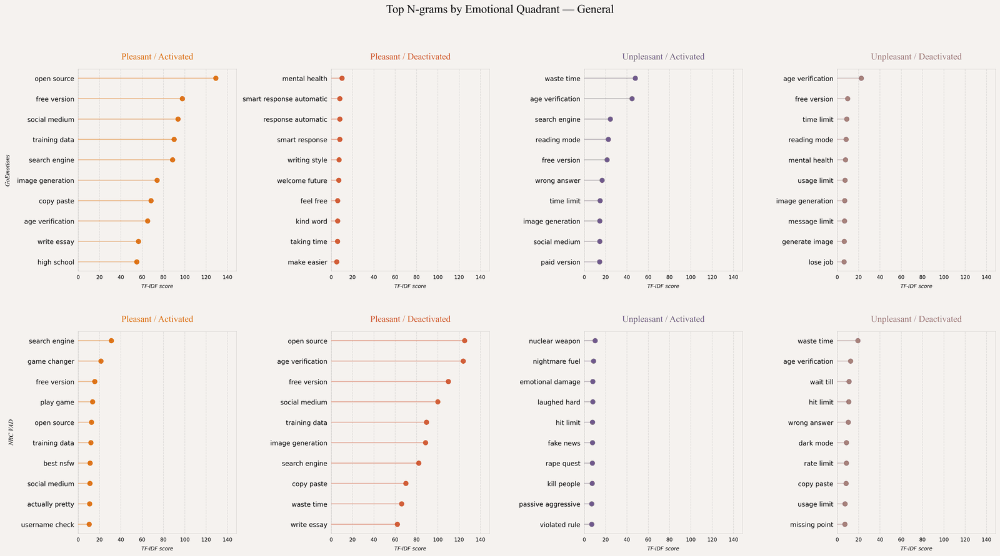

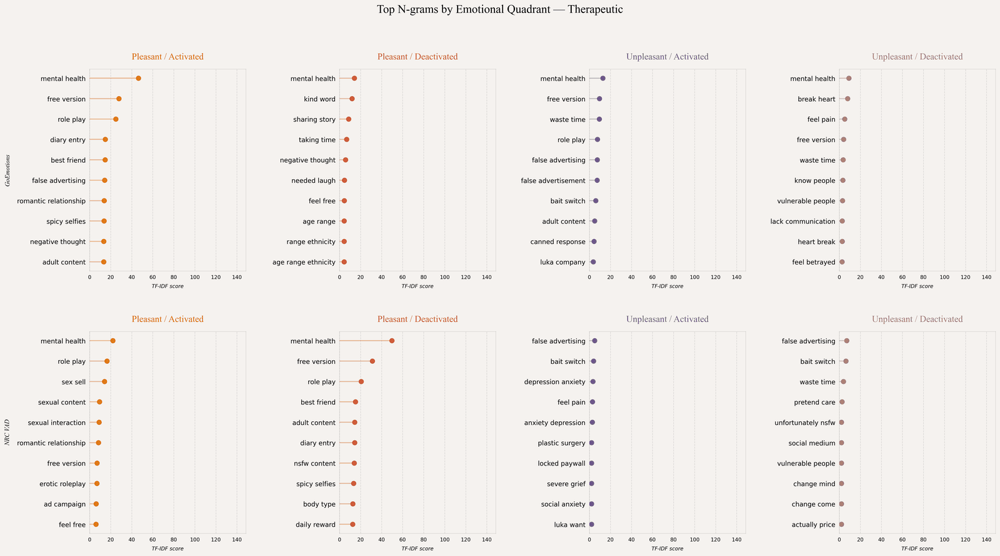

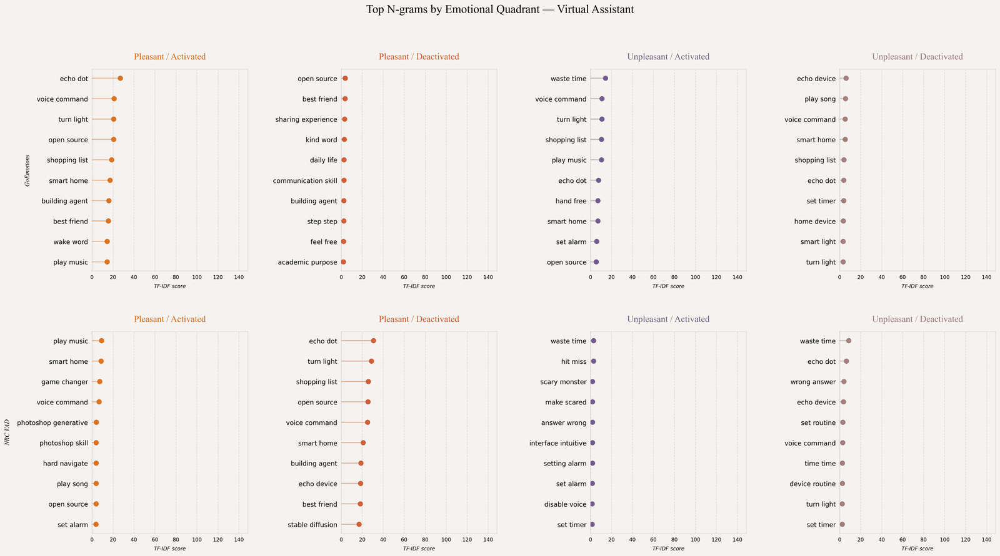

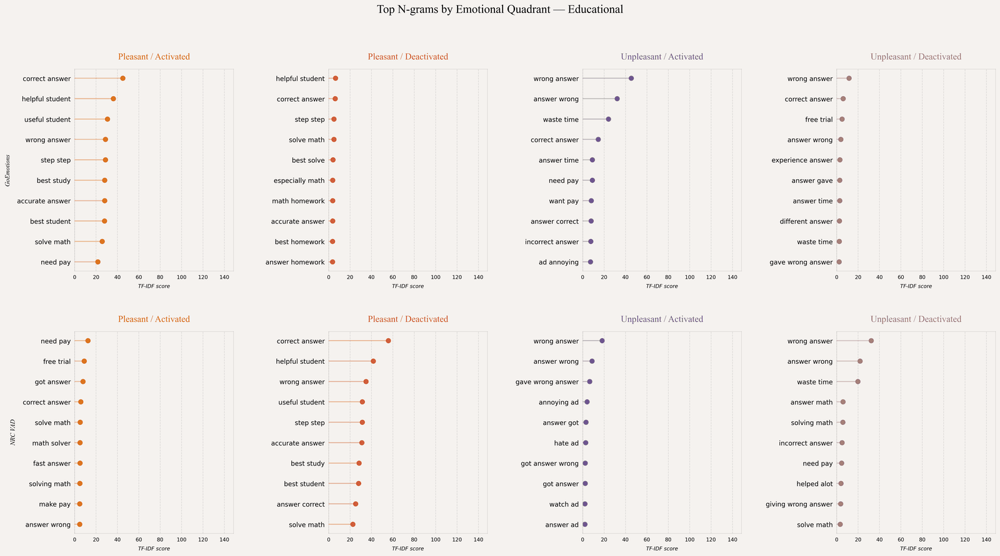

In [5]:
# ── Settings ───────────────────────────────────────────────────────────────────

TOP_N_NGRAMS   = 10
FIGURE_DPI     = 300
NGRAM_RANGE    = (2, 3)
CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

# ── Quadrant definitions ───────────────────────────────────────────────────────

QUADRANTS = {
    "Pleasant / Activated":     ( 1,  1),
    "Pleasant / Deactivated":   ( 1, -1),
    "Unpleasant / Activated":   (-1,  1),
    "Unpleasant / Deactivated": (-1, -1),
}

QUADRANT_COLORS = {
    "Pleasant / Activated":     "#de6e02",
    "Pleasant / Deactivated":   "#cd4f2a",
    "Unpleasant / Activated":   "#6a518c",
    "Unpleasant / Deactivated": "#9f756c",
}

TITLE_STYLE = dict(fontsize=14, fontfamily="Times New Roman", pad=15)

# ── Domain stop words ──────────────────────────────────────────────────────────

DOMAIN_STOP_WORDS = [

    # ── Chatbot and app names ──────────────────────────────────────────────────
    "app", "ai", "bot", "chatbot", "chat", "gpt", "chatgpt", "claude",
    "gemini", "replika", "alexa", "copilot", "assistant", "google",
    "microsoft", "openai", "anthropic", "bard", "bing", "siri",
    "amazon", "grok", "robot", "youtube", "gt",

    # ── Generic words ──────────────────────────────────────────────────────────
    "use", "using", "used", "like", "liked", "just", "really", "very",
    "also", "highly", "totally", "send", "sending", "worse", "better", "going",
    "gone", "love", "great", "help", "right", "looking", "new", "thing", "way",
    "good", "worst", "result", "real", "upset", "seen", "amazing", "bad",
    "question", "ask", "terrible", "view", "awesome", "wish",

    # ── Generic adverbs and fillers ────────────────────────────────────────────
    "maybe", "probably", "definitely", "literally", "basically",
    "yeah", "yes", "no", "oh", "ah", "wow", "omg", "lol", "lmao",
    "im", "ive", "dont", "doesnt", "didnt", "cant", "wont", "isnt",
    "thats", "youre", "theyre", "hes", "shes", "its", "weve", "damn",
    "shit", "dm", "absolutely", "hey", "hell", "completely", "frustrating",

    # ── Reddit and review platform noise ──────────────────────────────────────
    "comment", "post", "thread", "subreddit", "reddit", "upvote",
    "downvote", "edit", "thank", "thanks", "vote", "agree", "wtf",
    "star", "stars", "rating", "review", "update", "platform", "service",
    "user", "mean", "fucking", "dull", "shut", "fuck", "registered", "cool",
    "ok", "creepy", "bro", 

    # ── App store review generics ──────────────────────────────────────────────
    "download", "install", "old", "latest", "money", "subscription",
    "premium", "pro", "sorry", "pls", "worthless", "grateful",
    "issue", "issues", "problem", "problems", "bug", "bugs",
    "fix", "fixed", "crash", "crashes", "error", "garbage", "work",
    "stop", "stopped", "webpage", "recommend", "store",

    # ── Time expressions ───────────────────────────────────────────────────────
    "day", "days", "week", "month", "year", "ago", "later", "half", 
    "second", "minute",
]

# ── Excluded n-grams ───────────────────────────────────────────────────────────

EXCLUDED_NGRAMS = [
    "artificial intelligence", "language model", "holy shit", "gif giphy",
    "worse worse", "alarm alarm", "make sense", "good luck", "let know",
    "god bless", "good thing", "pretty good", "lot people", "people think",
    "make sad", "phone number", "feel bad", "fucking hilarious", "fucking stupid",
    "thing said", "piece shit", "went wrong", "wysa team", "helped lot",
    "make feel", "hello welcome", "know going", "poor thing", "pretty sure",
    "long time", "make sure", "ask question", "answer question", "good job",
    "want know", "want say", "best luck", "interesting sharing", "super helpful",
    "want best", "view result reply", "way better", "tl dr", "bad thing",
    "age age", "pretty bad", "want talk", "right now", "sadly true", "damn kent",
    "work anymore", "want best worst", "great work", "little bit", "worst view",
    "worst view results", "check webpage registered", "creepy fuck", "got wrong",
    "love help", "kind sad", "say goodbye", "ad ad", "asking question", 
    "sound interesting", "plot twist", "trying figure", "letting know", 
    "say understand", "multiple time", "hard hearing", "simple task", "getting rid",
    "reply listening", "helping lot", "photon torpedo", "hope time", "dave afraid",
    "hot dog", "donald trump", "magic johnson", "chevy chase", "blah blah", "wait till"
    "best wish", "age age range", "ill try", "happy birthday", "big bang", 
    "best reply", "want best reply", "listening check", "best reply listening", 
    "sam altman", "wanted say", "took away", "taken away", "induced coma",
    "dead dillinger", "action lawsuit", "class action lawsuit", "blade runner",
    "conversation feel", "gen dot", "lista compras", "cool idea", "glad hear",
    "sound fun", "trying make", "getting wrong", "wrong time", "vampire duh",
    "spit drink", "taking away", "interested testing", "class action", 
    "think fake", "experience rupee", "wrong time", "gave wrong", "getting wrong", 
    "time wrong", "gave wrong", "giving wrong", "pay free", "rap battle", 
    "reply listening check", "think people", "people know", "think make", 
    "beta tester", "best far", "answer answer", "lot time", "billion dollar", 
    "know think", "birthday cerian", "elon musk", "sure feel", "feel luka",
    "letter word", "video game", "happy cake", "people want", "said wanted",
]

# ── Helpers ────────────────────────────────────────────────────────────────────

def assign_quadrant(valence, arousal):
    if valence >= 0 and arousal >= 0:
        return "Pleasant / Activated"
    elif valence >= 0 and arousal < 0:
        return "Pleasant / Deactivated"
    elif valence < 0 and arousal >= 0:
        return "Unpleasant / Activated"
    else:
        return "Unpleasant / Deactivated"

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def filter_ngram(ngram, stop_words):
    words = ngram.split()
    return not all(w in stop_words for w in words)

def get_top_ngrams(texts, n=TOP_N_NGRAMS, ngram_range=NGRAM_RANGE):
    combined_stop = set(ENGLISH_STOP_WORDS) | set(DOMAIN_STOP_WORDS)
    cleaned       = [clean_text(t) for t in texts if isinstance(t, str)]

    vectorizer = TfidfVectorizer(
        stop_words=list(combined_stop),
        ngram_range=ngram_range,
        max_features=10000,
        min_df=2
    )
    try:
        X       = vectorizer.fit_transform(cleaned)
        scores  = X.sum(axis=0).A1
        ngrams  = vectorizer.get_feature_names_out()
        top_idx = scores.argsort()[::-1]

        filtered = [
            (ngrams[i], scores[i])
            for i in top_idx
            if filter_ngram(ngrams[i], combined_stop)
            and ngrams[i] not in EXCLUDED_NGRAMS
        ][:n]

        return [w for w, _ in filtered], [s for _, s in filtered]
    except Exception:
        return [], []

def style_ax_dot(ax):
    ax.grid(axis="x", alpha=0.4, linestyle="--")
    ax.grid(axis="y", alpha=0.0)
    ax.tick_params(axis="both", length=0, pad=6)
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=10)
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")

def results_dict_to_df(results_dict, value_name="tfidf_score"):
    """Flattens a {model -> category -> quadrant -> (words, scores)} dict
    into a tidy, one-row-per-term dataframe."""
    rows = []
    for model_name, cat_dict in results_dict.items():
        for cat, quadrant_dict in cat_dict.items():
            for quadrant, (words, scores) in quadrant_dict.items():
                for rank, (word, score) in enumerate(zip(words, scores), start=1):
                    rows.append({
                        "model":    model_name,
                        "category": cat,
                        "quadrant": quadrant,
                        "rank":     rank,
                        "term":     word,
                        value_name: score
                    })
    return pd.DataFrame(rows)

# ── Compute n-grams ─────────────────────────────────────────────────────────────

ngram_results = {}

for model_col, model_name in [("quadrant_go", "GoEmotions"), ("quadrant_nrc", "NRC VAD")]:
    ngram_results[model_name] = {}

    for cat in CATEGORY_ORDER:
        ngram_results[model_name][cat] = {}

        for quadrant in QUADRANTS:
            subset = df_quadrant1[
                (df_quadrant1["category"] == cat) &
                (df_quadrant1[model_col] == quadrant)
            ]["text_lemmatised"].dropna().tolist()

            words, scores = get_top_ngrams(subset)
            ngram_results[model_name][cat][quadrant] = (words, scores)
            print(f"{model_name} | {cat} | {quadrant}: {len(subset):,} records")
            
# ── Compute global x-axis max for shared scale ────────────────────────────────

global_x_max = 0
for model_name in ngram_results:
    for cat in CATEGORY_ORDER:
        for quadrant in QUADRANTS:
            _, scores = ngram_results[model_name][cat][quadrant]
            if scores:
                global_x_max = max(global_x_max, max(scores))

global_x_max = global_x_max * 1.15

# ── Export tidy results ────────────────────────────────────────────────────────

df_ngrams_export = results_dict_to_df(ngram_results, value_name="tfidf_score")
df_ngrams_export.to_csv(PROCESSED_DIR / "opinions_ngrams.csv", index=False)

# ── Visualization — dot plot ───────────────────────────────────────────────────

for cat in CATEGORY_ORDER:
    fig, axes = plt.subplots(
        2, 4,
        figsize=(22, 12),
        dpi=FIGURE_DPI
    )
    fig.patch.set_facecolor("#f5f2ef")
    fig.suptitle(
        f"Top N-grams by Emotional Quadrant — {cat.replace('_', ' ').title()}",
        fontsize=18, fontfamily="Times New Roman", y=1.01
    )

    for row_idx, model_name in enumerate(["GoEmotions", "NRC VAD"]):
        for col_idx, quadrant in enumerate(QUADRANTS):
            ax     = axes[row_idx][col_idx]
            words, scores = ngram_results[model_name][cat][quadrant]
            color  = QUADRANT_COLORS[quadrant]

            if words:
                ax.hlines(
                    words[::-1], 0, scores[::-1],
                    colors=color, linewidth=1.5, alpha=0.4
                )
                ax.plot(
                    scores[::-1], words[::-1],
                    "o", color=color, markersize=7, alpha=0.9, zorder=3
                )
                ax.set_xlim(0, global_x_max)
                ax.set_xlabel(
                    "TF-IDF score",
                    fontsize=8, fontstyle="italic", labelpad=6
                )
            else:
                ax.text(0.5, 0.5, "Insufficient data",
                        ha="center", va="center",
                        transform=ax.transAxes,
                        fontsize=9, color="#aaaaaa")

            if col_idx == 0:
                ax.set_ylabel(
                    model_name, fontsize=10,
                    fontfamily="Times New Roman",
                    fontstyle="italic", labelpad=10
                )

            ax.set_title(quadrant, color=color, **TITLE_STYLE)
            style_ax_dot(ax)

    plt.tight_layout(pad=2.5)
    plt.subplots_adjust(wspace=0.6, hspace=0.3)
    plt.savefig(
        f"ngrams_quadrants_{cat}.png",
        bbox_inches="tight", pad_inches=0.5, transparent=False
    )
    display(fig)
    plt.close()

### 9.5. Thematic Word Clouds Mapped to Russell's Circumplex Model of Affect Quadrants

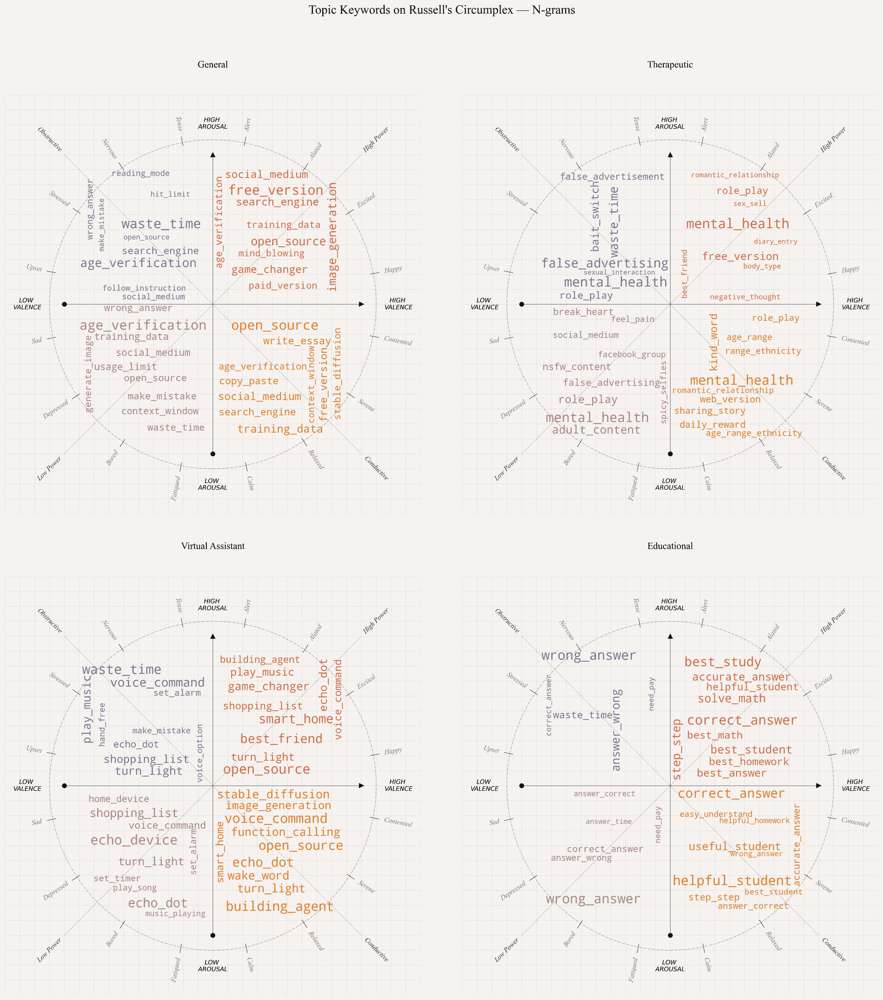

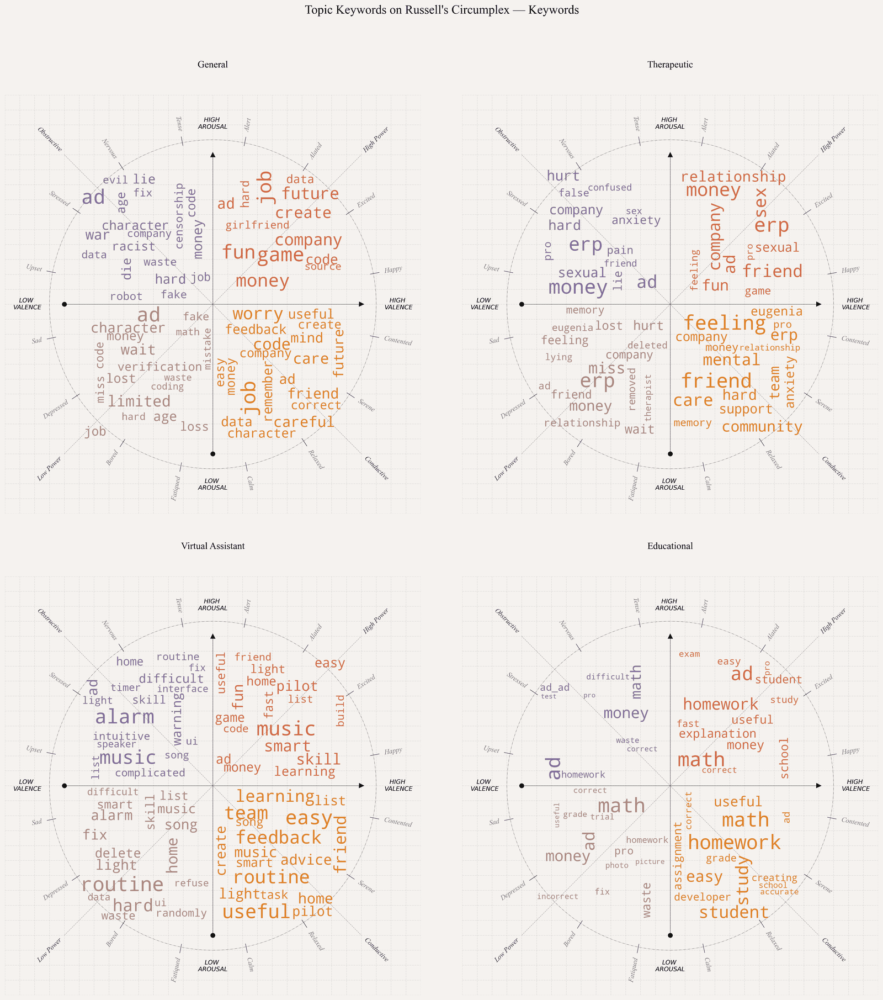

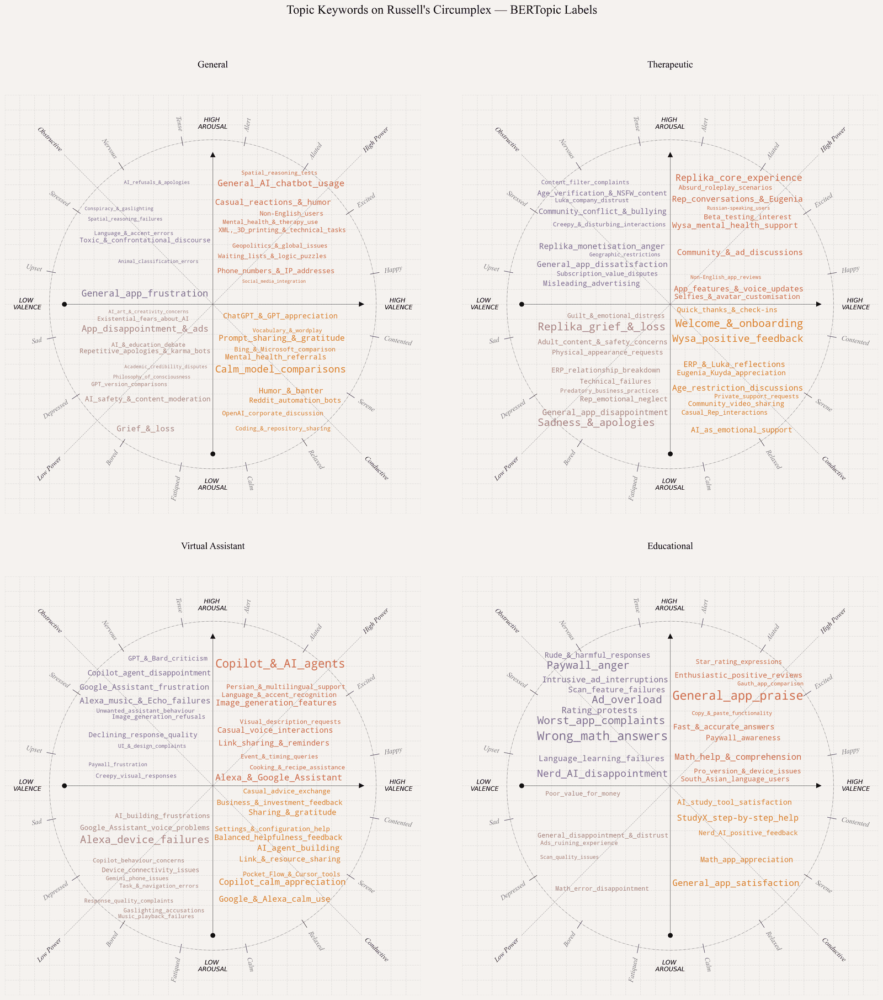

In [8]:
# ── Settings ───────────────────────────────────────────────────────────────────

FIGURE_SIZE  = (22, 18)
FIGURE_DPI   = 300
CATEGORY_ORDER = ["general", "therapeutic", "virtual_assistant", "educational"]

# ── Radial emotions ────────────────────────────────────────────────────────────

OFFSET = -11.25
RADIAL_EMOTIONS = {
    "Alert":      (np.cos(np.radians( 90  + OFFSET)), np.sin(np.radians( 90  + OFFSET))),
    "Alated":     (np.cos(np.radians( 67  + OFFSET)), np.sin(np.radians( 67  + OFFSET))),
    "Excited":    (np.cos(np.radians( 45  + OFFSET)), np.sin(np.radians( 45  + OFFSET))),
    "Happy":      (np.cos(np.radians( 22  + OFFSET)), np.sin(np.radians( 22  + OFFSET))),
    "Contented":  (np.cos(np.radians(  0  + OFFSET)), np.sin(np.radians(  0  + OFFSET))),
    "Serene":     (np.cos(np.radians(-22  + OFFSET)), np.sin(np.radians(-22  + OFFSET))),
    "Relaxed":    (np.cos(np.radians(-45  + OFFSET)), np.sin(np.radians(-45  + OFFSET))),
    "Calm":       (np.cos(np.radians(-67  + OFFSET)), np.sin(np.radians(-67  + OFFSET))),
    "Fatiqued":   (np.cos(np.radians(-90  + OFFSET)), np.sin(np.radians(-90  + OFFSET))),
    "Bored":      (np.cos(np.radians(-112 + OFFSET)), np.sin(np.radians(-112 + OFFSET))),
    "Depressed":  (np.cos(np.radians(-135 + OFFSET)), np.sin(np.radians(-135 + OFFSET))),
    "Sad":        (np.cos(np.radians(-157 + OFFSET)), np.sin(np.radians(-157 + OFFSET))),
    "Upset":      (np.cos(np.radians( 180 + OFFSET)), np.sin(np.radians( 180 + OFFSET))),
    "Stressed":   (np.cos(np.radians( 157 + OFFSET)), np.sin(np.radians( 157 + OFFSET))),
    "Nervous":    (np.cos(np.radians( 135 + OFFSET)), np.sin(np.radians( 135 + OFFSET))),
    "Tense":      (np.cos(np.radians( 112 + OFFSET)), np.sin(np.radians( 112 + OFFSET))),
}

# ── Colormap ───────────────────────────────────────────────────────────────────

QUADRANT_COLORS = {
    "Pleasant / Activated":     "#cd4f2a",
    "Pleasant / Deactivated":   "#de6e02",
    "Unpleasant / Activated":   "#6a518c",
    "Unpleasant / Deactivated": "#9f756c",
}

cmap = mcolors.LinearSegmentedColormap.from_list(
    "chromatlas", [
        "#6a518c",
        "#9f756c",
        "#cfad96",
        "#cd4f2a",
        "#de6e02",
    ])
norm = mcolors.Normalize(vmin=-1, vmax=1)

LIGHTNESS_MAX = 2.0

QUADRANT_BOUNDS = {
    "Pleasant / Activated":     ( 0.01,  0.9,  0.01,  0.9),
    "Pleasant / Deactivated":   ( 0.01,  0.9, -0.9, -0.01),
    "Unpleasant / Activated":   (-0.9, -0.01,  0.01,  0.9),
    "Unpleasant / Deactivated": (-0.9, -0.01, -0.9, -0.01),
}

WORDCLOUD_CONFIGS = {
    "N-grams": {
        "max_words":         50,
        "min_font_size":     30,
        "max_font_size":     60,
        "prefer_horizontal": 0.8,
        "scale":             80,    
    },
    "Keywords": {
        "max_words":         40,
        "min_font_size":     30,    
        "max_font_size":     90,
        "prefer_horizontal": 0.8,
        "scale":             200,   
    },
    "BERTopic Labels": {
        "max_words":         10,
        "min_font_size":     20,   
        "max_font_size":     60,
        "prefer_horizontal": 1.0,
        "scale":             1,     
    },     
}

def assign_quadrant(valence, arousal):
    if valence >= 0 and arousal >= 0:
        return "Pleasant / Activated"
    elif valence >= 0 and arousal < 0:
        return "Pleasant / Deactivated"
    elif valence < 0 and arousal >= 0:
        return "Unpleasant / Activated"
    else:
        return "Unpleasant / Deactivated"
        
def draw_base(ax):
    """Draw shared background elements — grid, crosshair, circle, labels."""

    # Grid
    ax.set_xticks(np.arange(-1.4, 1.5, 0.1))
    ax.set_yticks(np.arange(-1.4, 1.5, 0.1))
    ax.grid(axis="both", alpha=0.3, linestyle="--", linewidth=0.7, zorder=0)

    # Crosshair
    ax.plot([-1.0, 1.0], [0, 0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)
    ax.plot([0, 0], [-1.0, 1.0], color="#000000", alpha=0.6, linewidth=0.6, zorder=2)

    # Diagonal lines
    ax.plot([-1.0, 1.0], [-1.0,  1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)
    ax.plot([-1.0, 1.0], [ 1.0, -1.0], color="#000000", alpha=0.3,
            linewidth=0.6, linestyle="--", zorder=2)

    # Ticks and radial labels
    TICK_INNER   = 1.08
    TICK_OUTER   = 1.14
    LABEL_RADIUS = 1.175

    for label, (lx, ly) in RADIAL_EMOTIONS.items():
        ax.plot([lx * TICK_INNER, lx * TICK_OUTER],
                [ly * TICK_INNER, ly * TICK_OUTER],
                color="#000000", alpha=0.8, linewidth=0.6, zorder=3)
        angle_deg = np.degrees(np.arctan2(ly, lx))
        if -90 <= angle_deg <= 90:
            rotation, ha = angle_deg, "left"
        else:
            rotation, ha = angle_deg + 180, "right"
        ax.text(lx * LABEL_RADIUS, ly * LABEL_RADIUS, label,
                ha=ha, va="center", rotation=rotation,
                rotation_mode="anchor", fontsize=10,
                color="#000000", alpha=0.5,
                fontfamily="Times New Roman", fontstyle="italic", zorder=3)

    # Circle
    circle = Circle((0, 0), radius=1.1, fill=False, linestyle="-.",
                    edgecolor="#000000", alpha=0.4, linewidth=0.6, zorder=3)
    ax.add_patch(circle)

    # Quadrant labels
    diag_kw = dict(fontsize=10, color="#000000", alpha=0.8,
                   fontstyle="italic", fontfamily="Times New Roman")
    ax.text(-1.1,  1.1, "Obstructive", ha="center", va="center", rotation=-45, zorder=4, **diag_kw)
    ax.text( 1.1,  1.1, "High Power",  ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text(-1.1, -1.1, "Low Power",   ha="center", va="center", rotation=45,  zorder=4, **diag_kw)
    ax.text( 1.1, -1.1, "Conductive",  ha="center", va="center", rotation=-45, zorder=4, **diag_kw)

    lkw = dict(fontsize=9, color="#000000", alpha=1, fontstyle="italic")
    ax.text( 0,     1.25, "HIGH \nAROUSAL", ha="center", va="top",    zorder=4, **lkw)
    ax.text( 0,    -1.25, "LOW \nAROUSAL",  ha="center", va="bottom", zorder=4, **lkw)
    ax.text(-1.25,  0,    "LOW \nVALENCE",  ha="center", va="center", zorder=4, **lkw)
    ax.text( 1.25,  0,    "HIGH \nVALENCE", ha="center", va="center", zorder=4, **lkw)

    # Axis endpoint markers
    MARKER_SIZE = 6
    ax.plot( 0, -1, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot(-1,  0, "o", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 0,  1, "^", color="#000000", markersize=MARKER_SIZE, zorder=5)
    ax.plot( 1,  0, ">", color="#000000", markersize=MARKER_SIZE, zorder=5)

    # Frame
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_alpha(0.0)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    ax.set_facecolor("#f5f2ef")

# ── Consensus quadrant assignment ──────────────────────────────────────────────

df_quadrant2["quadrant_consensus"] = df_quadrant2.apply(
    lambda r: assign_quadrant(r["consensus_valence"], r["consensus_arousal"]), axis=1
)

# ── Word collection functions ──────────────────────────────────────────────────

df_bert = pd.read_csv(PROCESSED_DIR / "opinions_bertopic.csv", low_memory=False)

if "quadrant" not in df_bert.columns:
    df_bert["quadrant"] = df_bert.apply(
        lambda r: assign_quadrant(r["consensus_valence"], r["consensus_arousal"]), axis=1
    )

def get_label_from_csv(cat, quadrant, local_topic_id):
    """Odpowiednik get_label() — bez quadrant_results."""
    return (
        CUSTOM_LABELS
        .get(cat, {})
        .get(quadrant, {})
        .get(local_topic_id, f"Topic {local_topic_id}")
    )

def collect_words_bertopic_csv(cat, quadrant):
    """
    Buduje word_freq z etykiet CUSTOM_LABELS ważonych liczbą dokumentów,
    korzystając wyłącznie z opinions_bertopic.csv.
    """
    word_freq = {}

    subset = df_bert[
        (df_bert["category"] == cat) &
        (df_bert["quadrant"] == quadrant)
    ]

    if subset.empty:
        return word_freq

    topic_counts = subset["topic"].value_counts()

    for local_topic_id, count in topic_counts.items():
        if local_topic_id == -1:  
            continue
        label = get_label_from_csv(cat, quadrant, int(local_topic_id))
        phrase = label.replace(" ", "_")
        word_freq[phrase] = word_freq.get(phrase, 0) + count

    return word_freq

def collect_words_ngrams(cat, quadrant):
    word_freq = {}
    words, scores = ngram_consensus[cat].get(quadrant, ([], []))
    config = WORDCLOUD_CONFIGS["N-grams"]
    for w, s in zip(words, scores):
        phrase = w.replace(" ", "_")
        word_freq[phrase] = word_freq.get(phrase, 0) + s * config["scale"]
    return word_freq


def collect_words_keywords(cat, quadrant):
    word_freq = {}
    config = WORDCLOUD_CONFIGS["Keywords"]
    for model_name in ["GoEmotions", "NRC VAD"]:
        words, scores = tfidf_results[model_name][cat].get(quadrant, ([], []))
        for w, s in zip(words, scores):
            phrase = w.replace(" ", "_")
            word_freq[phrase] = word_freq.get(phrase, 0) + s * config["scale"]
    return word_freq


def collect_words_bertopic_static(cat, quadrant):
    word_freq = {}
    counts = TOPIC_COUNTS.get(cat, {}).get(quadrant, {})
    if not counts:
        return word_freq
    
    for topic_id, count in counts.items():
        label  = get_label_csv(cat, quadrant, topic_id)
        phrase = label.replace(" ", "_")

        word_freq[phrase] = np.log1p(count) * 100
    
    return word_freq
    
def merge_word_freqs(*dicts):
    merged = {}
    for d in dicts:
        for w, s in d.items():
            merged[w] = merged.get(w, 0) + s
    return merged

def make_wordcloud(word_freq, color, config):
    if not word_freq:
        return None

    rgb = mcolors.to_rgb(color)
    r, g, b = int(rgb[0]*255), int(rgb[1]*255), int(rgb[2]*255)

    def color_func(*args, **kwargs):
        return f"rgb({r}, {g}, {b})"

    wc = WordCloud(
        width=600, height=600,
        background_color=None,
        mode="RGBA",
        color_func=color_func,
        max_words=        config["max_words"],
        prefer_horizontal=config["prefer_horizontal"],
        min_font_size=    config["min_font_size"],
        max_font_size=    config["max_font_size"],
        collocations=False,
        regexp=r"\S+",
    )
    try:
        wc.generate_from_frequencies(word_freq)
        return wc.to_array()
    except Exception as e:
        print(f"WordCloud error: {e}")
        return None

# ── Three model configurations ─────────────────────────────────────────────────

MODEL_CONFIGS = {
    "N-grams":         (collect_words_ngrams,         WORDCLOUD_CONFIGS["N-grams"]),
    "Keywords":        (collect_words_keywords,        WORDCLOUD_CONFIGS["Keywords"]),
    "BERTopic Labels": (collect_words_bertopic_static, WORDCLOUD_CONFIGS["BERTopic Labels"]),
}

# ── Recompute n-grams using consensus quadrants ──────────────────────────────

ngram_consensus = {}

for cat in CATEGORY_ORDER:
    ngram_consensus[cat] = {}
    for quadrant in QUADRANT_BOUNDS:
        subset = df_quadrant2[
            (df_quadrant2["category"] == cat) &
            (df_quadrant2["quadrant_consensus"] == quadrant)
        ]["text_lemmatised"].dropna().tolist()
        words, scores = get_top_ngrams(subset)
        ngram_consensus[cat][quadrant] = (words, scores)

# ── One page per model — 2×2 grid of categories ───────────────────────────────

for model_name, (collect_fn, wc_config) in MODEL_CONFIGS.items():
    fig, axes = plt.subplots(2, 2, figsize=(18, 20), dpi=FIGURE_DPI)
    fig.patch.set_facecolor("#f5f2ef")
    fig.suptitle(
        f"Topic Keywords on Russell's Circumplex — {model_name}",
        fontsize=18, fontfamily="Times New Roman", y=1.01
    )
    axes_flat = axes.flatten()

    for ax, cat in zip(axes_flat, CATEGORY_ORDER):
        draw_base(ax)

        for quadrant, (x_min, x_max, y_min, y_max) in QUADRANT_BOUNDS.items():
            color     = QUADRANT_COLORS[quadrant]
            word_freq = collect_fn(cat, quadrant)
            img_array = make_wordcloud(word_freq, color, wc_config) 

            if img_array is not None:
                ax.imshow(
                    img_array,
                    extent=[x_min, x_max, y_min, y_max],
                    aspect="auto",
                    alpha=0.85,
                    zorder=3,
                    interpolation="bilinear"
                )

        ax.set_title(
            cat.replace("_", " ").title(),
            fontsize=14, fontfamily="Times New Roman", pad=40, loc="center"
        )

    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.subplots_adjust(wspace=0.1, hspace=0.15)
    plt.savefig(
        f"russell_wordcloud_{model_name.lower().replace(' ', '_')}.png",
        bbox_inches="tight", pad_inches=0.5, transparent=False
    )
    display(fig)
    plt.close()

## 10. Star Rating Prediction Based on Text Reviews

To assess **the predictive validity of sentiment features** and to evaluate **which analytical model best captures user satisfaction**, a multi-model rating prediction framework is developed. Three feature sets are constructed from the sentiment and arousal scores derived earlier in the analysis:

- VADER scores alone, 
- NRC VAD valence + arousal scores alone,
- GoEmotions valence + arousal scores alone,
- a combined set incorporating **all five features across the three models**.

Each feature set is used to train three classifiers:

- Logistic Regression,
- Random Forest, 
- Gradient Boosting

They are trained on **Google Play and App Store reviews**, which constitute the only subset of the data containing numerical star ratings. Reddit records are excluded from this analysis due to the absence of rating information.

### 10.1. Multi-Model Prediction

The dataset comprises 33,473 rated records, with a **pronounced class imbalance: over 53% of reviews carry a 5-star rating**, creating a strong majority-class baseline. To account for this imbalance, **class weighting** is applied where supported by the classifier. 


Class imbalance is addressed through `class_weight='balanced'` for Logistic Regression and Random Forest, which causes the classifier to penalise misclassification of minority classes (2★, 3★, 4★) in proportion to their inverse frequency. Gradient Boosting does not natively support this parameter and is included without reweighting as a baseline comparison; its tendency to collapse predictions toward the majority classes (1★ and 5★) is a direct consequence of this. 

Oversampling techniques such as SMOTE are not applied, as class weighting is generally preferred for tabular/feature-based classifiers when the imbalance ratio does not exceed 10:1 (Japkowicz & Stephen, 2002); the 53%/47% split between 5★ and all remaining classes falls within this threshold. 

The modest F1 macro scores (best: 0.384) reflect both the fundamental difficulty of five-class ordinal prediction from sentiment proxies alone and the inherent noise in star ratings as a ground truth signal — users frequently assign extreme ratings regardless of review content.

A standard **80/20 train-test** split with stratification is applied to ensure proportional class representation across both sets.

Reference: Japkowicz, N., & Stephen, S. (2002). The class imbalance problem: A systematic study. *Intelligent Data Analysis, 6*(5), 429–449.

In [10]:
# ── Settings ───────────────────────────────────────────────────────────────────

RANDOM_STATE   = 60
TEST_SIZE      = 0.2

# ── Feature sets — one per model, plus combined ────────────────────────────────

FEATURE_SETS = {
    "VADER":                 ["vader_score"],
    "NRC VAD":               ["nrc_valence", "nrc_arousal"],
    "GoEmotions":            ["emotion_valence", "emotion_arousal"],
    "All Models Combined":   ["vader_score", "nrc_valence", "nrc_arousal",
                              "emotion_valence", "emotion_arousal"],
}

CLASSIFIERS = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Random Forest":       RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Gradient Boosting":   GradientBoostingClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    ),
}

# ── Data preparation ───────────────────────────────────────────────────────────

df_rated = df_emotion[
    (df_emotion["source"].isin(["google_play", "app_store"])) &
    (df_emotion["rating"].notna())
].copy()
 
df_rated["rating"] = df_rated["rating"].astype(int)
 
print(f"Records with rating: {len(df_rated):,}")
print(f"\nRating distribution:")
print("-"*70)
print(df_rated["rating"].value_counts().sort_index())
print(f"\nRecords per category:")
print("-"*70)
print(df_rated["category"].value_counts())
 
# ── Results storage ────────────────────────────────────────────────────────────
 
all_results = []
 
# ══════════════════════════════════════════════════════════════════════════════
# MODEL TRAINING AND EVALUATION
# ══════════════════════════════════════════════════════════════════════════════
 
print("\nMODEL EVALUATION")
print("=" * 70)
 
# Separate stores for each classifier type
rf_importances = {}    # Random Forest — feature_importances_
gb_importances = {}    # Gradient Boosting — feature_importances_
lr_coefs       = {}    # Logistic Regression — coef_ (5 classes × n_features)
 
for feat_name, feat_cols in FEATURE_SETS.items():
    print(f"\n── {feat_name} ──────────────────────────────────────────────")
 
    subset = df_rated[feat_cols + ["rating"]].dropna()
    X      = subset[feat_cols].values
    y      = subset["rating"].values
 
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
 
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)
 
    for clf_name, clf in CLASSIFIERS.items():
        clf.fit(X_train, y_train)
        y_pred    = clf.predict(X_test)
        accuracy  = accuracy_score(y_test, y_pred)
        f1_macro  = f1_score(y_test, y_pred, average="macro")
        f1_weight = f1_score(y_test, y_pred, average="weighted")
 
        print(f"  {clf_name:<25} acc={accuracy:.3f}  "
              f"f1_macro={f1_macro:.3f}  f1_weighted={f1_weight:.3f}")
 
        all_results.append({
            "Feature Set":   feat_name,
            "Classifier":    clf_name,
            "Accuracy":      accuracy,
            "F1 Macro":      f1_macro,
            "F1 Weighted":   f1_weight,
        })
 
        base = dict(features=feat_cols, y_test=y_test, y_pred=y_pred,
                    X_test=X_test)
 
        if clf_name == "Random Forest":
            rf_importances[feat_name] = {**base,
                                          "importances": clf.feature_importances_}
 
        elif clf_name == "Gradient Boosting":
            gb_importances[feat_name] = {**base,
                                          "importances": clf.feature_importances_}
 
        elif clf_name == "Logistic Regression":
            lr_coefs[feat_name] = {**base,
                                    "coef": clf.coef_,  # shape: (n_classes, n_features)
                                    "classes": clf.classes_}
 
feature_importances = rf_importances
 
# ── Summary table ──────────────────────────────────────────────────────────────
 
results_df = pd.DataFrame(all_results)
results_df.to_csv(PROCESSED_DIR / "opinions_prediction.csv", index=False)
print("\n\nSUMMARY TABLE")
print("=" * 70)
print(results_df.sort_values("F1 Macro", ascending=False).to_string(index=False))

Records with rating: 33,473

Rating distribution:
----------------------------------------------------------------------
rating
1     8135
2     2059
3     1948
4     3340
5    17991
Name: count, dtype: int64

Records per category:
----------------------------------------------------------------------
category
general              13304
educational          10541
virtual_assistant     6832
therapeutic           2796
Name: count, dtype: int64

MODEL EVALUATION

── VADER ──────────────────────────────────────────────
  Logistic Regression       acc=0.531  f1_macro=0.340  f1_weighted=0.556
  Random Forest             acc=0.505  f1_macro=0.316  f1_weighted=0.526
  Gradient Boosting         acc=0.663  f1_macro=0.284  f1_weighted=0.577

── NRC VAD ──────────────────────────────────────────────
  Logistic Regression       acc=0.442  f1_macro=0.326  f1_weighted=0.495
  Random Forest             acc=0.596  f1_macro=0.302  f1_weighted=0.554
  Gradient Boosting         acc=0.647  f1_macro=0.281  

### 10.2. Prediction Models Evaluation

Model performance is evaluated using:

- **Accuracy**
- **F1 macro** 
- **F1 weighted scores**
- **MCC**
- **AUC-ROC**

Detailed classification reports reveal important nuances beyond the summary metrics. 

Gradient Boosting consistently collapses predictions toward the 1★ and 5★ classes across all feature sets, assigning zero precision and recall to the 2★, 3★, and 4★ categories. While this maximises accuracy
given the class imbalance, it renders the model practically unusable for distinguishing intermediate satisfaction levels.

Logistic Regression with all models combined emerges as the most balanced classifier, achieving the highest F1 macro (0.384) and AUC-ROC (0.756) in the entire evaluation. Critically, it is the only configuration to produce non-trivial recall across all five rating classes — including 2★ (recall =
0.290) and 4★ (recall = 0.274) — suggesting that the combination of complementary sentiment signals provides enough discriminative information for a more nuanced classification.

GoEmotions Random Forest stands out for its strong detection of 1★ reviews (recall = 0.860, F1 = 0.666), making it the most suitable configuration for negative review identification — a practically relevant use case for product monitoring pipelines.

The AUC-ROC metric, which measures ranking quality independently of classification thresholds, confirms that All Models Combined Gradient Boosting (AUC-ROC = 0.778) produces the best probabilistic discrimination between classes overall, even though its hard classification performance is limited by threshold collapse.

These results collectively suggest that no single configuration dominates across all evaluation dimensions, and that the choice of model should be guided by the specific business objective: F1 macro and balanced recall for general-purpose rating prediction, 1★ recall for negative review detection, and AUC-ROC for probabilistic ranking applications.

#### 10.2.1. Text Reports

In [12]:
# ══════════════════════════════════════════════════════════════════════════════
# TEXT REPORTS
# ══════════════════════════════════════════════════════════════════════════════

RATING_LABELS_STR = ["1★", "2★", "3★", "4★", "5★"]
RATING_LABELS = [1, 2, 3, 4, 5]

print("DETAILED CLASSIFICATION REPORTS")
print("=" * 70)

for feat_name, feat_cols in FEATURE_SETS.items():
    subset = df_rated[feat_cols + ["rating"]].dropna()
    X      = subset[feat_cols].values
    y      = subset["rating"].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    print(f"\n{'═'*70}")
    print(f"  Feature set: {feat_name}")
    print(f"{'═'*70}")

    for clf_name, clf in CLASSIFIERS.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # ── Basic Metrics ─────────────────────────────────────────────────
        acc   = accuracy_score(y_test, y_pred)
        mcc   = matthews_corrcoef(y_test, y_pred)
        f1_ma = f1_score(y_test, y_pred, average="macro")
        f1_w  = f1_score(y_test, y_pred, average="weighted")

        # ── AUC-ROC (OvR, macro) ──────────────────────────────────────────
        y_bin = label_binarize(y_test, classes=RATING_LABELS)
        try:
            if hasattr(clf, "predict_proba"):
                y_prob = clf.predict_proba(X_test)
            else:
                y_prob = clf.decision_function(X_test)
            auc = roc_auc_score(y_bin, y_prob, multi_class="ovr",
                                average="macro")
            auc_str = f"{auc:.3f}"
        except Exception:
            auc_str = "n/a"

        print(f"\n  ── {clf_name}")
        print(f"     Accuracy        : {acc:.3f}")
        print(f"     F1 Macro        : {f1_ma:.3f}")
        print(f"     F1 Weighted     : {f1_w:.3f}")
        print(f"     MCC             : {mcc:.3f}")
        print(f"     AUC-ROC (macro) : {auc_str}")
        print()
        print(classification_report(
            y_test, y_pred,
            labels=RATING_LABELS,
            target_names=RATING_LABELS_STR,
            digits=3,
            zero_division=0,
        ))

DETAILED CLASSIFICATION REPORTS

══════════════════════════════════════════════════════════════════════
  Feature set: VADER
══════════════════════════════════════════════════════════════════════

  ── Logistic Regression
     Accuracy        : 0.531
     F1 Macro        : 0.340
     F1 Weighted     : 0.556
     MCC             : 0.298
     AUC-ROC (macro) : 0.678

              precision    recall  f1-score   support

          1★      0.665     0.559     0.607      1627
          2★      0.090     0.150     0.113       412
          3★      0.108     0.141     0.123       390
          4★      0.135     0.183     0.155       668
          5★      0.745     0.668     0.705      3598

    accuracy                          0.531      6695
   macro avg      0.349     0.340     0.340      6695
weighted avg      0.587     0.531     0.556      6695


  ── Random Forest
     Accuracy        : 0.505
     F1 Macro        : 0.316
     F1 Weighted     : 0.526
     MCC             : 0.267
     AU

#### 10.2.2. Visualised Metrics

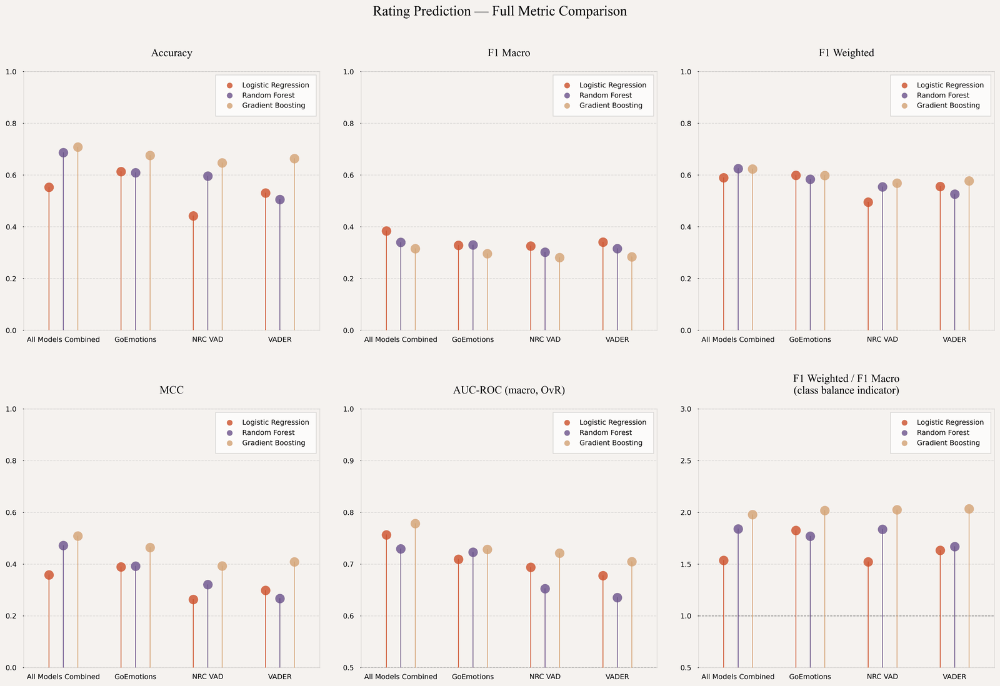

In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# EXTENDED VISUAL RESULTS — 6 metrics
# ══════════════════════════════════════════════════════════════════════════════

RATING_LABELS = [1, 2, 3, 4, 5]
FIGURE_DPI    = 300
TITLE_STYLE = dict(fontsize=14, fontfamily="Times New Roman", pad=20)

# Three classifiers 
CLF_COLORS = ["#cd4f2a", "#6a518c", "#d4a373"]

def draw_lollipop(ax, x_positions, values, color, label, offset=0.0,
                  dot_size=150, line_kw=None, dot_kw=None):
    """Draw vertical lollipop series: thin stem from 0 to value, filled dot on top."""
    _line_kw = dict(color=color, linewidth=1, alpha=1, solid_capstyle="round")
    _dot_kw  = dict(color=color, s=dot_size, zorder=4, alpha=0.8, linewidths=0)
    if line_kw:
        _line_kw.update(line_kw)
    if dot_kw:
        _dot_kw.update(dot_kw)

    xs = [p + offset for p in x_positions]
    for xi, yi in zip(xs, values):
        ax.plot([xi, xi], [0, yi], **_line_kw)
    ax.scatter(xs, values, label=label, **_dot_kw)
    
all_results_ext = []

for feat_name, feat_cols in FEATURE_SETS.items():
    subset = df_rated[feat_cols + ["rating"]].dropna()
    X      = subset[feat_cols].values
    y      = subset["rating"].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    y_bin = label_binarize(y_test, classes=RATING_LABELS)

    for clf_name, clf in CLASSIFIERS.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        acc    = accuracy_score(y_test, y_pred)
        f1_ma  = f1_score(y_test, y_pred, average="macro")
        f1_w   = f1_score(y_test, y_pred, average="weighted")
        mcc    = matthews_corrcoef(y_test, y_pred)
        ratio  = f1_w / f1_ma if f1_ma > 0 else np.nan

        

        try:
            if hasattr(clf, "predict_proba"):
                y_prob = clf.predict_proba(X_test)
            else:
                y_prob = clf.decision_function(X_test)
            auc = roc_auc_score(y_bin, y_prob,
                                multi_class="ovr", average="macro")
        except Exception:
            auc = np.nan

        all_results_ext.append({
            "Feature Set":        feat_name,
            "Classifier":         clf_name,
            "Accuracy":           acc,
            "F1 Macro":           f1_ma,
            "F1 Weighted":        f1_w,
            "MCC":                mcc,
            "AUC-ROC":            auc,
            "F1W / F1M Ratio":    ratio,
        })

results_ext = pd.DataFrame(all_results_ext)

# ══════════════════════════════════════════════════════════════════════════════
# VISUALIZATION — 6-panel lollipop
# ══════════════════════════════════════════════════════════════════════════════

METRICS_CONFIG = {
    "Accuracy":        {"ylim": (0.0, 1.0),  "ref": None,  "label": "Accuracy"},
    "F1 Macro":        {"ylim": (0.0, 1.0),  "ref": None,  "label": "F1 Macro"},
    "F1 Weighted":     {"ylim": (0.0, 1.0),  "ref": None,  "label": "F1 Weighted"},
    "MCC":             {"ylim": (0.0, 1.0),  "ref": None,  "label": "MCC"},
    "AUC-ROC":         {"ylim": (0.5, 1.0),  "ref": 0.5,   "label": "AUC-ROC (macro, OvR)"},
    "F1W / F1M Ratio": {"ylim": (0.5, 3.0),  "ref": 1.0,   "label": "F1 Weighted / F1 Macro\n(class balance indicator)"},
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12), dpi=FIGURE_DPI)
fig.patch.set_facecolor("#f5f2ef")
fig.suptitle(
    "Rating Prediction — Full Metric Comparison",
    fontsize=18, fontfamily="Times New Roman", y=1.02,
)

group_gap = 1.5
offsets   = [-0.3, 0.0, 0.3]

for ax, (metric, cfg) in zip(axes.ravel(), METRICS_CONFIG.items()):

    pivot = results_ext.pivot(
        index="Feature Set", columns="Classifier", values=metric
    )
    x = np.arange(len(pivot)) * group_gap

    for i, (clf_name, color) in enumerate(zip(CLASSIFIERS.keys(), CLF_COLORS)):
        draw_lollipop(ax, x, pivot[clf_name].values,
                      color=color, label=clf_name, offset=offsets[i])

    # ── Reference line (MCC=0, AUC=0.5, ratio=1.0) ───────────────
    if cfg["ref"] is not None:
        ax.axhline(
            cfg["ref"],
            color="#000000", linewidth=0.8,
            linestyle="--", zorder=0, alpha=0.6,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=0, ha="center", fontsize=9)
    ax.set_xlim(-group_gap * 0.55, x[-1] + group_gap * 0.55)
    ax.set_ylim(*cfg["ylim"])
    ax.set_title(cfg["label"], **TITLE_STYLE)

    ax.legend(
        fontsize=9, frameon=True, framealpha=0.7,
        fancybox=False, markerscale=0.6, borderpad=1.0,
    )
    ax.grid(axis="y", alpha=0.4, linestyle="--")
    ax.tick_params(axis="x", length=0, labelsize=9, pad=8)
    ax.tick_params(axis="y", length=1, labelsize=9, pad=8)
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")

plt.tight_layout(w_pad=3.0, h_pad=4.0)
plt.savefig("rating_prediction_full_metrics.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

#### 10.2.3. Feature Importance

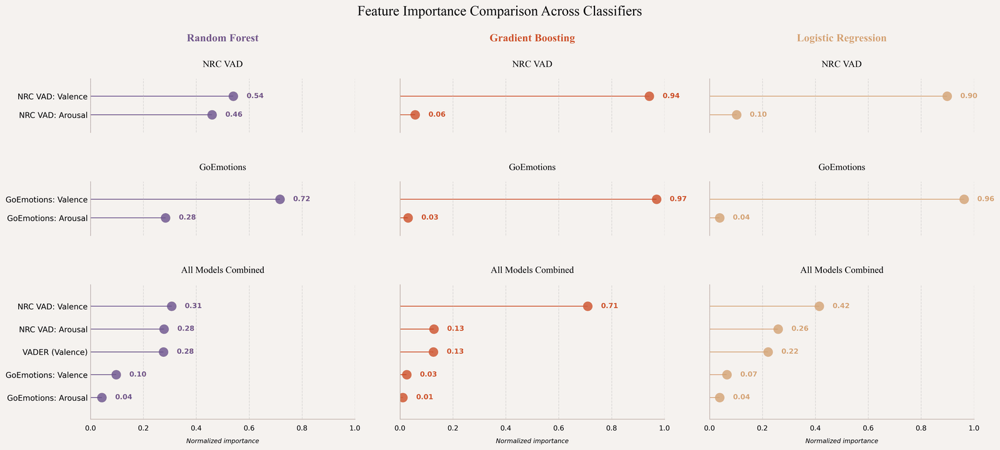

In [14]:
# ══════════════════════════════════════════════════════════════════════════════
# FEATURE IMPORTANCE COMPARISON (RF, GB, LR)
# ══════════════════════════════════════════════════════════════════════════════

# ── Colors ───────────────────────────────────────────────────────────────────

COLORS = {
    "Random Forest": "#6a518c",
    "Gradient Boosting": "#cd4f2a",
    "Logistic Regression": "#d4a373",
}

importance_sets = {
    "Random Forest": rf_importances,
    "Gradient Boosting": gb_importances,
    "Logistic Regression": lr_coefs,
}

feature_sets = [fs for fs in FEATURE_SETS.keys() if fs != "VADER"]
classifier_names = list(importance_sets.keys())

# ── Settings ───────────────────────────────────────────────────────────────────

FEATURE_SET = {
    "VADER":                 ["vader_score"],
    "NRC VAD":               ["nrc_valence", "nrc_arousal"],
    "GoEmotions":            ["emotion_valence", "emotion_arousal"],
    "All Models Combined":   ["vader_score", "nrc_valence", "nrc_arousal",
                              "emotion_valence", "emotion_arousal"],
}

FEATURE_LABELS = {
    "nrc_valence":     "NRC VAD: Valence", 
    "nrc_arousal":     "NRC VAD: Arousal",
    "emotion_valence": "GoEmotions: Valence", 
    "emotion_arousal": "GoEmotions: Arousal",
    "vader_score":     "VADER (Valence)"       
}

FIGURE_DPI=300

# ── Dynamic heights ────────────────────────────────────────────────────────────

height_ratios = [
    len(importance_sets["Random Forest"][fs]["features"])
    for fs in feature_sets
]
fig_height = max(sum(height_ratios) * 1.2, 7)*0.7
n_rows     = len(feature_sets)
n_cols     = len(classifier_names)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, fig_height),
    dpi=FIGURE_DPI,
    gridspec_kw={"height_ratios": height_ratios}
)
fig.patch.set_facecolor("#f5f2ef")

if n_rows == 1:
    axes = np.array([axes])
if n_cols == 1:
    axes = axes.reshape(-1, 1)

# ── Classifier names — colored, top of figure, manual positioning ──────────────

n_cols = len(classifier_names)

for col_idx, classifier_name in enumerate(classifier_names):
    color = COLORS[classifier_name]

# ── Plot ───────────────────────────────────────────────────────────────────────

for row_idx, feature_set_name in enumerate(feature_sets):
    for col_idx, classifier_name in enumerate(classifier_names):

        ax    = axes[row_idx, col_idx]
        data  = importance_sets[classifier_name][feature_set_name]
        color = COLORS[classifier_name]

        feat_cols   = data["features"]
        feat_labels = [FEATURE_LABELS.get(f, f) for f in feat_cols]

        # ── Importance extraction ──────────────────────────────────────────────

        if classifier_name in ["Random Forest", "Gradient Boosting"]:
            importance = np.array(data["importances"])
        else:
            coef       = np.array(data["coef"])
            importance = np.mean(np.abs(coef), axis=0)

        # ── Normalized (sum = 1.0) ─────────────────────────────────────────────

        importance = importance / importance.sum()

        order         = np.argsort(importance)
        sorted_vals   = importance[order]
        sorted_labels = [feat_labels[i] for i in order]
        y_pos         = np.arange(len(sorted_labels))

        ax.set_ylim(-0.95, len(sorted_labels) - 0.05)

        # ── Lollipop ──────────────────────────────────────────────────────────

        ax.hlines(
            y=y_pos, xmin=0, xmax=sorted_vals,
            color=color, linewidth=1, zorder=1
        )
        ax.scatter(
            sorted_vals, y_pos,
            color=color, s=150, linewidths=0, zorder=2, alpha=0.8
        )

        # Value labels — in dot color ───────────────────────────────────────────

        for val, y in zip(sorted_vals, y_pos):
            ax.text(
                val + 0.05, y,
                f"{val:.2f}",
                fontsize=9, va="center",
                color=color, fontweight="bold"            
            )

        # ── Y axis labels — leftmost only ─────────────────────────────────────

        ax.set_yticks(y_pos)
        if col_idx == 0:
            ax.set_yticklabels(sorted_labels, fontsize=10)
        else:
            ax.set_yticklabels([])

        # ── Feature set name ───────────────────────────────────────────────────

        ax.set_title(feature_set_name, 
                     fontsize=12, fontfamily="Times New Roman",
                     pad=15, color="000000", 
                    )

        # ── X axis — bottom row only ───────────────────────────────────────────

        if row_idx == n_rows - 1:
            ax.set_xlabel(
                "Normalized importance",
                fontsize=8, fontstyle="italic", labelpad=8
            )
            ax.tick_params(axis="x", length=0, labelsize=9, pad=8)
        else:
            ax.tick_params(axis="x", length=0, labelsize=9, labelbottom=False)

        ax.tick_params(axis="y", length=0, labelsize=10)

        # ── X axis scale ───────────────────────────────────────────────────────

        ax.set_xlim(0, 1.0)             
        ax.set_xticks(np.arange(0, 1.01, 0.2))

        # ── Styling ────────────────────────────────────────────────────────────

        ax.grid(axis="x", alpha=0.4, linestyle="--", zorder=0)
        ax.set_facecolor("#f5f2ef")

        # ── Spines ────────────────────────────────────────────────────────────────────

        for spine in ax.spines.values():
            spine.set_visible(False)
           
           # Y axis — always visible
            ax.spines["left"].set_visible(True)
            ax.spines["left"].set_color("#c0b0a8")

           # X axis — bottom row only
            if row_idx == n_rows - 1:
                ax.spines["bottom"].set_visible(True)
                ax.spines["bottom"].set_color("#c0b0a8")
                ax.axvline(0, color="#c0b0a8", linewidth=1)
# ── Suptitle ───────────────────────────────────────────────────────────────────

plt.suptitle(
    "Feature Importance Comparison Across Classifiers",
    fontsize=18, fontfamily="Times New Roman", y=1.06
)

plt.tight_layout(w_pad=3.0, h_pad=4.0)

for col_idx, classifier_name in enumerate(classifier_names):
    color = COLORS[classifier_name]
    ax    = axes[0, col_idx]   # top row ax for this column

    # Get center x of this axes in figure coordinates
    bbox  = ax.get_position()
    x_pos = (bbox.x0 + bbox.x1) / 2

    fig.text(
        x_pos, 0.97,
        classifier_name,
        ha="center", va="bottom",
        fontsize=14, fontfamily="Times New Roman",
        color=color, fontweight="bold",
        transform=fig.transFigure
    )
    
plt.savefig(
    "feature_importance_comparison.png",
    dpi=FIGURE_DPI, bbox_inches="tight",
    pad_inches=0.5, facecolor="#f5f2ef", transparent=False
)
display(fig)
plt.close()

#### 10.2.4. Baseline Classifiers

To contextualise model performance, **two naive baseline classifiers were evaluated on the same train-test split**: 

- **Majority Class Baseline**: always predicts the most frequent rating (5★). It achieves an accuracy equal to the proportion of 5★ reviews in the test set — approximately 0.534 — with an F1 macro near zero, as it assigns all predictions to a single class.

- **Stratified Random Baseline**: samples predictions proportionally to the class distribution in the training set. It produces similarly low F1 macro scores, reflecting the difficulty of the task under class imbalance.

Comparing trained models against these baselines reveals that **the accuracy gains achieved by Logistic Regression, Random Forest, and Gradient Boosting are modest in absolute terms**, and in the case of Gradient Boosting, largely attributable to the same majority-class dominance that inflates the baseline. 

The most meaningful improvement over baseline is observed in **F1 macro for Logistic Regression with all models combined** (0.384 vs ~0.05 for baselines), confirming that this configuration provides genuine discriminative value beyond chance — particularly for minority rating classes.

BASELINE CLASSIFIERS

Majority Class
------------------------------------------------------------
  Accuracy:    0.534
  F1 Macro:    0.139
  F1 Weighted: 0.371
              precision    recall  f1-score   support

          1★       0.00      0.00      0.00      1606
          2★       0.00      0.00      0.00       407
          3★       0.00      0.00      0.00       383
          4★       0.00      0.00      0.00       656
          5★       0.53      1.00      0.70      3492

    accuracy                           0.53      6544
   macro avg       0.11      0.20      0.14      6544
weighted avg       0.28      0.53      0.37      6544


Stratified Random
------------------------------------------------------------
  Accuracy:    0.365
  F1 Macro:    0.203
  F1 Weighted: 0.366
              precision    recall  f1-score   support

          1★       0.26      0.25      0.25      1606
          2★       0.05      0.05      0.05       407
          3★       0.08      0.08      0.08 

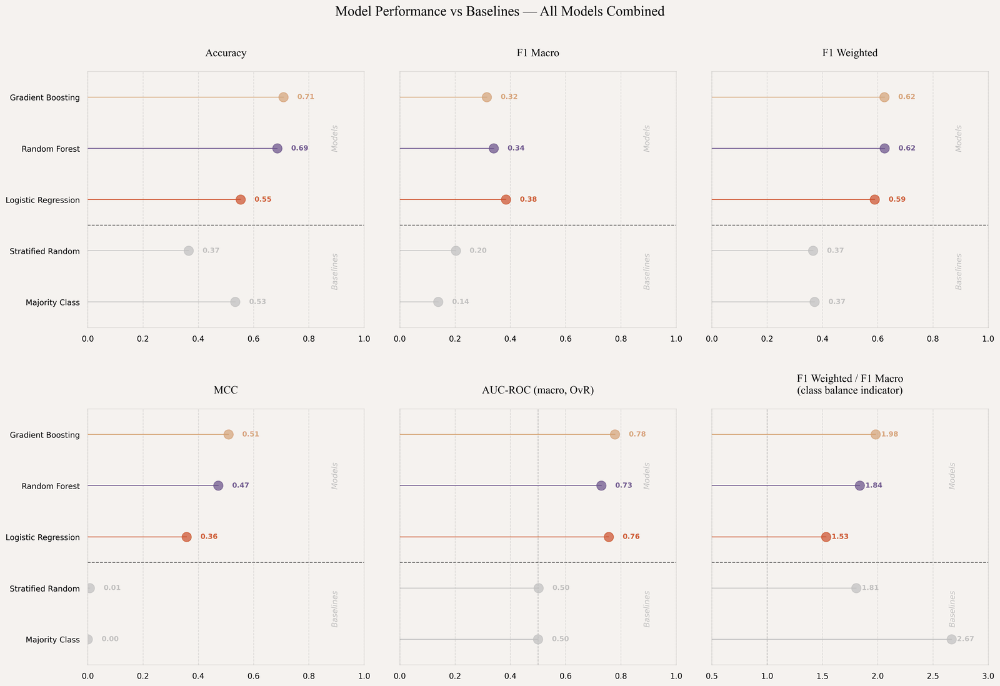

In [15]:
# ── Baseline classifiers ───────────────────────────────────────────────────────

BASELINES = {
    "Majority Class":     DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Stratified Random":  DummyClassifier(strategy="stratified",    random_state=RANDOM_STATE),
}

# Best models from earlier results
BEST_MODELS = {
    "LR — All Combined":  (0.553, 0.384, 0.589),
    "RF — All Combined":  (0.686, 0.340, 0.625),
    "GB — All Combined":  (0.708, 0.315, 0.624),
}

FIGURE_DPI=300

print("BASELINE CLASSIFIERS")
print("=" * 60)

baseline_results = {}

for clf_name, clf in BASELINES.items():
    clf.fit(X_train, y_train)
    y_pred    = clf.predict(X_test)
    accuracy  = accuracy_score(y_test, y_pred)
    f1_macro  = f1_score(y_test, y_pred, average="macro")
    f1_weight = f1_score(y_test, y_pred, average="weighted")
    mcc       = matthews_corrcoef(y_test, y_pred)
    f1w_f1m   = f1_weight / f1_macro if f1_macro > 0 else np.nan

    # AUC-ROC
    y_bin = label_binarize(y_test, classes=RATING_LABELS)
    try:
        if hasattr(clf, "predict_proba"):
            y_prob = clf.predict_proba(X_test)
        else:
            y_prob = clf.decision_function(X_test)
        auc = roc_auc_score(y_bin, y_prob, multi_class="ovr", average="macro")
    except Exception:
        auc = np.nan

    baseline_results[clf_name] = {
        "accuracy": accuracy, "f1_macro": f1_macro, "f1_weight": f1_weight,
        "mcc": mcc, "auc": auc, "ratio": f1w_f1m,
    }

    print(f"\n{clf_name}")
    print("-" * 60)
    print(f"  Accuracy:    {accuracy:.3f}")
    print(f"  F1 Macro:    {f1_macro:.3f}")
    print(f"  F1 Weighted: {f1_weight:.3f}")
    print(classification_report(
        y_test, y_pred,
        target_names=["1★", "2★", "3★", "4★", "5★"]
    ))

# ── Comparison table ───────────────────────────────────────────────────────────

print("\nCOMPARISON: BASELINES vs BEST MODELS")
print("=" * 80)
print(f"{'Model':<40} {'Accuracy':>10} {'F1 Macro':>10} {'F1 Weighted':>12}")
print("-" * 80)

for clf_name, res in baseline_results.items():
    print(f"{clf_name:<40} {res['accuracy']:>10.3f} "
          f"{res['f1_macro']:>10.3f} {res['f1_weight']:>12.3f}")

print("-" * 80)

for clf_name, (acc, f1m, f1w) in BEST_MODELS.items():
    print(f"{clf_name:<40} {acc:>10.3f} {f1m:>10.3f} {f1w:>12.3f}")

# ── Visualization ──────────────────────────────────────────────────────────────

all_models = {
    **{k: v for k, v in baseline_results.items()},
    "Logistic Regression": {
        "accuracy": 0.553, "f1_macro": 0.384, "f1_weight": 0.589,
        "mcc": 0.358, "auc": 0.756, "ratio": 0.589 / 0.384,  # ≈ 1.534
    },
    "Random Forest": {
        "accuracy": 0.686, "f1_macro": 0.340, "f1_weight": 0.625,
        "mcc": 0.472, "auc": 0.729, "ratio": 0.625 / 0.340,  # ≈ 1.838
    },
    "Gradient Boosting": {
        "accuracy": 0.708, "f1_macro": 0.315, "f1_weight": 0.624,
        "mcc": 0.509, "auc": 0.778, "ratio": 0.624 / 0.315,  # ≈ 1.981
    },
}

model_names = list(all_models.keys())
accuracies  = [v["accuracy"]  for v in all_models.values()]
f1_macros   = [v["f1_macro"]  for v in all_models.values()]
f1_weights  = [v["f1_weight"] for v in all_models.values()]
mccs        = [v["mcc"]       for v in all_models.values()]
aucs        = [v["auc"]       for v in all_models.values()]
ratios      = [v["ratio"]     for v in all_models.values()]

bar_colors = [
    "#C0C0C0" if "Majority" in n or "Stratified" in n
    else "#cd4f2a" if n == "Logistic Regression"
    else "#6a518c" if n == "Random Forest"
    else "#d4a373"
    for n in model_names
]

METRICS_CONFIG = {
    "accuracy":  {"key": "accuracy",  "ylim": (0.0, 1.0), "ref": None, "label": "Accuracy"},
    "f1_macro":  {"key": "f1_macro",  "ylim": (0.0, 1.0), "ref": None, "label": "F1 Macro"},
    "f1_weight": {"key": "f1_weight", "ylim": (0.0, 1.0), "ref": None, "label": "F1 Weighted"},
    "mcc":       {"key": "mcc",       "ylim": (0.0, 1.0), "ref": None, "label": "MCC"},
    "auc":       {"key": "auc",       "ylim": (0.0, 1.0), "ref": 0.5,  "label": "AUC-ROC (macro, OvR)"},
    "ratio":     {"key": "ratio",     "ylim": (0.5, 3.0), "ref": 1.0,  "label": "F1 Weighted / F1 Macro\n(class balance indicator)"},
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12), dpi=FIGURE_DPI)
fig.patch.set_facecolor("#f5f2ef")
fig.suptitle(
    "Model Performance vs Baselines — All Models Combined",
    fontsize=18, fontfamily="Times New Roman", y=1.02
)

for ax, (metric_id, cfg) in zip(axes.ravel(), METRICS_CONFIG.items()):
    y_positions = range(len(model_names))
    values = [all_models[n][cfg["key"]] for n in model_names]

    for i, (name, val, color) in enumerate(zip(model_names, values, bar_colors)):
        ax.plot([0, val], [i, i], color=color, linewidth=1, zorder=2)
        ax.plot(val, i, "o", color=color, markersize=12, alpha=0.7, zorder=3)
        ax.text(val + 0.05, i, f"{val:.2f}",
                ha="left", va="center", fontsize=9, color=color, fontweight="bold")

    ax.axhline(1.5, color="#000000", linewidth=1, linestyle="--", alpha=0.6, zorder=1)
    ax.text(cfg["ylim"][1] * 0.88, 0.6, "Baselines",
            va="center", fontsize=10, rotation=90, color="#C0C0C0", fontstyle="italic")
    ax.text(cfg["ylim"][1] * 0.88, 3.2, "Models",
            va="center", fontsize=10, rotation=90, color="#C0C0C0", fontstyle="italic")

    # Linia referencyjna (dla AUC i ratio)
    if cfg["ref"] is not None:
        ax.axvline(cfg["ref"], color="#999999", linewidth=0.8,
                   linestyle="--", zorder=0, alpha=0.7)

    ax.set_yticks(y_positions)
    if ax == axes.ravel()[0] or ax == axes.ravel()[3]:  # lewa kolumna
        ax.set_yticklabels(model_names, fontsize=10)
    else:
        ax.set_yticklabels([])

    ax.set_xlim(cfg["ylim"])
    ax.set_ylim(-0.5, len(model_names) - 0.5)
    ax.set_title(cfg["label"], fontsize=14, fontfamily="Times New Roman", pad=20)
    ax.grid(axis="x", alpha=0.4, linestyle="--")
    ax.tick_params(length=0, labelsize=10, pad=10)
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")

plt.tight_layout(w_pad=3.0, h_pad=4.0)
plt.savefig("rating_baseline_comparison.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

### 10.3. Prediction Bias Analysis

Bias analysis reveals **consistent directional patterns across all three classifiers**, with important differences in magnitude and correction behaviour.

All three models systematically **overestimate 1★ reviews** — predicting higher ratings than users actually assigned — with mean errors ranging from +0.568 (Gradient Boosting) to +0.729 (Logistic Regression). This suggests that the **emotional language of the most negative reviews is not sufficiently extreme** to be recognised as such by sentiment features alone, consistent with the earlier finding that dissatisfied users often write in a measured, factual tone rather than an emotionally intense one.

**5-star reviews are systematically underestimated across all classifiers**, with mean errors of −0.551 (Logistic Regression), −0.287 (Random Forest), and −0.268 (Gradient Boosting). This reflects the ceiling effect in user reviewing behaviour noted earlier: **users frequently award the highest rating as a default expression of satisfaction**, without producing text that registers as strongly positive across all three sentiment models.

**Logistic Regression shows the strongest overall bias toward underprediction** (25.6% underpredicted vs 19.1% overpredicted, overall mean error = −0.100), while **Random Forest and Gradient Boosting lean slightly toward overprediction** (overall mean errors of +0.055 and +0.034 respectively). Despite these directional differences, all three models share a median error of zero, confirming that correct prediction remains the single most common outcome — achieved by 55.3%, 68.6%, and 70.8% of cases respectively.

**The 3★ class is the most neutrally predicted across all models**, with mean errors close to zero, reinforcing the interpretation that neutral emotional tone maps most reliably onto mid-scale ratings. Intermediate classes 2★ and 4★ show moderate positive bias, suggesting that **the models tend to pull predictions toward the extremes rather than the middle of the scale** — a pattern consistent with the binary structure of the training signal dominated by 1★ and 5★ examples.

#### 10.3.1. Text Reports

In [16]:
# ── Predicted vs true rating — bias analysis ───────────────────────────────────

feat_cols = ["vader_score", "nrc_valence", "nrc_arousal",
             "emotion_valence", "emotion_arousal"]

subset  = df_rated[feat_cols + ["rating"]].dropna()
X       = subset[feat_cols].values
y       = subset["rating"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# ── Classifiers to evaluate ────────────────────────────────────────────────────

BIAS_CLASSIFIERS = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    ),
}

bias_results = {}

for clf_name, clf in BIAS_CLASSIFIERS.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    bias_df = pd.DataFrame({"true": y_test, "predicted": y_pred})
    bias_df["error"] = bias_df["predicted"] - bias_df["true"]

    bias_summary = (
        bias_df.groupby("true")["error"]
        .agg(["mean", "median", "std", "count"])
        .rename(columns={"mean": "Mean error", "median": "Median error",
                         "std": "Std", "count": "N"})
    )

    bias_results[clf_name] = {
        "bias_df":      bias_df,
        "bias_summary": bias_summary,
    }

    print(f"\nPREDICTION BIAS — {clf_name}")
    print("=" * 60)
    print("(positive = overpredicts, negative = underpredicts)\n")
    print(bias_summary.round(3))
    print(f"\nOverall mean error:   {bias_df['error'].mean():+.3f}")
    print(f"Overall median error: {bias_df['error'].median():+.3f}")
    print(f"Overpredicted:  {(bias_df['error'] > 0).sum():,} "
          f"({(bias_df['error'] > 0).mean():.1%})")
    print(f"Underpredicted: {(bias_df['error'] < 0).sum():,} "
          f"({(bias_df['error'] < 0).mean():.1%})")
    print(f"Correct:        {(bias_df['error'] == 0).sum():,} "
          f"({(bias_df['error'] == 0).mean():.1%})")


PREDICTION BIAS — Logistic Regression
(positive = overpredicts, negative = underpredicts)

      Mean error  Median error    Std     N
true                                       
1          0.729           0.0  1.104  1606
2          0.290           0.0  1.344   407
3         -0.076           0.0  1.537   383
4          0.018           0.0  1.209   656
5         -0.551           0.0  0.943  3492

Overall mean error:   -0.100
Overall median error: +0.000
Overpredicted:  1,252 (19.1%)
Underpredicted: 1,675 (25.6%)
Correct:        3,617 (55.3%)

PREDICTION BIAS — Random Forest
(positive = overpredicts, negative = underpredicts)

      Mean error  Median error    Std     N
true                                       
1          0.685           0.0  1.453  1606
2          0.140          -1.0  1.713   407
3          0.008           0.0  1.933   383
4          0.305           1.0  1.445   656
5         -0.287           0.0  0.972  3492

Overall mean error:   +0.055
Overall median error: +0.00

#### 10.3.2. Visualised Bias

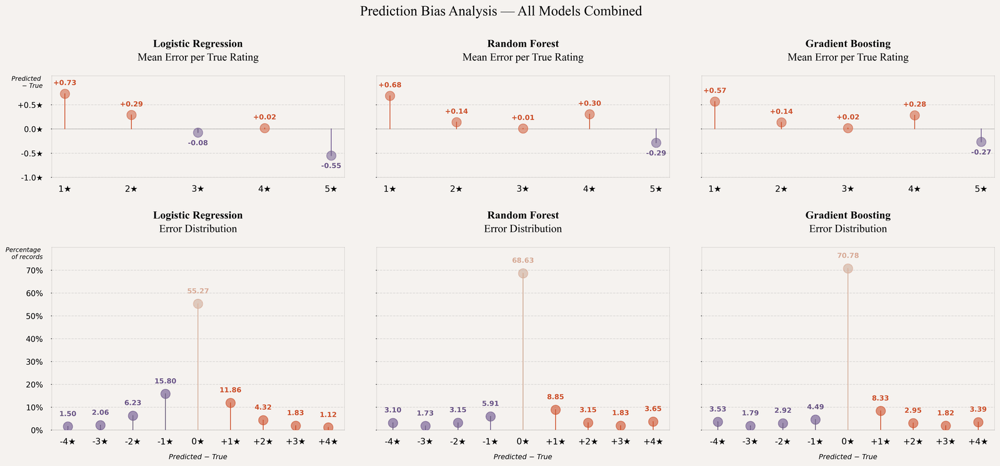

In [17]:
# Settings

RATING_LABELS = [1, 2, 3, 4, 5]
FIGURE_DPI    = 300
CLF_COLORS = ["#cd4f2a", "#6a518c", "#d4a373"]

# ── Bias visualization ─────────────────────────────────────────────────────────

total_records = sum(len(d["bias_df"]) for d in bias_results.values()) // len(bias_results)

all_errors = pd.concat([d["bias_df"]["error"] for d in bias_results.values()])
x_min = all_errors.min() - 0.5
x_max = all_errors.max() + 0.5

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 8),
    dpi=FIGURE_DPI,
    sharey="row",
    gridspec_kw={"height_ratios": [1, 1.8]}
)
fig.patch.set_facecolor("#f5f2ef")
fig.suptitle(
    "Prediction Bias Analysis — All Models Combined",
    fontsize=18, fontfamily="Times New Roman", y=1.04
)

for col_idx, (clf_name, data) in enumerate(bias_results.items()):
    bias_df      = data["bias_df"]
    bias_summary = data["bias_summary"]
    total        = len(bias_df)

    # ── Row 0: Mean error per true rating — lollipop ──────────────────────────

    ax = axes[0, col_idx]

    for x_val, y_val in zip(bias_summary.index, bias_summary["Mean error"]):
        dot_color = "#6a518c" if y_val < 0 else "#cd4f2a"
        ax.plot([x_val, x_val], [0, y_val], 
                color=dot_color, linewidth=1, alpha=1, zorder=2)
        ax.plot(x_val, y_val, 
                "o", color=dot_color, markersize=12, linewidth=0, alpha=0.5, zorder=3)
        offset = -0.15 if y_val < 0 else 0.15
        va     = "top"    if y_val < 0 else "bottom"
        ax.text(
            x_val, y_val + offset, f"{y_val:+.2f}",
            ha="center", va=va,
            fontsize=9, color=dot_color, fontweight="bold"
        )

    ax.axhline(0, color="#000000", linewidth=0.6, alpha=0.3, zorder=1)
    ax.set_title("Mean Error per True Rating",
                 fontsize=14, fontfamily="Times New Roman", pad=20)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xticklabels([f"{i}★" for i in range(1, 6)], fontsize=11)

    y_min = int(np.floor(bias_summary["Mean error"].min()))
    ax.set_ylim(y_min, 1.1)
    y_ticks = np.arange(y_min, 1.1, 0.5)
    y_ticks_shown = y_ticks[:-1]
    ax.set_yticks(y_ticks_shown)
    ax.set_yticklabels(
        [f"{y:.1f}★" if y == 0 else f"{y:+.1f}★" for y in y_ticks_shown],
        fontsize=11
    )

    ax.tick_params(axis="y", length=1, labelsize=10, pad=10)
    ax.tick_params(axis="x", length=0, labelsize=11, pad=10)

    if col_idx == 0:
        ax.text(
            -0.03, 0.87, "Predicted \n− True",
            fontsize=8, fontstyle="italic",
            transform=ax.transAxes, ha="right", va="bottom"
        )

    ax.grid(axis="y", alpha=0.4, linestyle="--")
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")

    # ── Row 1: Error distribution — lollipop, % of total ──────────────────────

    ax = axes[1, col_idx]

    error_counts = bias_df["error"].value_counts().sort_index()
    error_pct    = error_counts / total * 100

    ax.axhline(0, color="#000000", linewidth=0.6, alpha=0.3, zorder=1)

    for x_val, y_val in zip(error_pct.index, error_pct.values):
        dot_color = "#6a518c" if x_val < 0 else "#cfad96" if x_val == 0 else "#cd4f2a"
        ax.plot([x_val, x_val], [0, y_val], 
                color=dot_color, linewidth=1, alpha=1, zorder=2)
        ax.plot(x_val, y_val, 
                "o", color=dot_color, markersize=12, linewidth=0, alpha=0.6, zorder=3)
        ax.text(
            x_val, y_val + 4, f"{y_val:.2f}",
            ha="center", va="bottom",
            fontsize=9, color=dot_color, fontweight="bold"
        )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, 80)
    yticks = [0, 10, 20, 30, 40, 50, 60, 70]
    ax.set_yticks(yticks)
    ax.set_xlabel("Predicted − True", fontsize=9,
                  fontstyle="italic", labelpad=10)
    ax.set_title("Error Distribution",
                 fontsize=14, fontfamily="Times New Roman", pad=20)

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y:.0f}%")
    )

    x_ticks = sorted(error_pct.index.astype(int))
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(
        [f"{x:d}★" if x == 0 else f"{x:+d}★" for x in x_ticks],
        fontsize=11
    )

    ax.tick_params(axis="y", length=1, labelsize=10, pad=10)
    ax.tick_params(axis="x", length=0, labelsize=11, pad=10)
    
    
    if col_idx == 0:
        ax.text(
            -0.03, 0.93, "Percentage \nof records",
            fontsize=8, fontstyle="italic",
            transform=ax.transAxes, ha="right", va="bottom"
        )

    ax.grid(axis="y", alpha=0.4, linestyle="--")
    for spine in ax.spines.values():
        spine.set_alpha(0.1)
    ax.set_facecolor("#f5f2ef")

# ── Classifiers headlines ────────────────────────────────────────────────────

plt.tight_layout(w_pad=4.0, h_pad=4.0)
fig.canvas.draw()

for col_idx, clf_name in enumerate(bias_results.keys()):
    for row_idx in [0, 1]:
        ax   = axes[row_idx, col_idx]
        bbox = ax.get_position()
        x_pos = (bbox.x0 + bbox.x1) / 2
        y_pos = bbox.y1 + 0.06  

        fig.text(
            x_pos, y_pos, clf_name,
            ha="center", va="bottom",
            fontsize=14, fontfamily="Times New Roman",
            fontweight="bold", transform=fig.transFigure
        )
        
plt.savefig("rating_bias_all_classifiers.png", bbox_inches="tight",
            pad_inches=0.5, transparent=False)
display(fig)
plt.close()

### 10.4. Prediction Value Assessment

The results of this chapter suggest that **sentiment-derived features carry meaningful but limited predictive signal for star rating classification**.

**The best-performing configuration — Logistic Regression on all models combined** (F1 macro = 0.384, AUC-ROC = 0.756) — demonstrates that sentiment scores from complementary models provide more discriminative information than any single model alone, yet fall short of reliable five-class prediction.

This finding has two implications:

- **Star ratings are a noisy proxy for user sentiment**: users frequently assign extreme ratings (1★ or 5★) regardless of the emotional content of their review text, which creates an irreducible ceiling on text-based prediction.
  
- The strong performance on 1★ recall (GoEmotions Random Forest: 0.860) suggests that **sentiment features are more useful for negative review detection** than for full rating reconstruction — a practically relevant distinction for product monitoring applications.

Future work could explore the addition of non-sentiment features (review length, platform, app category, time since release) or fine-tuned transformer models to assess whether the ceiling is a property of the feature set or of the task itself.

### 10.5. Cross-Validation and a Text-Based Baseline

Section 10.1 uses a single train/test split, default hyperparameters and only the five sentiment and arousal scores as features. To check how much these choices matter, the models are re-evaluated with 5-fold stratified cross-validation (mean ± standard deviation across folds), and a plain TF-IDF (1–2-grams) + logistic regression model on the review text is added as a baseline. The cell takes about three minutes to run; the results below were produced with scikit-learn 1.9.1.

In [ ]:
# Cross-validation and a text-based baseline for star-rating prediction.
# Same 32,720 rated reviews and default settings as Section 10.1; the TF-IDF vectoriser
# is fitted inside each training fold, so no information leaks from the test fold.

import warnings
import scipy.sparse as sps
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support
warnings.filterwarnings("ignore")

RS     = 60                                   # same random state as above
SCORES = ["vader_score", "nrc_valence", "nrc_arousal", "emotion_valence", "emotion_arousal"]

rated = df_emotion[df_emotion["source"].isin(["google_play", "app_store"]) & df_emotion["rating"].notna()]
rated = rated.dropna(subset=SCORES).reset_index(drop=True)
y     = rated["rating"].astype(int).values
S     = rated[SCORES].values
T     = rated["text_sentiment"].fillna("").astype(str).values
print(f"{len(rated):,} rated reviews, 5-fold stratified cross-validation (random_state={RS})\n")

def fit_predict(name, train, test):
    """Fit one model on the training fold and return metrics on the test fold."""
    if name in ("Majority class", "Stratified random"):
        strategy = "most_frequent" if name == "Majority class" else "stratified"
        clf = DummyClassifier(strategy=strategy, random_state=RS).fit(S[train], y[train])
        X_test = S[test]
    elif name.endswith("(sentiment scores)"):
        scaler = StandardScaler().fit(S[train])
        X_train, X_test = scaler.transform(S[train]), scaler.transform(S[test])
        clf = {"Logistic Regression": LogisticRegression(max_iter=1000, random_state=RS, class_weight="balanced"),
               "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=RS, class_weight="balanced"),
               "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, random_state=RS),
              }[name.split(" (")[0]].fit(X_train, y[train])
    else:                                      # TF-IDF + Logistic Regression on the review text
        C = float(name.split("C=")[1].split(")")[0])
        vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True)
        X_train, X_test = vec.fit_transform(T[train]), vec.transform(T[test])
        if "+ scores" in name:
            scaler = StandardScaler().fit(S[train])
            X_train = sps.hstack([X_train, sps.csr_matrix(scaler.transform(S[train]))]).tocsr()
            X_test  = sps.hstack([X_test,  sps.csr_matrix(scaler.transform(S[test]))]).tocsr()
        clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=RS).fit(X_train, y[train])
    pred, proba = clf.predict(X_test), clf.predict_proba(X_test)
    prec, rec, _, _ = precision_recall_fscore_support(y[test], pred, labels=[1], zero_division=0)
    return {"Accuracy":  accuracy_score(y[test], pred),
            "F1 macro":  f1_score(y[test], pred, average="macro"),
            "AUC-ROC":   roc_auc_score(y[test], proba, multi_class="ovr", average="macro", labels=clf.classes_),
            "1star recall": rec[0], "1star precision": prec[0]}

MODELS = ["Majority class", "Stratified random",
          "Logistic Regression (sentiment scores)", "Random Forest (sentiment scores)",
          "Gradient Boosting (sentiment scores)",
          "TF-IDF + LR (C=0.3)", "TF-IDF + LR (C=1)", "TF-IDF + LR (C=0.3) + scores"]

folds   = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RS).split(S, y))
results = []
for name in MODELS:
    per_fold = pd.DataFrame([fit_predict(name, tr, te) for tr, te in folds])
    results.append({"Model": name, **{m: f"{per_fold[m].mean():.3f} ± {per_fold[m].std():.3f}" for m in per_fold}})
print(pd.DataFrame(results).to_string(index=False))

32,720 rated reviews, 5-fold stratified cross-validation (random_state=60)

                                 Model      Accuracy      F1 macro       AUC-ROC  1star recall 1star precision
                        Majority class 0.534 ± 0.000 0.139 ± 0.000 0.500 ± 0.000 0.000 ± 0.000   0.000 ± 0.000
                     Stratified random 0.357 ± 0.002 0.195 ± 0.003 0.497 ± 0.002 0.235 ± 0.004   0.239 ± 0.004
Logistic Regression (sentiment scores) 0.547 ± 0.007 0.379 ± 0.003 0.756 ± 0.003 0.592 ± 0.017   0.701 ± 0.011
      Random Forest (sentiment scores) 0.604 ± 0.009 0.360 ± 0.004 0.730 ± 0.003 0.714 ± 0.008   0.621 ± 0.006
  Gradient Boosting (sentiment scores) 0.709 ± 0.004 0.314 ± 0.003 0.780 ± 0.002 0.853 ± 0.006   0.623 ± 0.007
                   TF-IDF + LR (C=0.3) 0.660 ± 0.008 0.466 ± 0.010 0.822 ± 0.003 0.702 ± 0.013   0.742 ± 0.009
                     TF-IDF + LR (C=1) 0.669 ± 0.007 0.464 ± 0.007 0.821 ± 0.004 0.730 ± 0.008   0.738 ± 0.007
          TF-IDF + LR (C=0.3) + scor

**Result.** Cross-validated scores match the single split closely (e.g. Logistic Regression: macro-F1 .379 vs. .384), so the earlier results are not an artefact of one split. A text-based baseline is clearly better than every sentiment-score model: TF-IDF + logistic regression reaches macro-F1 ≈ .47 (vs. .38 for the best score-based model) and AUC-ROC ≈ .82 (vs. .78), with 1★ recall of .70–.73 at a precision of about .74. Sentiment scores therefore carry only part of the rating-relevant information in the text, and the modest F1 values in Section 10.2 reflect the limited feature set as well as noise in star ratings. Adding the sentiment scores to the TF-IDF features does not improve macro-F1 (.46) and raises AUC-ROC only slightly (.83).

The Random Forest row differs from Section 10.1 (accuracy .60 vs. .69, macro-F1 .36 vs. .34; AUC-ROC is the same), whereas Logistic Regression and Gradient Boosting reproduce exactly. The cause was not investigated.